# SE match estimation: uniform prior

In [ ]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
import WERM.model as model
import WERM.general_fixed_point_eqns as fp
import WERM.M_est_fixed_point_eqns as M_est
import WERM.gof
import WERM.performance_measures
import WERM.marginals
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm.auto import tqdm
import time
from joblib import Parallel, delayed
import logging
from datetime import datetime, timedelta
import sys
import pickle
import os

# Set a random seed for reproducibility
random_seed = 42
nprandom.seed(random_seed)
jax.random.PRNGKey(random_seed) # Set JAX random seed as well

# --- Logging Setup ---
def setup_logging():
    """Setup comprehensive logging for the simulation"""
    detailed_formatter = logging.Formatter(
        '%(asctime)s - %(name)s - %(levelname)s - %(message)s',
        datefmt='%Y-%m-%d %H:%M:%S'
    )
    simple_formatter = logging.Formatter(
        '%(asctime)s - %(message)s',
        datefmt='%H:%M:%S'
    )

    # Create logs directory if it doesn't exist
    import os
    log_dir = 'logs'
    if not os.path.exists(log_dir):
        os.makedirs(log_dir)

    main_logger = logging.getLogger('simulation')
    main_logger.setLevel(logging.INFO)
    main_logger.handlers = [] # Clear existing handlers

    console_handler = logging.StreamHandler(sys.stdout)
    console_handler.setLevel(logging.INFO)
    console_handler.setFormatter(simple_formatter)
    main_logger.addHandler(console_handler)

    file_handler = logging.FileHandler('logs/WERM_simulation_detailed.log', mode='w')
    file_handler.setLevel(logging.DEBUG)
    file_handler.setFormatter(detailed_formatter)
    main_logger.addHandler(file_handler)

    progress_logger = logging.getLogger('progress')
    progress_logger.setLevel(logging.INFO)
    progress_logger.handlers = [] # Clear existing handlers

    progress_handler = logging.FileHandler('logs/WERM_simulation_progress.log', mode='w')
    progress_handler.setLevel(logging.INFO)
    progress_handler.setFormatter(detailed_formatter)
    progress_logger.addHandler(progress_handler)

    return main_logger, progress_logger

# Initialize loggers
main_logger, progress_logger = setup_logging()

class ProgressTracker:
    """Class to track and log simulation progress"""
    def __init__(self, total_tasks, delta_list, num_trials, logger):
        self.total_tasks = total_tasks
        self.delta_list = delta_list
        self.num_trials = num_trials
        self.logger = logger
        self.start_time = time.time()
        self.completed_tasks = 0
        self.delta_progress = {i: 0 for i in range(len(delta_list))}

    def update(self, delta_idx):
        """Update progress for a completed task"""
        self.completed_tasks += 1
        percent_complete = (self.completed_tasks / self.total_tasks) * 100
        elapsed_time = time.time() - self.start_time

        if self.completed_tasks > 0:
            avg_time_per_task = elapsed_time / self.completed_tasks
            remaining_tasks = self.total_tasks - self.completed_tasks
            estimated_remaining_time = remaining_tasks * avg_time_per_task
            estimated_completion = datetime.now() + timedelta(seconds=estimated_remaining_time)

            self.logger.info(
                f"Progress: {self.completed_tasks}/{self.total_tasks} ({percent_complete:.1f}%) | "
                f"Elapsed: {elapsed_time:.1f}s | "
                f"Est. remaining: {estimated_remaining_time:.1f}s | "
                f"Est. completion: {estimated_completion.strftime('%H:%M:%S')}"
            )

        self.delta_progress[delta_idx] += 1
        # Log delta-specific progress less frequently to avoid excessive logging
        if self.completed_tasks % max(1, self.total_tasks // 10) == 0 or self.completed_tasks == 1 or self.completed_tasks == self.total_tasks:
            delta_status = []
            for i, delta in enumerate(self.delta_list):
                progress = self.delta_progress[i]
                delta_status.append(f"δ={delta:.1f}: {progress}/{self.num_trials}")
            self.logger.info("Delta progress: " + " | ".join(delta_status))

# Global progress tracker (initialized later)
progress_tracker = None

# --- Helper Function for a Single Parallel Job ---
def run_single_trial(params, p, L, noise_std, fractional_chgpt_locations, M, method_configs, B̃):
    """
    Executes a single simulation trial for a given delta, running multiple methods.
    This function is designed to be called in parallel by joblib.
    """
    global progress_tracker
    i, δ, j = params # i: delta_list index, δ: current delta value, j: trial number
    trial_start_time = time.time()

    progress_logger.info(f"Starting trial {j+1}/{num_trials} for δ={δ:.1f} (delta_idx={i})")

    # --- Setup based on delta ---
    n = int(δ * p)
    if fractional_chgpt_locations.size != 0:
        true_chgpt_locations = lambda n_len: (n_len * fractional_chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
    else:
        true_chgpt_locations = lambda n_len: np.array([])
        C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0.

    # --- Preliminaries (from original code) ---
    Δ = lambda n_len: int(n_len / 10)
    n_small = 50
    Delta_n_small = int(Δ(n) * n_small/n)
    p_l = None
    Lmin = L
    Lmax = L
    pi = WERM.config.extrapolated_marginals(Lmin, Lmax, Delta_n_small, n_small = n_small, n_large = n, p_l = p_l, verbose = False)
    π= pi
    π = π / np.sum(π, axis=1, keepdims=True) # Lxn matrix

    # pi_i_l = lambda L,l , i: scipy.special.comb(L-1, l-1, exact=False) * (i/n)**(l-1) * (1 - i/n)**(L-l)
    # pi = np.zeros((L, n))
    # for l__ in range(L):
    #     for i__ in range(n):
    #         pi[l__, i__] = pi_i_l(L, l__ + 1, i__ + 1)
    # π = pi
    # π = π / np.sum(π, axis=1, keepdims=True) # Lxn matrix


    # --- Data Generation for this trial ---
    data_gen_start = time.time()
    X = nprandom.normal(0, np.sqrt(1/n), (n, p))
    X = X @ Sigma_chol.T
    # ε = nprandom.randn(n) * noise_std
    ε = np.random.standard_t(5, size=(n, )) * noise_std # For Huber loss, use t-distribution for noise. df > 2 has finite variance.
    B̃ = np.sqrt(δ) * B̃ # Scale B̃ by sqrt(delta) here since we vary delta, see the definition of B̃ outside of loop. 
    Θ = X @ B̃
    y_mapped_fn = jax.vmap(model.q_linear_model, in_axes=(0, 0, 0))
    y = y_mapped_fn(Θ, C_true, ε)
    data_gen_time = time.time() - data_gen_start

    trial_results = {}
    methods_status = {method_name: False for method_name in method_configs.keys()}

    # Compute fixed point solution once per delta for theoretical comparison
    ρ = (1/δ) * (1/p) * (B̃.T @ Sigma_chol @ Sigma_chol.T @ B̃)
    b, ν̃, κ̃ = fp.general_fp(M, ρ, δ, fractional_chgpt_locations, π, ε, n, model.q_linear_model)
    κ̃_sqrt = jnp.linalg.cholesky(κ̃ + 1e-12 * jnp.eye(L))
    print("-"*60)
    print("b, ν̃, κ̃ for δ=", δ, ":", b, ν̃, κ̃, ", trial : ", j+1)
    print("-"*60)

    # --- Run Estimators for all configured methods ---
    for method_name, method_func_info in method_configs.items():
        try:
            method_start = time.time()
            current_B̂ = np.zeros((p, L))
            Θ̂_theory = np.zeros((n, L))
            current_corr_list = []
            current_mse_list = []
            current_chgpt_loc = np.array([])

            if method_name == 'ERM-LS':
                for ℓ_ in range(L):
                    sample_weight = π[ℓ_, :] / np.sum(π[ℓ_, :])
                    empirical_risk = lambda β: jnp.multiply(M((X @ β).flatten(), y.flatten()), sample_weight).sum()
                    res = scipy.optimize.minimize(empirical_risk, 0.1*np.ones(p), jac=jax.grad(empirical_risk), method='L-BFGS-B')
                    β̂ = res.x
                    current_B̂[:, ℓ_] = β̂
                    current_corr_list.append(WERM.norm_sq_corr(β̂, B̃[:, ℓ_]))
                    current_mse_list.append(WERM.MSE(β̂.flatten(), B̃[:, ℓ_]))
                # Determine changepoints for ERM
                opt_chgpt_loc_erm, _ = WERM.gof.chgpt_gof_bf_mem_eff(
                    M, X @ current_B̂, y, n, L, Δ(n), L_is_upper_bound=False,
                    γ=0, batch_size=batch_size, gof_opt_output=True
                )
                current_chgpt_loc = opt_chgpt_loc_erm

            elif method_name == 'Theory-LS':
                G_sample = nprandom.multivariate_normal(np.zeros((L, )), np.eye(L), size=(p,)) @ κ̃_sqrt.T
                G_sample_n = nprandom.multivariate_normal(np.zeros((L, )), np.eye(L), size=(n,)) @ κ̃_sqrt.T
                Z = nprandom.multivariate_normal(np.zeros((L, )), ρ, size=(n,))
                y_theory = y_mapped_fn(Z, C_true, ε) 
                M_prime = jax.grad(M, argnums=0)
                M_double_prime = jax.grad(M_prime, argnums=0)
                for ℓ_ in range(L):
                    β̂_theory = B̃ @ ν̃[:, ℓ_] + δ**(1/2) * np.linalg.inv(Sigma_chol).T @ G_sample[:, ℓ_]
                    current_B̂[:, ℓ_] = β̂_theory
                    current_corr_list.append(WERM.norm_sq_corr(β̂_theory, B̃[:, ℓ_]))
                    current_mse_list.append(WERM.MSE(β̂_theory.flatten(), B̃[:, ℓ_]))
                    
                    sample_weight = π[ℓ_, :] / np.sum(π[ℓ_, :])
                    prox_mapped = lambda z, b, π_i, v: jax.vmap(fp.prox, in_axes=(0, None, 0, 0, None, None))(z, b, π_i, v, M_prime, M_double_prime)
                    Θ̂_theory[:, ℓ_] = prox_mapped(Z @ ν̃[:, ℓ_] + G_sample_n[:, ℓ_], b[ℓ_], sample_weight, y_theory)

                # Determine changepoints for Theory
                opt_chgpt_loc_theory, _ = WERM.gof.chgpt_gof_bf_mem_eff(
                    M, Θ̂_theory, y_theory, n, L, Δ(n), L_is_upper_bound=False,
                    γ=0, batch_size=batch_size, gof_opt_output=True
                )
                current_chgpt_loc = opt_chgpt_loc_theory
            else:
                main_logger.warning(f"Method {method_name} not recognized. Skipping.")
                continue

            method_time = time.time() - method_start
            trial_results[f'runtime_{method_name}'] = method_time
            trial_results[f'corr_{method_name}'] = np.array(current_corr_list)
            trial_results[f'mse_{method_name}'] = np.array(current_mse_list)
            trial_results[f'haus_{method_name}'] = (1/n * WERM.performance_measures.hausdorff(current_chgpt_loc, true_chgpt_locations(n)))
            trial_results[f'size_{method_name}'] = len(current_chgpt_loc[current_chgpt_loc != -1])
            trial_results[f'chgpts_{method_name}'] = current_chgpt_loc.copy()
            methods_status[method_name] = True

        except Exception as e:
            main_logger.error(f"Trial {j+1} for δ={δ:.1f}: {method_name} failed with error: {e}", exc_info=True)
            trial_results[f'runtime_{method_name}'] = np.nan
            trial_results[f'corr_{method_name}'] = np.full(L, np.nan)
            trial_results[f'mse_{method_name}'] = np.full(L, np.nan)
            trial_results[f'haus_{method_name}'] = np.nan
            trial_results[f'size_{method_name}'] = np.nan
            trial_results[f'chgpts_{method_name}'] = np.array([])
            methods_status[method_name] = False

    # Store additional info for histogram plotting
    trial_results['n'] = n
    trial_results['true_chgpts'] = true_chgpt_locations(n).copy()
    trial_results['fractional_true_chgpts'] = fractional_chgpt_locations.copy()
    trial_results['methods_status'] = methods_status

    trial_total_time = time.time() - trial_start_time
    log_message_parts = [
        f"Completed trial {j+1} for δ={δ:.1f}: ",
        f"Total={trial_total_time:.1f}s (Data={data_gen_time:.1f}s)"
    ]
    for method_name in method_configs.keys():
        status_str = 'OK' if methods_status[method_name] else 'FAIL'
        runtime_str = f"{trial_results[f'runtime_{method_name}']:.1f}s" if f'runtime_{method_name}' in trial_results and not np.isnan(trial_results[f'runtime_{method_name}']) else "N/A"
        log_message_parts.append(f"{method_name}={status_str} ({runtime_str})")
    progress_logger.info(" ".join(log_message_parts))

    if progress_tracker:
        progress_tracker.update(i)

    return i, j, trial_results

# --- Main Script Setup ---
main_logger.info("Starting WERM Simulation with parallel execution and enhanced logging")
main_logger.info("=" * 80)

# Simulation Parameters
p = 700 # at least 500 is needed for stable results
L = 3 # num signals. L-1 changepoints
noise_std = np.sqrt(0.2)

δ_list = np.arange(2.0, 6.1, 1.0)
num_trials = 10 # Increased for better statistics
fractional_chgpt_locations = np.array([0.4, 0.7]) # Single changepoint at 0.7n

n_jobs = 10 # Use all available CPU cores. Set to 1 for no parallelization.

# Least Squares Loss
# M = lambda u, v: jnp.power(u - v, 2)

# Huber Loss
def M(u, v, epsilon=1.35):
    residual = u - v
    abs_residual = jnp.abs(residual)
    condition = abs_residual <= epsilon
    squared_loss = 0.5 * jnp.square(residual)
    linear_loss = epsilon * (abs_residual - 0.5 * epsilon)
    return jnp.where(condition, squared_loss, linear_loss)

# Sample the signal outside
# κ = 1.0
# B̃_cov = κ**2 * np.eye(L) # Omit the δ term here, multiply it inside of the trial loop since we vary δ
# # Add some correlation between signals for L > 1
# r_B = 0.25
# if L > 1:
#     for ll in range(L):
#         for mm in range(L):
#             if ll != mm:
#                 B̃_cov[ll, mm] = r_B**(abs(ll - mm)) * κ**2
# signal_prior = GaussianSignal(B̃_cov)
# B̃ = signal_prior.sample(p)

# def sample_corr(p, df=10, seed=None):
#     """Sample a random correlation matrix using the Haar measure."""
#     rng = np.random.default_rng(seed)
#     Q, _ = np.linalg.qr(rng.standard_normal((p, p)))           # Haar‐orthogonal
#     λ = rng.chisquare(df, size=p)                              # χ² eigenvalues
#     B = Q.T @ np.diag(λ) @ Q                                   # SPD matrix
#     D = np.sqrt(np.diag(B))
#     return B / np.outer(D, D)

# Sigma = sample_corr(p, df=10, seed=random_seed) 

# # Draw Sigma from an AR(1) process for some correlation structure r_s = 0.5
# # r_s = 0.1
# # AR1 = np.fromfunction(lambda i, j: r_s**(np.abs(i - j)), (p, p))
# # Sigma = AR1
# Sigma_chol = np.linalg.cholesky(Sigma + 1e-12 * np.eye(p)) # Add small ridge for numerical stability

# Load Sigma and B̃ from a precomputed file
filepath = 'results/WERM_SE_match_est_switching_ERM-LS_Theory-LS_p700_L3_noisestd0.4472135954999579_seed42_deltas_2_3_4_5_6.pkl'
try:
    with open(filepath, 'rb') as f:
        data = pickle.load(f)
    Sigma = data['params']['Sigma']
    B̃ = data['params']['B_tilde']
    main_logger.info(f"Loaded precomputed Sigma and B̃ from {filepath}")
except FileNotFoundError:
    main_logger.error(f"File {filepath} not found. Please ensure the file exists or generate it first.")
    sys.exit(1)
Sigma_chol = np.linalg.cholesky(Sigma + 1e-12 * np.eye(p)) # Add small ridge for numerical stability

batch_size = 4096*2 # Batch size for memory efficient computation of brute force solution

# --- Define Methods to be Evaluated ---
methods_to_evaluate = [
    {'name': 'ERM-LS', 'label': r'\textbf{ERM-LS}', 'color': '#EE7733', 'marker': 'o', 'linestyle': '-'},
    {'name': 'Theory-LS', 'label': r'\textbf{Theory-LS}', 'color': '#0077BB', 'marker': 's', 'linestyle': '--'},
]

# Create a dictionary for easy lookup within run_single_trial
method_configs = {method['name']: method for method in methods_to_evaluate}
method_names_list = [m['name'] for m in methods_to_evaluate] # List of just names

# Log simulation parameters
main_logger.info(f"Simulation Parameters:")
main_logger.info(f" p (features): {p}")
main_logger.info(f" L (signals): {L}")
main_logger.info(f" noise_std: {noise_std}")
main_logger.info(f" δ_list: {δ_list}")
main_logger.info(f" num_trials: {num_trials}")
main_logger.info(f" fractional_chgpt_locations: {fractional_chgpt_locations}")
main_logger.info(f" n_jobs: {n_jobs}")
main_logger.info(f" Loss function: Least Squares")
main_logger.info(f" Methods to evaluate: {method_names_list}")
main_logger.info(f" Total tasks: {len(δ_list) * num_trials}")

# Results Storage
results = {
    'successful_trials': {method['name']: np.zeros(len(δ_list), dtype=int) for method in methods_to_evaluate},
    'true_chgpts': [],
    'n_values': [],
    'delta_values': []
}

for method in methods_to_evaluate:
    method_name = method['name']
    results[f'corr_{method_name}'] = np.full((len(δ_list), num_trials, L), np.nan)
    results[f'mse_{method_name}'] = np.full((len(δ_list), num_trials, L), np.nan)
    results[f'haus_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'size_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'runtime_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'chgpts_{method_name}'] = [] # Store (delta_idx, chgpts_array) for histogram plotting


# --- Parallel Execution ---
tasks = [(i, δ, j) for i, δ in enumerate(δ_list) for j in range(num_trials)]
main_logger.info("=" * 80)
main_logger.info(f"Starting {len(tasks)} simulation trials")
main_logger.info(f"Using {n_jobs if n_jobs != -1 else 'all available'} CPU cores")

# Rough estimate for total time, adjust based on typical single trial runtime
single_trial_estimate = 20.0 # seconds, adjust this based on observation
total_estimated_time = len(tasks) * single_trial_estimate / (n_jobs if n_jobs > 0 else 4)
estimated_completion = datetime.now() + timedelta(seconds=total_estimated_time)
main_logger.info(f"Estimated total time: {total_estimated_time/60:.1f} minutes")
main_logger.info(f"Estimated completion: {estimated_completion.strftime('%Y-%m-%d %H:%M:%S')}")
main_logger.info("=" * 80)

progress_tracker = ProgressTracker(len(tasks), δ_list, num_trials, main_logger)
simulation_start_time = time.time()

try:
    parallel_results = Parallel(n_jobs=n_jobs, verbose=0)(
        delayed(run_single_trial)(
            params=task,
            p=p,
            L=L,
            noise_std=noise_std,
            fractional_chgpt_locations=fractional_chgpt_locations,
            M=M,
            method_configs=method_configs,
            B̃=B̃
        ) for task in tqdm(tasks, desc="Running simulation trials", ncols=100, leave=True)
    )
    simulation_end_time = time.time()
    total_simulation_time = simulation_end_time - simulation_start_time
    main_logger.info("=" * 80)
    main_logger.info(f"Simulation completed successfully!")
    main_logger.info(f"Total simulation time: {total_simulation_time/60:.2f} minutes")
    main_logger.info(f"Average time per trial: {total_simulation_time/len(tasks):.2f} seconds")
    main_logger.info("=" * 80)
except Exception as e:
    main_logger.error(f"Simulation failed with error: {str(e)}", exc_info=True)
    raise

# --- Aggregate Results ---
main_logger.info("Aggregating results...")
aggregation_start_time = time.time()

for result_idx, (i, j, trial_result) in enumerate(parallel_results):
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        if trial_result['methods_status'][method_name]:
            results[f'corr_{method_name}'][i, j, :] = trial_result[f'corr_{method_name}']
            results[f'mse_{method_name}'][i, j, :] = trial_result[f'mse_{method_name}']
            results[f'haus_{method_name}'][i, j] = trial_result[f'haus_{method_name}']
            results[f'size_{method_name}'][i, j] = trial_result[f'size_{method_name}']
            results[f'runtime_{method_name}'][i, j] = trial_result[f'runtime_{method_name}']
            results['successful_trials'][method_name][i] += 1
        results[f'chgpts_{method_name}'].append((i, trial_result[f'chgpts_{method_name}'])) # Always append, even if empty

    results['true_chgpts'].append((i, trial_result['true_chgpts']))
    results['n_values'].append((i, trial_result['n']))
    results['delta_values'].append((i, δ_list[i]))

aggregation_time = time.time() - aggregation_start_time
main_logger.info(f"Results aggregation completed in {aggregation_time:.2f} seconds")

# Log summary statistics
main_logger.info("=" * 40)
main_logger.info("SIMULATION SUMMARY STATISTICS")
main_logger.info("=" * 40)
for i, delta in enumerate(δ_list):
    main_logger.info(f"δ = {delta:.1f}:")
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        avg_corr = np.nanmean(results[f'corr_{method_name}'][i, :, :])
        std_corr = np.nanstd(results[f'corr_{method_name}'][i, :, :])
        avg_mse = np.nanmean(results[f'mse_{method_name}'][i, :, :])
        std_mse = np.nanstd(results[f'mse_{method_name}'][i, :, :])
        avg_haus = np.nanmean(results[f'haus_{method_name}'][i, :])
        std_haus = np.nanstd(results[f'haus_{method_name}'][i, :])
        avg_size = np.nanmean(results[f'size_{method_name}'][i, :])
        std_size = np.nanstd(results[f'size_{method_name}'][i, :])
        avg_runtime = np.nanmean(results[f'runtime_{method_name}'][i, :])
        std_runtime = np.nanstd(results[f'runtime_{method_name}'][i, :])
        num_success = results['successful_trials'][method_name][i]
        main_logger.info(f" {method_name} - Successful Trials: {num_success}/{num_trials}")
        main_logger.info(f" {method_name} - Avg Norm Sq Corr: {avg_corr:.4f} ± {std_corr:.4f}")
        main_logger.info(f" {method_name} - Avg MSE: {avg_mse:.4f} ± {std_mse:.4f}")
        main_logger.info(f" {method_name} - Avg Hausdorff: {avg_haus:.4f} ± {std_haus:.4f}")
        main_logger.info(f" {method_name} - Avg Size: {avg_size:.2f} ± {std_size:.2f}")
        main_logger.info(f" {method_name} - Avg Runtime: {avg_runtime:.2f}s ± {std_runtime:.2f}s")
    main_logger.info("")

# --- Publication-Ready Enhanced Plotting Results ---
plt.rcParams.update({
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': False,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 3.0,
    'lines.markersize': 8,
    'figure.dpi': 72,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

main_logger.info("Creating publication-ready plots...")
plotting_start_time = time.time()

# Paul Tol "Vibrant" - optimal balance of aesthetics and accessibility
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB', '#FF8800', '#DDAA33', '#BBCC33']
PAL = TOL_VIBRANT

# Ensure colors are assigned from the palette in order
for i, method_obj in enumerate(methods_to_evaluate):
    method_obj['color'] = PAL[i % len(PAL)] # Cycle through colors if more methods than palette entries

print(f"Using palette: {[m['color'] for m in methods_to_evaluate]} (Paul Tol Vibrant assigned to methods)")

def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=0) # Changed axis to 0 for signal-specific data
    p25 = np.nanpercentile(data, 25, axis=0)
    p75 = np.nanpercentile(data, 75, axis=0)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

# --- Publication-Ready Asymmetric Error Bars Plots ---
def plot_with_asymmetric_errors_publication_per_signal(L):
    """
    Plots with asymmetric error bars, showing each signal (l) separately for corr and mse.
    """
    fig, axs = plt.subplots(1, 4, figsize=(24, 6))
    fig.suptitle(r'\textbf{WERM Performance Analysis: Per Signal}', fontsize=20, y=0.98)

    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    metrics_to_plot = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}', (0, 1.05)),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}', None),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}', (0, 0.5)),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}', (0, L + 2))
    ]

    for ax_idx, (metric_key, ylabel, title, ylim) in enumerate(metrics_to_plot):
        ax = axs[ax_idx]
        for i, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            
            if metric_key in ['corr', 'mse']:
                for l_idx in range(L):
                    # Select data for the current signal l_idx
                    data_l = results[f'{metric_key}_{method_name}'][:, :, l_idx]
                    if np.all(np.isnan(data_l)):
                        main_logger.warning(f"No successful trials for {method_name} (signal {l_idx+1}, {metric_key}). Skipping plot.")
                        continue
                    means = np.nanmean(data_l, axis=1)
                    errors = get_asymmetric_errors(data_l)
                    ax.errorbar(δ_list, means, yerr=errors,
                                 label=f"{method_obj['label']} ($\\ell={l_idx+1}$)",
                                 marker=plot_markers[i], ls=plot_linestyles[i],
                                 color=plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[i], # Use a colormap for signals
                                 capsize=4, capthick=2, markersize=8,
                                 linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
            else:
                # For other metrics, continue as before (average across trials)
                data = results[f'{metric_key}_{method_name}']
                if np.all(np.isnan(data)):
                    main_logger.warning(f"No successful trials for {method_name} ({metric_key}). Skipping plot for this metric.")
                    continue
                means = np.nanmean(data, axis=1)
                errors = get_asymmetric_errors(data)
                ax.errorbar(δ_list, means, yerr=errors,
                             label=method_obj['label'], marker=plot_markers[i], ls=plot_linestyles[i],
                             color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                             linewidth=3.5, markeredgewidth=2, markeredgecolor='white')

        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
            
        if ylim:
            ax.set_ylim(ylim)
        else:
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=(len(methods_to_evaluate) * L) + (1 if 'size' in [m[0] for m in metrics_to_plot] else 0),
               fontsize=12, frameon=True, edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()


# --- Publication-Ready Confidence Bands Plots ---
def plot_with_confidence_bands_publication_per_signal(L):
    """
    Plots with confidence bands, showing each signal (l) separately for corr and mse.
    """
    fig, axs = plt.subplots(1, 4, figsize=(24, 6))
    fig.suptitle(r'\textbf{WERM Performance Analysis: Confidence Intervals Per Signal}',
                 fontsize=20, y=0.98)

    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics_to_plot = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}', (0, 1.05)),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}', None),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}', (0, 0.5)),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}', (0, L + 2))
    ]

    for ax_idx, (metric_key, ylabel, title, ylim) in enumerate(metrics_to_plot):
        ax = axs[ax_idx]
        for method_idx, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            
            if metric_key in ['corr', 'mse']:
                for l_idx in range(L):
                    data_l = results[f'{metric_key}_{method_name}'][:, :, l_idx]
                    if np.all(np.isnan(data_l)):
                        main_logger.warning(f"No successful trials for {method_name} (signal {l_idx+1}, {metric_key}). Skipping plot.")
                        continue
                    means = np.nanmean(data_l, axis=1)
                    p10 = np.nanpercentile(data_l, 10, axis=1)
                    p90 = np.nanpercentile(data_l, 90, axis=1)
                    p10 = np.minimum(p10, means)
                    p90 = np.maximum(p90, means)

                    current_color = plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[method_idx]
                    ax.fill_between(δ_list, p10, p90, color=current_color,
                                     alpha=0.15, zorder=1)
                    ax.plot(δ_list, means, color=current_color, linewidth=4,
                             marker='o', markersize=9, label=f"{method_obj['label']} ($\\ell={l_idx+1}$)", zorder=3,
                             markeredgewidth=2, markeredgecolor='white')
            else:
                # For other metrics, continue as before
                data = results[f'{metric_key}_{method_name}']
                if np.all(np.isnan(data)):
                    main_logger.warning(f"No successful trials for {method_name} ({metric_key}). Skipping plot for this metric.")
                    continue
                means = np.nanmean(data, axis=1)
                p10 = np.nanpercentile(data, 10, axis=1)
                p90 = np.nanpercentile(data, 90, axis=1)
                p10 = np.minimum(p10, means)
                p90 = np.maximum(p90, means)

                ax.fill_between(δ_list, p10, p90, color=plot_colors[method_idx],
                                 alpha=0.15, zorder=1)
                ax.plot(δ_list, means, color=plot_colors[method_idx], linewidth=4,
                         marker='o', markersize=9, label=method_obj['label'], zorder=3,
                         markeredgewidth=2, markeredgecolor='white')

        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}', zorder=2)
        if ylim:
            ax.set_ylim(ylim)
        elif metric_key in ['mse', 'runtime']:
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=(len(methods_to_evaluate) * L) + (1 if 'size' in [m[0] for m in metrics_to_plot] else 0),
               fontsize=12, frameon=True, edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Publication-Ready Box Plots ---
def plot_with_boxplots_publication_per_signal(L):
    """
    Creates box plots, showing each signal (l) separately for corr and mse.
    """
    fig, axs = plt.subplots(1, 4, figsize=(24, 6)) # Adjusted for 4 metrics
    fig.suptitle(r'\textbf{WERM Performance Analysis: Distribution Comparison Per Signal}',
                 fontsize=20, y=0.98)

    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics_to_plot = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}'),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}'),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}'),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}')
    ]

    for ax_idx, (metric_key, ylabel, title) in enumerate(metrics_to_plot):
        ax = axs[ax_idx]
        
        # Adjusted spacing for per-signal plots
        spacing = (len(methods_to_evaluate) * L) + 1 
        if metric_key not in ['corr', 'mse']:
            spacing = len(methods_to_evaluate) + 1 # Revert spacing for non-signal-specific plots

        for delta_idx, delta in enumerate(δ_list):
            box_data = []
            box_positions = []
            box_colors = []
            for method_idx, method_obj in enumerate(methods_to_evaluate):
                method_name = method_obj['name']
                if metric_key in ['corr', 'mse']:
                    for l_idx in range(L):
                        data_l = results[f'{metric_key}_{method_name}'][delta_idx, :, l_idx]
                        valid_data = data_l[~np.isnan(data_l)]
                        if len(valid_data) > 0:
                            box_data.append(valid_data)
                            # Position calculation needs to account for both method and signal
                            position = delta_idx * spacing + (method_idx * L + l_idx) 
                            box_positions.append(position)
                            box_colors.append(plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[method_idx])
                        else:
                            main_logger.warning(f"No valid data for {method_name} (signal {l_idx+1}) for delta {delta:.1f} ({metric_key}). Skipping box plot for this point.")
                else:
                    # For other metrics, use the original logic
                    data = results[f'{metric_key}_{method_name}'][delta_idx, :]
                    valid_data = data[~np.isnan(data)]
                    if len(valid_data) > 0:
                        box_data.append(valid_data)
                        box_positions.append(delta_idx * spacing + method_idx)
                        box_colors.append(plot_colors[method_idx])
                    else:
                        main_logger.warning(f"No valid data for {method_name} for delta {delta:.1f} ({metric_key}). Skipping box plot for this point.")

            if len(box_data) > 0:
                bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                                 patch_artist=True, showfliers=True,
                                 flierprops=dict(marker='o', markersize=4, alpha=0.6),
                                 medianprops=dict(color='white', linewidth=2.5),
                                 boxprops=dict(linewidth=1.5),
                                 whiskerprops=dict(linewidth=1.5),
                                 capprops=dict(linewidth=1.5))
                for patch, color in zip(bp['boxes'], box_colors):
                    patch.set_facecolor(color)
                    patch.set_alpha(0.8)
                    patch.set_edgecolor('black')

        if metric_key in ['corr', 'mse']:
            # Adjusted xticks for per-signal plots
            delta_positions = [i * spacing + (len(methods_to_evaluate) * L - 1) / 2 for i in range(len(δ_list))]
        else:
            delta_positions = [i * spacing + (len(methods_to_evaluate) - 1) / 2 for i in range(len(δ_list))]

        ax.set_xticks(delta_positions[::2])
        ax.set_xticklabels([f'{d:.1f}' for d in δ_list[::2]])
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)

        legend_elements = []
        if metric_key in ['corr', 'mse']:
            # Create legend elements for each method and each signal
            for method_idx, method_obj in enumerate(methods_to_evaluate):
                for l_idx in range(L):
                    current_color = plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[method_idx]
                    legend_elements.append(plt.Rectangle((0,0),1,1, facecolor=current_color,
                                                         alpha=0.8, edgecolor='black',
                                                         linewidth=1.5, label=f"{method_obj['label']} ($\\ell={l_idx+1}$)" ))
        else:
            # Original legend elements for other metrics
            legend_elements = [plt.Rectangle((0,0),1,1, facecolor=plot_colors[i],
                                             alpha=0.8, edgecolor='black',
                                             linewidth=1.5, label=plot_labels[i])
                                             for i in range(len(methods_to_evaluate))]

        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}')
            legend_elements.append(plt.Line2D([0], [0], color='black', lw=3, linestyle='-', label=r'\textbf{True Size}'))

        ax.legend(handles=legend_elements, loc='upper left', fontsize=10,
                  frameon=True, edgecolor='black', framealpha=0.95, ncol=1 + (L-1 if metric_key in ['corr', 'mse'] else 0) ) # Adjust ncol based on L
        
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


# Execute publication-ready plotting options
# main_logger.info("Generating plots...")
# print("1. Asymmetric error bars (publication style) per signal...")
# plot_with_asymmetric_errors_publication_per_signal(L)
# print("2. Confidence bands (publication style) per signal...")
# plot_with_confidence_bands_publication_per_signal(L)
# print("3. Box plots (publication style) per signal...")
# plot_with_boxplots_publication_per_signal(L)
# print("4. Enhanced changepoint histograms (publication style)...")
# plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, method_names_list)
# plotting_time = time.time() - plotting_start_time
# main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

# Save results to a file
method_names_for_filename = '_'.join(method['name'] for method in methods_to_evaluate)
filename = f"results/WERM_SE_match_est_unif_{method_names_for_filename}_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}_deltas_{'_'.join(map(str, map(int, δ_list)))}.pkl"

# Create results directory if it doesn't exist
results_dir = 'results'
if not os.path.exists(results_dir):
    os.makedirs(results_dir)

with open(filename, 'wb') as f:
    pickle.dump({
        'results': results,
        'params': {
            'p': p,
            'L': L,
            'noise_std': noise_std,
            'δ_list': δ_list,
            'num_trials': num_trials,
            'fractional_chgpt_locations': fractional_chgpt_locations,
            'n_jobs': n_jobs,
            'successful_trials_counts': results['successful_trials'],
            'methods_evaluated': methods_to_evaluate,
            'random_seed': random_seed
        }
    }, f)
main_logger.info(f"Results saved to {filename}")

01:46:03 - Starting WERM Simulation with parallel execution and enhanced logging
01:46:03 - ================================================================================
01:46:03 - Loaded precomputed Sigma and B̃ from results/WERM_SE_match_est_switching_ERM-LS_Theory-LS_p700_L3_noisestd0.4472135954999579_seed42_deltas_2_3_4_5_6.pkl
01:46:03 - Simulation Parameters:
01:46:03 -  p (features): 700
01:46:03 -  L (signals): 3
01:46:03 -  noise_std: 0.4472135954999579
01:46:03 -  δ_list: [2. 3. 4. 5. 6.]
01:46:03 -  num_trials: 10
01:46:03 -  fractional_chgpt_locations: [0.4 0.7]
01:46:03 -  n_jobs: 10
01:46:03 -  Loss function: Least Squares
01:46:03 -  Methods to evaluate: ['ERM-LS', 'Theory-LS']
01:46:03 -  Total tasks: 50
01:46:03 - ================================================================================
01:46:03 - Starting 50 simulation trials
01:46:03 - Using 10 CPU cores
01:46:03 - Estimated total time: 1.7 minutes
01:46:03 - Estimated completion: 2025-07-10 01:47:43
01:46:

Running simulation trials:   0%|                                             | 0/50 [00:00<?, ?it/s]

\Delta: 5, n: 50, Lmin: 3, Lmax: 3
\Delta: 5, n: 50, Lmin: 3, Lmax: 3
\Delta: 5, n: 50, Lmin: 3, Lmax: 3
\Delta: 5, n: 50, Lmin: 3, Lmax: 3
\Delta: 5, n: 50, Lmin: 3, Lmax: 3
\Delta: 5, n: 50, Lmin: 3, Lmax: 3
\Delta: 5, n: 50, Lmin: 3, Lmax: 3
\Delta: 5, n: 50, Lmin: 3, Lmax: 3
\Delta: 5, n: 50, Lmin: 3, Lmax: 3
\Delta: 5, n: 50, Lmin: 3, Lmax: 3


  0%|          | 0/1 [00:00<?, ?it/s]An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
  0%|          | 0/1 [00:00<?, ?it/s]An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
100%|██████████| 1/1 [00:00<00:00,  9.24it/s]
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back 

Optimization Results: all =       message: `xtol` termination condition is satisfied.
     success: True
      status: 3
         fun: [-1.687e-01 -7.094e-02 ...  1.213e-04 -5.034e-03]
           x: [ 1.287e+03  1.155e+03 ...  4.939e-01  6.608e-01]
        cost: 0.028891956081826948
         jac: [[ 1.045e-04  0.000e+00 ...  0.000e+00  0.000e+00]
               [ 0.000e+00  2.026e-04 ...  0.000e+00  0.000e+00]
               ...
               [ 0.000e+00 -1.894e-04 ...  4.496e-01  1.644e-02]
               [ 0.000e+00  0.000e+00 ...  6.210e-01  8.126e-01]]
        grad: [-1.242e-05 -1.433e-05 ... -3.020e-03 -4.097e-03]
  optimality: 0.008763538687548414
 active_mask: [0 0 ... 0 0]
        nfev: 25
        njev: 15 success =  True , message =  `xtol` termination condition is satisfied.
------------------------------------------------------------
b, ν̃, κ̃ for δ= 2.0 : [1286.78394581 1155.20219273 1286.27526409] [[-1.94914236  5.72141973 -4.0516926 ]
 [ 0.20747688  0.35287712  0.3600946

Brute-force Search:   0%|          | 0/97 [00:00<?, ?it/s]

... (228 outputs left out)

Search complete. Optimal GoF score: 522.7959
Starting brute-force search over 4,959,675 configurations, with L = 3 and k = 2 change points.


Brute-force Search:   0%|          | 0/606 [00:00<?, ?it/s] 3.16s/it]

Search complete. Optimal GoF score: 526.8700
Starting brute-force search over 4,959,675 configurations, with L = 3 and k = 2 change points.


Brute-force Search:  10%|█         | 63/606 [04:13<34:28,  3.81s/it]]

In [33]:
# Save results to a file
method_names_for_filename = '_'.join(method['name'] for method in methods_to_evaluate)
filename = f"results/WERM_SE_match_est_unif_redo_{method_names_for_filename}_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}_deltas_{'_'.join(map(str, map(int, δ_list)))}.pkl"

# Create results directory if it doesn't exist
results_dir = 'results'
if not os.path.exists(results_dir):
    os.makedirs(results_dir)

with open(filename, 'wb') as f:
    pickle.dump({
        'results': results,
        'params': {
            'p': p,
            'L': L,
            'noise_std': noise_std,
            'δ_list': δ_list,
            'num_trials': num_trials,
            'fractional_chgpt_locations': fractional_chgpt_locations,
            'n_jobs': n_jobs,
            'successful_trials_counts': results['successful_trials'],
            'methods_evaluated': methods_to_evaluate,
            'random_seed': random_seed
        }
    }, f)
main_logger.info(f"Results saved to {filename}")

14:04:57 - Results saved to results/WERM_SE_match_est_unif_redo_ERM-LS_Theory-LS_p700_L3_noisestd0.4472135954999579_seed42_deltas_2_3_4_5_6.pkl


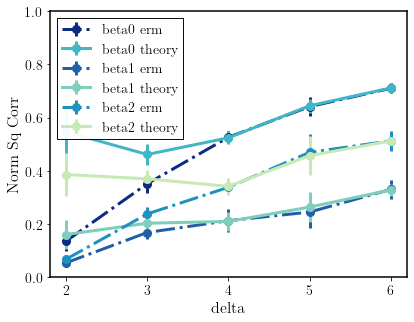

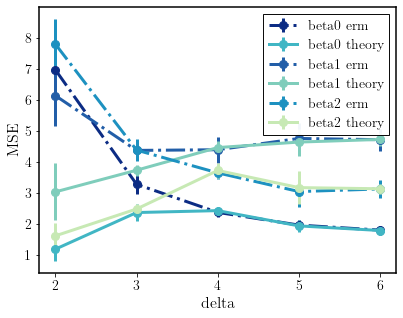

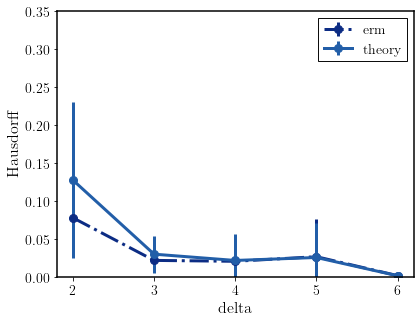

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

In [38]:
PAL = ['#0c2c84','#225ea8','#1d91c0','#41b6c4','#7fcdbb','#c7e9b4','#edf8b1','#ffffd9']
erm_corr_arr = results['corr_ERM-LS']
theory_corr_arr = results['corr_Theory-LS']
erm_MSE_arr = results['mse_ERM-LS']
theory_MSE_arr = results['mse_Theory-LS']
erm_haus_arr = results['haus_ERM-LS']
theory_haus_arr = results['haus_Theory-LS']
erm_size_arr = results['size_ERM-LS']
theory_size_arr = results['size_Theory-LS']
# Sqcorr plots
for ℓ_ in range(L):
    plt.errorbar(δ_list, np.mean(erm_corr_arr[:, :, ℓ_], axis = 1), yerr = np.std(erm_corr_arr[:, :, ℓ_], axis = 1), label="beta" + str(ℓ_) + " erm", marker="o", ls="-.", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, np.mean(theory_corr_arr[:, :, ℓ_], axis = 1), yerr = np.std(theory_corr_arr[:, :, ℓ_], axis = 1), label="beta" + str(ℓ_) + " theory", marker="o", ls="-", c=PAL[ℓ_ + L], alpha = 1.0)
plt.ylim((0, 1))
plt.xlabel("delta")
plt.ylabel("Norm Sq Corr")
plt.legend()
plt.show()

# MSE plots
for ℓ_ in range(L):
    plt.errorbar(δ_list, np.mean(erm_MSE_arr[:, :, ℓ_], axis = 1), yerr = np.std(erm_MSE_arr[:, :, ℓ_], axis = 1), label="beta" + str(ℓ_) + " erm", marker="o", ls="-.", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, np.mean(theory_MSE_arr[:, :, ℓ_], axis = 1), yerr = np.std(theory_MSE_arr[:, :, ℓ_], axis = 1), label="beta" + str(ℓ_) + " theory", marker="o", ls="-", c=PAL[ℓ_ + L], alpha = 1.0)
# plt.ylim((0, 2))
plt.xlabel("delta")
plt.ylabel("MSE")
plt.legend()
plt.show()

# Hausdorff plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
plt.errorbar(δ_list, np.mean(erm_haus_arr, axis = 1), yerr = np.std(erm_haus_arr, axis = 1), label="erm", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
plt.errorbar(δ_list, np.mean(theory_haus_arr, axis = 1), yerr = np.std(theory_haus_arr, axis = 1), label="theory", marker="o", ls="-", c=PAL[1], alpha = 1.0)
plt.ylim((0, 0.35))
plt.xlabel("delta")
plt.ylabel("Hausdorff")
plt.legend()
# plt.savefig("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Hausdorff plots with 25-75 percentile error bars
erm_haus_arr = results['haus_ERM-LS']
theory_haus_arr = results['haus_Theory-LS']
num_trials = erm_haus_arr.shape[1]
# Ensure the arrays are 2D for boxplotting
erm_haus_arr = erm_haus_arr.reshape(len(δ_list), num_trials)
theory_haus_arr = theory_haus_arr.reshape(len(δ_list), num_trials)
# Calculate 25th and 75th percentiles for error bars
erm_haus_p25 = np.nanpercentile(erm_haus_arr, 25, axis=1)
erm_haus_p75 = np.nanpercentile(erm_haus_arr, 75, axis=1)
theory_haus_p25 = np.nanpercentile(theory_haus_arr, 25, axis=1)
theory_haus_p75 = np.nanpercentile(theory_haus_arr, 75, axis=1)
# Calculate means for plotting
erm_haus_means = np.nanmean(erm_haus_arr, axis=1)
theory_haus_means = np.nanmean(theory_haus_arr, axis=1)
# Create plot data with asymmetric error bars
erm_haus_errors = [max(0,erm_haus_means - erm_haus_p25), erm_haus_p75 - erm_haus_means]
theory_haus_errors = [max(0,theory_haus_means - theory_haus_p25), theory_haus_p75 - theory_haus_means]
# Plot with asymmetric error bars
plt.figure(figsize=(10, 6))
plt.errorbar(δ_list, erm_haus_means, yerr=erm_haus_errors, label='ERM', marker='o', ls='-.', color=PAL[0], alpha=1.0, capsize=4, capthick=2, markersize=8, linewidth=2.5, markeredgewidth=2, markeredgecolor='white')
plt.errorbar(δ_list, theory_haus_means, yerr=theory_haus_errors, label='Theory', marker='o', ls='-', color=PAL[1], alpha=1.0, capsize=4, capthick=2, markersize=8, linewidth=2.5, markeredgewidth=2, markeredgecolor='white')
plt.xlabel(r'$\delta = n/p$', fontsize=18)
plt.ylabel('Hausdorff Distance', fontsize=18)
plt.title('Hausdorff Distance with 25-75 Percentile Error Bars', fontsize=20, pad=15)
plt.xticks(δ_list, [f'{d:.1f}' for d in δ_list], fontsize=14)
plt.ylim((0, 0.35))
plt.legend(fontsize=12, frameon=True, edgecolor='black', framealpha=0.95)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Display boxplots for Hausdorff
plt.figure(figsize=(10, 6))
box_data_erm = [erm_haus_arr[i, ~np.isnan(erm_haus_arr[i, :])] for i in range(len(δ_list))]
box_data_theory = [theory_haus_arr[i, ~np.isnan(theory_haus_arr[i, :])] for i in range(len(δ_list))]
positions_erm = np.array(range(len(δ_list))) * 2.0 - 0.3
positions_theory = np.array(range(len(δ_list))) * 2 + 0.3
bp_erm = plt.boxplot(box_data_erm, positions=positions_erm, widths=0.5,
                     patch_artist=True, boxprops=dict(facecolor=PAL[0], edgecolor='black', linewidth=1.5),
                     medianprops=dict(color='white', linewidth=2.5),
                     whiskerprops=dict(linewidth=1.5),
                     capprops=dict(linewidth=1.5),
                     flierprops=dict(marker='o', markersize=4, alpha=0.6))
bp_theory = plt.boxplot(box_data_theory, positions=positions_theory, widths=0.5,
                        patch_artist=True, boxprops=dict(facecolor=PAL[1], edgecolor='black', linewidth=1.5),
                        medianprops=dict(color='white', linewidth=2.5),
                        whiskerprops=dict(linewidth=1.5),
                        capprops=dict(linewidth=1.5),
                        flierprops=dict(marker='o', markersize=4, alpha=0.6))
plt.xticks(np.array(range(len(δ_list))) * 2, [f'{d:.1f}' for d in δ_list])
plt.xlabel(r'$\delta = n/p$', fontsize=18)
plt.ylabel('Hausdorff Distance', fontsize=18)
plt.title('Hausdorff Distance Distribution by Method', fontsize=20, pad=15)
plt.legend([bp_erm["boxes"][0], bp_theory["boxes"][0]], ['ERM', 'Theory'], loc='upper right', fontsize=12, frameon=True, edgecolor='black', framealpha=0.95)
plt.ylim((0, 0.35))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Hausdorff plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
plt.errorbar(δ_list, np.mean(erm_size_arr, axis = 1), yerr = np.std(erm_haus_arr, axis = 1), label="erm", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
plt.errorbar(δ_list, np.mean(theory_size_arr, axis = 1), yerr = np.std(theory_haus_arr, axis = 1), label="theory", marker="o", ls="-", c=PAL[1], alpha = 1.0)
plt.ylim((0, L + 1))
plt.xlabel("delta")
plt.ylabel("Size")
plt.legend()
# plt.savefig("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Runtime plots
# δ_arr = np.array([δ_list for _ in range(num_trials)])
# plt.errorbar(δ_list, np.mean(ERM_runtime, axis = 1), yerr = np.std(ERM_runtime, axis = 1), label="ERM", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
# plt.xlabel("δ")
# plt.ylabel("Runtime")
# plt.legend()
# plt.show()

# SE match estimation: switching prior

In [ ]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
import WERM.model as model
import WERM.general_fixed_point_eqns as fp
import WERM.M_est_fixed_point_eqns as M_est
import WERM.gof
import WERM.performance_measures
import WERM.marginals
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm.auto import tqdm
import time
from joblib import Parallel, delayed
import logging
from datetime import datetime, timedelta
import sys
import pickle
import os

# Set a random seed for reproducibility
random_seed = 42
nprandom.seed(random_seed)
jax.random.PRNGKey(random_seed) # Set JAX random seed as well

# --- Logging Setup ---
def setup_logging():
    """Setup comprehensive logging for the simulation"""
    detailed_formatter = logging.Formatter(
        '%(asctime)s - %(name)s - %(levelname)s - %(message)s',
        datefmt='%Y-%m-%d %H:%M:%S'
    )
    simple_formatter = logging.Formatter(
        '%(asctime)s - %(message)s',
        datefmt='%H:%M:%S'
    )

    # Create logs directory if it doesn't exist
    import os
    log_dir = 'logs'
    if not os.path.exists(log_dir):
        os.makedirs(log_dir)

    main_logger = logging.getLogger('simulation')
    main_logger.setLevel(logging.INFO)
    main_logger.handlers = [] # Clear existing handlers

    console_handler = logging.StreamHandler(sys.stdout)
    console_handler.setLevel(logging.INFO)
    console_handler.setFormatter(simple_formatter)
    main_logger.addHandler(console_handler)

    file_handler = logging.FileHandler('logs/WERM_switch_simulation_detailed.log', mode='w')
    file_handler.setLevel(logging.DEBUG)
    file_handler.setFormatter(detailed_formatter)
    main_logger.addHandler(file_handler)

    progress_logger = logging.getLogger('progress')
    progress_logger.setLevel(logging.INFO)
    progress_logger.handlers = [] # Clear existing handlers

    progress_handler = logging.FileHandler('logs/WERM_switch_simulation_progress.log', mode='w')
    progress_handler.setLevel(logging.INFO)
    progress_handler.setFormatter(detailed_formatter)
    progress_logger.addHandler(progress_handler)

    return main_logger, progress_logger

# Initialize loggers
main_logger, progress_logger = setup_logging()

class ProgressTracker:
    """Class to track and log simulation progress"""
    def __init__(self, total_tasks, delta_list, num_trials, logger):
        self.total_tasks = total_tasks
        self.delta_list = delta_list
        self.num_trials = num_trials
        self.logger = logger
        self.start_time = time.time()
        self.completed_tasks = 0
        self.delta_progress = {i: 0 for i in range(len(delta_list))}

    def update(self, delta_idx):
        """Update progress for a completed task"""
        self.completed_tasks += 1
        percent_complete = (self.completed_tasks / self.total_tasks) * 100
        elapsed_time = time.time() - self.start_time
        if self.completed_tasks > 0:
            avg_time_per_task = elapsed_time / self.completed_tasks
            remaining_tasks = self.total_tasks - self.completed_tasks
            estimated_remaining_time = remaining_tasks * avg_time_per_task
            estimated_completion = datetime.now() + timedelta(seconds=estimated_remaining_time)
            self.logger.info(
                f"Progress: {self.completed_tasks}/{self.total_tasks} ({percent_complete:.1f}%) | "
                f"Elapsed: {elapsed_time:.1f}s | "
                f"Est. remaining: {estimated_remaining_time:.1f}s | "
                f"Est. completion: {estimated_completion.strftime('%H:%M:%S')}"
            )
        self.delta_progress[delta_idx] += 1
        # Log delta-specific progress less frequently to avoid excessive logging
        if self.completed_tasks % max(1, self.total_tasks // 10) == 0 or self.completed_tasks == 1 or self.completed_tasks == self.total_tasks:
            delta_status = []
            for i, delta in enumerate(self.delta_list):
                progress = self.delta_progress[i]
                delta_status.append(f"δ={delta:.1f}: {progress}/{self.num_trials}")
            self.logger.info("Delta progress: " + " | ".join(delta_status))

# Global progress tracker (initialized later)
progress_tracker = None

# --- Helper Function for a Single Parallel Job ---
def run_single_trial(params, p, L, noise_std, fractional_chgpt_locations, M, method_configs, B_tilde_scaled, delta_precomputed_data):
    """
    Executes a single simulation trial for a given delta, running multiple methods.
    This function is designed to be called in parallel by joblib.
    """
    global progress_tracker
    i, δ, j = params # i: delta_list index, δ: current delta value, j: trial number
    trial_start_time = time.time()
    progress_logger.info(f"Starting trial {j+1}/{num_trials} for δ={δ:.1f} (delta_idx={i})")

    # Retrieve precomputed data for this delta
    n = delta_precomputed_data['n']
    C_true = delta_precomputed_data['C_true']
    pi_unif = delta_precomputed_data['pi_unif']
    pi_switch = delta_precomputed_data['pi_switch']
    b_unif = delta_precomputed_data['b_unif']
    ν̃_unif = delta_precomputed_data['nu_tilde_unif']
    κ̃_unif = delta_precomputed_data['kappa_tilde_unif']
    κ̃_sqrt_unif = delta_precomputed_data['kappa_tilde_sqrt_unif']
    b_switch = delta_precomputed_data['b_switch']
    ν̃_switch = delta_precomputed_data['nu_tilde_switch']
    κ̃_switch = delta_precomputed_data['kappa_tilde_switch']
    κ̃_sqrt_switch = delta_precomputed_data['kappa_tilde_sqrt_switch']
    ρ = delta_precomputed_data['rho']
    true_chgpt_locations_n = delta_precomputed_data['true_chgpt_locations_n']
    ε = delta_precomputed_data['varepsilon']
    B_tilde_scaled = delta_precomputed_data['B_tilde_scaled']
    assert δ == int(n/p)

    # --- Data Generation for this trial ---
    data_gen_start = time.time()
    X = nprandom.normal(0, np.sqrt(1/n), (n, p))
    X = X @ Sigma_chol.T
    Θ = X @ B_tilde_scaled
    y_mapped_fn = jax.vmap(model.q_linear_model, in_axes=(0, 0, 0))
    y = y_mapped_fn(Θ, C_true, ε)
    data_gen_time = time.time() - data_gen_start

    trial_results = {}
    methods_status = {method_name: False for method_name in method_configs.keys()}
    Δ = lambda n: int(n/40)

    # --- Run Estimators for all configured methods ---
    for method_name, method_func_info in method_configs.items():
        try:
            method_start = time.time()
            current_B̂ = np.zeros((p, L))
            Θ̂_theory = np.zeros((n, L))
            current_corr_list = []
            current_mse_list = []
            current_chgpt_loc = np.array([])

            if method_name == 'ERM-LS':
                for ℓ_ in range(L):
                    sample_weight = pi_switch[ℓ_, :]
                    empirical_risk = lambda β: jnp.multiply(M((X @ β).flatten(), y.flatten()), sample_weight).sum()
                    res = scipy.optimize.minimize(empirical_risk, 0.1*np.ones(p), jac=jax.grad(empirical_risk), method='L-BFGS-B')
                    β̂ = res.x
                    current_B̂[:, ℓ_] = β̂
                    current_corr_list.append(WERM.norm_sq_corr(β̂, B̃[:, ℓ_]))
                    current_mse_list.append(WERM.MSE(β̂.flatten(), B̃[:, ℓ_]))

                opt_chgpt_loc_erm, _ = WERM.gof.chgpt_binary_segmentation(
                    M, X @ current_B̂, y, n, L, 1, L_is_upper_bound=False,
                    γ=0, gof_opt_output=True
                )

                # opt_chgpt_loc_erm, _=  WERM.gof.chgpt_gof_bf_mem_eff(
                #     M, X @ current_B̂, y, n, L, delta_precomputed_data['Delta_n'], γ=0.0, 
                #     L_is_upper_bound = False, batch_size=4096, gof_opt_output=True
                # )


                current_chgpt_loc = opt_chgpt_loc_erm
                print("ERM Switch changept locations (fractional):", current_chgpt_loc /n)
            elif method_name == 'Theory-LS':
                G_sample = nprandom.multivariate_normal(np.zeros((L, )), np.eye(L), size=(p,)) @ κ̃_sqrt_switch.T
                G_sample_n = nprandom.multivariate_normal(np.zeros((L, )), np.eye(L), size=(n,)) @ κ̃_sqrt_switch.T
                Z = nprandom.multivariate_normal(np.zeros((L, )), ρ, size=(n,))
                y_theory = y_mapped_fn(Z, C_true, ε)

                M_prime = jax.grad(M, argnums=0)
                M_double_prime = jax.grad(M_prime, argnums=0)

                for ℓ_ in range(L):
                    β̂_theory = B̃ @ ν̃_switch[:, ℓ_] + δ**(1/2) * np.linalg.inv(Sigma_chol).T @ G_sample[:, ℓ_]
                    current_B̂[:, ℓ_] = β̂_theory
                    current_corr_list.append(WERM.norm_sq_corr(β̂_theory, B̃[:, ℓ_]))
                    current_mse_list.append(WERM.MSE(β̂_theory.flatten(), B̃[:, ℓ_]))

                    sample_weight = pi_switch[ℓ_, :]
                    prox_mapped = lambda z, b_val, pi_i, v: jax.vmap(fp.prox, in_axes=(0, None, 0, 0, None, None))(z, b_val, pi_i, v, M_prime, M_double_prime)
                    Θ̂_theory[:, ℓ_] = prox_mapped(Z @ ν̃_switch[:, ℓ_] + G_sample_n[:, ℓ_], b_switch[ℓ_], sample_weight, y_theory)

                opt_chgpt_loc_theory, _ = WERM.gof.chgpt_binary_segmentation(
                    M, Θ̂_theory, y_theory, n, L, delta_precomputed_data['Delta_n'], L_is_upper_bound=False,
                    γ=0, gof_opt_output=True
                )
                current_chgpt_loc = opt_chgpt_loc_theory
            elif method_name == 'ERM-unif':
                for ℓ_ in range(L):
                    sample_weight = pi_unif[ℓ_, :]
                    empirical_risk = lambda β: jnp.multiply(M((X @ β).flatten(), y.flatten()), sample_weight).sum()
                    res = scipy.optimize.minimize(empirical_risk, 0.1*np.ones(p), jac=jax.grad(empirical_risk), method='L-BFGS-B')
                    β̂ = res.x
                    current_B̂[:, ℓ_] = β̂
                    current_corr_list.append(WERM.norm_sq_corr(β̂, B̃[:, ℓ_]))
                    current_mse_list.append(WERM.MSE(β̂.flatten(), B̃[:, ℓ_]))

                opt_chgpt_loc_erm, _ = WERM.gof.chgpt_binary_segmentation(
                    M, X @ current_B̂, y, n, L, 1, L_is_upper_bound=False,
                    γ=0, gof_opt_output=True
                )
                current_chgpt_loc = opt_chgpt_loc_erm
                print("ERM Unif changept locations (fractional):", current_chgpt_loc /n)
            elif method_name == 'Theory-unif':
                G_sample = nprandom.multivariate_normal(np.zeros((L, )), np.eye(L), size=(p,)) @ κ̃_sqrt_unif.T
                G_sample_n = nprandom.multivariate_normal(np.zeros((L, )), np.eye(L), size=(n,)) @ κ̃_sqrt_unif.T
                Z = nprandom.multivariate_normal(np.zeros((L, )), ρ, size=(n,))
                y_theory = y_mapped_fn(Z, C_true, ε)

                M_prime = jax.grad(M, argnums=0)
                M_double_prime = jax.grad(M_prime, argnums=0)

                for ℓ_ in range(L):
                    β̂_theory = B̃ @ ν̃_unif[:, ℓ_] + δ**(1/2) * np.linalg.inv(Sigma_chol).T @ G_sample[:, ℓ_]
                    current_B̂[:, ℓ_] = β̂_theory
                    current_corr_list.append(WERM.norm_sq_corr(β̂_theory, B̃[:, ℓ_]))
                    current_mse_list.append(WERM.MSE(β̂_theory.flatten(), B̃[:, ℓ_]))

                    sample_weight = pi_unif[ℓ_, :]
                    prox_mapped = lambda z, b_val, pi_i, v: jax.vmap(fp.prox, in_axes=(0, None, 0, 0, None, None))(z, b_val, pi_i, v, M_prime, M_double_prime)
                    Θ̂_theory[:, ℓ_] = prox_mapped(Z @ ν̃_unif[:, ℓ_] + G_sample_n[:, ℓ_], b_unif[ℓ_], sample_weight, y_theory)

                opt_chgpt_loc_theory, _ = WERM.gof.chgpt_binary_segmentation(
                    M, Θ̂_theory, y_theory, n, L, delta_precomputed_data['Delta_n'], L_is_upper_bound=False,
                    γ=0, gof_opt_output=True
                )
                current_chgpt_loc = opt_chgpt_loc_theory
            else:
                main_logger.warning(f"Method {method_name} not recognized. Skipping.")
                continue

            method_time = time.time() - method_start
            trial_results[f'runtime_{method_name}'] = method_time
            trial_results[f'corr_{method_name}'] = np.array(current_corr_list)
            trial_results[f'mse_{method_name}'] = np.array(current_mse_list)
            trial_results[f'haus_{method_name}'] = (1/n * WERM.performance_measures.hausdorff(current_chgpt_loc, true_chgpt_locations_n))
            trial_results[f'size_{method_name}'] = len(current_chgpt_loc[current_chgpt_loc != -1])
            print("Saving chgpts for method:", method_name)
            print("current_chgpt_loc fractional:", current_chgpt_loc.copy() / n)
            trial_results[f'chgpts_{method_name}'] = current_chgpt_loc.copy()
            methods_status[method_name] = True

        except Exception as e:
            main_logger.error(f"Trial {j+1} for δ={δ:.1f}: {method_name} failed with error: {e}", exc_info=True)
            trial_results[f'runtime_{method_name}'] = np.nan
            trial_results[f'corr_{method_name}'] = np.full(L, np.nan)
            trial_results[f'mse_{method_name}'] = np.full(L, np.nan)
            trial_results[f'haus_{method_name}'] = np.nan
            trial_results[f'size_{method_name}'] = np.nan
            trial_results[f'chgpts_{method_name}'] = np.array([])
            methods_status[method_name] = False

    # Store additional info for histogram plotting
    trial_results['n'] = n
    trial_results['true_chgpts'] = true_chgpt_locations_n.copy()
    trial_results['fractional_true_chgpts'] = fractional_chgpt_locations.copy()
    trial_results['methods_status'] = methods_status

    trial_total_time = time.time() - trial_start_time
    log_message_parts = [
        f"Completed trial {j+1} for δ={δ:.1f}: ",
        f"Total={trial_total_time:.1f}s (Data={data_gen_time:.1f}s)"
    ]
    for method_name in method_configs.keys():
        status_str = 'OK' if methods_status[method_name] else 'FAIL'
        runtime_str = f"{trial_results[f'runtime_{method_name}']:.1f}s" if f'runtime_{method_name}' in trial_results and not np.isnan(trial_results[f'runtime_{method_name}']) else "N/A"
        log_message_parts.append(f"{method_name}={status_str} ({runtime_str})")
    progress_logger.info(" ".join(log_message_parts))

    if progress_tracker:
        progress_tracker.update(i)
    return i, j, trial_results

# --- Main Script Setup ---
main_logger.info("Starting WERM Simulation with parallel execution and enhanced logging")
main_logger.info("=" * 80)

# Simulation Parameters
p = 600 # 700 used by default
L = 3 # num signals. L-1 changepoints
noise_std = np.sqrt(0.3)
# δ_list = np.arange(2.0, 6.1, 1.0)
δ_list = np.arange(2.0, 4.0, 1.0)
num_trials = 2 # Increased for better statistics
fractional_chgpt_locations = np.array([0.4, 0.6]) # Single changepoint at 0.7n
# n_jobs = 14 # Use all available CPU cores. Set to 1 for no parallelization.
n_jobs = 1 # Use all available CPU cores. Set to 1 for no parallelization.

# Least Squares Loss
M = lambda u, v: jnp.power(u - v, 2)
# Huber Loss
# def M(u, v, epsilon=1.35):
#     residual = u - v
#     abs_residual = jnp.abs(residual)
#     condition = abs_residual <= epsilon
#     squared_loss = 0.5 * jnp.square(residual)
#     linear_loss = epsilon * (abs_residual - 0.5 * epsilon)
#     return jnp.where(condition, squared_loss, linear_loss)

# Sample the signal outside
κ = 1.0
B̃_cov = κ**2 * np.eye(L) # Remove the δ term here, multiply it inside of the trial loop since we vary δ
# Make the first and third signals identical
B̃_cov[0, 0] = κ**2
B̃_cov[2, 2] = κ**2
B̃_cov[0, 2] = 0.99 * κ**2 # Covariance between first and third signals, make them not perfectly identical for numerical stability
B̃_cov[2, 0] = 0.99 * κ**2 # Covariance between first and third signals, make them not perfectly identical for numerical stability
print(f"B̃_cov:\n{B̃_cov}")
B̃_cov = B̃_cov + 1e-3 * jnp.eye(L) # Add small noise to ensure positive definiteness
signal_prior = GaussianSignal(B̃_cov)
B̃ = signal_prior.sample(p)

# Draw Sigma from an AR(1) process for some correlation structure r_s = 0.5
r_s = 0.0
AR1 = np.fromfunction(lambda i, j: r_s**(np.abs(i - j)), (p, p))
Sigma = AR1
Sigma_chol = np.linalg.cholesky(Sigma + 1e-12 * np.eye(p)) # Add small ridge for numerical stability

batch_size = 4096*2 # Batch size for memory efficient computation of brute force solution

# --- Define Methods to be Evaluated ---
methods_to_evaluate = [
    {'name': 'ERM-LS', 'label': r'\textbf{ERM-switch}', 'color': '#EE7733', 'marker': 'o', 'linestyle': '-'},
    # {'name': 'Theory-LS', 'label': r'\textbf{Theory-switch}', 'color': '#0077BB', 'marker': 's', 'linestyle': '--'},
    {'name': 'ERM-unif', 'label': r'\textbf{ERM-unif}', 'color': '#EE7733', 'marker': 'd', 'linestyle': '-.'},
    # {'name': 'Theory-unif', 'label': r'\textbf{Theory-unif}', 'color': '#0077BB', 'marker': '^', 'linestyle': ':'},
]
# Create a dictionary for easy lookup within run_single_trial
method_configs = {method['name']: method for method in methods_to_evaluate}
method_names_list = [m['name'] for m in methods_to_evaluate] # List of just names

# Log simulation parameters
main_logger.info(f"Simulation Parameters:")
main_logger.info(f" p (features): {p}")
main_logger.info(f" L (signals): {L}")
main_logger.info(f" noise_std: {noise_std}")
main_logger.info(f" δ_list: {δ_list}")
main_logger.info(f" num_trials: {num_trials}")
main_logger.info(f" fractional_chgpt_locations: {fractional_chgpt_locations}")
main_logger.info(f" n_jobs: {n_jobs}")
main_logger.info(f" Loss function: Least Squares")
main_logger.info(f" Methods to evaluate: {method_names_list}")
main_logger.info(f" Total tasks: {len(δ_list) * num_trials}")

# Results Storage
results = {
    'successful_trials': {method['name']: np.zeros(len(δ_list), dtype=int) for method in methods_to_evaluate},
    'true_chgpts': [],
    'n_values': [],
    'delta_values': []
}
for method in methods_to_evaluate:
    method_name = method['name']
    results[f'corr_{method_name}'] = np.full((len(δ_list), num_trials, L), np.nan)
    results[f'mse_{method_name}'] = np.full((len(δ_list), num_trials, L), np.nan)
    results[f'haus_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'size_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'runtime_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'chgpts_{method_name}'] = [] # Store (delta_idx, chgpts_array) for histogram plotting

# --- Precompute delta-dependent fixed values ---
main_logger.info("Precomputing delta-dependent fixed values...")
delta_precomputed_data = {}

# First check if can load precomputed data
precomputed_file = f"results/precomputed/precomputed_switch_unif_fps_deltalist_p{p}_L{L}_{'_'.join([f'{d:.1f}' for d in δ_list])}.pkl"
main_logger.info(f"Loading precomputed data from {precomputed_file}")
try:
    with open(precomputed_file, 'rb') as f:
        delta_precomputed_data = pickle.load(f)
except Exception as e:
    main_logger.error(f"Error loading precomputed data: {e}")
    main_logger.info(f"No precomputed data found at {precomputed_file}, generating new data...")
    for i, δ in enumerate(tqdm(δ_list, desc="Precomputing for deltas", ncols=100, leave=True)):
        n = int(δ * p)
        if fractional_chgpt_locations.size != 0:
            true_chgpt_locations = lambda n_len: (n_len * fractional_chgpt_locations).astype(int)
            C_true = η_to_ψ(true_chgpt_locations(n), n)
        else:
            true_chgpt_locations = lambda n_len: np.array([])
            C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0.

        Δ_n = int(n / 5) # Updated to be Delta_n to avoid conflict with Delta in original code
        n_small = 100
        Delta_n_small = int(Δ_n * n_small/n)

        pi_unif = WERM.config.extrapolated_marginals(L, L, Delta_n_small, n_small = n_small, n_large = n, p_l = None, verbose = False)
        pi_unif = pi_unif / np.sum(pi_unif, axis=1, keepdims=True) # Lxn matrix

        # Plot the rows of pi_unif
        plt.figure(figsize=(10, 6))
        for ℓ in range(L):
            plt.plot(pi_unif[ℓ, :], label=f'pi_unif_{ℓ+1}', marker='o', linestyle='-', markersize=4)
        plt.xlabel('Signal Index')
        plt.ylabel('Probability')
        plt.title(f'Uniform Prior pi_unif for delta={δ:.1f}, n={n}')
        plt.xticks(range(n_small), [f'{i+1}' for i in range(n_small)], rotation=45)
        plt.legend()
        plt.tight_layout()
        plt.show()

        # Switching signal prior: add first and third rows of π
        pi_switch = np.zeros((L, n))
        pi_switch[0, :] = pi_unif[0, :] + pi_unif[2, :] # Combine first and third rows
        pi_switch[1, :] = pi_unif[1, :] # Keep second row unchanged
        pi_switch[2, :] = pi_unif[0, :] + pi_unif[2, :] # Repeat for third row

        # Normalize the new π
        pi_switch = pi_switch / np.sum(pi_switch, axis=1, keepdims=True)

        # Plot the rows of pi_switch
        plt.figure(figsize=(10, 6))
        for ℓ in range(L):
            plt.plot(pi_switch[ℓ, :], label=f'pi_switch_{ℓ+1}', marker='o', linestyle='-', markersize=4)
        plt.xlabel('Signal Index')
        plt.ylabel('Probability')
        plt.title(f'Switching Prior pi_switch for delta={δ:.1f}, n={n}')
        plt.xticks(range(n), [f'{i+1}' for i in range(n)], rotation=45)
        plt.legend()
        plt.tight_layout()
        plt.show()

        # Scale B̃ by sqrt(delta) here as it's part of the signal definition
        B_tilde_scaled_for_delta = np.sqrt(δ) * B̃

        # Sample ε
        # ε = nprandom.standard_t(5, size=(n, )) * noise_std # Use t-distribution for noise, df > 2 has finite variance
        ε = nprandom.normal(0, noise_std, size=(n, )) # Use Gaussian noise for simplicity

        rho = (1/δ) * (1/p) * (B_tilde_scaled_for_delta.T @ Sigma_chol @ Sigma_chol.T @ B_tilde_scaled_for_delta) # Add small regularization to avoid singularity

        b_unif, ν̃_unif, κ̃_unif = fp.general_fp(M, rho, δ, true_chgpt_locations(n), pi_unif, ε, n, model.q_linear_model) # ε is only for data gen, use zeros here
        κ̃_sqrt_unif = jnp.linalg.cholesky(κ̃_unif + 1e-12 * jnp.eye(L))

        b_switch, ν̃_switch, κ̃_switch = fp.general_fp(M, rho, δ, true_chgpt_locations(n), pi_switch, ε, n, model.q_linear_model) # ε is only for data gen, use zeros here
        κ̃_sqrt_switch = jnp.linalg.cholesky(κ̃_switch + 1e-12 * jnp.eye(L))

        delta_precomputed_data[i] = {
            'n': n,
            'C_true': C_true,
            'true_chgpt_locations_n': true_chgpt_locations(n),
            'fractional_chgpt_locations': fractional_chgpt_locations,
            'pi_unif': pi_unif,
            'pi_switch': pi_switch,
            'Delta_n': Δ_n,
            'b_switch': b_switch,
            'nu_tilde_switch': ν̃_switch,
            'kappa_tilde_switch': κ̃_switch,
            'kappa_tilde_sqrt_switch': κ̃_sqrt_switch,
            'b_unif': b_unif,
            'nu_tilde_unif': ν̃_unif,
            'kappa_tilde_unif': κ̃_unif,
            'kappa_tilde_sqrt_unif': κ̃_sqrt_unif,
            'rho': rho,
            'B_tilde_scaled': B_tilde_scaled_for_delta, # Store the scaled B_tilde for this delta
            'varepsilon': ε, # Store the noise for this delta
        }
        print(f"--- Precomputed for δ={δ:.1f}: b={b_switch}, ν̃={ν̃_switch}, κ̃={κ̃_switch}, b_unif={b_unif}, ν̃_unif={ν̃_unif}, κ̃_unif={κ̃_unif}, ρ={rho} ---")

    # Save precomputed data to a file for later use
    delta_list_str = '_'.join([f"{d:.1f}" for d in δ_list])
    with open(f"results/precomputed/precomputed_switch_unif_fps_deltalist_p{p}_L{L}_{delta_list_str}.pkl", "wb") as f:
        pickle.dump(delta_precomputed_data, f)

# --- Parallel Execution ---
# Now, tasks only need to include (delta_idx, delta_value, trial_number)
# The delta_precomputed_data will be passed to run_single_trial and accessed by delta_idx
tasks = [(i, δ, j) for i, δ in enumerate(δ_list) for j in range(num_trials)]

main_logger.info("=" * 80)
main_logger.info(f"Starting {len(tasks)} simulation trials")
main_logger.info(f"Using {n_jobs if n_jobs != -1 else 'all available'} CPU cores")

# Rough estimate for total time, adjust based on typical single trial runtime
single_trial_estimate = 20.0 # seconds, adjust this based on observation
total_estimated_time = len(tasks) * single_trial_estimate / (n_jobs if n_jobs > 0 else 4)
estimated_completion = datetime.now() + timedelta(seconds=total_estimated_time)
main_logger.info(f"Estimated total time: {total_estimated_time/60:.1f} minutes")
main_logger.info(f"Estimated completion: {estimated_completion.strftime('%Y-%m-%d %H:%M:%S')}")
main_logger.info("=" * 80)

progress_tracker = ProgressTracker(len(tasks), δ_list, num_trials, main_logger)
simulation_start_time = time.time()

try:
    parallel_results = Parallel(n_jobs=n_jobs, verbose=0)(
        delayed(run_single_trial)(
            params=task,
            p=p,
            L=L,
            noise_std=noise_std,
            fractional_chgpt_locations=fractional_chgpt_locations,
            M=M,
            method_configs=method_configs,
            B_tilde_scaled=delta_precomputed_data[task[0]]['B_tilde_scaled'], # Pass the pre-scaled B_tilde
            delta_precomputed_data=delta_precomputed_data[task[0]] # Pass precomputed data for current delta
        ) for task in tqdm(tasks, desc="Running simulation trials", ncols=100, leave=True)
    )
    simulation_end_time = time.time()
    total_simulation_time = simulation_end_time - simulation_start_time
    main_logger.info("=" * 80)
    main_logger.info(f"Simulation completed successfully!")
    main_logger.info(f"Total simulation time: {total_simulation_time/60:.2f} minutes")
    main_logger.info(f"Average time per trial: {total_simulation_time/len(tasks):.2f} seconds")
    main_logger.info("=" * 80)

except Exception as e:
    main_logger.error(f"Simulation failed with error: {str(e)}", exc_info=True)
    raise

# --- Aggregate Results ---
main_logger.info("Aggregating results...")
aggregation_start_time = time.time()
for result_idx, (i, j, trial_result) in enumerate(parallel_results):
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        if trial_result['methods_status'][method_name]:
            results[f'corr_{method_name}'][i, j, :] = trial_result[f'corr_{method_name}']
            results[f'mse_{method_name}'][i, j, :] = trial_result[f'mse_{method_name}']
            results[f'haus_{method_name}'][i, j] = trial_result[f'haus_{method_name}']
            results[f'size_{method_name}'][i, j] = trial_result[f'size_{method_name}']
            results[f'runtime_{method_name}'][i, j] = trial_result[f'runtime_{method_name}']
            results['successful_trials'][method_name][i] += 1
            results[f'chgpts_{method_name}'].append((i, trial_result[f'chgpts_{method_name}'])) # Always append, even if empty
    results['true_chgpts'].append((i, trial_result['true_chgpts']))
    results['n_values'].append((i, trial_result['n']))
    results['delta_values'].append((i, δ_list[i]))

aggregation_time = time.time() - aggregation_start_time
main_logger.info(f"Results aggregation completed in {aggregation_time:.2f} seconds")

# Log summary statistics
main_logger.info("=" * 40)
main_logger.info("SIMULATION SUMMARY STATISTICS")
main_logger.info("=" * 40)
for i, delta in enumerate(δ_list):
    main_logger.info(f"δ = {delta:.1f}:")
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        avg_corr = np.nanmean(results[f'corr_{method_name}'][i, :, :])
        std_corr = np.nanstd(results[f'corr_{method_name}'][i, :, :])
        avg_mse = np.nanmean(results[f'mse_{method_name}'][i, :, :])
        std_mse = np.nanstd(results[f'mse_{method_name}'][i, :, :])
        avg_haus = np.nanmean(results[f'haus_{method_name}'][i, :])
        std_haus = np.nanstd(results[f'haus_{method_name}'][i, :])
        avg_size = np.nanmean(results[f'size_{method_name}'][i, :])
        std_size = np.nanstd(results[f'size_{method_name}'][i, :])
        avg_runtime = np.nanmean(results[f'runtime_{method_name}'][i, :])
        std_runtime = np.nanstd(results[f'runtime_{method_name}'][i, :])
        num_success = results['successful_trials'][method_name][i]
        main_logger.info(f" {method_name} - Successful Trials: {num_success}/{num_trials}")
        main_logger.info(f" {method_name} - Avg Norm Sq Corr: {avg_corr:.4f} ± {std_corr:.4f}")
        main_logger.info(f" {method_name} - Avg MSE: {avg_mse:.4f} ± {std_mse:.4f}")
        main_logger.info(f" {method_name} - Avg Hausdorff: {avg_haus:.4f} ± {std_haus:.4f}")
        main_logger.info(f" {method_name} - Avg Size: {avg_size:.2f} ± {std_size:.2f}")
        main_logger.info(f" {method_name} - Avg Runtime: {avg_runtime:.2f}s ± {std_runtime:.2f}s")
        main_logger.info("")

# --- Publication-Ready Enhanced Plotting Results ---
plt.rcParams.update({
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': False,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 3.0,
    'lines.markersize': 8,
    'figure.dpi': 72,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})
main_logger.info("Creating publication-ready plots...")
plotting_start_time = time.time()

# Paul Tol "Vibrant" - optimal balance of aesthetics and accessibility
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB', '#FF8800', '#DDAA33', '#BBCC33']
PAL = TOL_VIBRANT

# Ensure colors are assigned from the palette in order
for i, method_obj in enumerate(methods_to_evaluate):
    method_obj['color'] = PAL[i % len(PAL)] # Cycle through colors if more methods than palette entries
print(f"Using palette: {[m['color'] for m in methods_to_evaluate]} (Paul Tol Vibrant assigned to methods)")

def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=0) # Changed axis to 0 for signal-specific data
    p25 = np.nanpercentile(data, 25, axis=0)
    p75 = np.nanpercentile(data, 75, axis=0)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

# --- Publication-Ready Asymmetric Error Bars Plots ---
def plot_with_asymmetric_errors_publication_per_signal(L):
    """
    Plots with asymmetric error bars, showing each signal (l) separately for corr and mse.
    """
    fig, axs = plt.subplots(1, 4, figsize=(24, 6))
    fig.suptitle(r'\textbf{WERM Performance Analysis: Per Signal}', fontsize=20, y=0.98)

    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    metrics_to_plot = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}', (0, 1.05)),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}', None),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}', (0, 0.5)),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}', (0, L + 2))
    ]

    for ax_idx, (metric_key, ylabel, title, ylim) in enumerate(metrics_to_plot):
        ax = axs[ax_idx]
        for i, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            if metric_key in ['corr', 'mse']:
                for l_idx in range(L):
                    # Select data for the current signal l_idx
                    data_l = results[f'{metric_key}_{method_name}'][:, :, l_idx]
                    if np.all(np.isnan(data_l)):
                        main_logger.warning(f"No successful trials for {method_name} (signal {l_idx+1}, {metric_key}). Skipping plot.")
                        continue
                    means = np.nanmean(data_l, axis=1)
                    errors = get_asymmetric_errors(data_l)
                    ax.errorbar(δ_list, means, yerr=errors,
                                label=f"{method_obj['label']} ($\\ell={l_idx+1}$)",
                                marker=plot_markers[i], ls=plot_linestyles[i],
                                color=plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[i], # Use a colormap for signals
                                capsize=4, capthick=2, markersize=8,
                                linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
            else:
                # For other metrics, continue as before (average across trials)
                data = results[f'{metric_key}_{method_name}']
                if np.all(np.isnan(data)):
                    main_logger.warning(f"No successful trials for {method_name} ({metric_key}). Skipping plot for this metric.")
                    continue
                means = np.nanmean(data, axis=1)
                errors = get_asymmetric_errors(data)
                ax.errorbar(δ_list, means, yerr=errors,
                            label=method_obj['label'], marker=plot_markers[i], ls=plot_linestyles[i],
                            color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                            linewidth=3.5, markeredgewidth=2, markeredgecolor='white')

        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')

        if ylim:
            ax.set_ylim(ylim)
        else:
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=(len(methods_to_evaluate) * L) + (1 if 'size' in [m[0] for m in metrics_to_plot] else 0),
               fontsize=12, frameon=True, edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Publication-Ready Box Plots ---
def plot_with_boxplots_publication_per_signal(L):
    """
    Creates box plots, showing each signal (l) separately for corr and mse.
    """
    fig, axs = plt.subplots(1, 4, figsize=(24, 6)) # Adjusted for 4 metrics
    fig.suptitle(r'\textbf{WERM Performance Analysis: Distribution Comparison Per Signal}',
                 fontsize=20, y=0.98)

    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_labels = [method['label'] for method in methods_to_evaluate] # Get labels for general metrics

    metrics_to_plot = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}'),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}'),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}'),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}')
    ]

    for ax_idx, (metric_key, ylabel, title) in enumerate(metrics_to_plot):
        ax = axs[ax_idx]
        # Adjusted spacing for per-signal plots
        spacing = (len(methods_to_evaluate) * L) + 1
        if metric_key not in ['corr', 'mse']:
            spacing = len(methods_to_evaluate) + 1 # Revert spacing for non-signal-specific plots

        for delta_idx, delta in enumerate(δ_list):
            box_data = []
            box_positions = []
            box_colors = []

            for method_idx, method_obj in enumerate(methods_to_evaluate):
                method_name = method_obj['name']
                if metric_key in ['corr', 'mse']:
                    for l_idx in range(L):
                        data_l = results[f'{metric_key}_{method_name}'][delta_idx, :, l_idx]
                        valid_data = data_l[~np.isnan(data_l)]
                        if len(valid_data) > 0:
                            box_data.append(valid_data)
                            # Position calculation needs to account for both method and signal
                            position = delta_idx * spacing + (method_idx * L + l_idx)
                            box_positions.append(position)
                            box_colors.append(plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[method_idx])
                        else:
                            main_logger.warning(f"No valid data for {method_name} (signal {l_idx+1}) for delta {delta:.1f} ({metric_key}). Skipping box plot for this point.")
                else:
                    # For other metrics, use the original logic
                    data = results[f'{metric_key}_{method_name}'][delta_idx, :]
                    valid_data = data[~np.isnan(data)]
                    if len(valid_data) > 0:
                        box_data.append(valid_data)
                        box_positions.append(delta_idx * spacing + method_idx)
                        box_colors.append(plot_colors[method_idx])
                    else:
                        main_logger.warning(f"No valid data for {method_name} for delta {delta:.1f} ({metric_key}). Skipping box plot for this point.")

            if len(box_data) > 0:
                bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                                patch_artist=True, showfliers=True,
                                flierprops=dict(marker='o', markersize=4, alpha=0.6),
                                medianprops=dict(color='white', linewidth=2.5),
                                boxprops=dict(linewidth=1.5),
                                whiskerprops=dict(linewidth=1.5),
                                capprops=dict(linewidth=1.5))
                for patch, color in zip(bp['boxes'], box_colors):
                    patch.set_facecolor(color)
                    patch.set_alpha(0.8)
                    patch.set_edgecolor('black')

        if metric_key in ['corr', 'mse']:
            # Adjusted xticks for per-signal plots
            delta_positions = [i * spacing + (len(methods_to_evaluate) * L - 1) / 2 for i in range(len(δ_list))]
        else:
            delta_positions = [i * spacing + (len(methods_to_evaluate) - 1) / 2 for i in range(len(δ_list))]

        ax.set_xticks(delta_positions[::2])
        ax.set_xticklabels([f'{d:.1f}' for d in δ_list[::2]])
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)

        legend_elements = []
        if metric_key in ['corr', 'mse']:
            # Create legend elements for each method and each signal
            for method_idx, method_obj in enumerate(methods_to_evaluate):
                for l_idx in range(L):
                    current_color = plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[method_idx]
                    legend_elements.append(plt.Rectangle((0,0),1,1, facecolor=current_color,
                                                         alpha=0.8, edgecolor='black',
                                                         linewidth=1.5, label=f"{method_obj['label']} ($\\ell={l_idx+1}$)" ))
        else:
            # Original legend elements for other metrics
            legend_elements = [plt.Rectangle((0,0),1,1, facecolor=plot_colors[i],
                                             alpha=0.8, edgecolor='black',
                                             linewidth=1.5, label=plot_labels[i])
                               for i in range(len(methods_to_evaluate))]

        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}')
            legend_elements.append(plt.Line2D([0], [0], color='black', lw=3, linestyle='-', label=r'\textbf{True Size}'))

        ax.legend(handles=legend_elements, loc='upper left', fontsize=10,
                  frameon=True, edgecolor='black', framealpha=0.95, ncol=1 + (L-1 if metric_key in ['corr', 'mse'] else 0) ) # Adjust ncol based on L

        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# Execute publication-ready plotting options
# main_logger.info("Generating plots...")
# print("1. Asymmetric error bars (publication style) per signal...")
# plot_with_asymmetric_errors_publication_per_signal(L)
# print("2. Confidence bands (publication style) per signal...")
# plot_with_confidence_bands_publication_per_signal(L)
# print("3. Box plots (publication style) per signal...")
# plot_with_boxplots_publication_per_signal(L)
# print("4. Enhanced changepoint histograms (publication style)...")
# plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, method_names_list)

# plotting_time = time.time() - plotting_start_time
# main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

# Save results to a file
method_names_for_filename = '_'.join(method['name'] for method in methods_to_evaluate)
filename = f"results/WERM_SE_match_est_switching_redo_2_{method_names_for_filename}_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}_deltas_{'_'.join(map(str, map(int, δ_list)))}.pkl"

# Create results directory if it doesn't exist
results_dir = 'results'
if not os.path.exists(results_dir):
    os.makedirs(results_dir)

with open(filename, 'wb') as f:
    pickle.dump({
        'results': results,
        'params': {
            'p': p,
            'L': L,
            'noise_std': noise_std,
            'δ_list': δ_list,
            'num_trials': num_trials,
            'fractional_chgpt_locations': fractional_chgpt_locations,
            'n_jobs': n_jobs,
            'successful_trials_counts': results['successful_trials'],
            'methods_evaluated': methods_to_evaluate,
            'random_seed': random_seed,
            'Sigma': Sigma,
            'B_tilde': B̃
        }
    }, f)
main_logger.info(f"Results saved to {filename}")

23:11:13 - Starting WERM Simulation with parallel execution and enhanced logging
23:11:13 - ================================================================================
B̃_cov:
[[1.   0.   0.99]
 [0.   1.   0.  ]
 [0.99 0.   1.  ]]
23:11:13 - Simulation Parameters:
23:11:13 -  p (features): 600
23:11:13 -  L (signals): 3
23:11:13 -  noise_std: 0.5477225575051661
23:11:13 -  δ_list: [2. 3.]
23:11:13 -  num_trials: 2
23:11:13 -  fractional_chgpt_locations: [0.4 0.6]
23:11:13 -  n_jobs: 1
23:11:13 -  Loss function: Least Squares
23:11:13 -  Methods to evaluate: ['ERM-LS', 'ERM-unif']
23:11:13 -  Total tasks: 4
23:11:13 - Precomputing delta-dependent fixed values...
23:11:13 - Loading precomputed data from results/precomputed/precomputed_switch_unif_fps_deltalist_p600_L3_2.0_3.0.pkl
23:11:13 - ================================================================================
23:11:13 - Starting 4 simulation trials
23:11:13 - Using 1 CPU cores
23:11:13 - Estimated total time: 1.3 minutes


Running simulation trials:   0%|                                              | 0/4 [00:00<?, ?it/s]

  Tested 1199 valid positions
  Best 5 improvements: [(1199, Array(-14.89353476, dtype=float64), Array(644.94633638, dtype=float64)), (1198, Array(-16.28487446, dtype=float64), Array(646.33767608, dtype=float64)), (1197, Array(-17.01942615, dtype=float64), Array(647.07222777, dtype=float64)), (1196, Array(-20.60661384, dtype=float64), Array(650.65941546, dtype=float64)), (1192, Array(-21.67678473, dtype=float64), Array(651.72958635, dtype=float64))]
  Tested 1198 valid positions
  Best 5 improvements: [(1198, Array(13.50219507, dtype=float64), Array(631.44414132, dtype=float64)), (1197, Array(12.76764338, dtype=float64), Array(632.17869301, dtype=float64)), (1196, Array(9.18045569, dtype=float64), Array(635.7658807, dtype=float64)), (1192, Array(8.11028479, dtype=float64), Array(636.83605159, dtype=float64)), (1195, Array(7.82765608, dtype=float64), Array(637.11868031, dtype=float64))]

Applying local refinement...
ERM Switch changept locations (fractional): [0.9975     0.99833333]
Sav

  Tested 1199 valid positions
  Best 5 improvements: [(1199, Array(-0.28198997, dtype=float64), Array(594.53579449, dtype=float64)), (1198, Array(-1.77597602, dtype=float64), Array(596.02978054, dtype=float64)), (1197, Array(-9.9660296, dtype=float64), Array(604.21983412, dtype=float64)), (1196, Array(-17.44873337, dtype=float64), Array(611.70253789, dtype=float64)), (1195, Array(-17.52974267, dtype=float64), Array(611.78354718, dtype=float64))]
  Tested 1198 valid positions
  Best 5 improvements: [(1198, Array(-1.21199608, dtype=float64), Array(595.74779057, dtype=float64)), (1197, Array(-9.40204966, dtype=float64), Array(603.93784415, dtype=float64)), (1196, Array(-16.88475344, dtype=float64), Array(611.42054792, dtype=float64)), (1195, Array(-16.96576273, dtype=float64), Array(611.50155722, dtype=float64)), (1194, Array(-19.31542441, dtype=float64), Array(613.85121889, dtype=float64))]

Applying local refinement...
ERM Switch changept locations: [1197 1198]
Saving chgpts for method:

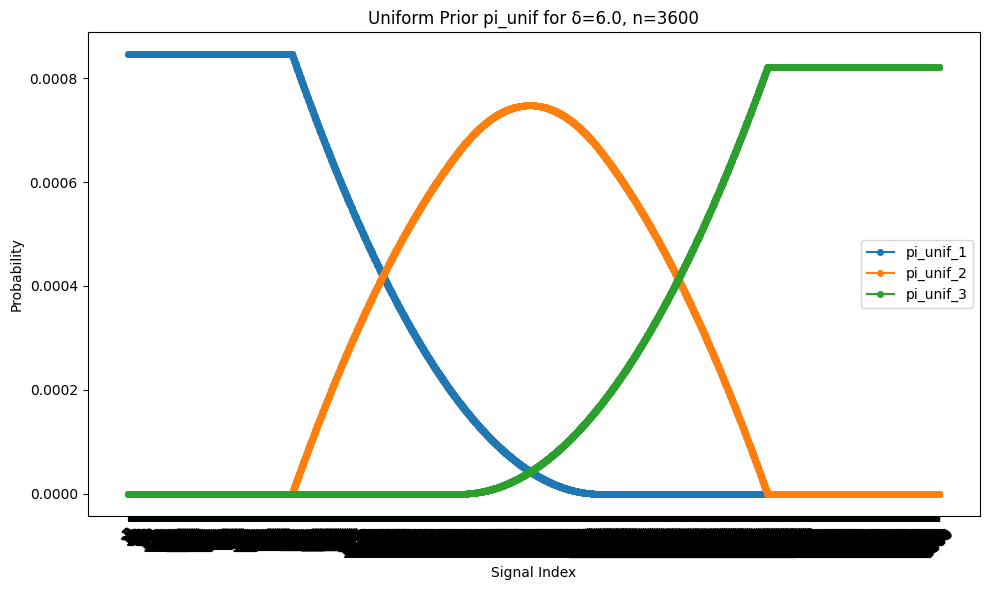

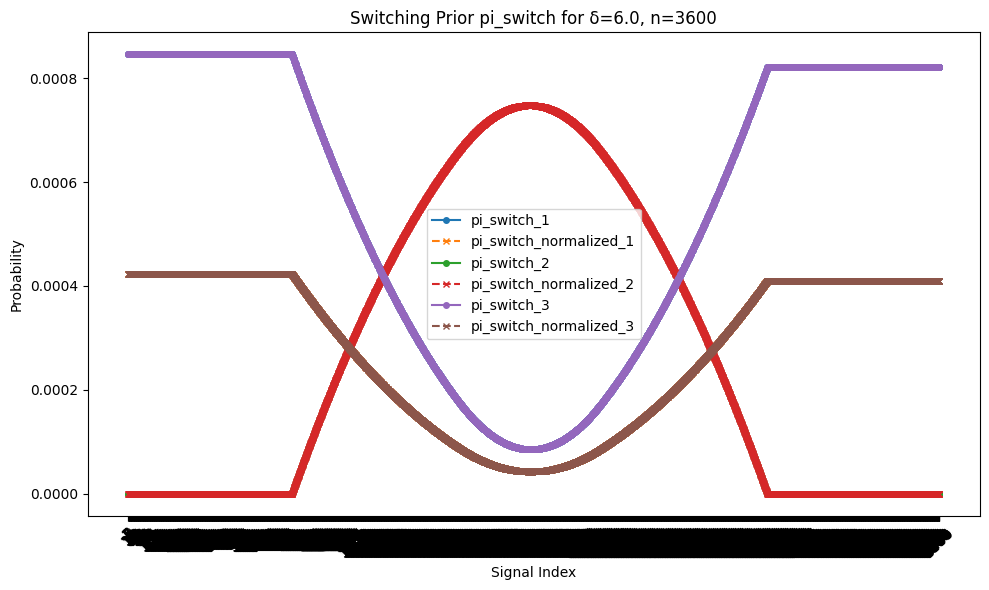

In [6]:
# Reset matplotlib settings to default
plt.rcdefaults()

# Plot pi_unif and pi_switch for the last delta
last_delta_idx = len(δ_list) - 1
last_delta = δ_list[last_delta_idx]
precomputed_data = delta_precomputed_data[last_delta_idx]
pi_unif = precomputed_data['pi_unif']
pi_switch = precomputed_data['pi_switch']
n = precomputed_data['n']
# Plot the uniform prior pi_unif
plt.figure(figsize=(10, 6))
for ℓ in range(L):
    plt.plot(pi_unif[ℓ, :], label=f'pi_unif_{ℓ+1}', marker='o', linestyle='-', markersize=4)
plt.xlabel('Signal Index')
plt.ylabel('Probability')
plt.title(f'Uniform Prior pi_unif for δ={last_delta:.1f}, n={n}')
plt.xticks(range(n), [f'{i+1}' for i in range(n)], rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

# Switching signal prior: add first and third rows of π
pi_switch = np.zeros((L, n))
pi_switch[0, :] = pi_unif[0, :] + pi_unif[2, :] # Combine first and third rows
pi_switch[1, :] = pi_unif[1, :] # Keep second row unchanged
pi_switch[2, :] = pi_unif[0, :] + pi_unif[2, :] # Repeat for third row

pi_switch_normalized = pi_switch / np.sum(pi_switch, axis=1, keepdims=True)  # Normalize the new π
# Plot the switching prior pi_switch
plt.figure(figsize=(10, 6))
for ℓ in range(L):
    plt.plot(pi_switch[ℓ, :], label=f'pi_switch_{ℓ+1}', marker='o', linestyle='-', markersize=4)
    plt.plot(pi_switch_normalized[ℓ, :], label=f'pi_switch_normalized_{ℓ+1}', marker='x', linestyle='--', markersize=4)
plt.xlabel('Signal Index')
plt.ylabel('Probability')
plt.title(f'Switching Prior pi_switch for δ={last_delta:.1f}, n={n}')
plt.xticks(range(n), [f'{i+1}' for i in range(n)], rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

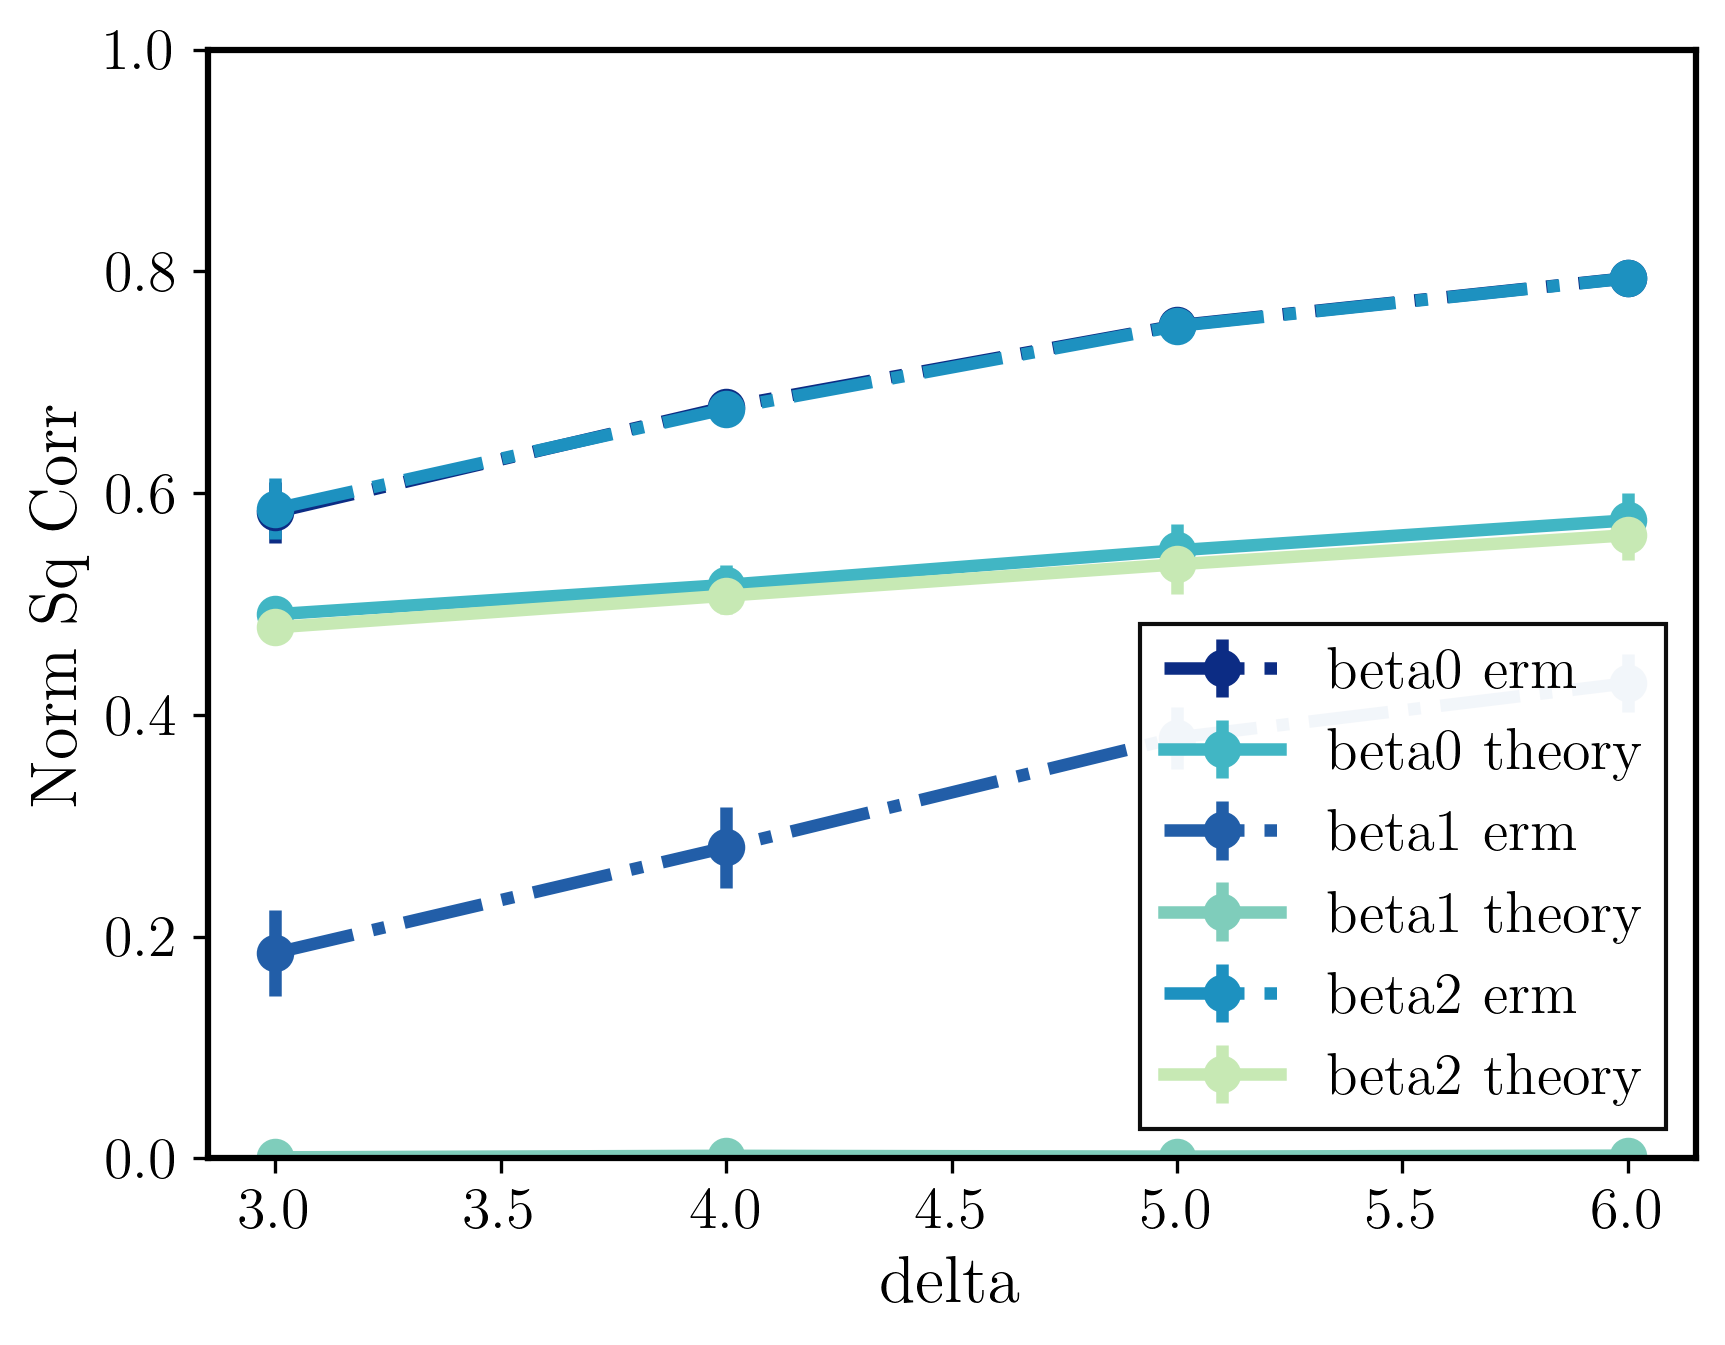

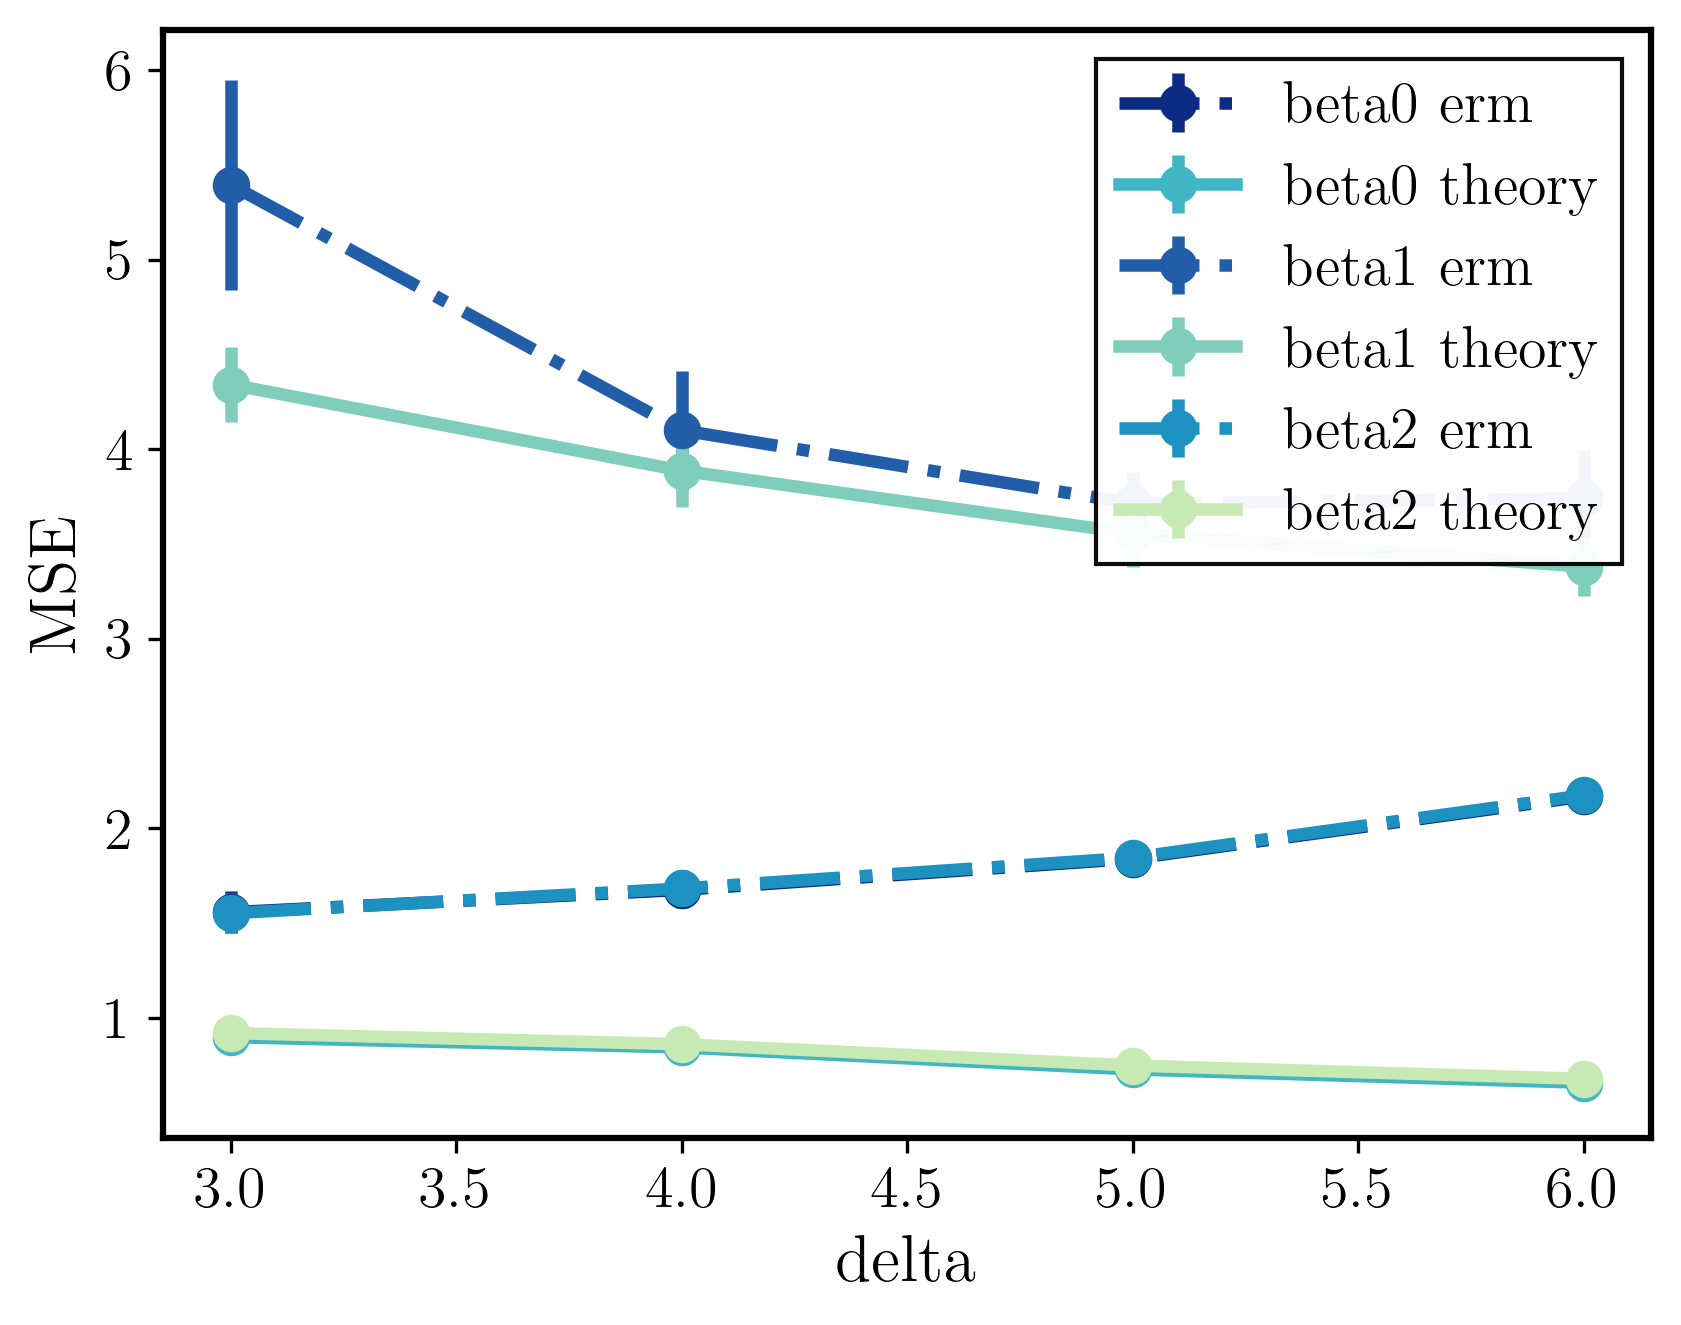

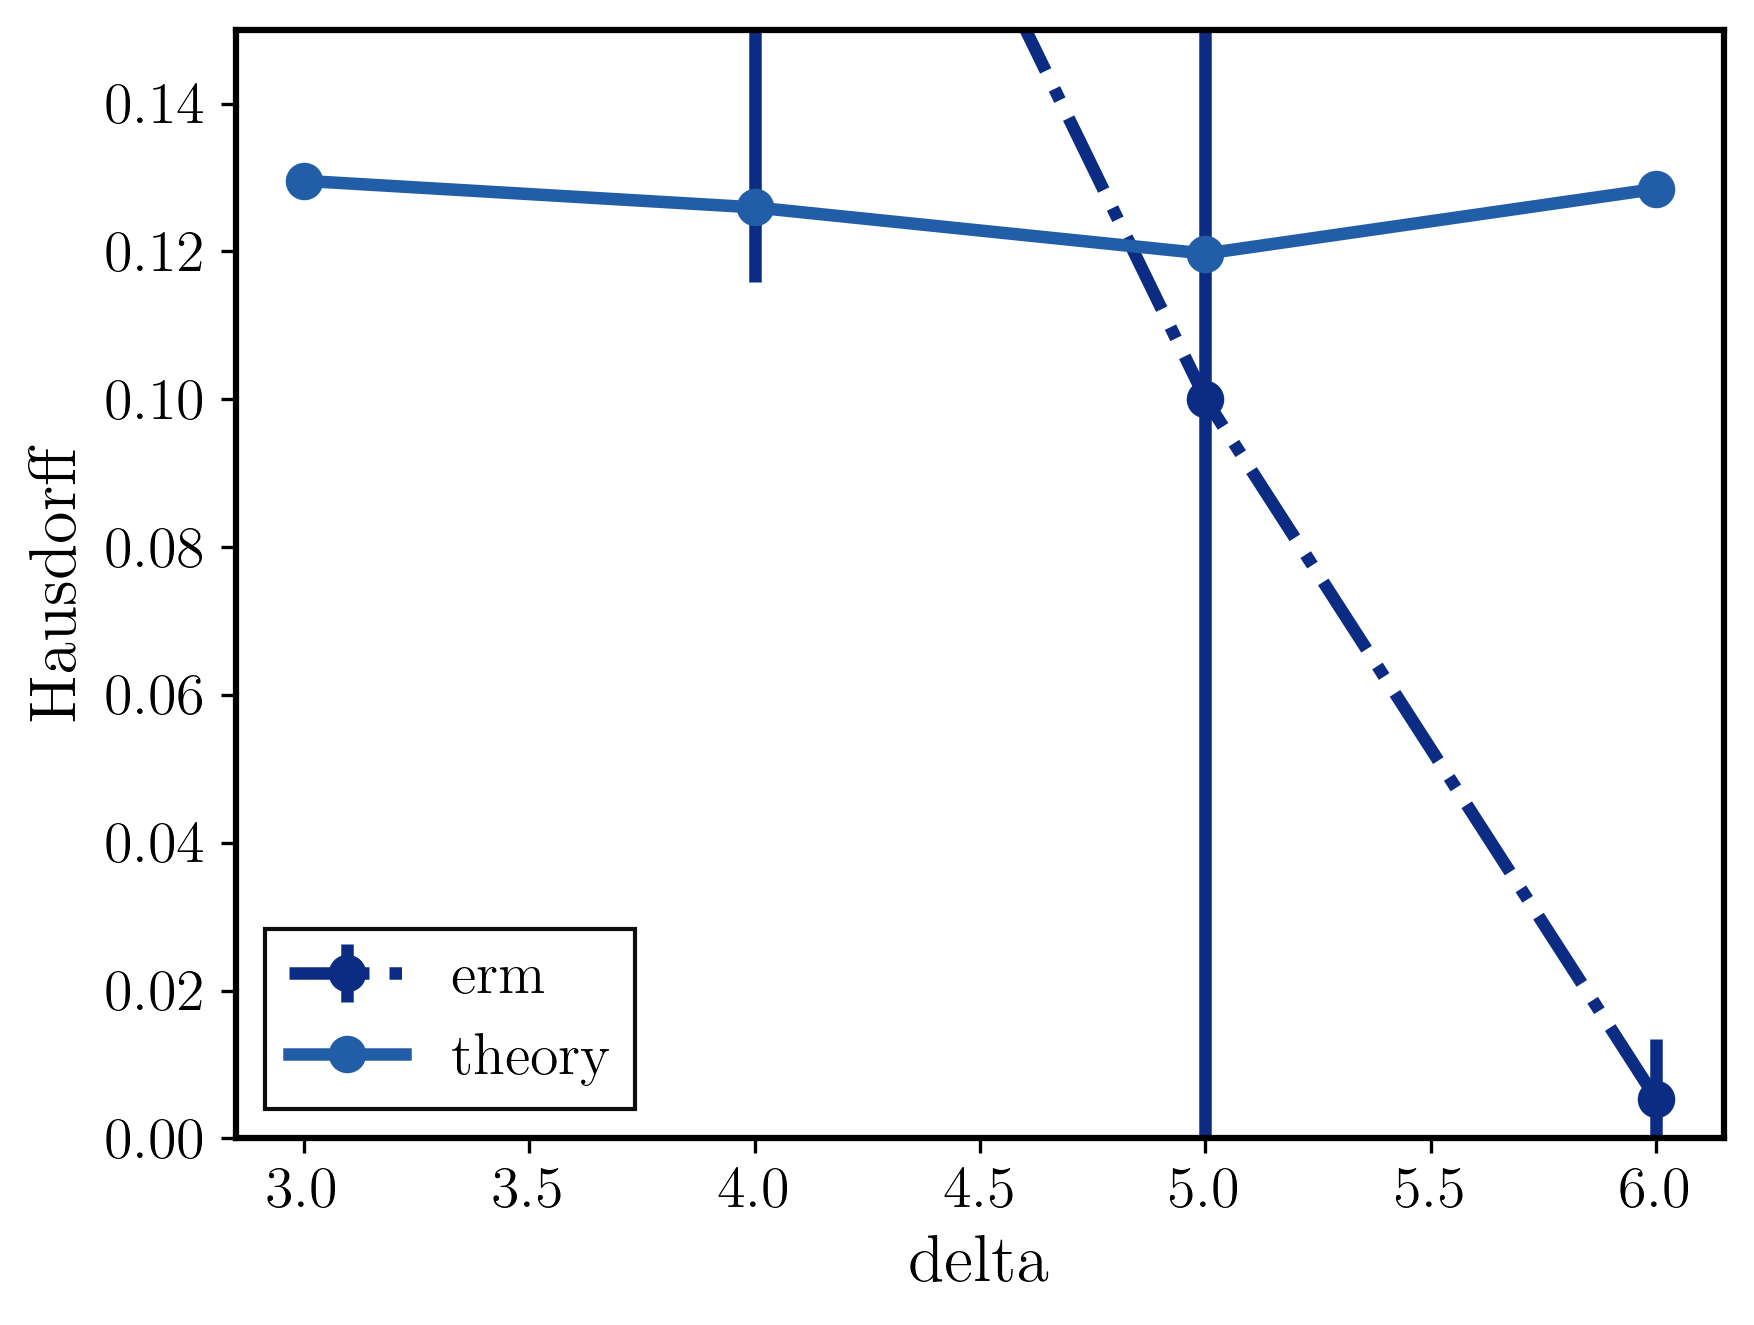

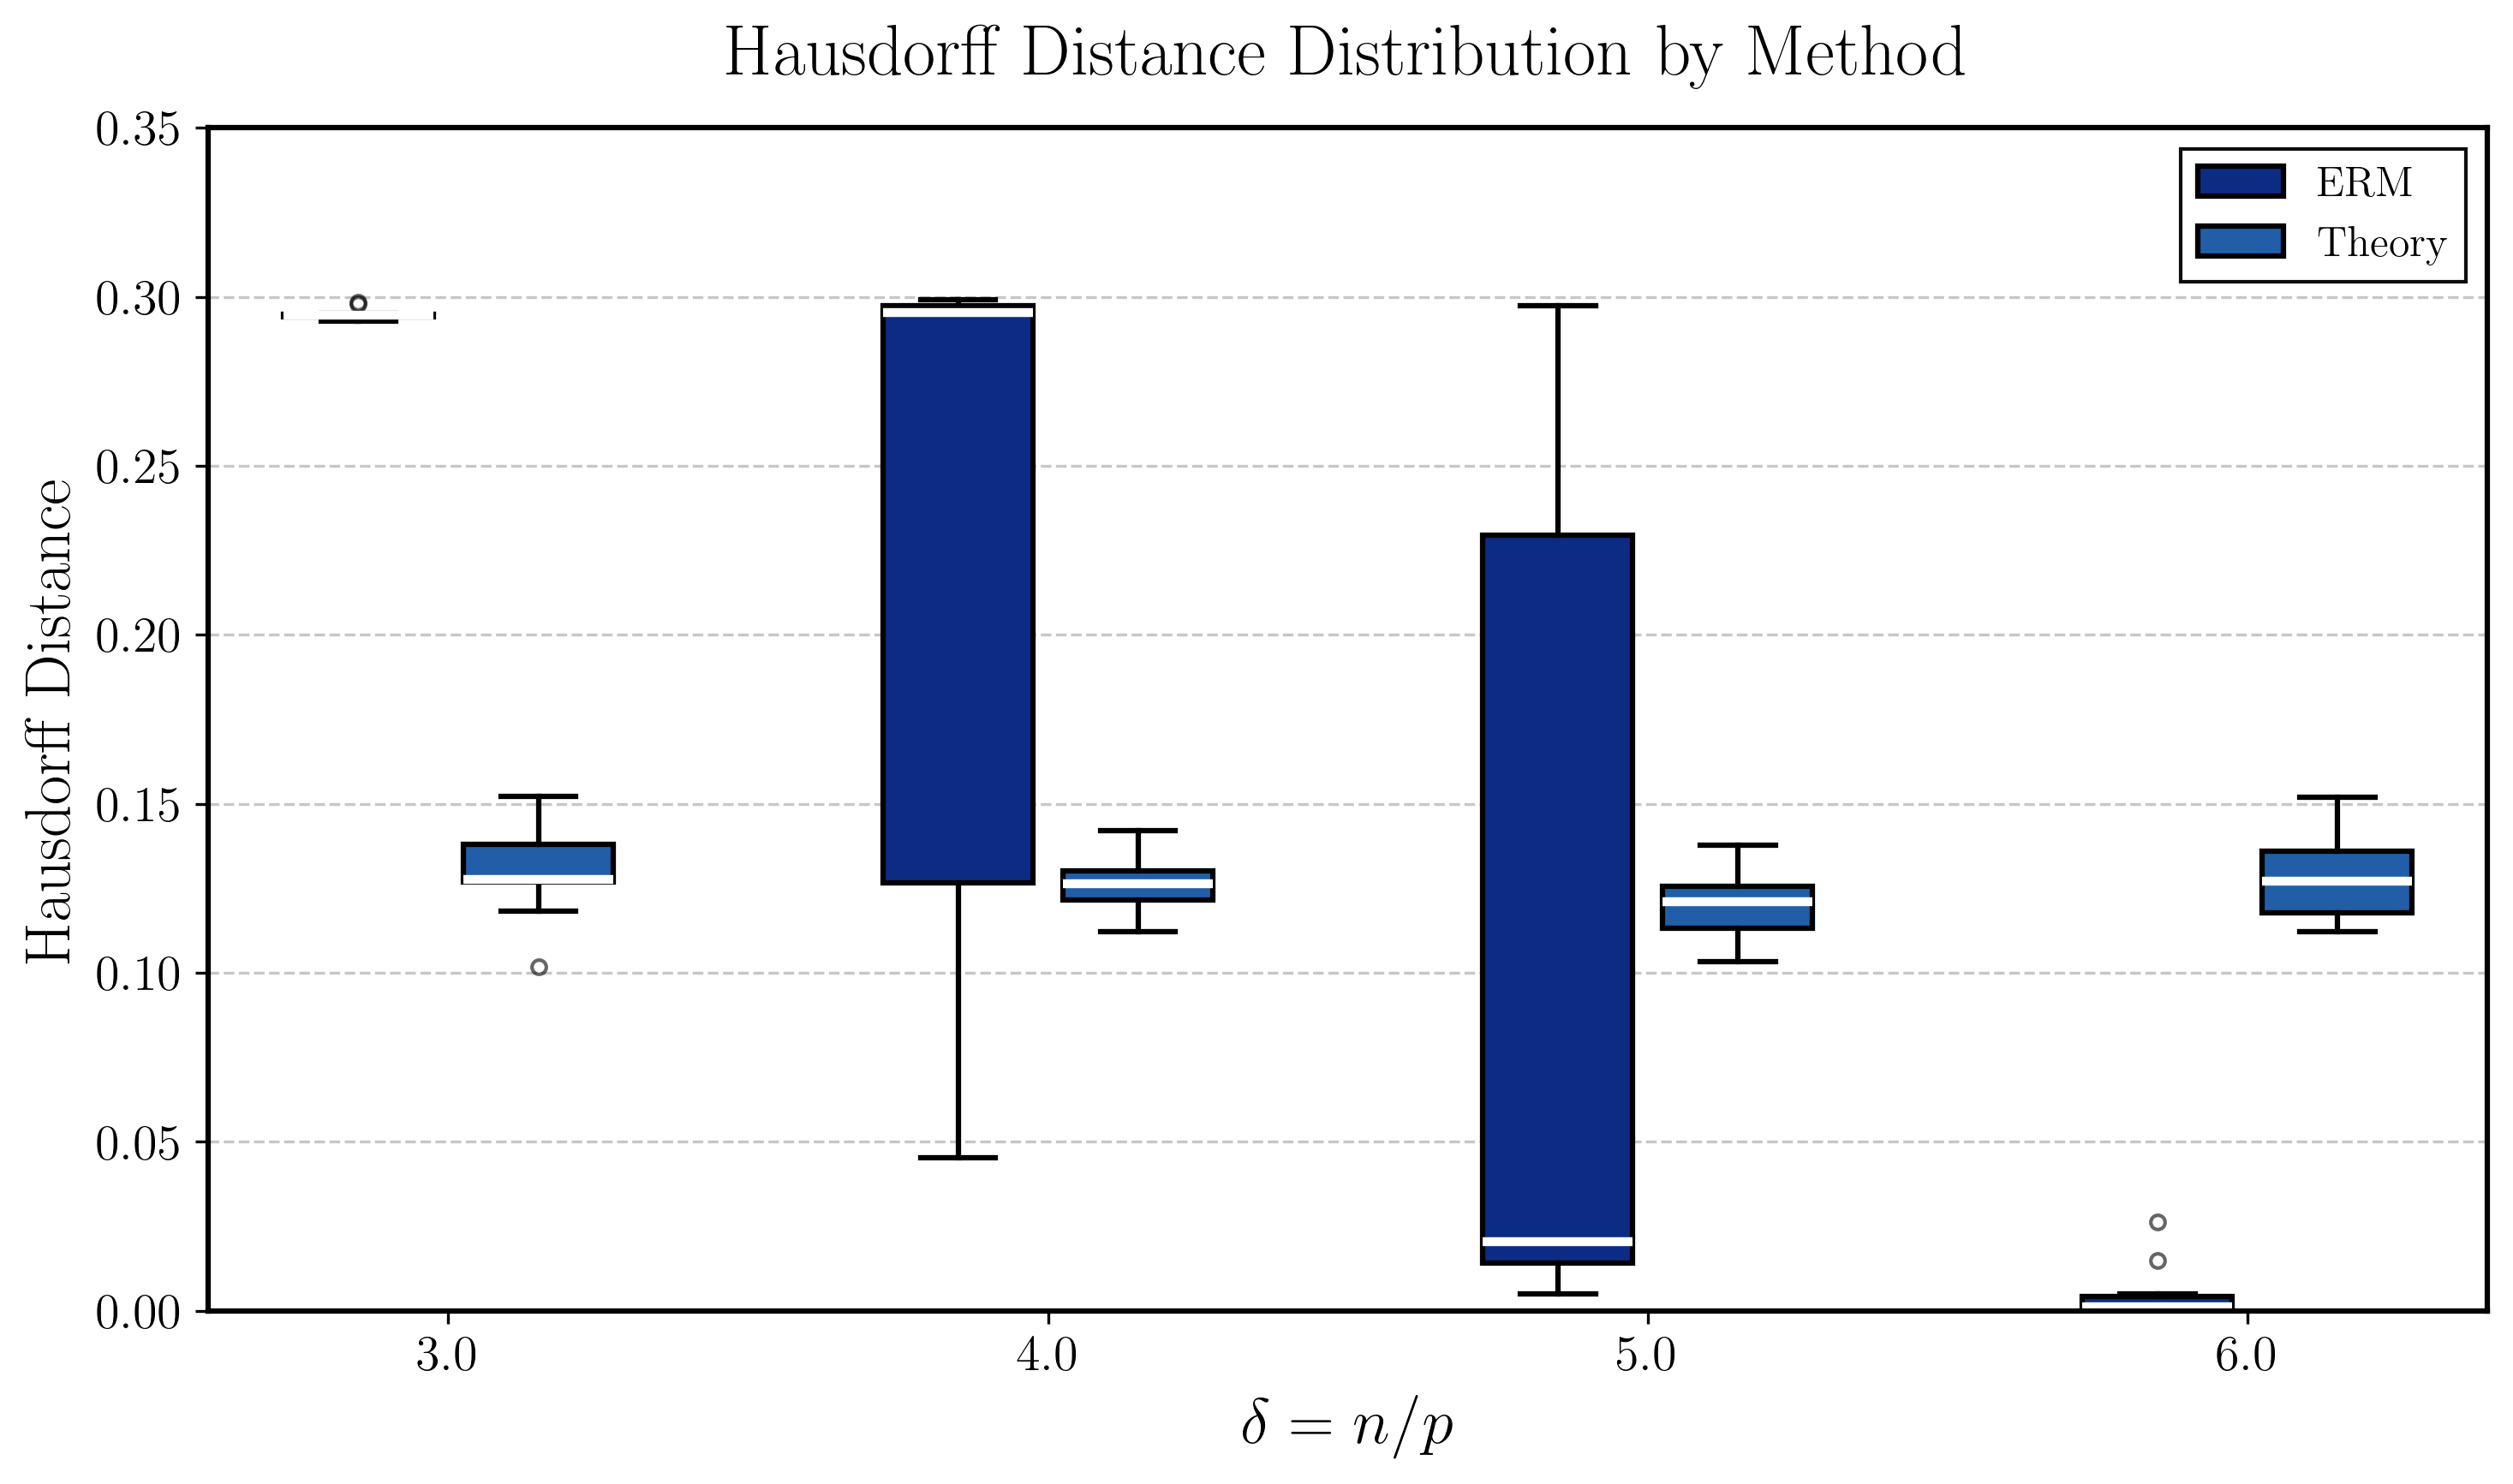

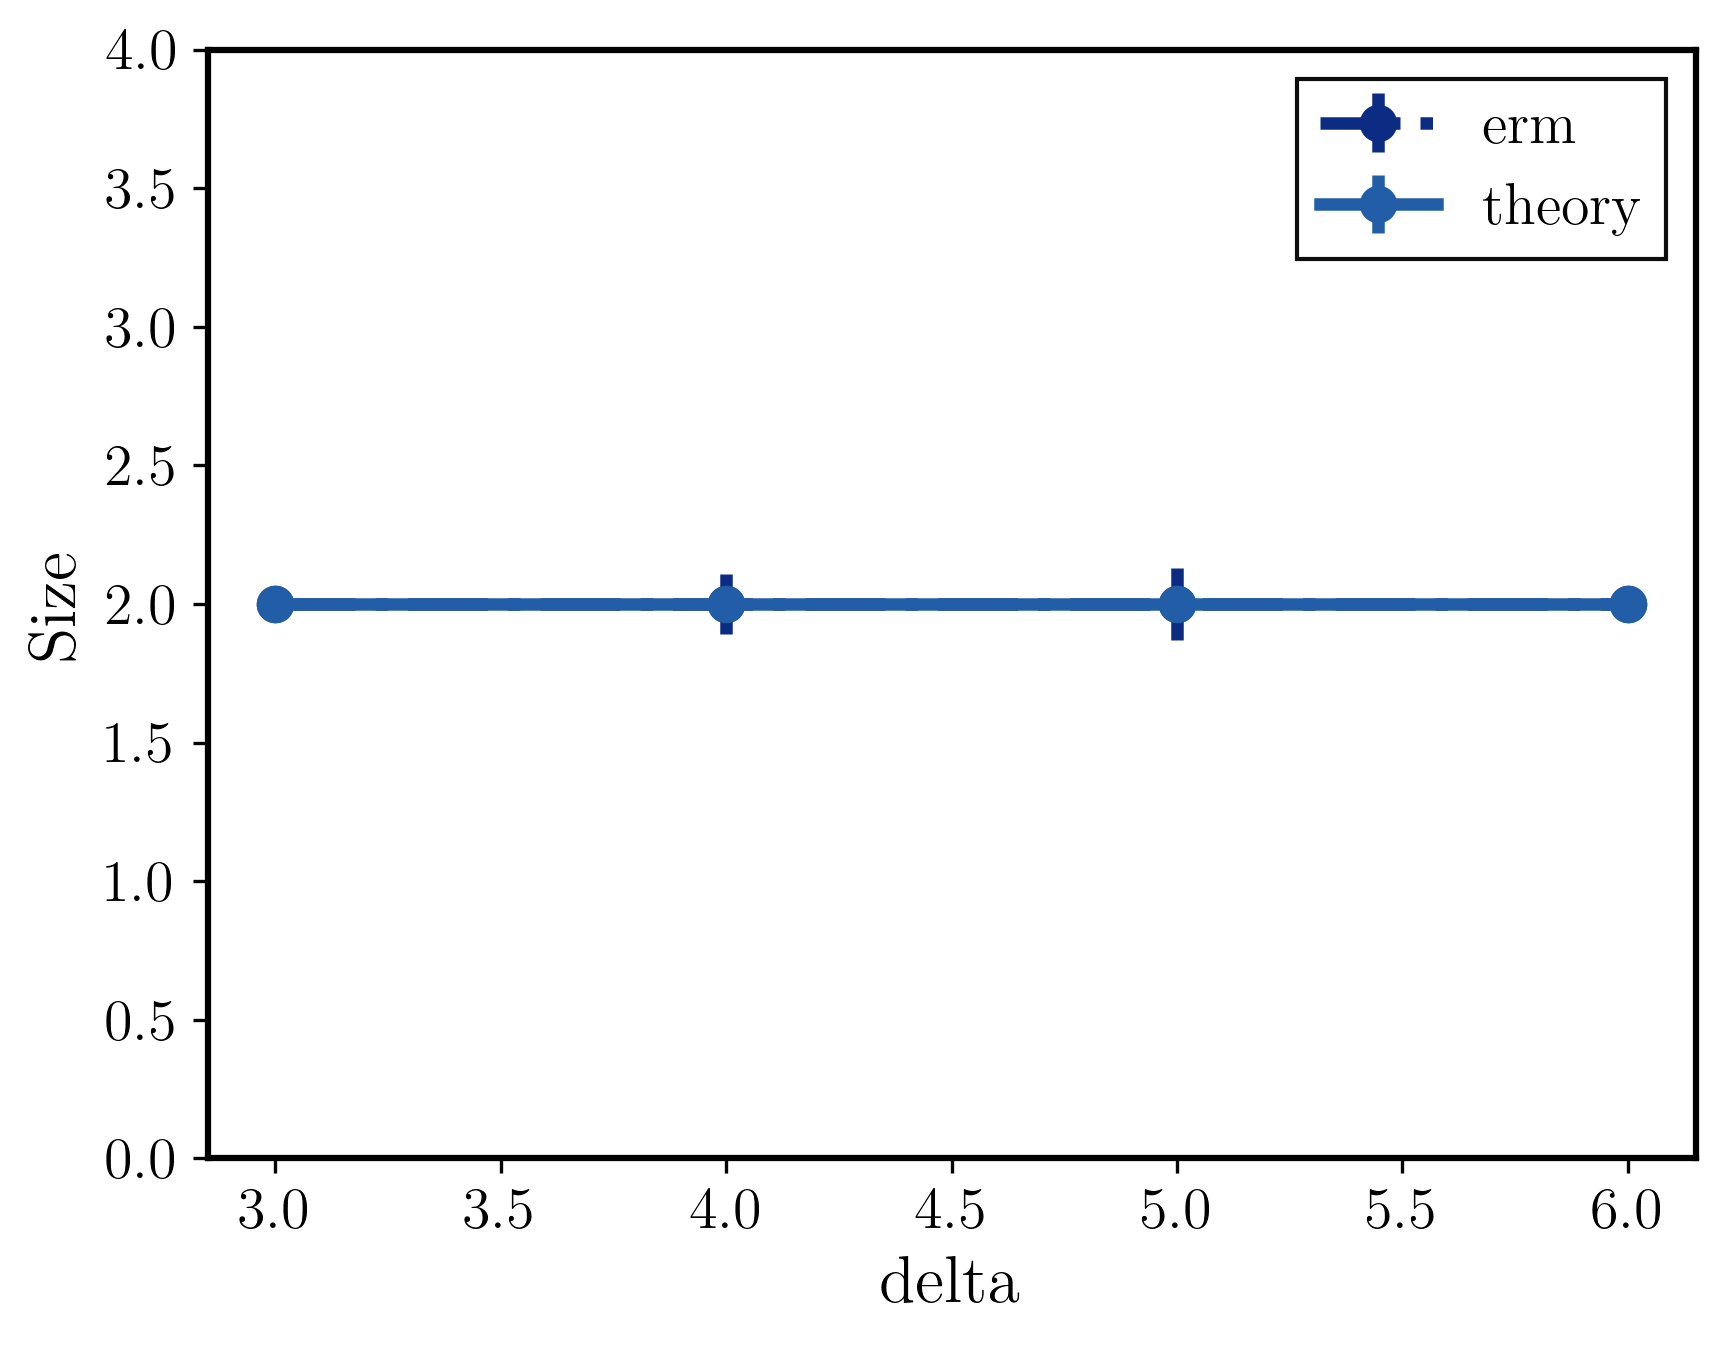

In [26]:
PAL = ['#0c2c84','#225ea8','#1d91c0','#41b6c4','#7fcdbb','#c7e9b4','#edf8b1','#ffffd9']
erm_corr_arr = results['corr_ERM-LS']
theory_corr_arr = results['corr_Theory-LS']
erm_MSE_arr = results['mse_ERM-LS']
theory_MSE_arr = results['mse_Theory-LS']
erm_haus_arr = results['haus_ERM-LS']
theory_haus_arr = results['haus_Theory-LS']
erm_size_arr = results['size_ERM-LS']
theory_size_arr = results['size_Theory-LS']
# Sqcorr plots
for ℓ_ in range(L):
    plt.errorbar(δ_list, np.mean(erm_corr_arr[:, :, ℓ_], axis = 1), yerr = np.std(erm_corr_arr[:, :, ℓ_], axis = 1), label="beta" + str(ℓ_) + " erm", marker="o", ls="-.", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, np.mean(theory_corr_arr[:, :, ℓ_], axis = 1), yerr = np.std(theory_corr_arr[:, :, ℓ_], axis = 1), label="beta" + str(ℓ_) + " theory", marker="o", ls="-", c=PAL[ℓ_ + L], alpha = 1.0)
plt.ylim((0, 1))
plt.xlabel("delta")
plt.ylabel("Norm Sq Corr")
plt.legend()
plt.show()

# MSE plots
for ℓ_ in range(L):
    plt.errorbar(δ_list, np.mean(erm_MSE_arr[:, :, ℓ_], axis = 1), yerr = np.std(erm_MSE_arr[:, :, ℓ_], axis = 1), label="beta" + str(ℓ_) + " erm", marker="o", ls="-.", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, np.mean(theory_MSE_arr[:, :, ℓ_], axis = 1), yerr = np.std(theory_MSE_arr[:, :, ℓ_], axis = 1), label="beta" + str(ℓ_) + " theory", marker="o", ls="-", c=PAL[ℓ_ + L], alpha = 1.0)
# plt.ylim((0, 2))
plt.xlabel("delta")
plt.ylabel("MSE")
plt.legend()
plt.show()

# Hausdorff plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
plt.errorbar(δ_list, np.mean(erm_haus_arr, axis = 1), yerr = np.std(erm_haus_arr, axis = 1), label="erm", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
plt.errorbar(δ_list, np.mean(theory_haus_arr, axis = 1), label="theory", marker="o", ls="-", c=PAL[1], alpha = 1.0)
plt.ylim((0, 0.15))
plt.xlabel("delta")
plt.ylabel("Hausdorff")
plt.legend()
# plt.savefig("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Display boxplots for Hausdorff
plt.figure(figsize=(10, 6))
box_data_erm = [erm_haus_arr[i, ~np.isnan(erm_haus_arr[i, :])] for i in range(len(δ_list))]
box_data_theory = [theory_haus_arr[i, ~np.isnan(theory_haus_arr[i, :])] for i in range(len(δ_list))]
positions_erm = np.array(range(len(δ_list))) * 2.0 - 0.3
positions_theory = np.array(range(len(δ_list))) * 2 + 0.3
bp_erm = plt.boxplot(box_data_erm, positions=positions_erm, widths=0.5,
                     patch_artist=True, boxprops=dict(facecolor=PAL[0], edgecolor='black', linewidth=1.5),
                     medianprops=dict(color='white', linewidth=2.5),
                     whiskerprops=dict(linewidth=1.5),
                     capprops=dict(linewidth=1.5),
                     flierprops=dict(marker='o', markersize=4, alpha=0.6))
bp_theory = plt.boxplot(box_data_theory, positions=positions_theory, widths=0.5,
                        patch_artist=True, boxprops=dict(facecolor=PAL[1], edgecolor='black', linewidth=1.5),
                        medianprops=dict(color='white', linewidth=2.5),
                        whiskerprops=dict(linewidth=1.5),
                        capprops=dict(linewidth=1.5),
                        flierprops=dict(marker='o', markersize=4, alpha=0.6))
plt.xticks(np.array(range(len(δ_list))) * 2, [f'{d:.1f}' for d in δ_list])
plt.xlabel(r'$\delta = n/p$', fontsize=18)
plt.ylabel('Hausdorff Distance', fontsize=18)
plt.title('Hausdorff Distance Distribution by Method', fontsize=20, pad=15)
plt.legend([bp_erm["boxes"][0], bp_theory["boxes"][0]], ['ERM', 'Theory'], loc='upper right', fontsize=12, frameon=True, edgecolor='black', framealpha=0.95)
plt.ylim((0, 0.35))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Hausdorff plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
plt.errorbar(δ_list, np.mean(erm_size_arr, axis = 1), yerr = np.std(erm_haus_arr, axis = 1), label="erm", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
plt.errorbar(δ_list, np.mean(theory_size_arr, axis = 1), yerr = np.std(theory_haus_arr, axis = 1), label="theory", marker="o", ls="-", c=PAL[1], alpha = 1.0)
plt.ylim((0, L + 1))
plt.xlabel("delta")
plt.ylabel("Size")
plt.legend()
# plt.savefig("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Runtime plots
# δ_arr = np.array([δ_list for _ in range(num_trials)])
# plt.errorbar(δ_list, np.mean(ERM_runtime, axis = 1), yerr = np.std(ERM_runtime, axis = 1), label="ERM", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
# plt.xlabel("δ")
# plt.ylabel("Runtime")
# plt.legend()
# plt.show()

In [25]:
results['chgpts_ERM-LS']

[]

  Best 5 improvements: [(581, Array(-393.8318081, dtype=float64), Array(1847.83535024, dtype=float64)), (585, Array(-394.08082515, dtype=float64), Array(1848.0843673, dtype=float64)), (583, Array(-394.20128794, dtype=float64), Array(1848.20483008, dtype=float64)), (584, Array(-394.40258396, dtype=float64), Array(1848.4061261, dtype=float64)), (586, Array(-394.66201104, dtype=float64), Array(1848.66555318, dtype=float64))]

Applying local refinement...
ERM Switch changept locations: [ 581 1796]
Saving chgpts for method: ERM-LS
current_chgpt_loc: [ 581 1796]
  Tested 1799 valid positions
  Best 5 improvements: [(460, Array(294.2361979, dtype=float64), Array(759.63242509, dtype=float64)), (459, Array(294.04243473, dtype=float64), Array(759.82618826, dtype=float64)), (457, Array(294.00855584, dtype=float64), Array(759.86006715, dtype=float64)), (458, Array(293.97283764, dtype=float64), Array(759.89578535, dtype=float64)), (476, Array(293.93494095, dtype=float64), Array(759.93368204, dtype=

23:10:33 - Creating publication-ready plots...
Using palette: ['#EE7733', '#0077BB'] (Paul Tol Vibrant assigned to methods)
23:10:33 - Generating plots...


1. Asymmetric error bars (publication style)...


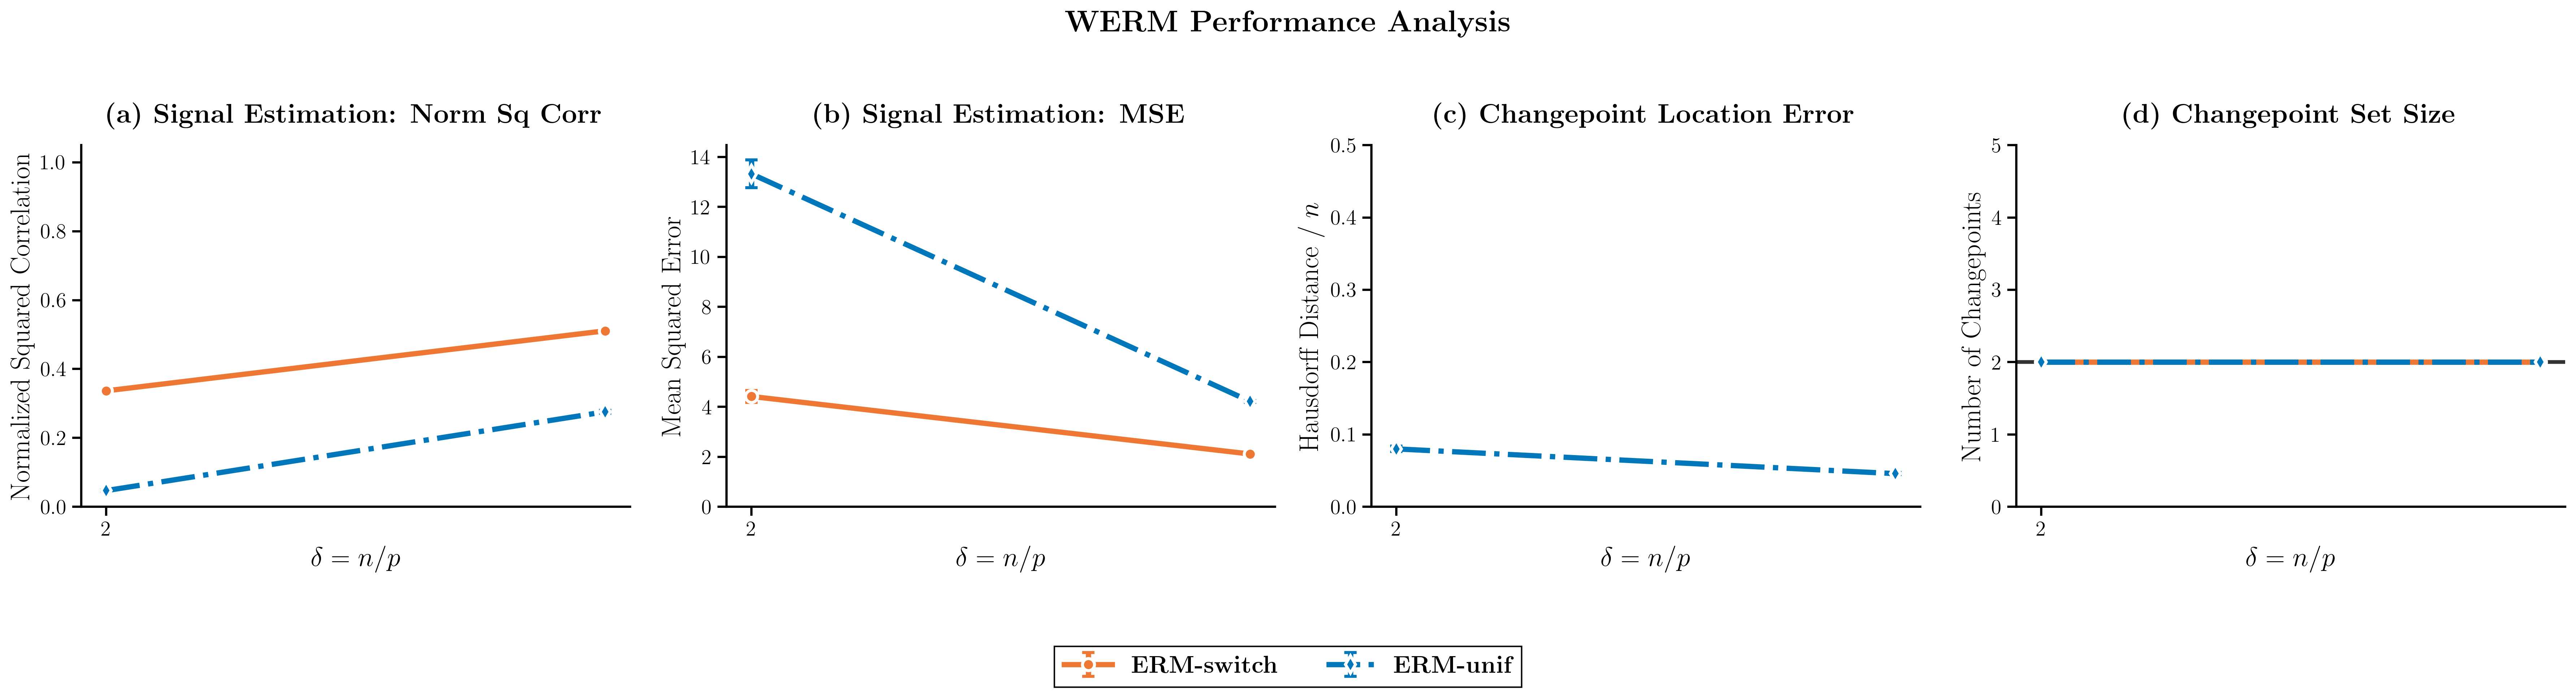

2. Confidence bands (publication style)...


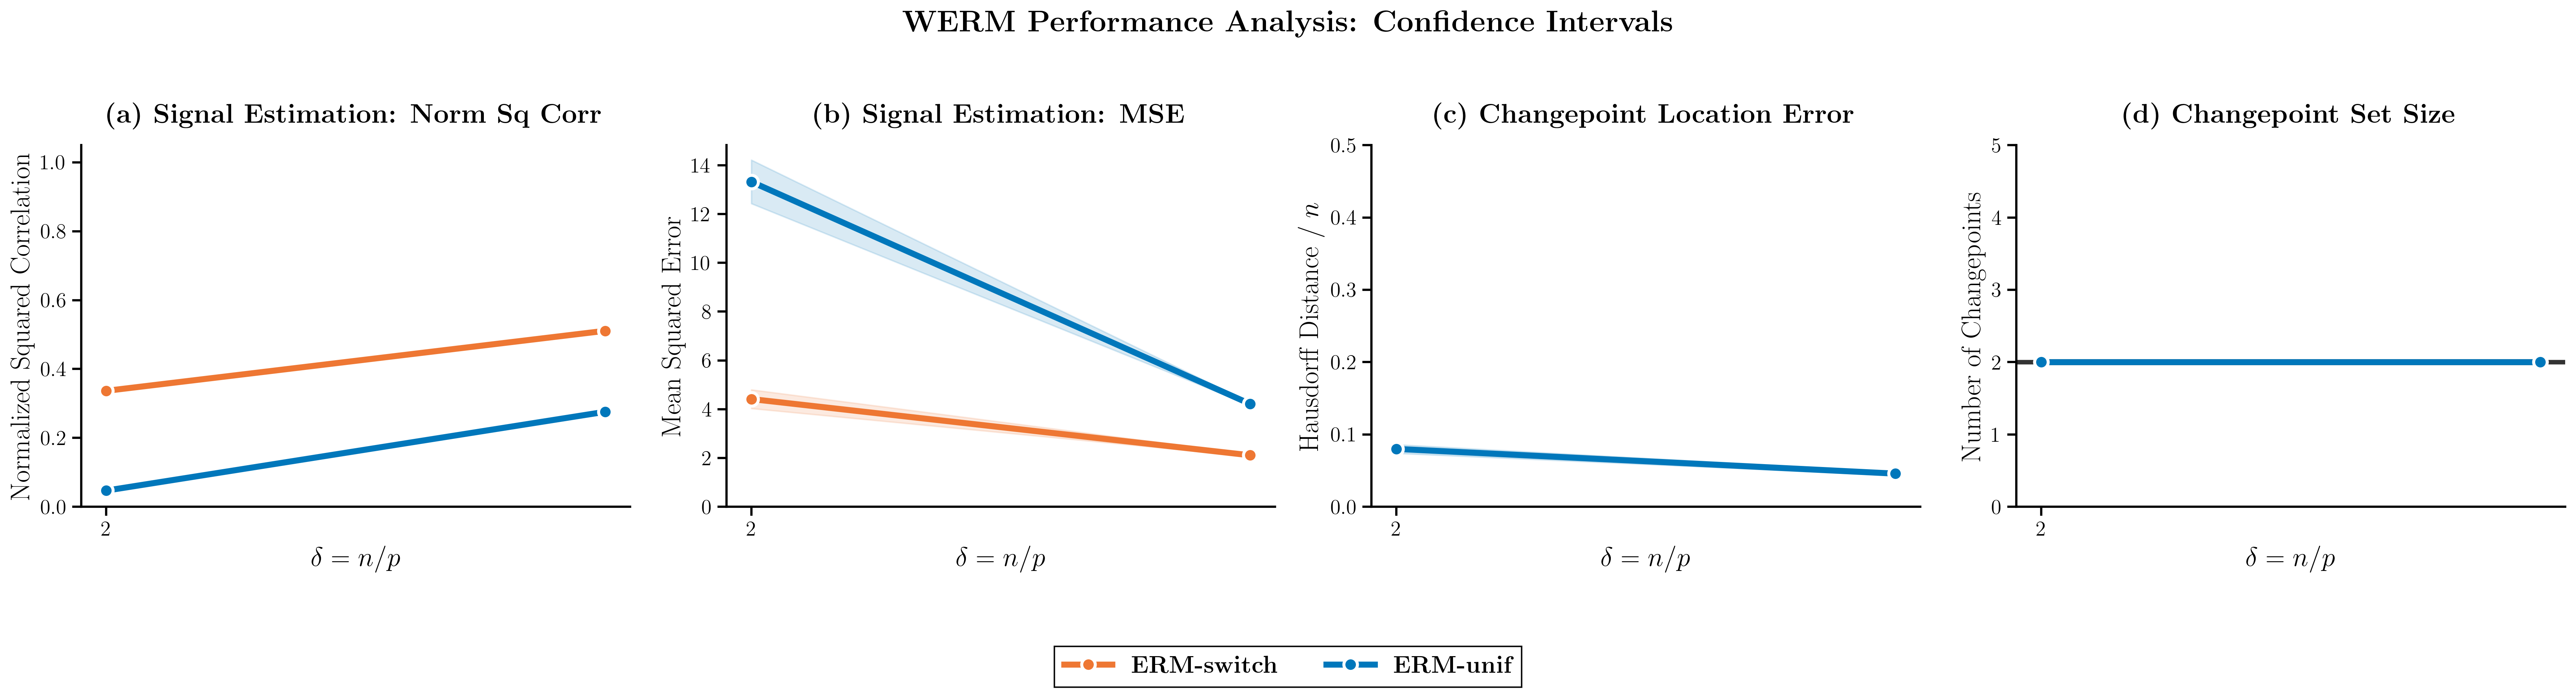

3. Box plots (publication style)...


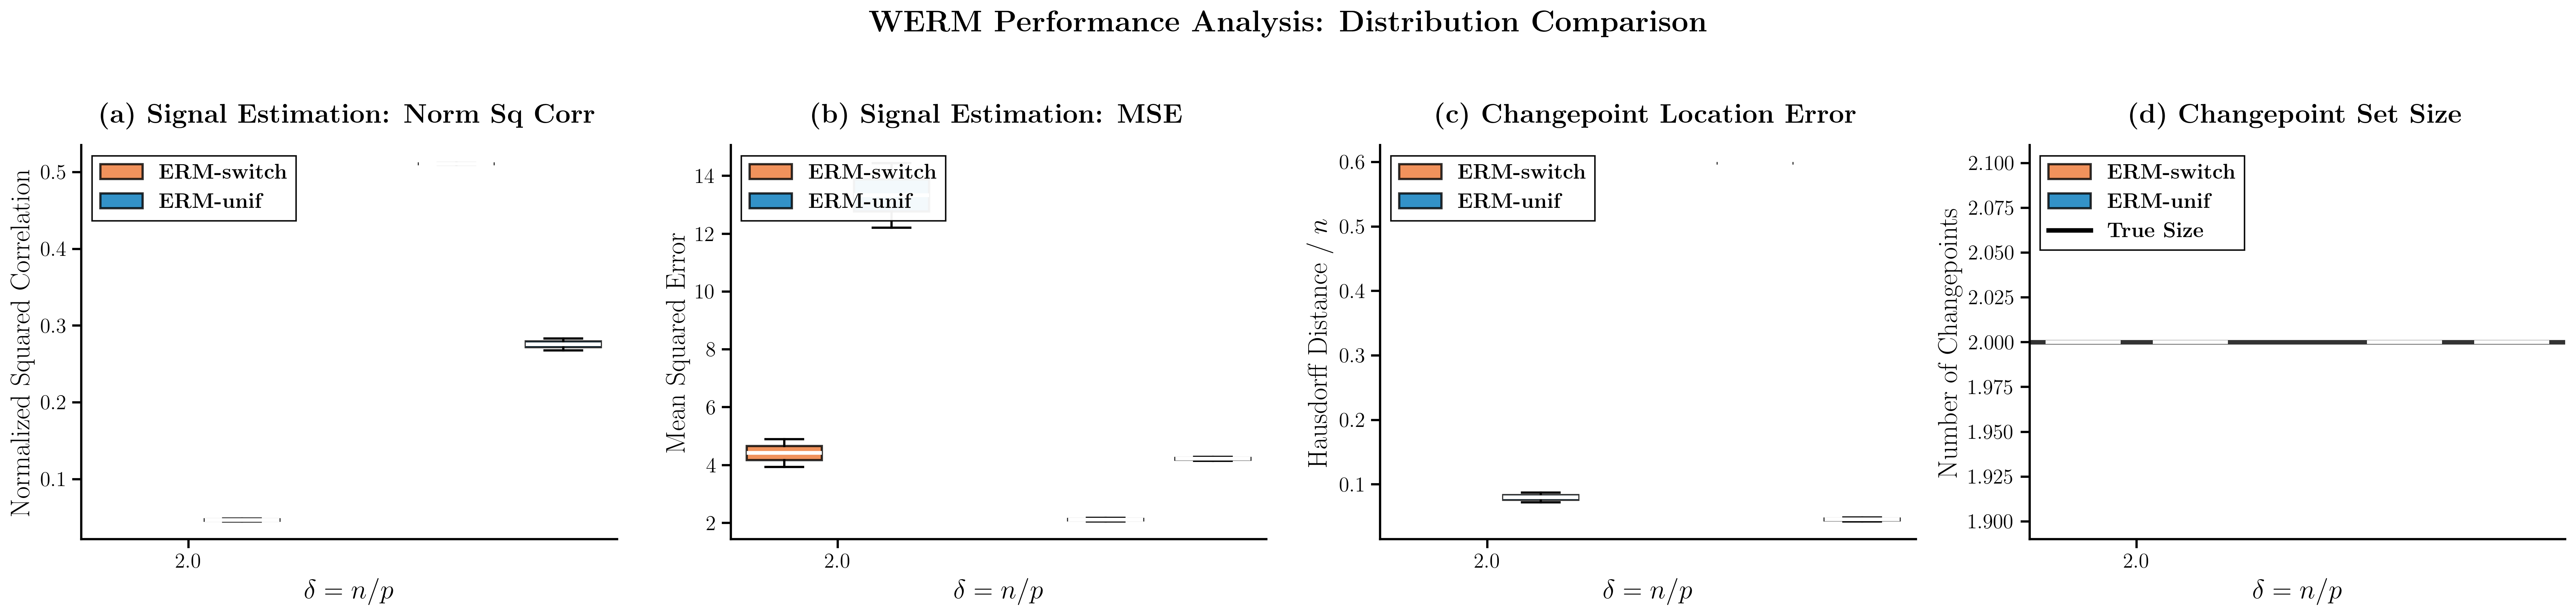

4. Enhanced changepoint histograms (publication style)...


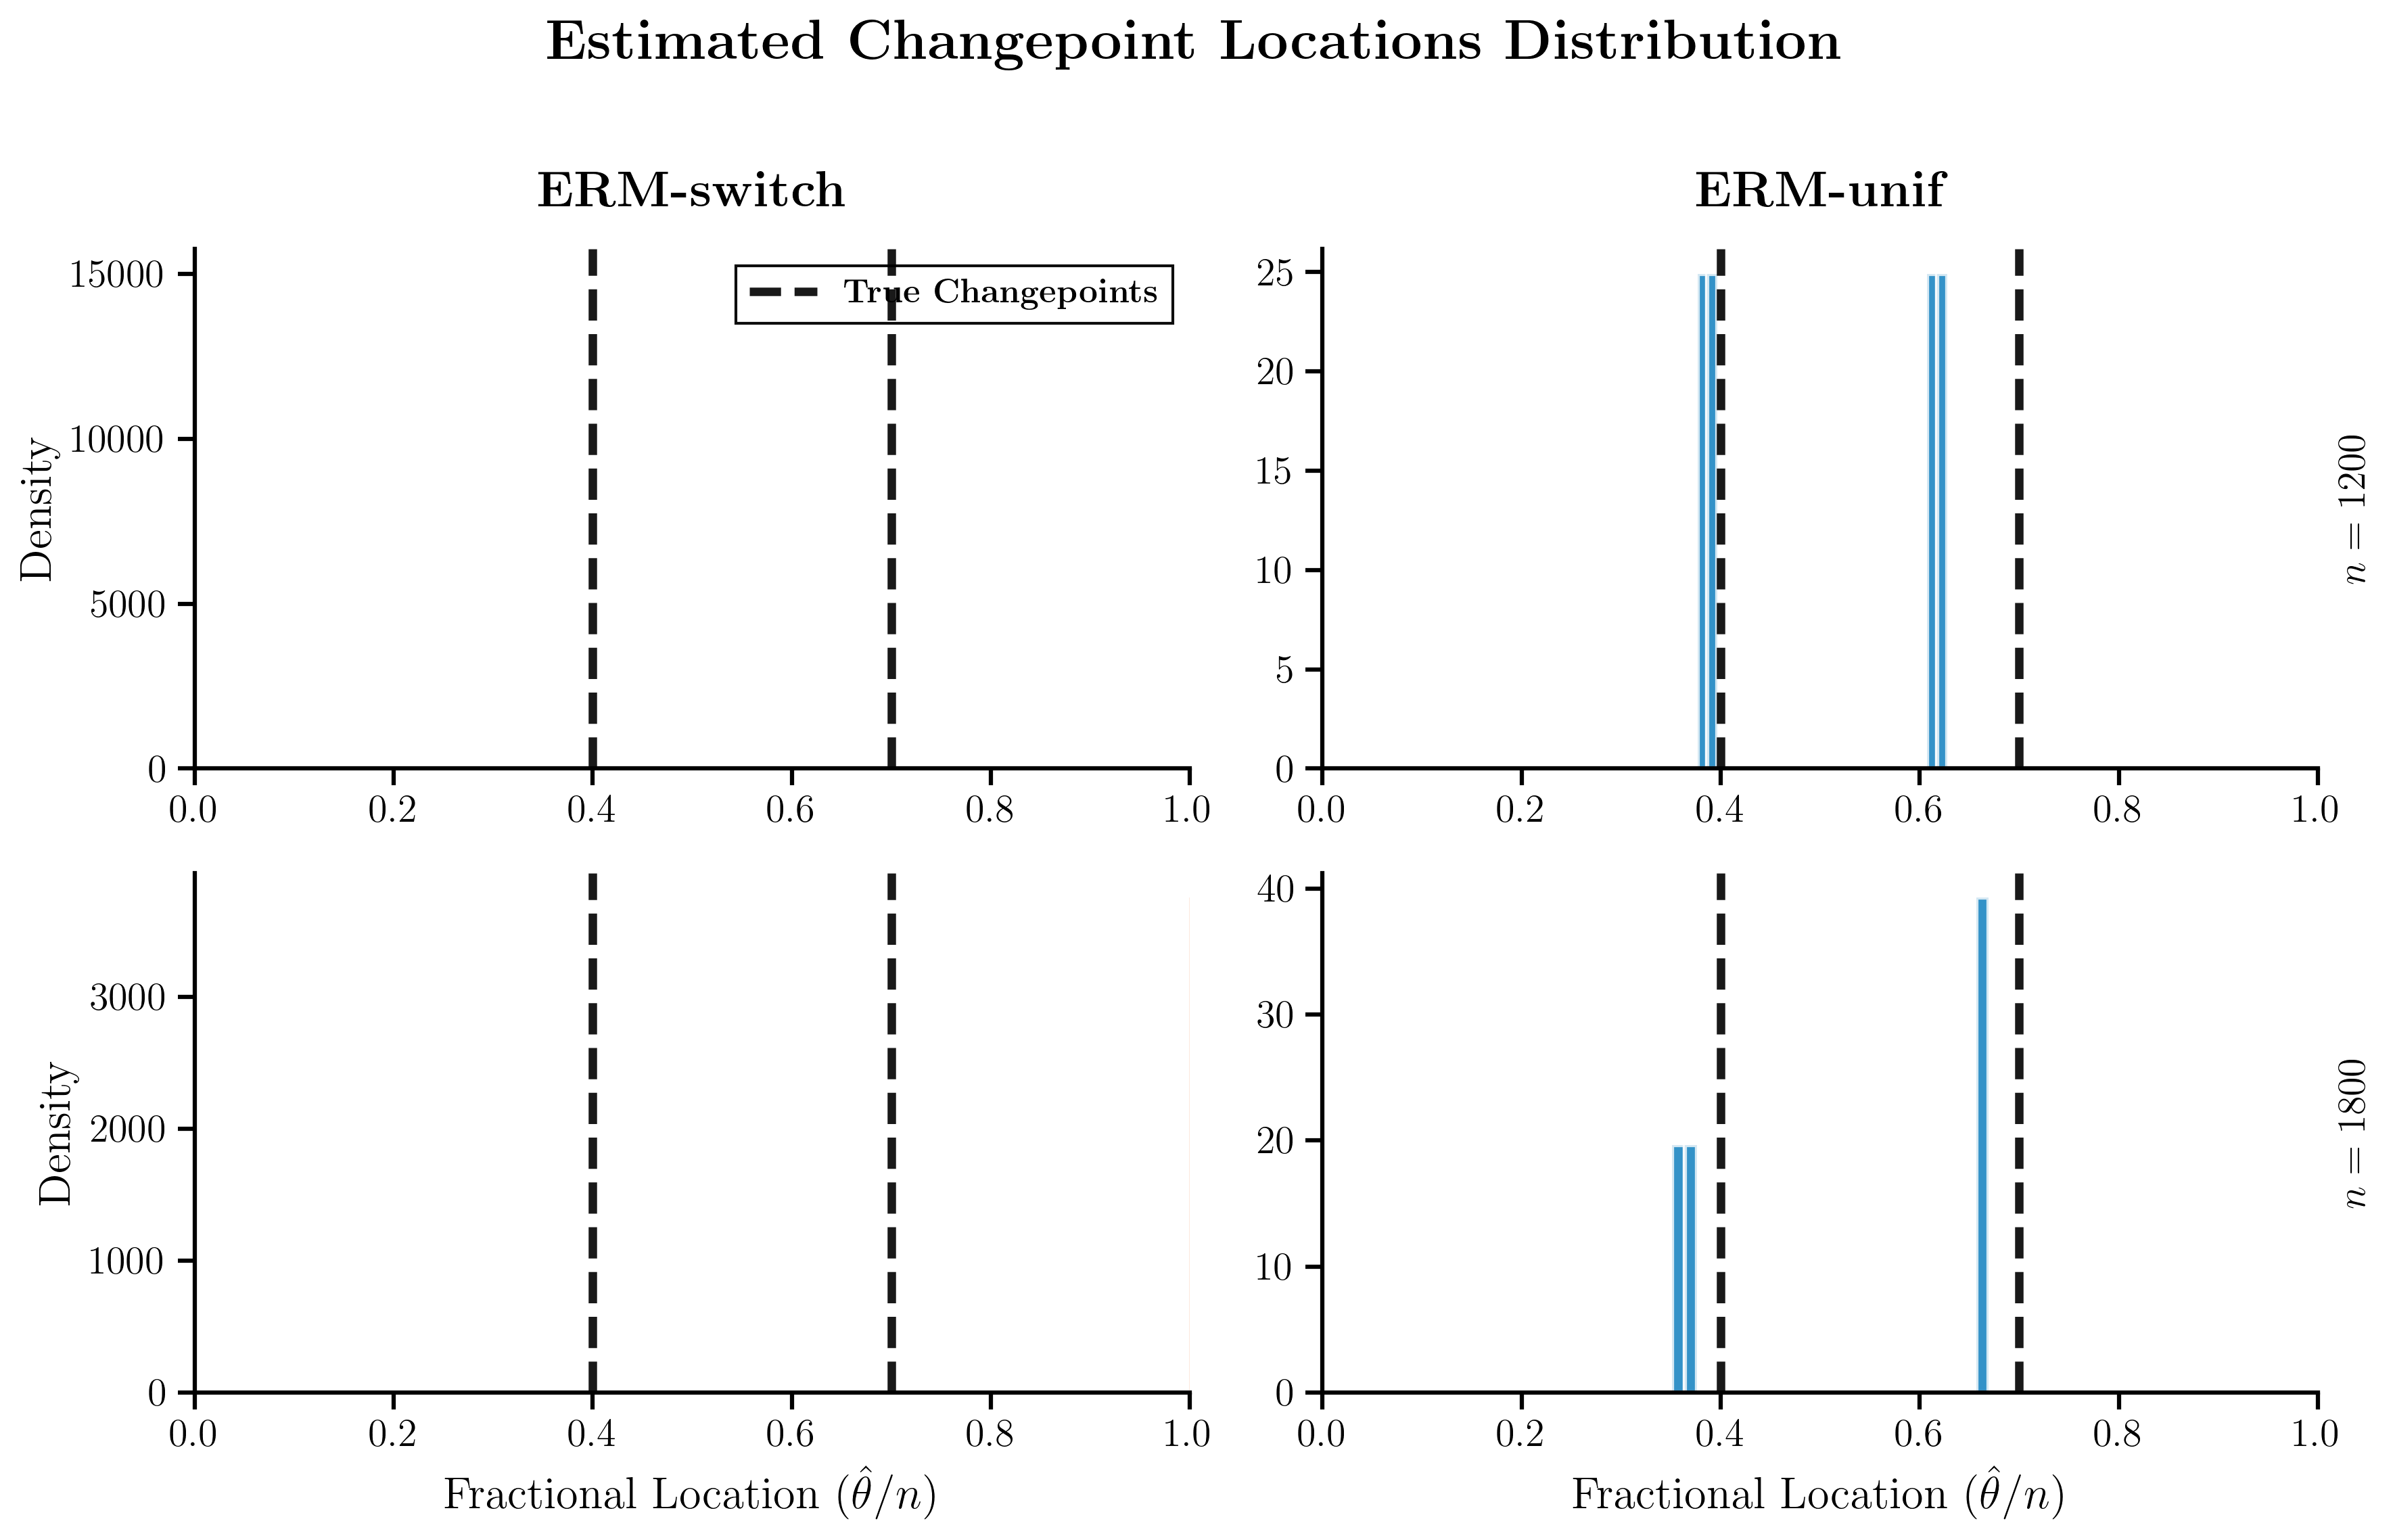

23:10:35 - Publication-ready plotting completed in 2.03 seconds


In [45]:
# --- Publication-Ready Enhanced Plotting Results ---
plt.rcParams.update({
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': False,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 3.0,
    'lines.markersize': 8,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

main_logger.info("Creating publication-ready plots...")
plotting_start_time = time.time()

# Paul Tol "Vibrant" - optimal balance of aesthetics and accessibility
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB', '#FF8800', '#DDAA33', '#BBCC33']
PAL = TOL_VIBRANT

# Ensure colors are assigned from the palette in order
for i, method_obj in enumerate(methods_to_evaluate):
    method_obj['color'] = PAL[i % len(PAL)] # Cycle through colors if more methods than palette entries

print(f"Using palette: {[m['color'] for m in methods_to_evaluate]} (Paul Tol Vibrant assigned to methods)")

def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=1)
    p25 = np.nanpercentile(data, 25, axis=1)
    p75 = np.nanpercentile(data, 75, axis=1)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

# --- Publication-Ready Asymmetric Error Bars Plots ---
def plot_with_asymmetric_errors_publication():
    fig, axs = plt.subplots(1, 4, figsize=(24, 6)) # Increased columns for all 4 metrics
    fig.suptitle(r'\textbf{WERM Performance Analysis}', fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    # Metrics to plot
    metrics = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}', (0, 1.05)),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}', None),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}', (0, 0.5)),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}', (0, L + 2))
    ]

    for ax_idx, (metric_key, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]
        for i, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            data = results[f'{metric_key}_{method_name}']
            if metric_key in ['corr', 'mse']:
                # For correlation and MSE, average over the L signals first
                data = np.nanmean(data, axis=2) # Average across L signals
            if np.all(np.isnan(data)):
                main_logger.warning(f"No successful trials for {method_name} ({metric_key}). Skipping plot for this metric.")
                continue
            means = np.nanmean(data, axis=1)
            errors = get_asymmetric_errors(data)
            ax.errorbar(δ_list, means, yerr=errors,
                        label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                        color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                        linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
        
        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
        
        if ylim:
            ax.set_ylim(ylim)
        elif metric_key in ['haus']:
            ax.set_ylim(bottom=0, top=0.2)
        else: # For MSE and Runtime, ensure y-axis starts at 0
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods_to_evaluate) + (1 if 'size' in [m[0] for m in metrics] else 0),
               fontsize=16, frameon=True, edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Publication-Ready Confidence Bands Plots ---
def plot_with_confidence_bands_publication():
    fig, axs = plt.subplots(1, 4, figsize=(24, 6))
    fig.suptitle(r'\textbf{WERM Performance Analysis: Confidence Intervals}',
                 fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}', (0, 1.05)),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}', None),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}', (0, 0.5)),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}', (0, L + 2))
    ]

    for ax_idx, (metric_key, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]
        for method_idx, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            data = results[f'{metric_key}_{method_name}']
            if metric_key in ['corr', 'mse']:
                data = np.nanmean(data, axis=2)
            if np.all(np.isnan(data)):
                main_logger.warning(f"No successful trials for {method_name} ({metric_key}). Skipping plot for this metric.")
                continue
            means = np.nanmean(data, axis=1)
            p10 = np.nanpercentile(data, 10, axis=1)
            p90 = np.nanpercentile(data, 90, axis=1)
            p10 = np.minimum(p10, means) # Ensure band doesn't go above mean for lower bound
            p90 = np.maximum(p90, means) # Ensure band doesn't go below mean for upper bound

            ax.fill_between(δ_list, p10, p90, color=plot_colors[method_idx],
                            alpha=0.15, zorder=1)
            ax.plot(δ_list, means, color=plot_colors[method_idx], linewidth=4,
                    marker='o', markersize=9, label=plot_labels[method_idx], zorder=3,
                    markeredgewidth=2, markeredgecolor='white')

        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}', zorder=2)
        if ylim:
            ax.set_ylim(ylim)
        elif metric_key in ['mse', 'runtime']:
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods_to_evaluate) + (1 if 'size' in [m[0] for m in metrics] else 0),
               fontsize=16, frameon=True, edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Publication-Ready Box Plots ---
def plot_with_boxplots_publication():
    fig, axs = plt.subplots(1, 4, figsize=(24, 6)) # Adjusted for 4 metrics
    fig.suptitle(r'\textbf{WERM Performance Analysis: Distribution Comparison}',
                 fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}'),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}'),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}'),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}')
    ]

    for ax_idx, (metric_key, ylabel, title) in enumerate(metrics):
        ax = axs[ax_idx]
        spacing = len(methods_to_evaluate) + 1
        for delta_idx, delta in enumerate(δ_list):
            box_data = []
            box_positions = []
            box_colors = []
            for method_idx, method_obj in enumerate(methods_to_evaluate):
                method_name = method_obj['name']
                data = results[f'{metric_key}_{method_name}'][delta_idx, :]
                if metric_key in ['corr', 'mse']:
                    # Take nanmean across L signals for corr/mse before plotting
                    data_flattened = np.nanmean(data, axis=1) # Results in a 1D array per trial
                else:
                    data_flattened = data

                valid_data = data_flattened[~np.isnan(data_flattened)]
                if len(valid_data) > 0:
                    box_data.append(valid_data)
                    box_positions.append(delta_idx * spacing + method_idx)
                    box_colors.append(plot_colors[method_idx])
                else:
                    main_logger.warning(f"No valid data for {method_name} for delta {delta:.1f} ({metric_key}). Skipping box plot for this point.")

            if len(box_data) > 0:
                bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                                patch_artist=True, showfliers=True,
                                flierprops=dict(marker='o', markersize=4, alpha=0.6),
                                medianprops=dict(color='white', linewidth=2.5),
                                boxprops=dict(linewidth=1.5),
                                whiskerprops=dict(linewidth=1.5),
                                capprops=dict(linewidth=1.5))
                for patch, color in zip(bp['boxes'], box_colors):
                    patch.set_facecolor(color)
                    patch.set_alpha(0.8)
                    patch.set_edgecolor('black')

        delta_positions = [i * spacing + (len(methods_to_evaluate) - 1) / 2 for i in range(len(δ_list))]
        ax.set_xticks(delta_positions[::2])
        ax.set_xticklabels([f'{d:.1f}' for d in δ_list[::2]])
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)

        legend_elements = [plt.Rectangle((0,0),1,1, facecolor=plot_colors[i],
                                         alpha=0.8, edgecolor='black',
                                         linewidth=1.5, label=plot_labels[i])
                                        for i in range(len(methods_to_evaluate))]
        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}')
            legend_elements.append(plt.Line2D([0], [0], color='black', lw=3, linestyle='-', label=r'\textbf{True Size}'))

        ax.legend(handles=legend_elements, loc='upper left', fontsize=14,
                  frameon=True, edgecolor='black', framealpha=0.95)

        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# --- Publication-Ready Changepoint Histograms ---
def plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, methods_to_plot_names):
    """
    Publication-ready changepoint location histograms
    """
    method_plotting_info = {m['name']: {'label': m['label'], 'color': m['color']} for m in methods_to_evaluate}

    selected_deltas_idx = list(range(len(δ_list)))
    selected_deltas = δ_list
    
    fig, axes = plt.subplots(len(selected_deltas), len(methods_to_plot_names),
                             figsize=(6 * len(methods_to_plot_names), 4 * len(selected_deltas)))

    if len(selected_deltas) == 1 and len(methods_to_plot_names) == 1:
        axes = np.array([[axes]])
    elif len(methods_to_plot_names) == 1:
        axes = axes.reshape(-1, 1)
    elif len(selected_deltas) == 1:
        axes = axes.reshape(1, -1)

    fig.patch.set_facecolor('white')
    fig.suptitle(r'\textbf{Estimated Changepoint Locations Distribution}',
                 fontsize=20, y=0.98)

    for row, (delta_idx, delta) in enumerate(zip(selected_deltas_idx, selected_deltas)):
        n = int(delta * p)
        for col, method_name in enumerate(methods_to_plot_names):
            ax = axes[row, col]
            ax.set_facecolor('white')

            all_chgpts = []
            for stored_delta_idx, chgpts_data in results[f'chgpts_{method_name}']:
                if stored_delta_idx == delta_idx:
                    if chgpts_data is not None and len(chgpts_data) > 0 and not (np.isscalar(chgpts_data) and np.isnan(chgpts_data)):
                        chgpts_array = np.array(chgpts_data)
                        valid_chgpts = chgpts_array[chgpts_array != -1]
                        for chgpt in valid_chgpts:
                            fractional_chgpt = chgpt / n
                            all_chgpts.append(fractional_chgpt)

            if len(all_chgpts) > 0:
                ax.hist(all_chgpts, bins=25, alpha=0.8,
                        color=method_plotting_info[method_name]['color'],
                        density=True, edgecolor='white', linewidth=1.5)
                if len(all_chgpts) > 8: # Only plot KDE if enough samples
                    from scipy.stats import gaussian_kde
                    kde = gaussian_kde(all_chgpts)
                    x_range = np.linspace(0, 1, 200)
                    kde_values = kde(x_range)
                    ax.plot(x_range, kde_values, color='darkred', linewidth=3,
                            alpha=0.9, label=r'\textbf{KDE}')
            else:
                ax.text(0.5, 0.5, r'\textit{No changepoints detected or method failed}',
                        transform=ax.transAxes, ha='center', va='center',
                        fontsize=14, alpha=0.7, style='italic')

            current_true_chgpts = None
            # Find the true changepoints for the current delta_idx
            for stored_delta_idx, true_chgpts_data in results['true_chgpts']:
                if stored_delta_idx == delta_idx:
                    current_true_chgpts = true_chgpts_data
                    break
            
            if current_true_chgpts is not None and len(current_true_chgpts) > 0:
                for i_true, true_chgpt in enumerate(current_true_chgpts):
                    fractional_true_chgpt = true_chgpt / n
                    ax.axvline(x=fractional_true_chgpt, color='black', linestyle='--', linewidth=3,
                               alpha=0.9, zorder=10,
                               label=r'\textbf{True Changepoints}' if i_true == 0 else "")
            ax.set_xlim(0, 1)

            if row == len(selected_deltas)-1:
                ax.set_xlabel(r'Fractional Location ($\hat{\theta}/n$)', fontsize=16)
            if col == 0:
                ax.set_ylabel(r'Density', fontsize=16)

            if row == 0:
                ax.set_title(f'{method_plotting_info[method_name]["label"]}', fontsize=18, pad=15)

            if col == len(methods_to_plot_names)-1:
                ax.text(1.02, 0.5, f'$n = {n}$', transform=ax.transAxes,
                        rotation=90, verticalalignment='center', fontsize=14,
                        fontweight='bold')

            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)

            # Only show legend on the first subplot where a KDE is plotted, or for true changepoints
            if row == 0 and col == 0 and (len(all_chgpts) > 0 or (current_true_chgpts is not None and len(current_true_chgpts) > 0)):
                handles, labels = ax.get_legend_handles_labels()
                # Remove duplicate "True Changepoints" labels if present
                unique_labels = {}
                for handle, label in zip(handles, labels):
                    if label not in unique_labels:
                        unique_labels[label] = handle
                ax.legend(unique_labels.values(), unique_labels.keys(), loc='upper right', fontsize=12, frameon=True,
                                 edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    plt.show()

# Execute publication-ready plotting options
main_logger.info("Generating plots...")
print("1. Asymmetric error bars (publication style)...")
plot_with_asymmetric_errors_publication()
print("2. Confidence bands (publication style)...")
plot_with_confidence_bands_publication()
print("3. Box plots (publication style)...")
plot_with_boxplots_publication()
print("4. Enhanced changepoint histograms (publication style)...")
plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, method_names_list)
plotting_time = time.time() - plotting_start_time
main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

# # Save results to a file
# method_names_for_filename = '_'.join(method['name'] for method in methods_to_evaluate)
# filename = f"results/WERM_SE_match_est_switching_{method_names_for_filename}_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}_deltas_{'_'.join(map(str, map(int, δ_list)))}.pkl"

# # Create results directory if it doesn't exist
# results_dir = 'results'
# if not os.path.exists(results_dir):
#     os.makedirs(results_dir)

# with open(filename, 'wb') as f:
#     pickle.dump({
#         'results': results,
#         'params': {
#             'p': p,
#             'L': L,
#             'noise_std': noise_std,
#             'δ_list': δ_list,
#             'num_trials': num_trials,
#             'fractional_chgpt_locations': fractional_chgpt_locations,
#             'n_jobs': n_jobs,
#             'successful_trials_counts': results['successful_trials'],
#             'methods_evaluated': methods_to_evaluate,
#             'random_seed': random_seed
#         }
#     }, f)
# main_logger.info(f"Results saved to {filename}")

# Load both and compare

In [52]:
# Load the swithing prior
method_names_for_filename = '_'.join(method['name'] for method in methods_to_evaluate)
filename = f"results/WERM_SE_match_est_switching_{method_names_for_filename}_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}_deltas_{'_'.join(map(str, map(int, δ_list)))}.pkl"

# Load results from the file
with open(filename, 'rb') as f:
    loaded_data = pickle.load(f)
    results_switch = loaded_data['results']
    params_switch = loaded_data['params']
    fractional_chgpt_locations_switch = params_switch['fractional_chgpt_locations']
    n_jobs_switch = params_switch['n_jobs']
    successful_trials_counts_switch = params_switch['successful_trials_counts']
    methods_to_evaluate_switch = params_switch['methods_evaluated']
    random_seed_switch = params_switch['random_seed']
    Sigma_switch = params_switch.get('Sigma', None)
    B̃_switch = params_switch.get('B_tilde', None)

# Load the uniform prior
filename = f"results/WERM_SE_match_est_unif_{method_names_for_filename}_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}_deltas_{'_'.join(map(str, map(int, δ_list)))}.pkl"

# Load results from the file
with open(filename, 'rb') as f:
    loaded_data = pickle.load(f)
    results_unif = loaded_data['results']
    params_unif = loaded_data['params']
    fractional_chgpt_locations_unif = params_unif['fractional_chgpt_locations']
    n_jobs_unif = params_unif['n_jobs']
    successful_trials_counts_unif = params_unif['successful_trials_counts']
    methods_to_evaluate_unif = params_unif['methods_evaluated']
    random_seed_unif = params_unif['random_seed']
    Sigma_unif = params_unif.get('Sigma', None)
    B̃_unif = params_unif.get('B_tilde', None)


In [53]:
# Compute covariance of B̃_switch and B̃_unif
B̃_switch_cov = 1/p * (B̃_switch.T @ Sigma_switch @ Sigma_switch.T @ B̃_switch)
B̃_unif_cov = 1/p * (B̃_unif.T @ Sigma_unif @ Sigma_unif.T @ B̃_unif) 
print("B̃_switch covariance matrix:")
print(B̃_switch_cov)
print("B̃_unif covariance matrix:")
print(B̃_unif_cov)

B̃_switch covariance matrix:
[[1.06963901 0.01026269 1.06960941]
 [0.01026269 1.2146544  0.01353715]
 [1.06960941 0.01353715 1.07206694]]
B̃_unif covariance matrix:
[[1.06963901 0.01026269 1.06960941]
 [0.01026269 1.2146544  0.01353715]
 [1.06960941 0.01353715 1.07206694]]


Removing 105 matplotlib modules...
Successfully set backend to: pgf
14:42:59 - Creating publication-ready plots...
Using palette: ['#EE7733', '#0077BB', '#33BBEE', '#EE3377'] (Paul Tol Vibrant)
Creating publication-ready plots...
1. Asymmetric error bars (publication style)...
labels b4:  ['\\textbf{ERM-LS}', '\\textbf{Theory-LS}']
labels after:  ['\\textbf{ERM-LS}', '\\textbf{Theory-LS}']
data for ERM-LS before inf handling:  [[0.13428571 0.14       0.03357143 0.14428571 0.15928571 0.14714286
  0.14428571 0.14571429 0.13714286 0.14      ]
 [0.02952381 0.05666667 0.08       0.0247619  0.11619048 0.02190476
  0.11904762 0.08619048 0.03714286 0.0252381 ]
 [0.01428571 0.01035714 0.01321429 0.02678571 0.0275     0.01464286
  0.06178571 0.00071429 0.01285714 0.01035714]
 [0.00114286 0.00028571 0.00142857 0.00028571 0.002      0.00142857
  0.00914286 0.00085714 0.00142857 0.00085714]
 [0.00071429 0.00190476 0.00142857 0.0002381  0.00357143 0.00095238
  0.0002381  0.0002381  0.00285714 0.0011

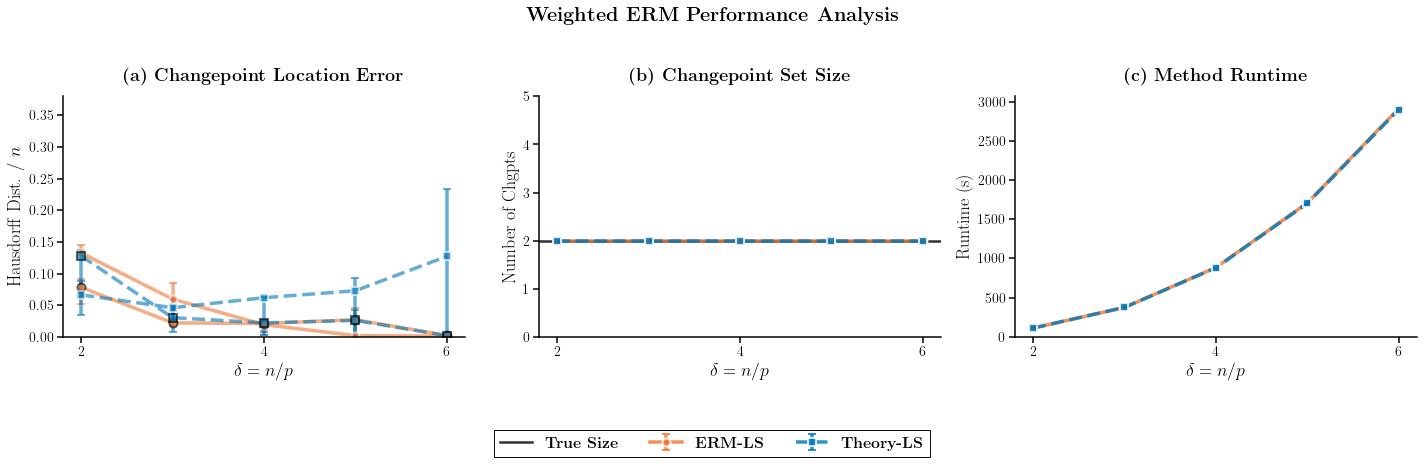

1. Asymmetric error bars (publication style) - location
labels b4:  ['\\textbf{ERM-LS}', '\\textbf{Theory-LS}']
labels after:  ['\\textbf{ERM-LS}', '\\textbf{Theory-LS}']
data for ERM-LS before inf handling:  [[0.13428571 0.14       0.03357143 0.14428571 0.15928571 0.14714286
  0.14428571 0.14571429 0.13714286 0.14      ]
 [0.02952381 0.05666667 0.08       0.0247619  0.11619048 0.02190476
  0.11904762 0.08619048 0.03714286 0.0252381 ]
 [0.01428571 0.01035714 0.01321429 0.02678571 0.0275     0.01464286
  0.06178571 0.00071429 0.01285714 0.01035714]
 [0.00114286 0.00028571 0.00142857 0.00028571 0.002      0.00142857
  0.00914286 0.00085714 0.00142857 0.00085714]
 [0.00071429 0.00190476 0.00142857 0.0002381  0.00357143 0.00095238
  0.0002381  0.0002381  0.00285714 0.00119048]]
data for ERM-LS before inf handling:  [[0.075      0.02142857 0.16357143 0.03571429 0.09142857 0.05785714
  0.09       0.11642857 0.08       0.05071429]
 [0.02238095 0.01857143 0.00714286 0.01666667 0.02238095 0.021

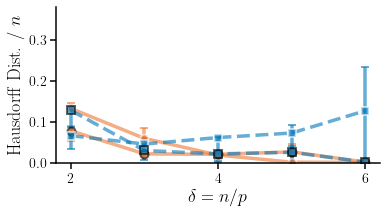

1. Asymmetric error bars (publication style) - size
labels b4:  ['\\textbf{ERM-LS}', '\\textbf{Theory-LS}']
labels after:  ['\\textbf{ERM-LS}', '\\textbf{Theory-LS}']


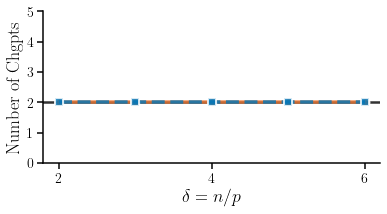

1. Asymmetric error bars (publication style) - runtime
labels b4:  ['\\textbf{ERM-LS}', '\\textbf{Theory-LS}']
labels after:  ['\\textbf{ERM-LS}', '\\textbf{Theory-LS}']


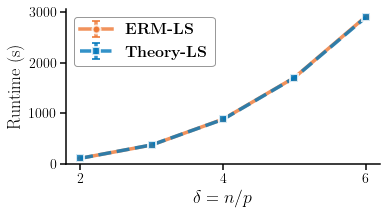

2. Confidence bands (publication style)...


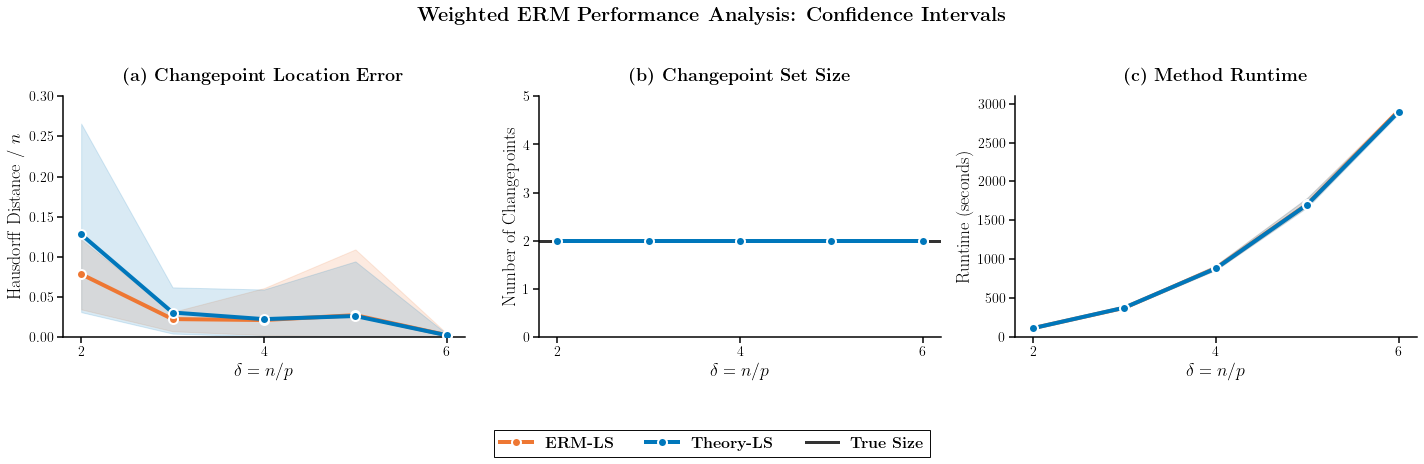

3. Box plots (publication style)...


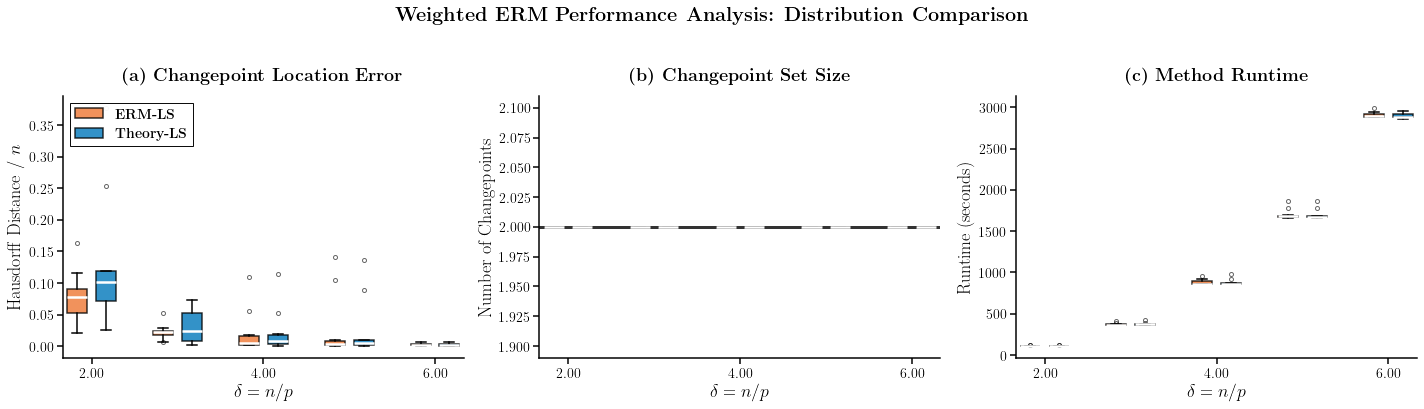

4. Enhanced changepoint histograms (publication style)...
14:43:00 - Publication-ready plotting completed in 1.11 seconds


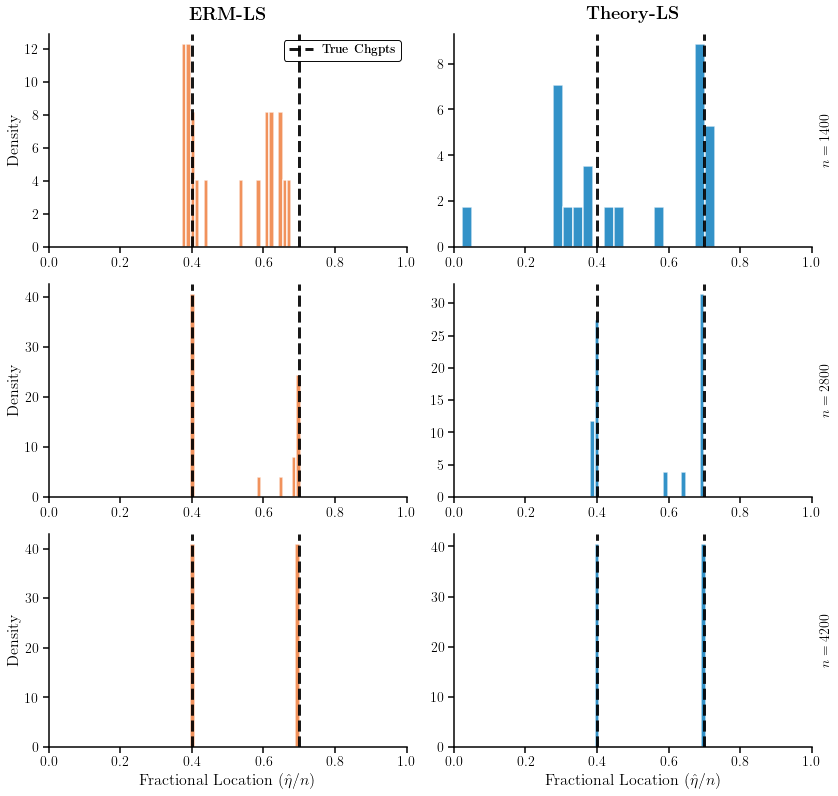

In [54]:
# -----------------------------------------------------------------------------
# 5. Publication-Ready Enhanced Plotting Results
# -----------------------------------------------------------------------------
import importlib
import sys
import numpy as np # Make sure numpy is imported
import time # Make sure time is imported
import matplotlib # Make sure matplotlib is imported
import gc
import matplotlib.pyplot as plt


# Close all existing figures first
try:
    import matplotlib.pyplot as plt
    plt.close('all')
except:
    pass

# Remove ALL matplotlib-related modules more thoroughly
modules_to_remove = []
for module_name in list(sys.modules.keys()):
    if any(module_name.startswith(prefix) for prefix in ['matplotlib', 'mpl_toolkits']):
        modules_to_remove.append(module_name)

print(f"Removing {len(modules_to_remove)} matplotlib modules...")
for module_name in modules_to_remove:
    if module_name in sys.modules:
        del sys.modules[module_name]

# Clear any cached references
gc.collect()

# Now import fresh matplotlib
matplotlib.use('pgf')
import matplotlib.pyplot as plt

print(f"Successfully set backend to: {matplotlib.get_backend()}")

# Set publication-ready matplotlib parameters
plt.rcParams.update({
    'pgf.texsystem': 'pdflatex',  # or 'xelatex', 'lualatex'
    'pgf.preamble': r'''
        \usepackage{amsmath}
        \usepackage{amsfonts}
        \usepackage{amssymb}
        \usepackage{siunitx}
    ''',
    'font.size': 14,      # Base font size
    'font.family': 'serif',    # Use serif fonts
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,      # Enable LaTeX rendering
    'axes.linewidth': 1.5,    # Thicker axes
    'axes.labelsize': 16,     # Larger axis labels
    'axes.titlesize': 18,     # Larger titles
    'xtick.labelsize': 14,    # Larger tick labels
    'ytick.labelsize': 14,
    'legend.fontsize': 14,    # Larger legend
    'legend.frameon': True,    # Legend frame
    'legend.fancybox': False,  # Clean rectangle
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 4.0,    # Thicker lines by default
    'lines.markersize': 8,     # Larger markers
    'figure.dpi': 72,         # High resolution
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

# Assuming `main_logger` is defined elsewhere in your script or you can remove this line
try:
    main_logger.info("Creating publication-ready plots...")
except NameError:
    print("main_logger not defined, skipping logging.")

plotting_start_time = time.time()

# RECOMMENDED: Most aesthetic AND colorblind-friendly palette
# Paul Tol "Vibrant" - optimal balance of aesthetics and accessibility
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB']

# Use the most aesthetic palette
PAL = TOL_VIBRANT
# random.shuffle(PAL)

print(f"Using palette: {PAL[:4]} (Paul Tol Vibrant)")

# --- Load data and set up global parameters (moved from end to top for clarity) ---
# This part assumes you have a filename to load from, or you'll need to define
# `results`, `params`, `p`, `L`, `noise_std`, `δ_list`, `fractional_chgpt_locations`,
# `n_jobs`, `methods_to_evaluate`, `random_seed` directly or load them differently.

# Example of how to load the data (adjust filename as needed)
# You need to ensure the `results` dictionary and `params` are populated
# before calling the plotting functions.

# -----------------------------------------------------------------------------
# Option 1: Publication-Ready Asymmetric Error Bars
# -----------------------------------------------------------------------------

# Calculate percentiles for asymmetric error bars
def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=1)
    p25 = np.nanpercentile(data, 25, axis=1)
    p75 = np.nanpercentile(data, 75, axis=1)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

def plot_with_asymmetric_errors_publication(plot_type='all'):
    """ plot_type is either: 'all', 'location', 'size', 'runtime'. """
    if plot_type == 'all':
        fig, axs = plt.subplots(1, 3, figsize=(20, 6))
        fig.suptitle(r'\textbf{Weighted ERM Performance Analysis}', fontsize=20, y=0.98)
    else:
        fig, axs = plt.subplots(1, 1, figsize=(5.6, 3.2))
    
    # Use method_names_list from the loaded/generated params
    methods = method_names_list
    colors = PAL[:len(methods)] # Use as many colors as methods
    
    # Define markers and linestyles to match the number of methods
    markers = ['o', 's', 'D', '^', 'v', '<', '>', 'P', '*']
    linestyles = ['-', '--', '-.', ':', (0, (3, 1, 1, 1)), (0, (5, 1))]
    
    labels = [method['label'] for method in methods_to_evaluate] # Use labels from methods_to_evaluate
    print("labels b4: ", labels)
    # labels = ['\\textbf{McScan}', '\\textbf{MOSEG}', '\\textbf{WERM}']
    # labels = ['McScan', 'MOSEG', 'WERM']
    print("labels after: ", labels)
    
    # Hausdorff Distance Plot
    if plot_type == 'all' or plot_type == 'location':
        if plot_type == 'all': ax = axs[0]
        elif plot_type == 'location': ax = axs
        for i, method_name in enumerate(methods):
            data = results_switch[f'haus_{method_name}']
            # Set all infs to NaN for plotting
            print(f"data for {method_name} before inf handling: ", data)
            data = np.where(np.isinf(data), np.nan, data)
            means = np.nanmean(data, axis=1)
            errors = get_asymmetric_errors(data)
            
            ax.errorbar(δ_list, means, yerr=errors,
                        label=labels[i], marker=markers[i % len(markers)], ls=linestyles[i % len(linestyles)],
                        color=colors[i], capsize=4, capthick=2, markersize=8,
                        linewidth=3.5, markeredgewidth=2, markeredgecolor='white',
                        alpha=0.6)

            data = results_unif[f'haus_{method_name}']
            # Set all infs to NaN for plotting
            print(f"data for {method_name} before inf handling: ", data)
            data = np.where(np.isinf(data), np.nan, data)
            means = np.nanmean(data, axis=1)
            errors = get_asymmetric_errors(data)
            
            ax.errorbar(δ_list, means, yerr=errors,
                        label=labels[i], marker=markers[i % len(markers)], ls=linestyles[i % len(linestyles)],
                        color=colors[i], capsize=4, capthick=2, markersize=8,
                        linewidth=3.5, markeredgewidth=2, markeredgecolor='black',
                        alpha=0.6)
        
        ax.set_ylim((0, 0.38))
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(r'Hausdorff Dist. / $n$', fontsize=18)
        if plot_type == 'all':
            ax.set_title(r'\textbf{(a) Changepoint Location Error}', fontsize=18, pad=15)
        
        # Cleaner x-axis with fewer ticks
        ax.set_xticks(δ_list[::2])  # Show every other tick
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    
    # Changepoint Set Size Plot
    if plot_type == 'all' or plot_type == 'size':
        if plot_type == 'all': ax = axs[1]
        elif plot_type == 'size': ax = axs

        for i, method_name in enumerate(methods):
            data = results[f'size_{method_name}']
            means = np.nanmean(data, axis=1)
            errors = get_asymmetric_errors(data)
            
            ax.errorbar(δ_list, means, yerr=errors,
                        label=labels[i], marker=markers[i % len(markers)], ls=linestyles[i % len(linestyles)],
                        color=colors[i], capsize=4, capthick=2, markersize=8,
                        linewidth=3.5, markeredgewidth=2, markeredgecolor='white',
                        alpha=0.8)
        
        ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                   linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
        ax.set_ylim((0, L + 2))
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(r'Number of Chgpts', fontsize=18)
        if plot_type == 'all':
            ax.set_title(r'\textbf{(b) Changepoint Set Size}', fontsize=18, pad=15)
        
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    
    # Runtime Plot
    if plot_type == 'all' or plot_type == 'runtime':
        if plot_type == 'all': ax = axs[2]
        elif plot_type == 'runtime': ax = axs
        for i, method_name in enumerate(methods):
            data = results[f'runtime_{method_name}']
            means = np.nanmean(data, axis=1)
            errors = get_asymmetric_errors(data)
            
            ax.errorbar(δ_list, means, yerr=errors,
                        label=labels[i], marker=markers[i % len(markers)], ls=linestyles[i % len(linestyles)],
                        color=colors[i], capsize=4, capthick=2, markersize=8,
                        linewidth=3.5, markeredgewidth=2, markeredgecolor='white', alpha=0.8)
        
        ax.set_ylim(bottom=0)
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(r'Runtime (s)', fontsize=18)
        if plot_type == 'all':
            ax.set_title(r'\textbf{(c) Method Runtime}', fontsize=18, pad=15)
        
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    
    if plot_type == 'all':
        # Single legend for all subplots
        handles, labels_leg = axs[1].get_legend_handles_labels()
        if plot_type is not 'location':
            fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
                    ncol=len(methods)+1, fontsize=16, frameon=True,
                    edgecolor='black', framealpha=0.95)
        plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    else:
        if plot_type is not 'location' and plot_type is not 'size':
            ax.legend(loc='best', prop={'size': 16}, fancybox = True, framealpha = 0.4)
        fig.tight_layout()
    
    # plt.show() # Removed plt.show() as per the original structure that saves then shows
    return fig, axs

# -----------------------------------------------------------------------------
# Option 2: Publication-Ready Confidence Bands
# -----------------------------------------------------------------------------
def plot_with_confidence_bands_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Weighted ERM Performance Analysis: Confidence Intervals}',
                 fontsize=20, y=0.98)
    
    methods = method_names_list
    colors = PAL[:len(methods)]
    labels = [method['label'] for method in methods_to_evaluate]
    
    metrics = [('haus', r'Hausdorff Distance / $n$', r'\textbf{(a) Changepoint Location Error}', (0, 0.3)),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}', (0, L + 2)),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}', None)]
    
    for ax_idx, (metric, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]
        
        for method_idx, method_name in enumerate(methods):
            data = results[f'{metric}_{method_name}']
            means = np.mean(data, axis=1)
            
            # Calculate confidence intervals (10th and 90th percentiles)
            p10 = np.percentile(data, 10, axis=1)
            p90 = np.percentile(data, 90, axis=1)
            
            p10 = np.minimum(p10, means)
            p90 = np.maximum(p90, means)
            
            # Plot confidence band first (so it's behind the line)
            ax.fill_between(δ_list, p10, p90, color=colors[method_idx],
                            alpha=0.15, zorder=1)
            
            # Plot mean line with markers
            ax.plot(δ_list, means, color=colors[method_idx], linewidth=4,
                    marker='o', markersize=9, label=labels[method_idx], zorder=3,
                    markeredgewidth=2, markeredgecolor='white')
        
        # Add true size line for size plot
        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}', zorder=2)
        
        if ylim:
            ax.set_ylim(ylim)
        elif metric == 'runtime':
            ax.set_ylim(bottom=0)
        
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        
        # Cleaner axes
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    
    # Single legend for all subplots
    handles, labels_leg = axs[1].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods)+1, fontsize=16, frameon=True,
               edgecolor='black', framealpha=0.95)
    
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# -----------------------------------------------------------------------------
# Option 3: Publication-Ready Box Plots
# -----------------------------------------------------------------------------
def plot_with_boxplots_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Weighted ERM Performance Analysis: Distribution Comparison}',
                 fontsize=20, y=0.98)
    
    methods = method_names_list
    colors = PAL[:len(methods)]
    labels = [method['label'] for method in methods_to_evaluate]
    
    metrics = [('haus', r'Hausdorff Distance / $n$', r'\textbf{(a) Changepoint Location Error}'),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}'),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}')]
    
    for ax_idx, (metric, ylabel, title) in enumerate(metrics):
        ax = axs[ax_idx]
        
        # Create box plots for each delta value
        for delta_idx, delta in enumerate(δ_list):
            box_data = []
            box_positions = []
            box_colors = []
            
            for method_idx, method_name in enumerate(methods):
                data = results[f'{metric}_{method_name}'][delta_idx, :]
                box_data.append(data)
                box_positions.append(delta_idx * (len(methods) + 1) + method_idx) # Adjusted spacing
                box_colors.append(colors[method_idx])
            
            # Create publication-ready box plots
            bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                            patch_artist=True, showfliers=True,
                            flierprops=dict(marker='o', markersize=4, alpha=0.6),
                            medianprops=dict(color='white', linewidth=2.5),
                            boxprops=dict(linewidth=1.5),
                            whiskerprops=dict(linewidth=1.5),
                            capprops=dict(linewidth=1.5))
            
            # Color the boxes
            for patch, color in zip(bp['boxes'], box_colors):
                patch.set_facecolor(color)
                patch.set_alpha(0.8)
                patch.set_edgecolor('black')
        
        # Set x-axis labels - only show every other delta for cleanliness
        # Adjust delta_positions calculation
        delta_positions = [i * (len(methods) + 1) + (len(methods) - 1) / 2.0 for i in range(len(δ_list))]
        ax.set_xticks(delta_positions[::2])  # Every other position
        ax.set_xticklabels([f'{d:.2f}' for d in δ_list[::2]])
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        
        # Add legend (only for first subplot)
        if ax_idx == 0:
            legend_elements = [plt.Rectangle((0,0),1,1, facecolor=colors[i],
                                             alpha=0.8, edgecolor='black',
                                             linewidth=1.5, label=labels[i])
                               for i in range(len(methods))]
            ax.legend(handles=legend_elements, loc='upper left', fontsize=14,
                      frameon=True, edgecolor='black', framealpha=0.95)
        
        # Add true size line for size plot
        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}')
        
        # Clean axes
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# -----------------------------------------------------------------------------
# Publication-Ready Changepoint Histograms
# -----------------------------------------------------------------------------
def plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, methods_to_plot_names=['ext']):
    """
    Publication-ready changepoint location histograms
    Updated to use method_names_list and method_labels from methods_to_evaluate.
    """
    
    # Create method_names and method_colors dictionaries dynamically from methods_to_evaluate
    method_names_map = {method['name']: method['label'] for method in methods_to_evaluate}
    method_colors_map = {method['name']: PAL[i % len(PAL)] for i, method in enumerate(methods_to_evaluate)}
    
    # Filter methods based on methods_to_plot_names
    current_methods = [method for method in methods_to_evaluate if method['name'] in methods_to_plot_names]
    current_method_names = [method['name'] for method in current_methods]

    selected_deltas_idx = list(range(len(δ_list)))[::2]
    selected_deltas = δ_list[::2]
    
    fig, axes = plt.subplots(len(selected_deltas), len(current_methods),
                             figsize=(6*len(current_methods), 4*len(selected_deltas)))
    
    # Handle subplot configurations
    if len(selected_deltas) == 1 and len(current_methods) == 1:
        axes = np.array([[axes]])
    elif len(current_methods) == 1:
        axes = axes.reshape(-1, 1)
    elif len(selected_deltas) == 1:
        axes = axes.reshape(1, -1)
    
    fig.patch.set_facecolor('white')
    # fig.suptitle(r'\textbf{Estimated Changepoint Locations Distribution}',
    #              fontsize=20, y=0.98)
    
    for row, (delta_idx, delta) in enumerate(zip(selected_deltas_idx, selected_deltas)):
        n = int(delta * p)
        
        for col, method_name in enumerate(current_method_names):
            ax = axes[row, col]
            ax.set_facecolor('white')
            
            # Collect changepoints for the current method and delta
            all_chgpts = []
            chgpts_data_for_method = results.get(f'chgpts_{method_name}', [])
            for res_delta_idx, chgpts_list in chgpts_data_for_method:
                if res_delta_idx == delta_idx:
                    # chgpts_list can be a list of arrays or just a list/array
                    for chgpts in chgpts_list:
                        if hasattr(chgpts, '__len__') and len(chgpts) > 0:
                            chgpts_array = np.array(chgpts)
                            valid_chgpts = chgpts_array[chgpts_array != -1]
                            for chgpt in valid_chgpts:
                                fractional_chgpt = chgpt / n
                                all_chgpts.append(fractional_chgpt)
                        elif np.isscalar(chgpts) and chgpts != -1:
                            fractional_chgpt = chgpts / n
                            all_chgpts.append(fractional_chgpt)
            
            # Create publication-ready histogram
            if len(all_chgpts) > 0:
                counts, bins, patches = ax.hist(all_chgpts, bins=25, alpha=0.8,
                                                color=method_colors_map[method_name],
                                                density=True, edgecolor='white',
                                                linewidth=1.5)
                
                # Add KDE overlay if we have enough points
                # if len(all_chgpts) > 8:
                #     kde = gaussian_kde(all_chgpts)
                #     x_range = np.linspace(0, 1, 200)
                #     kde_values = kde(x_range)
                #     ax.plot(x_range, kde_values, color='darkred', linewidth=3,
                #             alpha=0.9, label=r'\textbf{KDE}')
                
            else:
                ax.text(0.5, 0.5, r'\textit{No changepoints detected}',
                        transform=ax.transAxes, ha='center', va='center',
                        fontsize=14, alpha=0.7, style='italic')
            
            # True changepoints with thicker lines
            for i, true_chgpt in enumerate(fractional_chgpt_locations):
                ax.axvline(x=true_chgpt, color='black', linestyle='--', linewidth=3,
                           alpha=0.9, zorder=10,
                           label=r'\textbf{True Chgpts}' if i == 0 else "")
            
            ax.set_xlim(0, 1)
            
            # Only label bottom row and leftmost column
            if row == len(selected_deltas)-1:
                ax.set_xlabel(r'Fractional Location ($\hat{\mathbf{\eta}}/n$)', fontsize=16)
            if col == 0:
                ax.set_ylabel(r'Density', fontsize=16)
            
            # Method name as title for top row
            if row == 0:
                ax.set_title(f'{method_names_map[method_name]}', fontsize=18, pad=15)
            
            # Add n value annotation
            if col == len(current_methods)-1:
                ax.text(1.02, 0.5, f'$n = {n}$', transform=ax.transAxes,
                        rotation=90, verticalalignment='center', fontsize=14,
                        fontweight='bold')
            
            # Clean axes
            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)
            
            # Add legend for first subplot if there are changepoints
            if row == 0 and col == 0 and len(all_chgpts) > 0:
                legend = ax.legend(loc='upper right', fontsize=12, frameon=True,
                                   edgecolor='black', framealpha=0.95, fancybox=True)
    
    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    # plt.show()
    return fig, axes


# Execute publication-ready plotting options
print("Creating publication-ready plots...")

print("1. Asymmetric error bars (publication style)...")
# Save the 'all' plot separately if desired, then individual ones
fig_all, axs_all = plot_with_asymmetric_errors_publication(plot_type='all')
# fig_all.savefig(f'figures/SWERMvsEWERM_all_metrics_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
# fig_all.savefig(f'figures/SWERMvsEWERM_all_metrics_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.png', dpi=300, bbox_inches='tight')
# fig_all.savefig(f'figures/SWERMvsEWERM_all_metrics_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pgf',
                #  dpi=300, bbox_inches='tight')
plt.show(fig_all) # Explicitly show the figure

print("1. Asymmetric error bars (publication style) - location")
fig_loc, axs_loc = plot_with_asymmetric_errors_publication(plot_type='location')
# fig_loc.savefig(f'figures/_location_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
method_names_for_filename = '_'.join(method['name'] for method in methods_to_evaluate)
# Save figure with the method names and parameters in the filename
# fig_loc.savefig(f'figures/M1b_{method_names_for_filename}_location_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
# fig_loc.savefig(f'figures/M1b_{method_names_for_filename}_location_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pgf',
#              dpi=300, bbox_inches='tight')
plt.show(fig_loc)

print("1. Asymmetric error bars (publication style) - size")
fig_size, axs_size = plot_with_asymmetric_errors_publication(plot_type='size')
# fig_size.savefig(f'figures/SWERMvsEWERM_size_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
# fig_size.savefig(f'figures/SWERMvsEWERM_size_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.png', dpi=300, bbox_inches='tight')
# fig_size.savefig(f'figures/SWERMvsEWERM_size_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pgf',
#              dpi=300, bbox_inches='tight')
# fig_size.savefig(f'figures/M1b_{method_names_for_filename}_size_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
# fig_size.savefig(f'figures/M1b_{method_names_for_filename}_size_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pgf',
#              dpi=300, bbox_inches='tight')
plt.show(fig_size)


print("1. Asymmetric error bars (publication style) - runtime")
fig_rt, axs_rt = plot_with_asymmetric_errors_publication(plot_type='runtime')
# fig_rt.savefig(f'figures/SWERMvsEWERM_runtime_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
# fig_rt.savefig(f'figures/SWERMvsEWERM_runtime_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.png', dpi=300, bbox_inches='tight')
# fig_rt.savefig(f'figures/SWERMvsEWERM_runtime_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pgf',
#                 dpi=300, bbox_inches='tight')
# fig_rt.savefig(f'figures/M1b_{method_names_for_filename}_runtime_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
# fig_rt.savefig(f'figures/M1b_{method_names_for_filename}_runtime_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pgf',
#              dpi=300, bbox_inches='tight')
plt.show(fig_rt)


print("2. Confidence bands (publication style)...")
plot_with_confidence_bands_publication()

print("3. Box plots (publication style)...")
plot_with_boxplots_publication()

print("4. Enhanced changepoint histograms (publication style)...")
# Pass the list of method names for which you want to plot histograms.
# This will plot histograms for 'ext' (Extended Penalized ERM) only.
# plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, methods_to_plot_names=method_names_list)

# If you want to plot histograms for all methods evaluated, you could do:
fig_hist, axs_hist = plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, methods_to_plot_names=method_names_list)
# fig_hist.savefig(f'figures/M1b_{method_names_for_filename}_chgpt_histograms_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
# fig_hist.savefig(f'figures/M1b_{method_names_for_filename}_chgpt_histograms_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pgf',
#              dpi=300, bbox_inches='tight')

plotting_time = time.time() - plotting_start_time
try:
    main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")
except NameError:
    print(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

# The saving of the results pickle file is handled by the first code block provided by the user.
# I've included a dummy load/setup at the top of this script to make it runnable independently for testing.
# Ensure your main execution flow calls the plotting functions after `results` and `params` are properly loaded.

# Playground

In [ ]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
import WERM.model as model
import WERM.general_fixed_point_eqns as fp
import WERM.M_est_fixed_point_eqns as M_est
import WERM.gof
import WERM.performance_measures
import WERM.marginals
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm.auto import tqdm
import time
from joblib import Parallel, delayed
import logging
from datetime import datetime, timedelta
import sys
import pickle
import os

# Set a random seed for reproducibility
random_seed = 42
nprandom.seed(random_seed)
jax.random.PRNGKey(random_seed) # Set JAX random seed as well

# --- Logging Setup ---
def setup_logging():
    """Setup comprehensive logging for the simulation"""
    detailed_formatter = logging.Formatter(
        '%(asctime)s - %(name)s - %(levelname)s - %(message)s',
        datefmt='%Y-%m-%d %H:%M:%S'
    )
    simple_formatter = logging.Formatter(
        '%(asctime)s - %(message)s',
        datefmt='%H:%M:%S'
    )

    # Create logs directory if it doesn't exist
    import os
    log_dir = 'logs'
    if not os.path.exists(log_dir):
        os.makedirs(log_dir)

    main_logger = logging.getLogger('simulation')
    main_logger.setLevel(logging.INFO)
    main_logger.handlers = [] # Clear existing handlers

    console_handler = logging.StreamHandler(sys.stdout)
    console_handler.setLevel(logging.INFO)
    console_handler.setFormatter(simple_formatter)
    main_logger.addHandler(console_handler)

    file_handler = logging.FileHandler('logs/WERM_SE_match_est_sq.log', mode='w')
    file_handler.setLevel(logging.DEBUG)
    file_handler.setFormatter(detailed_formatter)
    main_logger.addHandler(file_handler)

    progress_logger = logging.getLogger('progress')
    progress_logger.setLevel(logging.INFO)
    progress_logger.handlers = [] # Clear existing handlers

    progress_handler = logging.FileHandler('logs/WERM_SE_match_est_sq_progress.log', mode='w')
    progress_handler.setLevel(logging.INFO)
    progress_handler.setFormatter(detailed_formatter)
    progress_logger.addHandler(progress_handler)

    return main_logger, progress_logger

# Initialize loggers
main_logger, progress_logger = setup_logging()

class ProgressTracker:
    """Class to track and log simulation progress"""
    def __init__(self, total_tasks, delta_list, num_trials, logger):
        self.total_tasks = total_tasks
        self.delta_list = delta_list
        self.num_trials = num_trials
        self.logger = logger
        self.start_time = time.time()
        self.completed_tasks = 0
        self.delta_progress = {i: 0 for i in range(len(delta_list))}

    def update(self, delta_idx):
        """Update progress for a completed task"""
        self.completed_tasks += 1
        percent_complete = (self.completed_tasks / self.total_tasks) * 100
        elapsed_time = time.time() - self.start_time

        if self.completed_tasks > 0:
            avg_time_per_task = elapsed_time / self.completed_tasks
            remaining_tasks = self.total_tasks - self.completed_tasks
            estimated_remaining_time = remaining_tasks * avg_time_per_task
            estimated_completion = datetime.now() + timedelta(seconds=estimated_remaining_time)

            self.logger.info(
                f"Progress: {self.completed_tasks}/{self.total_tasks} ({percent_complete:.1f}%) | "
                f"Elapsed: {elapsed_time:.1f}s | "
                f"Est. remaining: {estimated_remaining_time:.1f}s | "
                f"Est. completion: {estimated_completion.strftime('%H:%M:%S')}"
            )

        self.delta_progress[delta_idx] += 1
        # Log delta-specific progress less frequently to avoid excessive logging
        if self.completed_tasks % max(1, self.total_tasks // 10) == 0 or self.completed_tasks == 1 or self.completed_tasks == self.total_tasks:
            delta_status = []
            for i, delta in enumerate(self.delta_list):
                progress = self.delta_progress[i]
                delta_status.append(f"δ={delta:.1f}: {progress}/{self.num_trials}")
            self.logger.info("Delta progress: " + " | ".join(delta_status))

# Global progress tracker (initialized later)
progress_tracker = None

# --- Helper Function for a Single Parallel Job ---
def run_single_trial(params, p, L, noise_std, fractional_chgpt_locations, M, method_configs, B̃):
    """
    Executes a single simulation trial for a given delta, running multiple methods.
    This function is designed to be called in parallel by joblib.
    """
    global progress_tracker
    i, δ, j = params # i: delta_list index, δ: current delta value, j: trial number
    trial_start_time = time.time()

    progress_logger.info(f"Starting trial {j+1}/{num_trials} for δ={δ:.1f} (delta_idx={i})")

    # --- Setup based on delta ---
    n = int(δ * p)
    if fractional_chgpt_locations.size != 0:
        true_chgpt_locations = lambda n_len: (n_len * fractional_chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
    else:
        true_chgpt_locations = lambda n_len: np.array([])
        C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0.

    # --- Preliminaries (from original code) ---
    # --- Compute weights as marginals of prior --- #
    Δ = lambda n: int(n/20)
    Delta_n = int(Δ(n))
    L_is_upper_bound = False
    if Delta_n ==1 : # No separation between change points, so use analytical binomial approximation. 
        if L_is_upper_bound:
            pi_i_l = lambda L, l, i : 1/(L - l + 1) * np.sum([scipy.special.comb(k - 1, l- 1, exact=False) * (i/n)**(l-1) * (1 - i/n)**(k-l) for k in range(l, L+1)])
        else: 
            pi_i_l = lambda L,l , i: scipy.special.comb(L-1, l-1, exact=False) * (i/n)**(l-1) * (1 - i/n)**(L-l)
        # Populate the pi L times n matrix
        pi = np.zeros((L, n))
        for l in range(L):
            for i in range(n):
                pi[l, i] = pi_i_l(L, l + 1, i + 1)
    else: 
        n_small = 100
        Delta_n_small = int(Delta_n * n_small/n)
        if L_is_upper_bound: 
            p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
            Lmin = 1
            Lmax = L
        else:
            p_l = None
            Lmin = L
            Lmax = L
        pi = WERM.config.extrapolated_marginals(Lmin, Lmax, Delta_n_small, n_small = n_small, n_large = n, p_l = p_l, verbose = False)
    π = pi
    if L == 1: 
        π = np.ones((1, n))

    pi_switch = π.copy() # This is the switch matrix, which is the same as π in this case.
    pi_switch[0, :] = π[0, :].copy() + π[2, :].copy()
    pi_switch[2, :] = π[0, :].copy() + π[2, :].copy()
    # pi_switch = pi_switch / np.sum(pi_switch, axis=1, keepdims=True) # Normalize the switch matrix

    # --- Data Generation for this trial ---
    data_gen_start = time.time()
    X = nprandom.normal(0, np.sqrt(1/n), (n, p))
    X = X @ Sigma_chol.T
    ε = nprandom.randn(n) * noise_std
    # ε = np.random.standard_t(5, size=(n, )) * noise_std # For Huber loss, use t-distribution for noise. df > 2 has finite variance.
    B̃ = np.sqrt(δ) * B̃ # Scale B̃ by sqrt(delta) here since we vary delta, see the definition of B̃ outside of loop. 
    Θ = X @ B̃
    y_mapped_fn = jax.vmap(model.q_linear_model, in_axes=(0, 0, 0))
    y = y_mapped_fn(Θ, C_true, ε)
    data_gen_time = time.time() - data_gen_start

    trial_results = {}
    methods_status = {method_name: False for method_name in method_configs.keys()}

    # Compute fixed point solution once per delta for theoretical comparison
    ρ = (1/δ) * (1/p) * (B̃.T @ Sigma_chol @ Sigma_chol.T @ B̃)

    # --- Run Estimators for all configured methods ---
    for method_name, method_func_info in method_configs.items():
        try:
            method_start = time.time()
            current_B̂ = np.zeros((p, L))
            Θ̂_theory = np.zeros((n, L))
            current_corr_list = []
            current_mse_list = []
            current_chgpt_loc = np.array([])

            if method_name == 'ERM-switch':
                for ℓ_ in range(L):
                    sample_weight = pi_switch[ℓ_, :] 
                    empirical_risk = lambda β: jnp.multiply(M((X @ β).flatten(), y.flatten()), sample_weight).sum()
                    res = scipy.optimize.minimize(empirical_risk, 0.1*np.ones(p), jac=jax.grad(empirical_risk), method='L-BFGS-B')
                    β̂ = res.x
                    current_B̂[:, ℓ_] = β̂
                    current_corr_list.append(WERM.norm_sq_corr(β̂, B̃[:, ℓ_]))
                    current_mse_list.append(WERM.MSE(β̂.flatten(), B̃[:, ℓ_]))
                # Determine changepoints for ERM
                opt_chgpt_loc_erm, _ = WERM.gof.chgpt_gof_bf_mem_eff(
                    M, X @ current_B̂, y, n, L, Δ(n), L_is_upper_bound=False,
                    γ=0, batch_size=batch_size, gof_opt_output=True
                )
                # opt_chgpt_loc_erm, _ = WERM.gof.chgpt_binary_segmentation(
                #     M, X @ current_B̂, y, n, L, Δ(n), L_is_upper_bound=False,
                #     γ=0, gof_opt_output=True
                # )
                current_chgpt_loc = opt_chgpt_loc_erm

            elif method_name == 'Theory-switch':

                b, ν̃, κ̃ = fp.general_fp(M, ρ, δ, true_chgpt_locations(n), pi_switch, ε, n, model.q_linear_model)
                κ̃_sqrt = jnp.linalg.cholesky(κ̃ + 1e-12 * jnp.eye(L))
                print("-"*60)
                print("b, ν̃, κ̃ for δ=", δ, ":", b, ν̃, κ̃, ", trial : ", j+1)
                print("-"*60)
                G_sample = nprandom.multivariate_normal(np.zeros((L, )), np.eye(L), size=(p,)) @ κ̃_sqrt.T
                G_sample_n = nprandom.multivariate_normal(np.zeros((L, )), np.eye(L), size=(n,)) @ κ̃_sqrt.T
                Z = nprandom.multivariate_normal(np.zeros((L, )), ρ, size=(n,))
                y_theory = y_mapped_fn(Z, C_true, ε) 
                M_prime = jax.grad(M, argnums=0)
                M_double_prime = jax.grad(M_prime, argnums=0)
                for ℓ_ in range(L):
                    β̂_theory = B̃ @ ν̃[:, ℓ_] + δ**(1/2) * np.linalg.inv(Sigma_chol).T @ G_sample[:, ℓ_]
                    current_B̂[:, ℓ_] = β̂_theory
                    current_corr_list.append(WERM.norm_sq_corr(β̂_theory, B̃[:, ℓ_]))
                    current_mse_list.append(WERM.MSE(β̂_theory.flatten(), B̃[:, ℓ_]))
                    
                    sample_weight = pi_switch[ℓ_, :]
                    prox_mapped = lambda z, b, π_i, v: jax.vmap(fp.prox, in_axes=(0, None, 0, 0, None, None))(z, b, π_i, v, M_prime, M_double_prime)
                    Θ̂_theory[:, ℓ_] = prox_mapped(Z @ ν̃[:, ℓ_] + G_sample_n[:, ℓ_], b[ℓ_], sample_weight, y_theory)

                # Determine changepoints for Theory
                opt_chgpt_loc_theory, _ = WERM.gof.chgpt_gof_bf_mem_eff(
                    M, Θ̂_theory, y_theory, n, L, Δ(n), L_is_upper_bound=False,
                    γ=0, batch_size=batch_size, gof_opt_output=True
                )
                current_chgpt_loc = opt_chgpt_loc_theory

            elif method_name == 'ERM-unif':
                for ℓ_ in range(L):
                    sample_weight = π[ℓ_, :]
                    empirical_risk = lambda β: jnp.multiply(M((X @ β).flatten(), y.flatten()), sample_weight).sum()
                    res = scipy.optimize.minimize(empirical_risk, 0.1*np.ones(p), jac=jax.grad(empirical_risk), method='L-BFGS-B')
                    β̂ = res.x
                    current_B̂[:, ℓ_] = β̂
                    current_corr_list.append(WERM.norm_sq_corr(β̂, B̃[:, ℓ_]))
                    current_mse_list.append(WERM.MSE(β̂.flatten(), B̃[:, ℓ_]))
                # Determine changepoints for ERM
                opt_chgpt_loc_erm, _ = WERM.gof.chgpt_gof_bf_mem_eff(
                    M, X @ current_B̂, y, n, L, Δ(n), L_is_upper_bound=False,
                    γ=0, batch_size=batch_size, gof_opt_output=True
                )
                # opt_chgpt_loc_erm, _ = WERM.gof.chgpt_binary_segmentation(
                #     M, X @ current_B̂, y, n, L, Δ(n), L_is_upper_bound=False,
                #     γ=0, gof_opt_output=True
                # )
                current_chgpt_loc = opt_chgpt_loc_erm

            elif method_name == 'Theory-unif':
                b, ν̃, κ̃ = fp.general_fp(M, ρ, δ, true_chgpt_locations(n), π, ε, n, model.q_linear_model)
                κ̃_sqrt = jnp.linalg.cholesky(κ̃ + 1e-12 * jnp.eye(L))
                print("-"*60)
                print("b, ν̃, κ̃ for δ=", δ, ":", b, ν̃, κ̃, ", trial : ", j+1)
                print("-"*60)

                G_sample = nprandom.multivariate_normal(np.zeros((L, )), np.eye(L), size=(p,)) @ κ̃_sqrt.T
                G_sample_n = nprandom.multivariate_normal(np.zeros((L, )), np.eye(L), size=(n,)) @ κ̃_sqrt.T
                Z = nprandom.multivariate_normal(np.zeros((L, )), ρ, size=(n,))
                y_theory = y_mapped_fn(Z, C_true, ε) 
                M_prime = jax.grad(M, argnums=0)
                M_double_prime = jax.grad(M_prime, argnums=0)
                for ℓ_ in range(L):
                    β̂_theory = B̃ @ ν̃[:, ℓ_] + δ**(1/2) * np.linalg.inv(Sigma_chol).T @ G_sample[:, ℓ_]
                    current_B̂[:, ℓ_] = β̂_theory
                    current_corr_list.append(WERM.norm_sq_corr(β̂_theory, B̃[:, ℓ_]))
                    current_mse_list.append(WERM.MSE(β̂_theory.flatten(), B̃[:, ℓ_]))
                    
                    sample_weight = π[ℓ_, :]
                    prox_mapped = lambda z, b, π_i, v: jax.vmap(fp.prox, in_axes=(0, None, 0, 0, None, None))(z, b, π_i, v, M_prime, M_double_prime)
                    Θ̂_theory[:, ℓ_] = prox_mapped(Z @ ν̃[:, ℓ_] + G_sample_n[:, ℓ_], b[ℓ_], sample_weight, y_theory)

                # Determine changepoints for Theory
                opt_chgpt_loc_theory, _ = WERM.gof.chgpt_gof_bf_mem_eff(
                    M, Θ̂_theory, y_theory, n, L, Δ(n), L_is_upper_bound=False,
                    γ=0, batch_size=batch_size, gof_opt_output=True
                )
                current_chgpt_loc = opt_chgpt_loc_theory
            else:
                main_logger.warning(f"Method {method_name} not recognized. Skipping.")
                continue

            method_time = time.time() - method_start
            trial_results[f'runtime_{method_name}'] = method_time
            trial_results[f'corr_{method_name}'] = np.array(current_corr_list)
            trial_results[f'mse_{method_name}'] = np.array(current_mse_list)
            trial_results[f'haus_{method_name}'] = (1/n * WERM.performance_measures.hausdorff(current_chgpt_loc, true_chgpt_locations(n)))
            trial_results[f'size_{method_name}'] = len(current_chgpt_loc[current_chgpt_loc != -1])
            trial_results[f'chgpts_{method_name}'] = current_chgpt_loc.copy()
            methods_status[method_name] = True

        except Exception as e:
            main_logger.error(f"Trial {j+1} for δ={δ:.1f}: {method_name} failed with error: {e}", exc_info=True)
            trial_results[f'runtime_{method_name}'] = np.nan
            trial_results[f'corr_{method_name}'] = np.full(L, np.nan)
            trial_results[f'mse_{method_name}'] = np.full(L, np.nan)
            trial_results[f'haus_{method_name}'] = np.nan
            trial_results[f'size_{method_name}'] = np.nan
            trial_results[f'chgpts_{method_name}'] = np.array([])
            methods_status[method_name] = False

    # Store additional info for histogram plotting
    trial_results['n'] = n
    trial_results['true_chgpts'] = true_chgpt_locations(n).copy()
    trial_results['fractional_true_chgpts'] = fractional_chgpt_locations.copy()
    trial_results['methods_status'] = methods_status

    trial_total_time = time.time() - trial_start_time
    log_message_parts = [
        f"Completed trial {j+1} for δ={δ:.1f}: ",
        f"Total={trial_total_time:.1f}s (Data={data_gen_time:.1f}s)"
    ]
    for method_name in method_configs.keys():
        status_str = 'OK' if methods_status[method_name] else 'FAIL'
        runtime_str = f"{trial_results[f'runtime_{method_name}']:.1f}s" if f'runtime_{method_name}' in trial_results and not np.isnan(trial_results[f'runtime_{method_name}']) else "N/A"
        log_message_parts.append(f"{method_name}={status_str} ({runtime_str})")
    progress_logger.info(" ".join(log_message_parts))

    if progress_tracker:
        progress_tracker.update(i)

    return i, j, trial_results

# --- Main Script Setup ---
main_logger.info("Starting WERM Simulation with parallel execution and enhanced logging")
main_logger.info("=" * 80)

# Simulation Parameters
p = 700 # at least 500 is needed for stable results
L = 3 # num signals. L-1 changepoints
noise_std = np.sqrt(0.5) # sqrt(0.5) on gaussian noise to get recent good plot

δ_list = np.arange(1.0, 2.6, 0.25)
num_trials = 10 # Increased for better statistics
fractional_chgpt_locations = np.array([0.3, 0.8]) # [0.2,0.8] gave biggest improvement for ERM-switch. Also noticed big differences in bf vs. non-bf for ERM-switch

n_jobs = 15 # Use all available CPU cores. Set to 1 for no parallelization.

# Least Squares Loss
M = lambda u, v: jnp.power(u - v, 2)

# # Huber Loss
# def M(u, v, epsilon=1.35):
#     residual = u - v
#     abs_residual = jnp.abs(residual)
#     condition = abs_residual <= epsilon
#     squared_loss = 0.5 * jnp.square(residual)
#     linear_loss = epsilon * (abs_residual - 0.5 * epsilon)
#     return jnp.where(condition, squared_loss, linear_loss)

# Sample the signal outside
# κ = 1.0
# B̃_cov = κ**2 * np.eye(L) # Omit the δ term here, multiply it inside of the trial loop since we vary δ
# # Add some correlation between signals for L > 1
# r_B = 0.25
# if L > 1:
#     for ll in range(L):
#         for mm in range(L):
#             if ll != mm:
#                 B̃_cov[ll, mm] = r_B**(abs(ll - mm)) * κ**2
# signal_prior = GaussianSignal(B̃_cov)
# B̃ = signal_prior.sample(p)

# def sample_corr(p, df=10, seed=None):
#     """Sample a random correlation matrix using the Haar measure."""
#     rng = np.random.default_rng(seed)
#     Q, _ = np.linalg.qr(rng.standard_normal((p, p)))           # Haar‐orthogonal
#     λ = rng.chisquare(df, size=p)                              # χ² eigenvalues
#     B = Q.T @ np.diag(λ) @ Q                                   # SPD matrix
#     D = np.sqrt(np.diag(B))
#     return B / np.outer(D, D)

# Sigma = sample_corr(p, df=10, seed=random_seed) 

κ = 1.0
B̃_cov = κ**2 * np.eye(L) # Remove the δ term here, multiply it inside of the trial loop since we vary δ
# Make the first and third signals identical
B̃_cov[0, 2] = 0.999 * κ**2 # Covariance between first and third signals, make them not perfectly identical for numerical stability
B̃_cov[2, 0] = 0.999 * κ**2 # Covariance between first and third signals, make them not perfectly identical for numerical stability
B̃_cov[0, 1] = 0.1 * κ**2 # Covariance between first and second signals
B̃_cov[1, 0] = 0.1 * κ**2 # Covariance between first and second signals
B̃_cov[1, 2] = 0.1 * κ**2 # Covariance between second and third signals
B̃_cov[2, 1] = 0.1 * κ**2 # Covariance between second and third signals
print(f"B̃_cov:\n{B̃_cov}")
signal_prior = GaussianSignal(B̃_cov)
B̃ = signal_prior.sample(p)

# Set first and last columns of B̃ to one
# B̃[:, 0] = np.ones(p) # First signal is constant
# B̃[:, -1] = np.ones(p) # Last signal is constant

# Draw Sigma from an AR(1) process for some correlation structure r_s = 0.5
r_s = 0.1
AR1 = np.fromfunction(lambda i, j: r_s**(np.abs(i - j)), (p, p))
Sigma = AR1
Sigma_chol = np.linalg.cholesky(Sigma + 1e-12 * np.eye(p)) # Add small ridge for numerical stability

# Load Sigma and B̃ from a precomputed file
# filepath = 'results/WERM_SE_match_est_switching_ERM-LS_Theory-LS_p700_L3_noisestd0.4472135954999579_seed42_deltas_2_3_4_5_6.pkl'
# try:
#     with open(filepath, 'rb') as f:
#         data = pickle.load(f)
#     Sigma = data['params']['Sigma']
#     B̃ = data['params']['B_tilde']
#     main_logger.info(f"Loaded precomputed Sigma and B̃ from {filepath}")
# except FileNotFoundError:
#     main_logger.error(f"File {filepath} not found. Please ensure the file exists or generate it first.")
#     sys.exit(1)
# Sigma = np.eye(p)
# Sigma_chol = np.linalg.cholesky(Sigma + 1e-12 * np.eye(p)) # Add small ridge for numerical stability

batch_size = 4096*2 # Batch size for memory efficient computation of brute force solution

# --- Define Methods to be Evaluated ---
methods_to_evaluate = [
    {'name': 'ERM-switch', 'label': r'\textbf{ERM-switch}', 'color': '#EE7733', 'marker': 'o', 'linestyle': '-'},
    {'name': 'Theory-switch', 'label': r'\textbf{Theory-switch}', 'color': '#0077BB', 'marker': 'D', 'linestyle': '-.'},
    {'name': 'ERM-unif', 'label': r'\textbf{ERM-unif}', 'color': '#EE7733', 'marker': 'x', 'linestyle': '--'},
    {'name': 'Theory-unif', 'label': r'\textbf{Theory-unif}', 'color': '#0077BB', 'marker': '^', 'linestyle': ':'},
]

# Create a dictionary for easy lookup within run_single_trial
method_configs = {method['name']: method for method in methods_to_evaluate}
method_names_list = [m['name'] for m in methods_to_evaluate] # List of just names

# Log simulation parameters
main_logger.info(f"Simulation Parameters:")
main_logger.info(f" p (features): {p}")
main_logger.info(f" L (signals): {L}")
main_logger.info(f" noise_std: {noise_std}")
main_logger.info(f" δ_list: {δ_list}")
main_logger.info(f" num_trials: {num_trials}")
main_logger.info(f" fractional_chgpt_locations: {fractional_chgpt_locations}")
main_logger.info(f" n_jobs: {n_jobs}")
main_logger.info(f" Loss function: Least Squares")
main_logger.info(f" Methods to evaluate: {method_names_list}")
main_logger.info(f" Total tasks: {len(δ_list) * num_trials}")

# Results Storage
results = {
    'successful_trials': {method['name']: np.zeros(len(δ_list), dtype=int) for method in methods_to_evaluate},
    'true_chgpts': [],
    'n_values': [],
    'delta_values': []
}

for method in methods_to_evaluate:
    method_name = method['name']
    results[f'corr_{method_name}'] = np.full((len(δ_list), num_trials, L), np.nan)
    results[f'mse_{method_name}'] = np.full((len(δ_list), num_trials, L), np.nan)
    results[f'haus_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'size_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'runtime_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'chgpts_{method_name}'] = [] # Store (delta_idx, chgpts_array) for histogram plotting


# --- Parallel Execution ---
tasks = [(i, δ, j) for i, δ in enumerate(δ_list) for j in range(num_trials)]
main_logger.info("=" * 80)
main_logger.info(f"Starting {len(tasks)} simulation trials")
main_logger.info(f"Using {n_jobs if n_jobs != -1 else 'all available'} CPU cores")

# Rough estimate for total time, adjust based on typical single trial runtime
single_trial_estimate = 20.0 # seconds, adjust this based on observation
total_estimated_time = len(tasks) * single_trial_estimate / (n_jobs if n_jobs > 0 else 4)
estimated_completion = datetime.now() + timedelta(seconds=total_estimated_time)
main_logger.info(f"Estimated total time: {total_estimated_time/60:.1f} minutes")
main_logger.info(f"Estimated completion: {estimated_completion.strftime('%Y-%m-%d %H:%M:%S')}")
main_logger.info("=" * 80)

progress_tracker = ProgressTracker(len(tasks), δ_list, num_trials, main_logger)
simulation_start_time = time.time()

try:
    parallel_results = Parallel(n_jobs=n_jobs, verbose=0)(
        delayed(run_single_trial)(
            params=task,
            p=p,
            L=L,
            noise_std=noise_std,
            fractional_chgpt_locations=fractional_chgpt_locations,
            M=M,
            method_configs=method_configs,
            B̃=B̃
        ) for task in tqdm(tasks, desc="Running simulation trials", ncols=100, leave=True)
    )
    simulation_end_time = time.time()
    total_simulation_time = simulation_end_time - simulation_start_time
    main_logger.info("=" * 80)
    main_logger.info(f"Simulation completed successfully!")
    main_logger.info(f"Total simulation time: {total_simulation_time/60:.2f} minutes")
    main_logger.info(f"Average time per trial: {total_simulation_time/len(tasks):.2f} seconds")
    main_logger.info("=" * 80)
except Exception as e:
    main_logger.error(f"Simulation failed with error: {str(e)}", exc_info=True)
    raise

# --- Aggregate Results ---
main_logger.info("Aggregating results...")
aggregation_start_time = time.time()

for result_idx, (i, j, trial_result) in enumerate(parallel_results):
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        if trial_result['methods_status'][method_name]:
            results[f'corr_{method_name}'][i, j, :] = trial_result[f'corr_{method_name}']
            results[f'mse_{method_name}'][i, j, :] = trial_result[f'mse_{method_name}']
            results[f'haus_{method_name}'][i, j] = trial_result[f'haus_{method_name}']
            results[f'size_{method_name}'][i, j] = trial_result[f'size_{method_name}']
            results[f'runtime_{method_name}'][i, j] = trial_result[f'runtime_{method_name}']
            results['successful_trials'][method_name][i] += 1
        results[f'chgpts_{method_name}'].append((i, trial_result[f'chgpts_{method_name}'])) # Always append, even if empty

    results['true_chgpts'].append((i, trial_result['true_chgpts']))
    results['n_values'].append((i, trial_result['n']))
    results['delta_values'].append((i, δ_list[i]))

aggregation_time = time.time() - aggregation_start_time
main_logger.info(f"Results aggregation completed in {aggregation_time:.2f} seconds")

# Log summary statistics
main_logger.info("=" * 40)
main_logger.info("SIMULATION SUMMARY STATISTICS")
main_logger.info("=" * 40)
for i, delta in enumerate(δ_list):
    main_logger.info(f"δ = {delta:.1f}:")
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        avg_corr = np.nanmean(results[f'corr_{method_name}'][i, :, :])
        std_corr = np.nanstd(results[f'corr_{method_name}'][i, :, :])
        avg_mse = np.nanmean(results[f'mse_{method_name}'][i, :, :])
        std_mse = np.nanstd(results[f'mse_{method_name}'][i, :, :])
        avg_haus = np.nanmean(results[f'haus_{method_name}'][i, :])
        std_haus = np.nanstd(results[f'haus_{method_name}'][i, :])
        avg_size = np.nanmean(results[f'size_{method_name}'][i, :])
        std_size = np.nanstd(results[f'size_{method_name}'][i, :])
        avg_runtime = np.nanmean(results[f'runtime_{method_name}'][i, :])
        std_runtime = np.nanstd(results[f'runtime_{method_name}'][i, :])
        num_success = results['successful_trials'][method_name][i]
        main_logger.info(f" {method_name} - Successful Trials: {num_success}/{num_trials}")
        main_logger.info(f" {method_name} - Avg Norm Sq Corr: {avg_corr:.4f} ± {std_corr:.4f}")
        main_logger.info(f" {method_name} - Avg MSE: {avg_mse:.4f} ± {std_mse:.4f}")
        main_logger.info(f" {method_name} - Avg Hausdorff: {avg_haus:.4f} ± {std_haus:.4f}")
        main_logger.info(f" {method_name} - Avg Size: {avg_size:.2f} ± {std_size:.2f}")
        main_logger.info(f" {method_name} - Avg Runtime: {avg_runtime:.2f}s ± {std_runtime:.2f}s")
    main_logger.info("")

# --- Publication-Ready Enhanced Plotting Results ---
plt.rcParams.update({
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': False,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 3.0,
    'lines.markersize': 8,
    'figure.dpi': 72,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

main_logger.info("Creating publication-ready plots...")
plotting_start_time = time.time()

# Paul Tol "Vibrant" - optimal balance of aesthetics and accessibility
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB', '#FF8800', '#DDAA33', '#BBCC33']
PAL = TOL_VIBRANT

# Ensure colors are assigned from the palette in order
for i, method_obj in enumerate(methods_to_evaluate):
    method_obj['color'] = PAL[i % len(PAL)] # Cycle through colors if more methods than palette entries

print(f"Using palette: {[m['color'] for m in methods_to_evaluate]} (Paul Tol Vibrant assigned to methods)")

def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=0) # Changed axis to 0 for signal-specific data
    p25 = np.nanpercentile(data, 25, axis=0)
    p75 = np.nanpercentile(data, 75, axis=0)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

# --- Publication-Ready Asymmetric Error Bars Plots ---
def plot_with_asymmetric_errors_publication_per_signal(L):
    """
    Plots with asymmetric error bars, showing each signal (l) separately for corr and mse.
    """
    fig, axs = plt.subplots(1, 4, figsize=(24, 6))
    fig.suptitle(r'\textbf{WERM Performance Analysis: Per Signal}', fontsize=20, y=0.98)

    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    metrics_to_plot = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}', (0, 1.05)),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}', None),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}', (0, 0.5)),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}', (0, L + 2))
    ]

    for ax_idx, (metric_key, ylabel, title, ylim) in enumerate(metrics_to_plot):
        ax = axs[ax_idx]
        for i, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            
            if metric_key in ['corr', 'mse']:
                for l_idx in range(L):
                    # Select data for the current signal l_idx
                    data_l = results[f'{metric_key}_{method_name}'][:, :, l_idx]
                    if np.all(np.isnan(data_l)):
                        main_logger.warning(f"No successful trials for {method_name} (signal {l_idx+1}, {metric_key}). Skipping plot.")
                        continue
                    means = np.nanmean(data_l, axis=1)
                    errors = get_asymmetric_errors(data_l)
                    ax.errorbar(δ_list, means, yerr=errors,
                                 label=f"{method_obj['label']} ($\\ell={l_idx+1}$)",
                                 marker=plot_markers[i], ls=plot_linestyles[i],
                                 color=plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[i], # Use a colormap for signals
                                 capsize=4, capthick=2, markersize=8,
                                 linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
            else:
                # For other metrics, continue as before (average across trials)
                data = results[f'{metric_key}_{method_name}']
                if np.all(np.isnan(data)):
                    main_logger.warning(f"No successful trials for {method_name} ({metric_key}). Skipping plot for this metric.")
                    continue
                means = np.nanmean(data, axis=1)
                errors = get_asymmetric_errors(data)
                ax.errorbar(δ_list, means, yerr=errors,
                             label=method_obj['label'], marker=plot_markers[i], ls=plot_linestyles[i],
                             color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                             linewidth=3.5, markeredgewidth=2, markeredgecolor='white')

        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
            
        if ylim:
            ax.set_ylim(ylim)
        else:
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=(len(methods_to_evaluate) * L) + (1 if 'size' in [m[0] for m in metrics_to_plot] else 0),
               fontsize=12, frameon=True, edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()


# --- Publication-Ready Confidence Bands Plots ---
def plot_with_confidence_bands_publication_per_signal(L):
    """
    Plots with confidence bands, showing each signal (l) separately for corr and mse.
    """
    fig, axs = plt.subplots(1, 4, figsize=(24, 6))
    fig.suptitle(r'\textbf{WERM Performance Analysis: Confidence Intervals Per Signal}',
                 fontsize=20, y=0.98)

    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics_to_plot = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}', (0, 1.05)),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}', None),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}', (0, 0.5)),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}', (0, L + 2))
    ]

    for ax_idx, (metric_key, ylabel, title, ylim) in enumerate(metrics_to_plot):
        ax = axs[ax_idx]
        for method_idx, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            
            if metric_key in ['corr', 'mse']:
                for l_idx in range(L):
                    data_l = results[f'{metric_key}_{method_name}'][:, :, l_idx]
                    if np.all(np.isnan(data_l)):
                        main_logger.warning(f"No successful trials for {method_name} (signal {l_idx+1}, {metric_key}). Skipping plot.")
                        continue
                    means = np.nanmean(data_l, axis=1)
                    p10 = np.nanpercentile(data_l, 10, axis=1)
                    p90 = np.nanpercentile(data_l, 90, axis=1)
                    p10 = np.minimum(p10, means)
                    p90 = np.maximum(p90, means)

                    current_color = plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[method_idx]
                    ax.fill_between(δ_list, p10, p90, color=current_color,
                                     alpha=0.15, zorder=1)
                    ax.plot(δ_list, means, color=current_color, linewidth=4,
                             marker='o', markersize=9, label=f"{method_obj['label']} ($\\ell={l_idx+1}$)", zorder=3,
                             markeredgewidth=2, markeredgecolor='white')
            else:
                # For other metrics, continue as before
                data = results[f'{metric_key}_{method_name}']
                if np.all(np.isnan(data)):
                    main_logger.warning(f"No successful trials for {method_name} ({metric_key}). Skipping plot for this metric.")
                    continue
                means = np.nanmean(data, axis=1)
                p10 = np.nanpercentile(data, 10, axis=1)
                p90 = np.nanpercentile(data, 90, axis=1)
                p10 = np.minimum(p10, means)
                p90 = np.maximum(p90, means)

                ax.fill_between(δ_list, p10, p90, color=plot_colors[method_idx],
                                 alpha=0.15, zorder=1)
                ax.plot(δ_list, means, color=plot_colors[method_idx], linewidth=4,
                         marker='o', markersize=9, label=method_obj['label'], zorder=3,
                         markeredgewidth=2, markeredgecolor='white')

        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}', zorder=2)
        if ylim:
            ax.set_ylim(ylim)
        elif metric_key in ['mse', 'runtime']:
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=(len(methods_to_evaluate) * L) + (1 if 'size' in [m[0] for m in metrics_to_plot] else 0),
               fontsize=12, frameon=True, edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Publication-Ready Box Plots ---
def plot_with_boxplots_publication_per_signal(L):
    """
    Creates box plots, showing each signal (l) separately for corr and mse.
    """
    fig, axs = plt.subplots(1, 4, figsize=(24, 6)) # Adjusted for 4 metrics
    fig.suptitle(r'\textbf{WERM Performance Analysis: Distribution Comparison Per Signal}',
                 fontsize=20, y=0.98)

    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics_to_plot = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}'),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}'),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}'),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}')
    ]

    for ax_idx, (metric_key, ylabel, title) in enumerate(metrics_to_plot):
        ax = axs[ax_idx]
        
        # Adjusted spacing for per-signal plots
        spacing = (len(methods_to_evaluate) * L) + 1 
        if metric_key not in ['corr', 'mse']:
            spacing = len(methods_to_evaluate) + 1 # Revert spacing for non-signal-specific plots

        for delta_idx, delta in enumerate(δ_list):
            box_data = []
            box_positions = []
            box_colors = []
            for method_idx, method_obj in enumerate(methods_to_evaluate):
                method_name = method_obj['name']
                if metric_key in ['corr', 'mse']:
                    for l_idx in range(L):
                        data_l = results[f'{metric_key}_{method_name}'][delta_idx, :, l_idx]
                        valid_data = data_l[~np.isnan(data_l)]
                        if len(valid_data) > 0:
                            box_data.append(valid_data)
                            # Position calculation needs to account for both method and signal
                            position = delta_idx * spacing + (method_idx * L + l_idx) 
                            box_positions.append(position)
                            box_colors.append(plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[method_idx])
                        else:
                            main_logger.warning(f"No valid data for {method_name} (signal {l_idx+1}) for delta {delta:.1f} ({metric_key}). Skipping box plot for this point.")
                else:
                    # For other metrics, use the original logic
                    data = results[f'{metric_key}_{method_name}'][delta_idx, :]
                    valid_data = data[~np.isnan(data)]
                    if len(valid_data) > 0:
                        box_data.append(valid_data)
                        box_positions.append(delta_idx * spacing + method_idx)
                        box_colors.append(plot_colors[method_idx])
                    else:
                        main_logger.warning(f"No valid data for {method_name} for delta {delta:.1f} ({metric_key}). Skipping box plot for this point.")

            if len(box_data) > 0:
                bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                                 patch_artist=True, showfliers=True,
                                 flierprops=dict(marker='o', markersize=4, alpha=0.6),
                                 medianprops=dict(color='white', linewidth=2.5),
                                 boxprops=dict(linewidth=1.5),
                                 whiskerprops=dict(linewidth=1.5),
                                 capprops=dict(linewidth=1.5))
                for patch, color in zip(bp['boxes'], box_colors):
                    patch.set_facecolor(color)
                    patch.set_alpha(0.8)
                    patch.set_edgecolor('black')

        if metric_key in ['corr', 'mse']:
            # Adjusted xticks for per-signal plots
            delta_positions = [i * spacing + (len(methods_to_evaluate) * L - 1) / 2 for i in range(len(δ_list))]
        else:
            delta_positions = [i * spacing + (len(methods_to_evaluate) - 1) / 2 for i in range(len(δ_list))]

        ax.set_xticks(delta_positions[::2])
        ax.set_xticklabels([f'{d:.1f}' for d in δ_list[::2]])
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)

        legend_elements = []
        if metric_key in ['corr', 'mse']:
            # Create legend elements for each method and each signal
            for method_idx, method_obj in enumerate(methods_to_evaluate):
                for l_idx in range(L):
                    current_color = plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[method_idx]
                    legend_elements.append(plt.Rectangle((0,0),1,1, facecolor=current_color,
                                                         alpha=0.8, edgecolor='black',
                                                         linewidth=1.5, label=f"{method_obj['label']} ($\\ell={l_idx+1}$)" ))
        else:
            # Original legend elements for other metrics
            legend_elements = [plt.Rectangle((0,0),1,1, facecolor=plot_colors[i],
                                             alpha=0.8, edgecolor='black',
                                             linewidth=1.5, label=plot_labels[i])
                                             for i in range(len(methods_to_evaluate))]

        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}')
            legend_elements.append(plt.Line2D([0], [0], color='black', lw=3, linestyle='-', label=r'\textbf{True Size}'))

        ax.legend(handles=legend_elements, loc='upper left', fontsize=10,
                  frameon=True, edgecolor='black', framealpha=0.95, ncol=1 + (L-1 if metric_key in ['corr', 'mse'] else 0) ) # Adjust ncol based on L
        
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


# Execute publication-ready plotting options
main_logger.info("Generating plots...")
print("1. Asymmetric error bars (publication style) per signal...")
plot_with_asymmetric_errors_publication_per_signal(L)
print("2. Confidence bands (publication style) per signal...")
plot_with_confidence_bands_publication_per_signal(L)
print("3. Box plots (publication style) per signal...")
plot_with_boxplots_publication_per_signal(L)
print("4. Enhanced changepoint histograms (publication style)...")
plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, method_names_list)
plotting_time = time.time() - plotting_start_time
main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

# Save results to a file
method_names_for_filename = '_'.join(method['name'] for method in methods_to_evaluate)
filename = f"results/WERM_SE_match_est_switchvsunif_lq_{method_names_for_filename}_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}_deltas_{'_'.join(map(str, map(int, δ_list)))}.pkl"

# Create results directory if it doesn't exist
results_dir = 'results'
if not os.path.exists(results_dir):
    os.makedirs(results_dir)

with open(filename, 'wb') as f:
    pickle.dump({
        'results': results,
        'params': {
            'p': p,
            'L': L,
            'noise_std': noise_std,
            'δ_list': δ_list,
            'num_trials': num_trials,
            'fractional_chgpt_locations': fractional_chgpt_locations,
            'n_jobs': n_jobs,
            'successful_trials_counts': results['successful_trials'],
            'methods_evaluated': methods_to_evaluate,
            'random_seed': random_seed,
            'Sigma': Sigma,
            'B_tilde': B̃
        }
    }, f)
main_logger.info(f"Results saved to {filename}")

03:35:56 - Starting WERM Simulation with parallel execution and enhanced logging
03:35:56 - ================================================================================
B̃_cov:
[[1.    0.2   0.999]
 [0.2   1.    0.2  ]
 [0.999 0.2   1.   ]]
03:35:56 - Simulation Parameters:
03:35:56 -  p (features): 700
03:35:56 -  L (signals): 3
03:35:56 -  noise_std: 0.7071067811865476
03:35:56 -  δ_list: [1.   1.25 1.5  1.75 2.   2.25 2.5 ]
03:35:56 -  num_trials: 10
03:35:56 -  fractional_chgpt_locations: [0.3 0.8]
03:35:56 -  n_jobs: 15
03:35:56 -  Loss function: Least Squares
03:35:56 -  Methods to evaluate: ['ERM-switch', 'Theory-switch', 'ERM-unif', 'Theory-unif']
03:35:56 -  Total tasks: 70
03:35:56 - ================================================================================
03:35:56 - Starting 70 simulation trials
03:35:56 - Using 15 CPU cores
03:35:56 - Estimated total time: 1.6 minutes
03:35:56 - Estimated completion: 2025-07-11 03:37:29
03:35:56 - ================================

Running simulation trials:   0%|                                             | 0/70 [00:00<?, ?it/s]

\Delta: 5, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 5, n: 100, Lmin: 3, Lmax: 3
\Delta: 5, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 5, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 5, n: 100, Lmin: 3, Lmax: 3
\Delta: 5, n: 100, Lmin: 3, Lmax: 3
\Delta: 5, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 5, n: 100, Lmin: 3, Lmax: 3
\Delta: 5, n: 100, Lmin: 3, Lmax: 3
\Delta: 5, n: 100, Lmin: 3, Lmax: 3


  0%|          | 0/1 [00:00<?, ?it/s]An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
  0%|          | 0/1 [00:00<?, ?it/s]An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.

  0%|          | 0/3403 [00:00<?, ?it/s]An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cp

Starting brute-force search over 345,696 configurations, with L = 3 and k = 2 change points.
Starting brute-force search over 345,696 configurations, with L = 3 and k = 2 change points.
Starting brute-force search over 345,696 configurations, with L = 3 and k = 2 change points.
Starting brute-force search over 345,696 configurations, with L = 3 and k = 2 change points.


Brute-force Search:   0%|          | 0/43 [00:00<?, ?it/s]

Starting brute-force search over 345,696 configurations, with L = 3 and k = 2 change points.


Brute-force Search:  12%|█▏        | 5/43 [00:07<00:52,  1.38s/it]

02:57:00 - Creating publication-ready plots...
Using palette: ['#EE7733', '#0077BB'] (Paul Tol Vibrant assigned to methods)
02:57:00 - Generating plots...
1. Asymmetric error bars (publication style)...


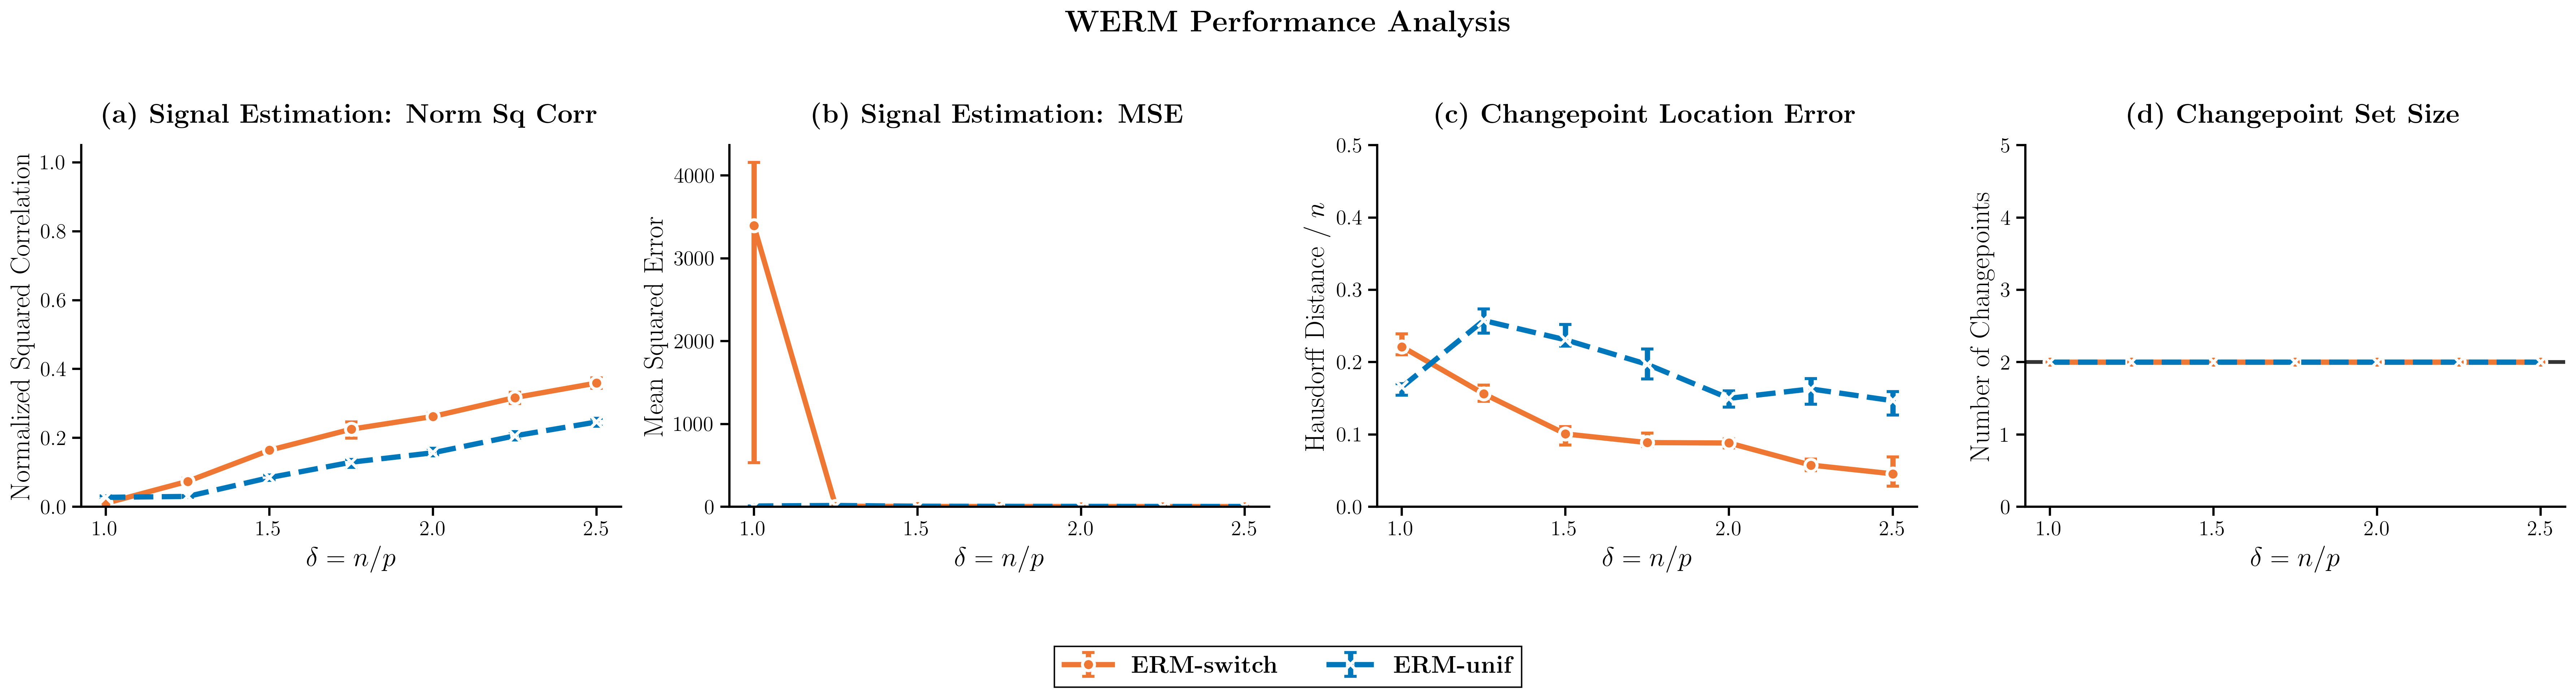

2. Confidence bands (publication style)...


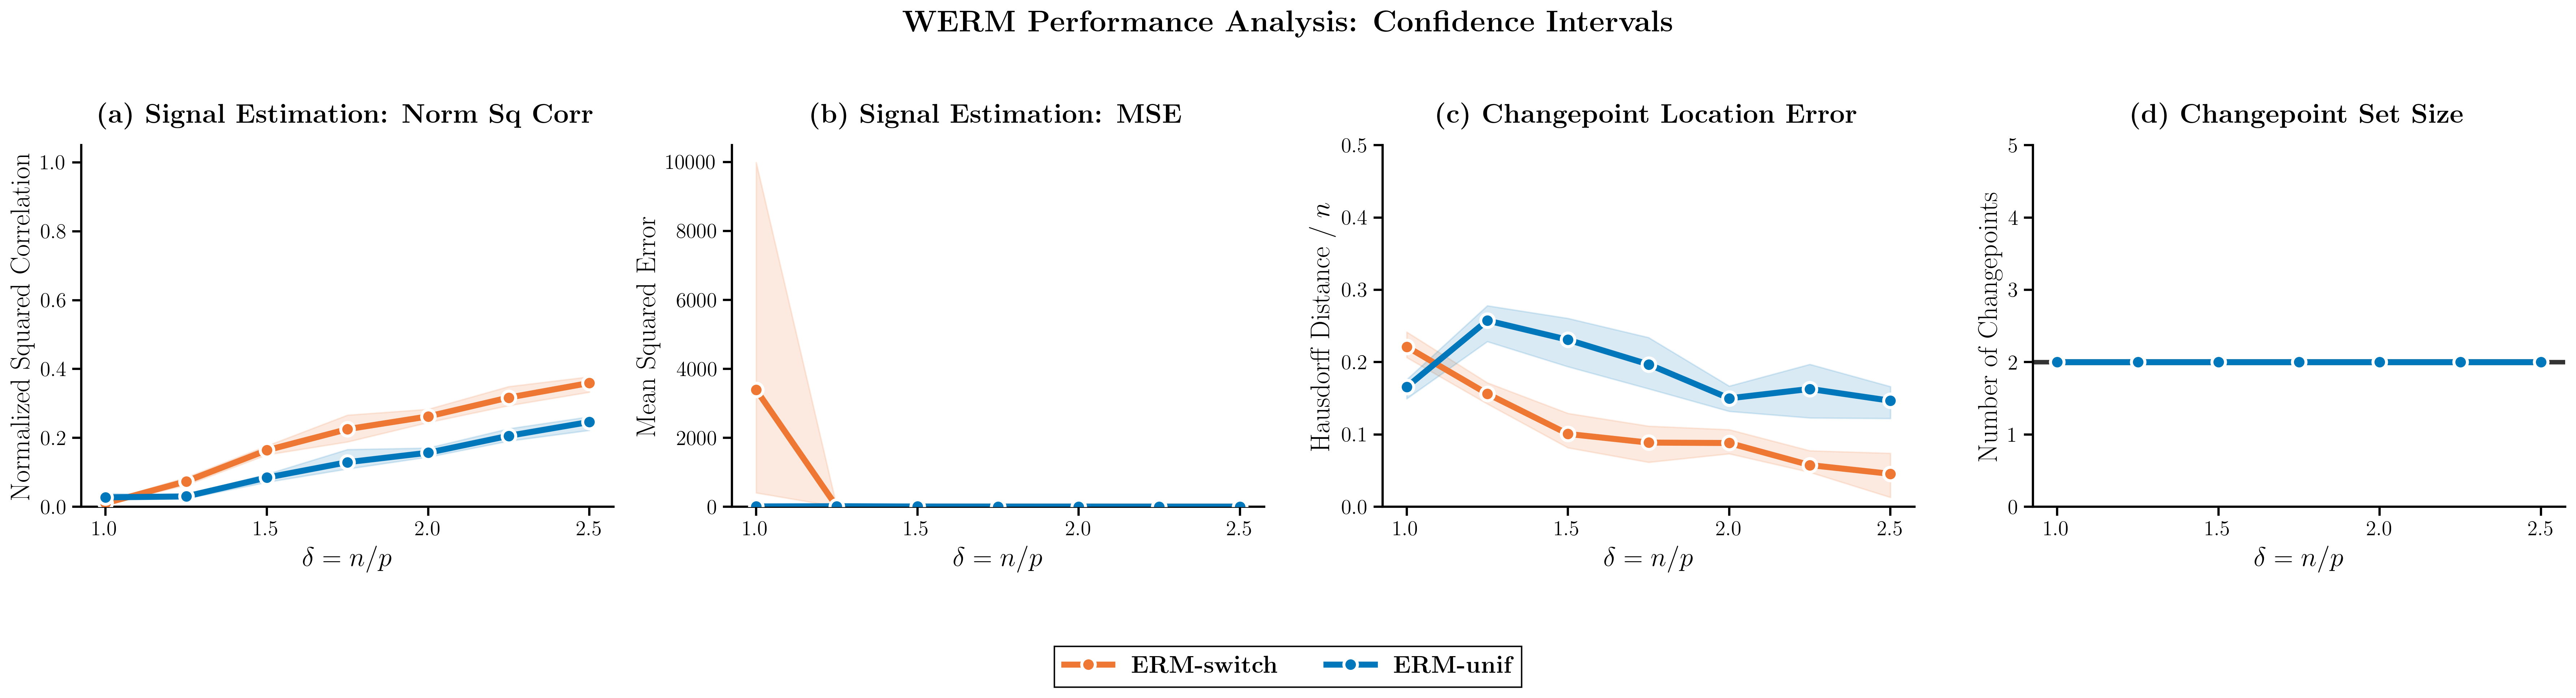

3. Box plots (publication style)...


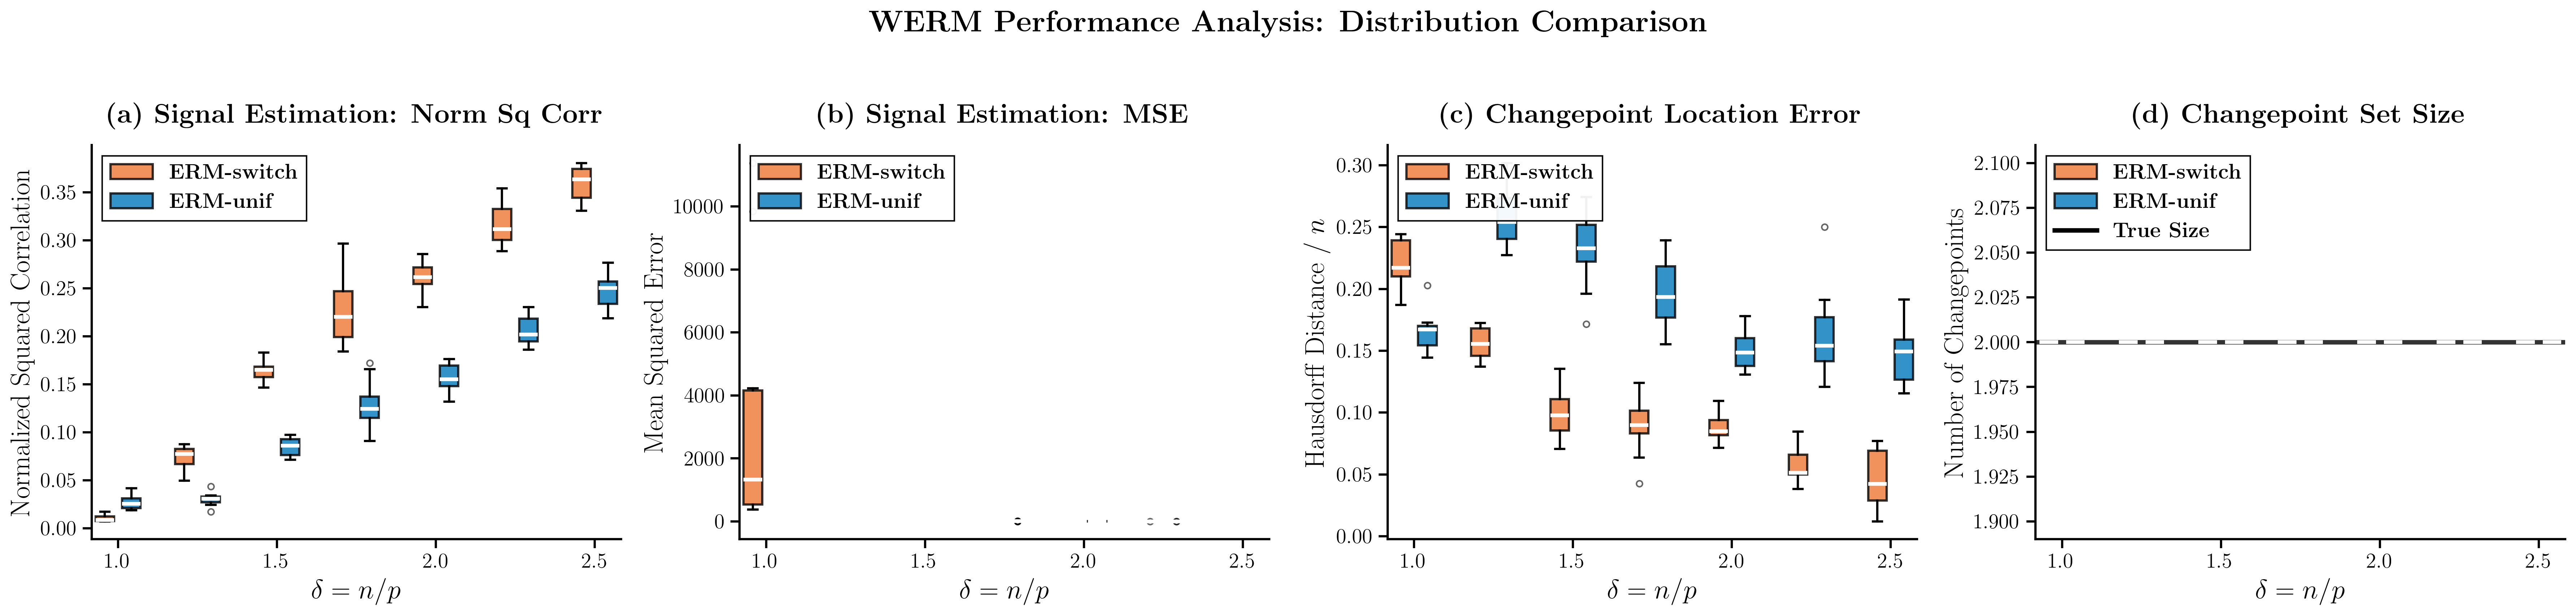

4. Enhanced changepoint histograms (publication style)...


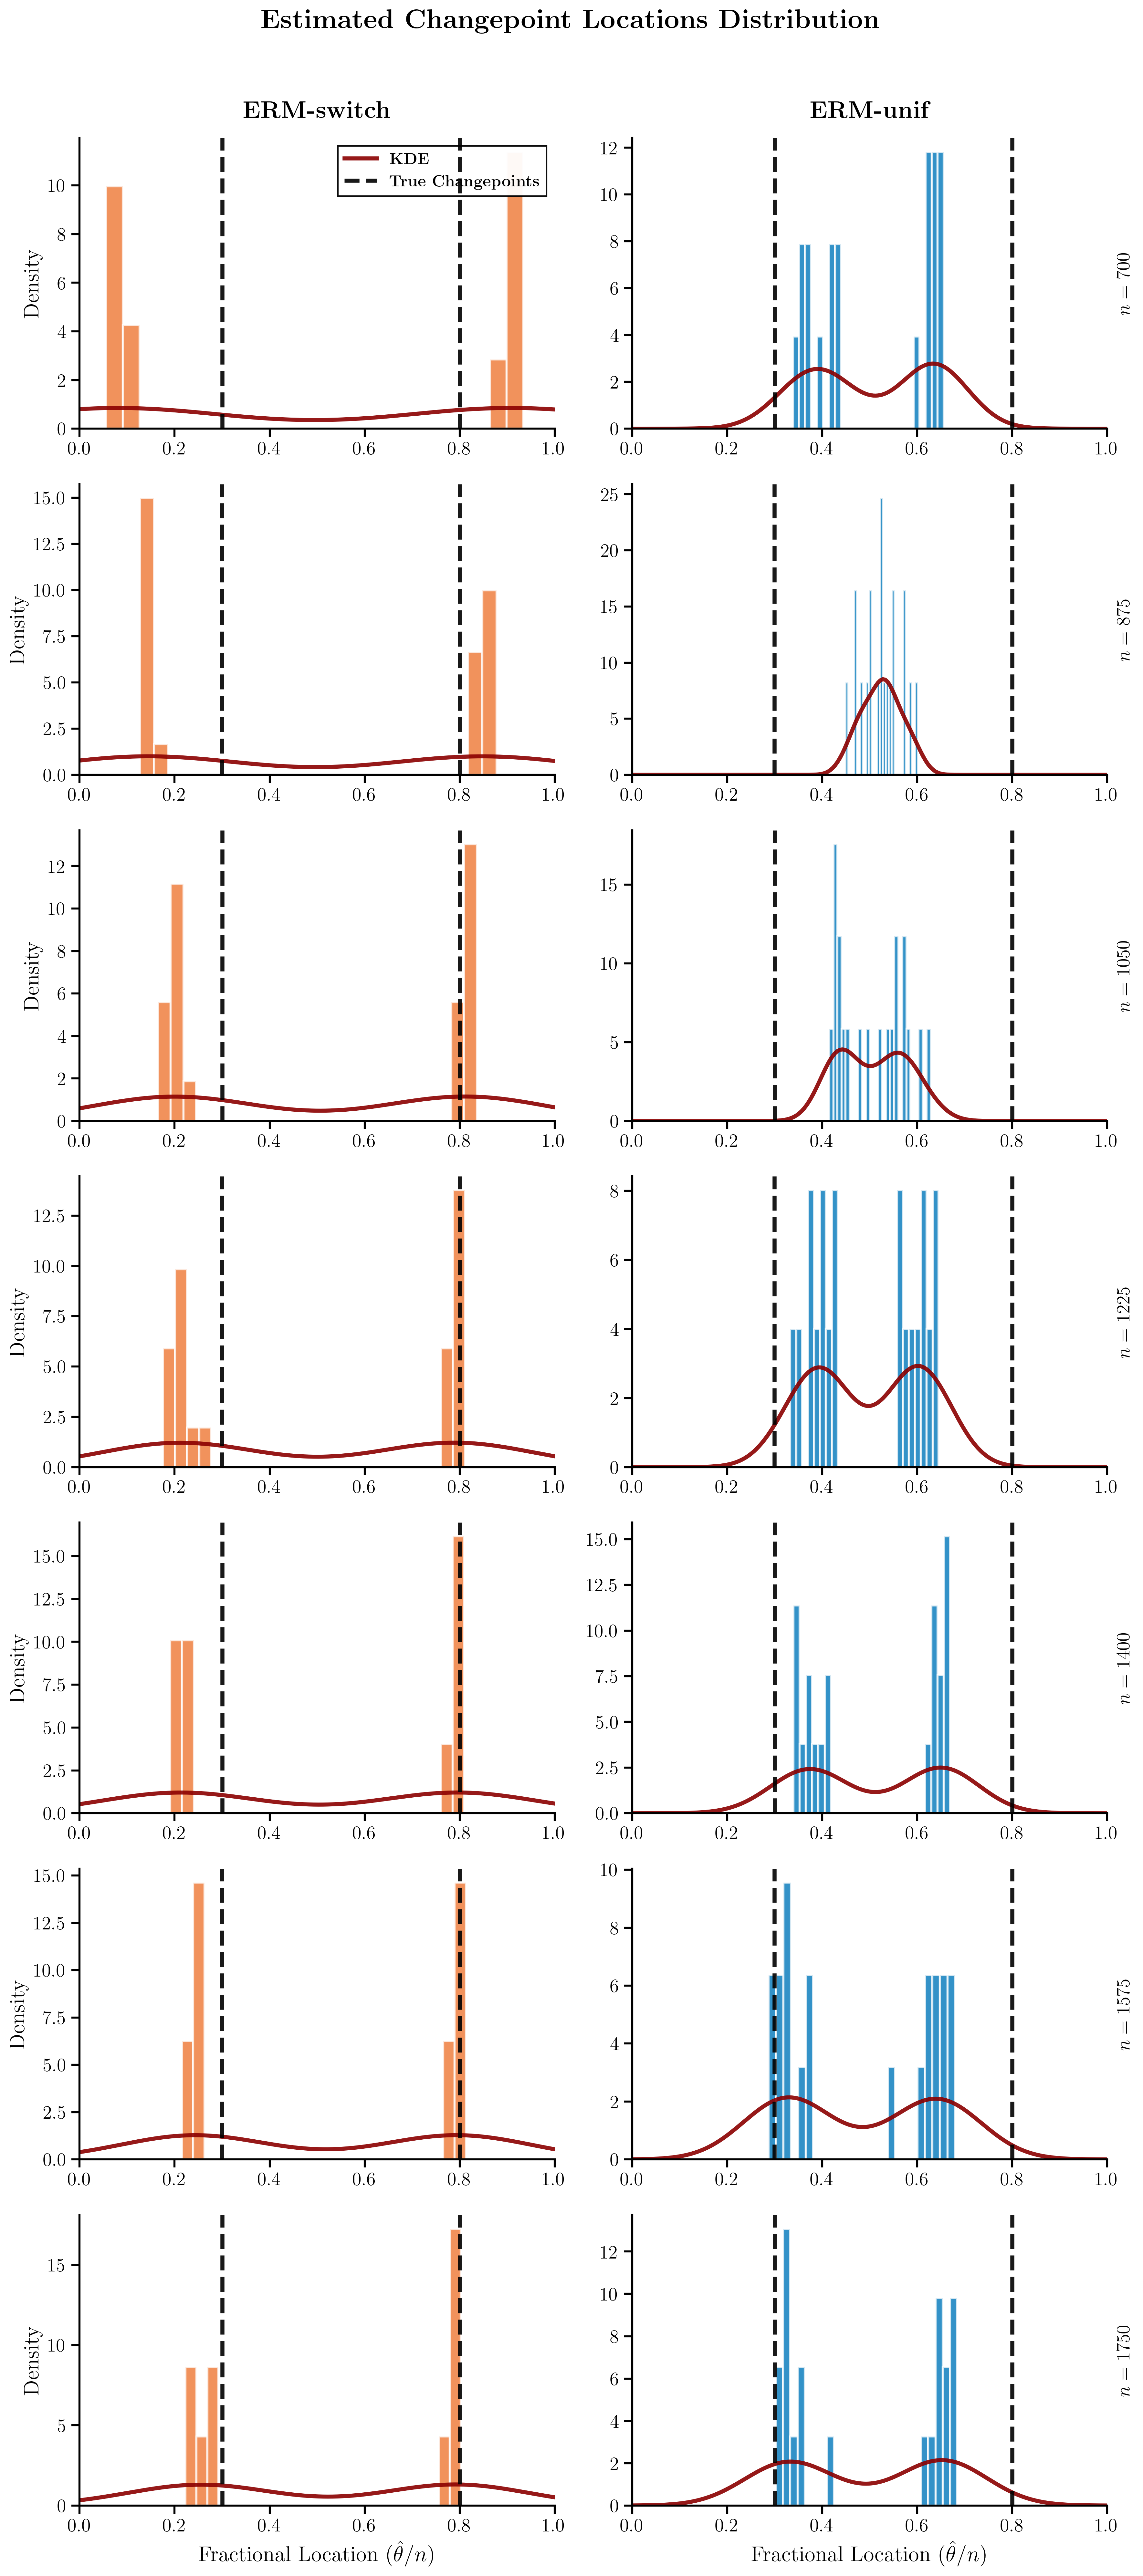

02:57:04 - Publication-ready plotting completed in 4.13 seconds


In [ ]:
# --- Publication-Ready Enhanced Plotting Results ---
plt.rcParams.update({
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': False,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 3.0,
    'lines.markersize': 8,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

main_logger.info("Creating publication-ready plots...")
plotting_start_time = time.time()

# Paul Tol "Vibrant" - optimal balance of aesthetics and accessibility
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB', '#FF8800', '#DDAA33', '#BBCC33']
PAL = TOL_VIBRANT

# Ensure colors are assigned from the palette in order
for i, method_obj in enumerate(methods_to_evaluate):
    method_obj['color'] = PAL[i % len(PAL)] # Cycle through colors if more methods than palette entries

print(f"Using palette: {[m['color'] for m in methods_to_evaluate]} (Paul Tol Vibrant assigned to methods)")

def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=1)
    p25 = np.nanpercentile(data, 25, axis=1)
    p75 = np.nanpercentile(data, 75, axis=1)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

# --- Publication-Ready Asymmetric Error Bars Plots ---
def plot_with_asymmetric_errors_publication():
    fig, axs = plt.subplots(1, 4, figsize=(24, 6)) # Increased columns for all 4 metrics
    fig.suptitle(r'\textbf{WERM Performance Analysis}', fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    # Metrics to plot
    metrics = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}', (0, 1.05)),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}', None),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}', (0, 0.5)),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}', (0, L + 2))
    ]

    for ax_idx, (metric_key, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]
        for i, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            data = results[f'{metric_key}_{method_name}']
            if metric_key in ['corr', 'mse']:
                # For correlation and MSE, average over the L signals first
                data = np.nanmean(data, axis=2) # Average across L signals
            if np.all(np.isnan(data)):
                main_logger.warning(f"No successful trials for {method_name} ({metric_key}). Skipping plot for this metric.")
                continue
            means = np.nanmean(data, axis=1)
            errors = get_asymmetric_errors(data)
            ax.errorbar(δ_list, means, yerr=errors,
                        label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                        color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                        linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
        
        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
        
        if ylim:
            ax.set_ylim(ylim)
        elif metric_key in ['haus']:
            ax.set_ylim(bottom=0, top=0.2)
        else: # For MSE and Runtime, ensure y-axis starts at 0
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods_to_evaluate) + (1 if 'size' in [m[0] for m in metrics] else 0),
               fontsize=16, frameon=True, edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Publication-Ready Confidence Bands Plots ---
def plot_with_confidence_bands_publication():
    fig, axs = plt.subplots(1, 4, figsize=(24, 6))
    fig.suptitle(r'\textbf{WERM Performance Analysis: Confidence Intervals}',
                 fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}', (0, 1.05)),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}', None),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}', (0, 0.5)),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}', (0, L + 2))
    ]

    for ax_idx, (metric_key, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]
        for method_idx, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            data = results[f'{metric_key}_{method_name}']
            if metric_key in ['corr', 'mse']:
                data = np.nanmean(data, axis=2)
            if np.all(np.isnan(data)):
                main_logger.warning(f"No successful trials for {method_name} ({metric_key}). Skipping plot for this metric.")
                continue
            means = np.nanmean(data, axis=1)
            p10 = np.nanpercentile(data, 10, axis=1)
            p90 = np.nanpercentile(data, 90, axis=1)
            p10 = np.minimum(p10, means) # Ensure band doesn't go above mean for lower bound
            p90 = np.maximum(p90, means) # Ensure band doesn't go below mean for upper bound

            ax.fill_between(δ_list, p10, p90, color=plot_colors[method_idx],
                            alpha=0.15, zorder=1)
            ax.plot(δ_list, means, color=plot_colors[method_idx], linewidth=4,
                    marker='o', markersize=9, label=plot_labels[method_idx], zorder=3,
                    markeredgewidth=2, markeredgecolor='white')

        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}', zorder=2)
        if ylim:
            ax.set_ylim(ylim)
        elif metric_key in ['mse', 'runtime']:
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods_to_evaluate) + (1 if 'size' in [m[0] for m in metrics] else 0),
               fontsize=16, frameon=True, edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Publication-Ready Box Plots ---
def plot_with_boxplots_publication():
    fig, axs = plt.subplots(1, 4, figsize=(24, 6)) # Adjusted for 4 metrics
    fig.suptitle(r'\textbf{WERM Performance Analysis: Distribution Comparison}',
                 fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}'),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}'),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}'),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}')
    ]

    for ax_idx, (metric_key, ylabel, title) in enumerate(metrics):
        ax = axs[ax_idx]
        spacing = len(methods_to_evaluate) + 1
        for delta_idx, delta in enumerate(δ_list):
            box_data = []
            box_positions = []
            box_colors = []
            for method_idx, method_obj in enumerate(methods_to_evaluate):
                method_name = method_obj['name']
                data = results[f'{metric_key}_{method_name}'][delta_idx, :]
                if metric_key in ['corr', 'mse']:
                    # Take nanmean across L signals for corr/mse before plotting
                    data_flattened = np.nanmean(data, axis=1) # Results in a 1D array per trial
                else:
                    data_flattened = data

                valid_data = data_flattened[~np.isnan(data_flattened)]
                if len(valid_data) > 0:
                    box_data.append(valid_data)
                    box_positions.append(delta_idx * spacing + method_idx)
                    box_colors.append(plot_colors[method_idx])
                else:
                    main_logger.warning(f"No valid data for {method_name} for delta {delta:.1f} ({metric_key}). Skipping box plot for this point.")

            if len(box_data) > 0:
                bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                                patch_artist=True, showfliers=True,
                                flierprops=dict(marker='o', markersize=4, alpha=0.6),
                                medianprops=dict(color='white', linewidth=2.5),
                                boxprops=dict(linewidth=1.5),
                                whiskerprops=dict(linewidth=1.5),
                                capprops=dict(linewidth=1.5))
                for patch, color in zip(bp['boxes'], box_colors):
                    patch.set_facecolor(color)
                    patch.set_alpha(0.8)
                    patch.set_edgecolor('black')

        delta_positions = [i * spacing + (len(methods_to_evaluate) - 1) / 2 for i in range(len(δ_list))]
        ax.set_xticks(delta_positions[::2])
        ax.set_xticklabels([f'{d:.1f}' for d in δ_list[::2]])
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)

        legend_elements = [plt.Rectangle((0,0),1,1, facecolor=plot_colors[i],
                                         alpha=0.8, edgecolor='black',
                                         linewidth=1.5, label=plot_labels[i])
                                        for i in range(len(methods_to_evaluate))]
        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}')
            legend_elements.append(plt.Line2D([0], [0], color='black', lw=3, linestyle='-', label=r'\textbf{True Size}'))

        ax.legend(handles=legend_elements, loc='upper left', fontsize=14,
                  frameon=True, edgecolor='black', framealpha=0.95)

        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# --- Publication-Ready Changepoint Histograms ---
def plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, methods_to_plot_names):
    """
    Publication-ready changepoint location histograms
    """
    method_plotting_info = {m['name']: {'label': m['label'], 'color': m['color']} for m in methods_to_evaluate}

    selected_deltas_idx = list(range(len(δ_list)))
    selected_deltas = δ_list
    
    fig, axes = plt.subplots(len(selected_deltas), len(methods_to_plot_names),
                             figsize=(6 * len(methods_to_plot_names), 4 * len(selected_deltas)))

    if len(selected_deltas) == 1 and len(methods_to_plot_names) == 1:
        axes = np.array([[axes]])
    elif len(methods_to_plot_names) == 1:
        axes = axes.reshape(-1, 1)
    elif len(selected_deltas) == 1:
        axes = axes.reshape(1, -1)

    fig.patch.set_facecolor('white')
    fig.suptitle(r'\textbf{Estimated Changepoint Locations Distribution}',
                 fontsize=20, y=0.98)

    for row, (delta_idx, delta) in enumerate(zip(selected_deltas_idx, selected_deltas)):
        n = int(delta * p)
        for col, method_name in enumerate(methods_to_plot_names):
            ax = axes[row, col]
            ax.set_facecolor('white')

            all_chgpts = []
            for stored_delta_idx, chgpts_data in results[f'chgpts_{method_name}']:
                if stored_delta_idx == delta_idx:
                    if chgpts_data is not None and len(chgpts_data) > 0 and not (np.isscalar(chgpts_data) and np.isnan(chgpts_data)):
                        chgpts_array = np.array(chgpts_data)
                        valid_chgpts = chgpts_array[chgpts_array != -1]
                        for chgpt in valid_chgpts:
                            fractional_chgpt = chgpt / n
                            all_chgpts.append(fractional_chgpt)

            if len(all_chgpts) > 0:
                ax.hist(all_chgpts, bins=25, alpha=0.8,
                        color=method_plotting_info[method_name]['color'],
                        density=True, edgecolor='white', linewidth=1.5)
                if len(all_chgpts) > 8: # Only plot KDE if enough samples
                    from scipy.stats import gaussian_kde
                    kde = gaussian_kde(all_chgpts)
                    x_range = np.linspace(0, 1, 200)
                    kde_values = kde(x_range)
                    ax.plot(x_range, kde_values, color='darkred', linewidth=3,
                            alpha=0.9, label=r'\textbf{KDE}')
            else:
                ax.text(0.5, 0.5, r'\textit{No changepoints detected or method failed}',
                        transform=ax.transAxes, ha='center', va='center',
                        fontsize=14, alpha=0.7, style='italic')

            current_true_chgpts = None
            # Find the true changepoints for the current delta_idx
            for stored_delta_idx, true_chgpts_data in results['true_chgpts']:
                if stored_delta_idx == delta_idx:
                    current_true_chgpts = true_chgpts_data
                    break
            
            if current_true_chgpts is not None and len(current_true_chgpts) > 0:
                for i_true, true_chgpt in enumerate(current_true_chgpts):
                    fractional_true_chgpt = true_chgpt / n
                    ax.axvline(x=fractional_true_chgpt, color='black', linestyle='--', linewidth=3,
                               alpha=0.9, zorder=10,
                               label=r'\textbf{True Changepoints}' if i_true == 0 else "")
            ax.set_xlim(0, 1)

            if row == len(selected_deltas)-1:
                ax.set_xlabel(r'Fractional Location ($\hat{\theta}/n$)', fontsize=16)
            if col == 0:
                ax.set_ylabel(r'Density', fontsize=16)

            if row == 0:
                ax.set_title(f'{method_plotting_info[method_name]["label"]}', fontsize=18, pad=15)

            if col == len(methods_to_plot_names)-1:
                ax.text(1.02, 0.5, f'$n = {n}$', transform=ax.transAxes,
                        rotation=90, verticalalignment='center', fontsize=14,
                        fontweight='bold')

            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)

            # Only show legend on the first subplot where a KDE is plotted, or for true changepoints
            if row == 0 and col == 0 and (len(all_chgpts) > 0 or (current_true_chgpts is not None and len(current_true_chgpts) > 0)):
                handles, labels = ax.get_legend_handles_labels()
                # Remove duplicate "True Changepoints" labels if present
                unique_labels = {}
                for handle, label in zip(handles, labels):
                    if label not in unique_labels:
                        unique_labels[label] = handle
                ax.legend(unique_labels.values(), unique_labels.keys(), loc='upper right', fontsize=12, frameon=True,
                                 edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    plt.show()

# Execute publication-ready plotting options
main_logger.info("Generating plots...")
print("1. Asymmetric error bars (publication style)...")
plot_with_asymmetric_errors_publication()
print("2. Confidence bands (publication style)...")
plot_with_confidence_bands_publication()
print("3. Box plots (publication style)...")
plot_with_boxplots_publication()
print("4. Enhanced changepoint histograms (publication style)...")
plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, method_names_list)
plotting_time = time.time() - plotting_start_time
main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

# # Save results to a file
# method_names_for_filename = '_'.join(method['name'] for method in methods_to_evaluate)
# filename = f"results/WERM_SE_match_est_switching_{method_names_for_filename}_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}_deltas_{'_'.join(map(str, map(int, δ_list)))}.pkl"

# # Create results directory if it doesn't exist
# results_dir = 'results'
# if not os.path.exists(results_dir):
#     os.makedirs(results_dir)

# with open(filename, 'wb') as f:
#     pickle.dump({
#         'results': results,
#         'params': {
#             'p': p,
#             'L': L,
#             'noise_std': noise_std,
#             'δ_list': δ_list,
#             'num_trials': num_trials,
#             'fractional_chgpt_locations': fractional_chgpt_locations,
#             'n_jobs': n_jobs,
#             'successful_trials_counts': results['successful_trials'],
#             'methods_evaluated': methods_to_evaluate,
#             'random_seed': random_seed
#         }
#     }, f)
# main_logger.info(f"Results saved to {filename}")

03:44:38 - Starting WERM Simulation with parallel execution and enhanced logging
03:44:38 - ================================================================================
B̃_cov:
[[0.09   0.009  0.0891]
 [0.009  0.09   0.009 ]
 [0.0891 0.009  0.09  ]]
03:44:38 - Simulation Parameters:
03:44:38 -  p (features): 700
03:44:38 -  L (signals): 3
03:44:38 -  noise_std: 0.31622776601683794
03:44:38 -  δ_list: [2.25 2.5  2.75 3.   3.25]
03:44:38 -  num_trials: 30
03:44:38 -  fractional_chgpt_locations: [0.3 0.8]
03:44:38 -  n_jobs: 45
03:44:38 -  Loss function: Least Squares
03:44:38 -  Methods to evaluate: ['ERM-switch', 'Theory-switch', 'ERM-unif', 'Theory-unif']
03:44:38 -  Total tasks: 150
03:44:38 - ================================================================================
03:44:38 - Starting 150 simulation trials
03:44:38 - Using 45 CPU cores
03:44:38 - Estimated total time: 1.1 minutes
03:44:38 - Estimated completion: 2025-07-13 03:45:45
03:44:38 - ==============================

Running simulation trials:   0%|                                            | 0/150 [00:00<?, ?it/s]

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
  0%|          | 0/1 [00:00<?, ?it/s]An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.

100%|██████████| 1/1 [00:00<00:00,  6.07it/s]
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
  0%|          | 0/1 [00:00<?, ?it/s]

\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3



  0%|          | 0/1 [00:00<?, ?it/s]An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.

100%|██████████| 1/1 [00:00<00:00,  6.53it/s]
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.

100%|██████████| 1/1 [00:00<00:00,  6.45it/s]
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
100%|██████████| 1/1 [00:00<00:00,  6.46it/s]
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
  0%|          | 0/1 [00:00<?, ?it/s]An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
100%|██████████| 1/1 [00:00<00:00,  5.95it/s]
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib i

\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, Lmax: 3
\Delta: 4, n: 100, Lmin: 3, 

... (1,367 outputs left out)

Search complete. Optimal GoF score: 89.3470
Search complete. Optimal GoF score: 55.9270


Brute-force Search: 100%|██████████| 143/143 [09:58<00:00,  4.19s/it]


07:26:49 - ================================================================================
07:26:49 - Simulation completed successfully!
07:26:49 - Total simulation time: 222.19 minutes
07:26:49 - Average time per trial: 88.88 seconds
07:26:49 - ================================================================================
07:26:49 - Aggregating results...
07:26:49 - Results aggregation completed in 0.00 seconds
07:26:49 - ========================================
07:26:49 - SIMULATION SUMMARY STATISTICS
07:26:49 - ========================================
07:26:49 - δ = 2.2:
07:26:49 -  ERM-switch - Successful Trials: 30/30
07:26:49 -  ERM-switch - Avg Norm Sq Corr: 0.1621 ± 0.0329
07:26:49 -  ERM-switch - Avg MSE: 0.4091 ± 0.0403
07:26:49 -  ERM-switch - Avg Hausdorff: 0.0704 ± 0.0226
07:26:49 -  ERM-switch - Avg Size: 2.00 ± 0.00
07:26:49 -  ERM-switch - Avg Runtime: 384.99s ± 5.96s
07:26:49 -  Theory-switch - Successful Trials: 30/30
07:26:49 -  Theory-switch - Avg Norm Sq Corr: 0

ValueError: 'yerr' (shape: (2, 30)) must be a scalar or a 1D or (2, n) array-like whose shape matches 'y' (shape: (5,))

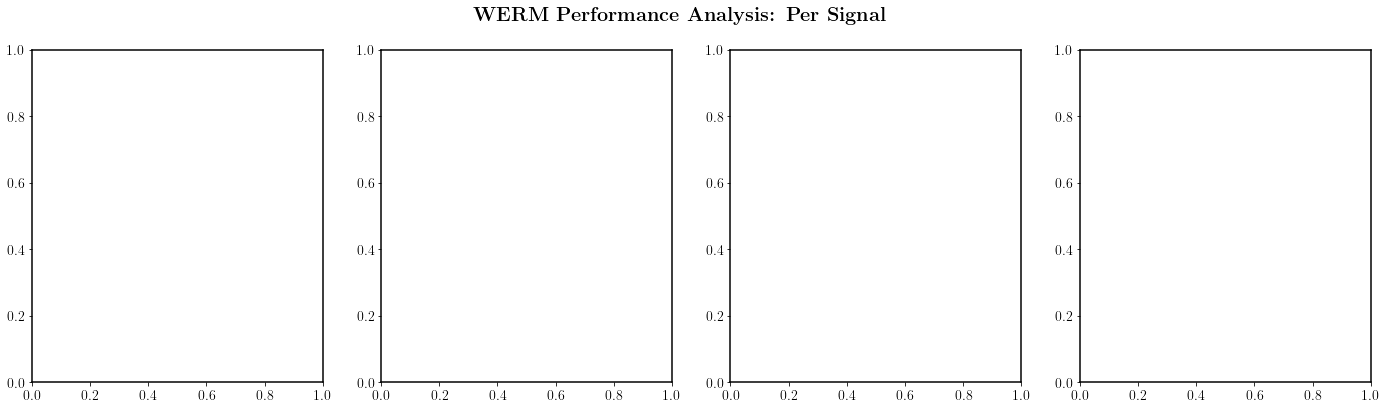

Search complete. Optimal GoF score: 60.1510
Search complete. Optimal GoF score: 132.0278
Search complete. Optimal GoF score: 116.4825
Search complete. Optimal GoF score: 85.1687
Search complete. Optimal GoF score: 62.2808
Search complete. Optimal GoF score: 92.3584
Search complete. Optimal GoF score: 68.9835
Search complete. Optimal GoF score: 105.0910
Search complete. Optimal GoF score: 66.8317
Search complete. Optimal GoF score: 63.4423


In [ ]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
import WERM.model as model
import importlib
import WERM.general_fixed_point_eqns as fp
importlib.reload(fp) # Reload to ensure latest changes are applied
import WERM.M_est_fixed_point_eqns as M_est
import WERM.gof
import WERM.performance_measures
import WERM.marginals
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm.auto import tqdm
import time
from joblib import Parallel, delayed
import logging
from datetime import datetime, timedelta
import sys
import pickle
import os

# Set a random seed for reproducibility
random_seed = 42
nprandom.seed(random_seed)
jax.random.PRNGKey(random_seed) # Set JAX random seed as well

# --- Logging Setup ---
def setup_logging():
    """Setup comprehensive logging for the simulation"""
    detailed_formatter = logging.Formatter(
        '%(asctime)s - %(name)s - %(levelname)s - %(message)s',
        datefmt='%Y-%m-%d %H:%M:%S'
    )
    simple_formatter = logging.Formatter(
        '%(asctime)s - %(message)s',
        datefmt='%H:%M:%S'
    )

    # Create logs directory if it doesn't exist
    import os
    log_dir = 'logs'
    if not os.path.exists(log_dir):
        os.makedirs(log_dir)

    main_logger = logging.getLogger('simulation')
    main_logger.setLevel(logging.INFO)
    main_logger.handlers = [] # Clear existing handlers

    console_handler = logging.StreamHandler(sys.stdout)
    console_handler.setLevel(logging.INFO)
    console_handler.setFormatter(simple_formatter)
    main_logger.addHandler(console_handler)

    file_handler = logging.FileHandler('logs/WERM_SE_match_huber.log', mode='w')
    file_handler.setLevel(logging.DEBUG)
    file_handler.setFormatter(detailed_formatter)
    main_logger.addHandler(file_handler)

    progress_logger = logging.getLogger('progress')
    progress_logger.setLevel(logging.INFO)
    progress_logger.handlers = [] # Clear existing handlers

    progress_handler = logging.FileHandler('logs/WERM_SE_match_huber_progress.log', mode='w')
    progress_handler.setLevel(logging.INFO)
    progress_handler.setFormatter(detailed_formatter)
    progress_logger.addHandler(progress_handler)

    return main_logger, progress_logger

# Initialize loggers
main_logger, progress_logger = setup_logging()

class ProgressTracker:
    """Class to track and log simulation progress"""
    def __init__(self, total_tasks, delta_list, num_trials, logger):
        self.total_tasks = total_tasks
        self.delta_list = delta_list
        self.num_trials = num_trials
        self.logger = logger
        self.start_time = time.time()
        self.completed_tasks = 0
        self.delta_progress = {i: 0 for i in range(len(delta_list))}

    def update(self, delta_idx):
        """Update progress for a completed task"""
        self.completed_tasks += 1
        percent_complete = (self.completed_tasks / self.total_tasks) * 100
        elapsed_time = time.time() - self.start_time

        if self.completed_tasks > 0:
            avg_time_per_task = elapsed_time / self.completed_tasks
            remaining_tasks = self.total_tasks - self.completed_tasks
            estimated_remaining_time = remaining_tasks * avg_time_per_task
            estimated_completion = datetime.now() + timedelta(seconds=estimated_remaining_time)

            self.logger.info(
                f"Progress: {self.completed_tasks}/{self.total_tasks} ({percent_complete:.1f}%) | "
                f"Elapsed: {elapsed_time:.1f}s | "
                f"Est. remaining: {estimated_remaining_time:.1f}s | "
                f"Est. completion: {estimated_completion.strftime('%H:%M:%S')}"
            )

        self.delta_progress[delta_idx] += 1
        # Log delta-specific progress less frequently to avoid excessive logging
        if self.completed_tasks % max(1, self.total_tasks // 10) == 0 or self.completed_tasks == 1 or self.completed_tasks == self.total_tasks:
            delta_status = []
            for i, delta in enumerate(self.delta_list):
                progress = self.delta_progress[i]
                delta_status.append(f"δ={delta:.1f}: {progress}/{self.num_trials}")
            self.logger.info("Delta progress: " + " | ".join(delta_status))

# Global progress tracker (initialized later)
progress_tracker = None

# --- Helper Function for a Single Parallel Job ---
def run_single_trial(params, p, L, noise_std, fractional_chgpt_locations, M, method_configs, B̃):
    """
    Executes a single simulation trial for a given delta, running multiple methods.
    This function is designed to be called in parallel by joblib.
    """
    global progress_tracker
    i, δ, j = params # i: delta_list index, δ: current delta value, j: trial number
    trial_start_time = time.time()

    progress_logger.info(f"Starting trial {j+1}/{num_trials} for δ={δ:.1f} (delta_idx={i})")

    # --- Setup based on delta ---
    n = int(δ * p)
    if fractional_chgpt_locations.size != 0:
        true_chgpt_locations = lambda n_len: (n_len * fractional_chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
    else:
        true_chgpt_locations = lambda n_len: np.array([])
        C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0.

    # --- Preliminaries (from original code) ---
    # --- Compute weights as marginals of prior --- #
    Δ = lambda n: int(n/20)
    Delta_n = int(Δ(n))
    L_is_upper_bound = False
    if Delta_n ==1 : # No separation between change points, so use analytical binomial approximation. 
        if L_is_upper_bound:
            pi_i_l = lambda L, l, i : 1/(L - l + 1) * np.sum([scipy.special.comb(k - 1, l- 1, exact=False) * (i/n)**(l-1) * (1 - i/n)**(k-l) for k in range(l, L+1)])
        else: 
            pi_i_l = lambda L,l , i: scipy.special.comb(L-1, l-1, exact=False) * (i/n)**(l-1) * (1 - i/n)**(L-l)
        # Populate the pi L times n matrix
        pi = np.zeros((L, n))
        for l in range(L):
            for i in range(n):
                pi[l, i] = pi_i_l(L, l + 1, i + 1)
    else: 
        n_small = 100
        Delta_n_small = int(Delta_n * n_small/n)
        if L_is_upper_bound: 
            p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
            Lmin = 1
            Lmax = L
        else:
            p_l = None
            Lmin = L
            Lmax = L
        pi = WERM.config.extrapolated_marginals(Lmin, Lmax, Delta_n_small, n_small = n_small, n_large = n, p_l = p_l, verbose = False)
    π = pi
    if L == 1: 
        π = np.ones((1, n))
    π = π / np.sum(π, axis=1, keepdims=True)  # Normalize the weights

    pi_switch = π.copy() # This is the switch matrix, which is the same as π in this case.
    pi_switch[0, :] = π[0, :].copy() + π[2, :].copy()
    pi_switch[2, :] = π[0, :].copy() + π[2, :].copy()
    pi_switch = pi_switch / np.sum(pi_switch, axis=1, keepdims=True) # Normalize the switch matrix

    # --- Data Generation for this trial ---
    data_gen_start = time.time()
    X = nprandom.normal(0, np.sqrt(1/n), (n, p))
    X = X @ Sigma_chol.T
    ε = nprandom.randn(n) * noise_std
    # ε = np.random.standard_t(5, size=(n, )) * noise_std # For Huber loss, use t-distribution for noise. df > 2 has finite variance.
    B̃ = np.sqrt(δ) * B̃ # Scale B̃ by sqrt(delta) here since we vary delta, see the definition of B̃ outside of loop. 
    Θ = X @ B̃
    y_mapped_fn = jax.vmap(model.q_linear_model, in_axes=(0, 0, 0))
    y = y_mapped_fn(Θ, C_true, ε)
    data_gen_time = time.time() - data_gen_start

    trial_results = {}
    methods_status = {method_name: False for method_name in method_configs.keys()}

    # Compute fixed point solution once per delta for theoretical comparison
    ρ = (1/δ) * (1/p) * (B̃.T @ Sigma_chol @ Sigma_chol.T @ B̃)

    # --- Run Estimators for all configured methods ---
    for method_name, method_func_info in method_configs.items():
        try:
            method_start = time.time()
            current_B̂ = np.zeros((p, L))
            Θ̂_theory = np.zeros((n, L))
            current_corr_list = []
            current_mse_list = []
            current_chgpt_loc = np.array([])

            if method_name == 'ERM-switch':
                for ℓ_ in range(L):
                    sample_weight = pi_switch[ℓ_, :] 
                    empirical_risk = lambda β: jnp.multiply(M((X @ β).flatten(), y.flatten()), sample_weight).sum()
                    res = scipy.optimize.minimize(empirical_risk, 0.1*np.ones(p), jac=jax.grad(empirical_risk), method='L-BFGS-B')
                    β̂ = res.x
                    current_B̂[:, ℓ_] = β̂
                    current_corr_list.append(WERM.norm_sq_corr(β̂, B̃[:, ℓ_]))
                    current_mse_list.append(WERM.MSE(β̂.flatten(), B̃[:, ℓ_]))
                # Determine changepoints for ERM
                opt_chgpt_loc_erm, _ = WERM.gof.chgpt_gof_bf_mem_eff(
                    M, X @ current_B̂, y, n, L, Δ(n), L_is_upper_bound=False,
                    γ=0, batch_size=batch_size, gof_opt_output=True
                )
                # opt_chgpt_loc_erm, _ = WERM.gof.chgpt_binary_segmentation(
                #     M, X @ current_B̂, y, n, L, Δ(n), L_is_upper_bound=False,
                #     γ=0, gof_opt_output=True
                # )
                current_chgpt_loc = opt_chgpt_loc_erm

            elif method_name == 'Theory-switch':

                b, ν̃, κ̃ = fp.general_fp(M, ρ, δ, true_chgpt_locations(n), pi_switch, ε, n, model.q_linear_model)
                κ̃_sqrt = jnp.linalg.cholesky(κ̃ + 1e-12 * jnp.eye(L))
                print("-"*60)
                print("b, ν̃, κ̃ for δ=", δ, ":", b, ν̃, κ̃, ", trial : ", j+1)
                print("-"*60)
                G_sample = nprandom.multivariate_normal(np.zeros((L, )), np.eye(L), size=(p,)) @ κ̃_sqrt.T
                G_sample_n = nprandom.multivariate_normal(np.zeros((L, )), np.eye(L), size=(n,)) @ κ̃_sqrt.T
                Z = nprandom.multivariate_normal(np.zeros((L, )), ρ, size=(n,))
                y_theory = y_mapped_fn(Z, C_true, ε) 
                M_prime = jax.grad(M, argnums=0)
                M_double_prime = jax.grad(M_prime, argnums=0)
                for ℓ_ in range(L):
                    β̂_theory = B̃ @ ν̃[:, ℓ_] + δ**(1/2) * np.linalg.inv(Sigma_chol).T @ G_sample[:, ℓ_]
                    current_B̂[:, ℓ_] = β̂_theory
                    current_corr_list.append(WERM.norm_sq_corr(β̂_theory, B̃[:, ℓ_]))
                    current_mse_list.append(WERM.MSE(β̂_theory.flatten(), B̃[:, ℓ_]))
                    
                    sample_weight = pi_switch[ℓ_, :]
                    prox_mapped = lambda z, b, π_i, v: jax.vmap(fp.prox, in_axes=(0, None, 0, 0, None, None))(z, b, π_i, v, M_prime, M_double_prime)
                    Θ̂_theory[:, ℓ_] = prox_mapped(Z @ ν̃[:, ℓ_] + G_sample_n[:, ℓ_], b[ℓ_], sample_weight, y_theory)

                # Determine changepoints for Theory
                opt_chgpt_loc_theory, _ = WERM.gof.chgpt_gof_bf_mem_eff(
                    M, Θ̂_theory, y_theory, n, L, Δ(n), L_is_upper_bound=False,
                    γ=0, batch_size=batch_size, gof_opt_output=True
                )
                current_chgpt_loc = opt_chgpt_loc_theory

            elif method_name == 'ERM-unif':
                for ℓ_ in range(L):
                    sample_weight = π[ℓ_, :]
                    empirical_risk = lambda β: jnp.multiply(M((X @ β).flatten(), y.flatten()), sample_weight).sum()
                    res = scipy.optimize.minimize(empirical_risk, 0.1*np.ones(p), jac=jax.grad(empirical_risk), method='L-BFGS-B')
                    β̂ = res.x
                    current_B̂[:, ℓ_] = β̂
                    current_corr_list.append(WERM.norm_sq_corr(β̂, B̃[:, ℓ_]))
                    current_mse_list.append(WERM.MSE(β̂.flatten(), B̃[:, ℓ_]))
                # Determine changepoints for ERM
                opt_chgpt_loc_erm, _ = WERM.gof.chgpt_gof_bf_mem_eff(
                    M, X @ current_B̂, y, n, L, Δ(n), L_is_upper_bound=False,
                    γ=0, batch_size=batch_size, gof_opt_output=True
                )
                # opt_chgpt_loc_erm, _ = WERM.gof.chgpt_binary_segmentation(
                #     M, X @ current_B̂, y, n, L, Δ(n), L_is_upper_bound=False,
                #     γ=0, gof_opt_output=True
                # )
                current_chgpt_loc = opt_chgpt_loc_erm

            elif method_name == 'Theory-unif':
                b, ν̃, κ̃ = fp.general_fp(M, ρ, δ, true_chgpt_locations(n), π, ε, n, model.q_linear_model)
                κ̃_sqrt = jnp.linalg.cholesky(κ̃ + 1e-12 * jnp.eye(L))
                print("-"*60)
                print("b, ν̃, κ̃ for δ=", δ, ":", b, ν̃, κ̃, ", trial : ", j+1)
                print("-"*60)

                G_sample = nprandom.multivariate_normal(np.zeros((L, )), np.eye(L), size=(p,)) @ κ̃_sqrt.T
                G_sample_n = nprandom.multivariate_normal(np.zeros((L, )), np.eye(L), size=(n,)) @ κ̃_sqrt.T
                Z = nprandom.multivariate_normal(np.zeros((L, )), ρ, size=(n,))
                y_theory = y_mapped_fn(Z, C_true, ε) 
                M_prime = jax.grad(M, argnums=0)
                M_double_prime = jax.grad(M_prime, argnums=0)
                for ℓ_ in range(L):
                    β̂_theory = B̃ @ ν̃[:, ℓ_] + δ**(1/2) * np.linalg.inv(Sigma_chol).T @ G_sample[:, ℓ_]
                    current_B̂[:, ℓ_] = β̂_theory
                    current_corr_list.append(WERM.norm_sq_corr(β̂_theory, B̃[:, ℓ_]))
                    current_mse_list.append(WERM.MSE(β̂_theory.flatten(), B̃[:, ℓ_]))
                    
                    sample_weight = π[ℓ_, :]
                    prox_mapped = lambda z, b, π_i, v: jax.vmap(fp.prox, in_axes=(0, None, 0, 0, None, None))(z, b, π_i, v, M_prime, M_double_prime)
                    Θ̂_theory[:, ℓ_] = prox_mapped(Z @ ν̃[:, ℓ_] + G_sample_n[:, ℓ_], b[ℓ_], sample_weight, y_theory)

                # Determine changepoints for Theory
                opt_chgpt_loc_theory, _ = WERM.gof.chgpt_gof_bf_mem_eff(
                    M, Θ̂_theory, y_theory, n, L, Δ(n), L_is_upper_bound=False,
                    γ=0, batch_size=batch_size, gof_opt_output=True
                )
                current_chgpt_loc = opt_chgpt_loc_theory
            else:
                main_logger.warning(f"Method {method_name} not recognized. Skipping.")
                continue

            method_time = time.time() - method_start
            trial_results[f'runtime_{method_name}'] = method_time
            trial_results[f'corr_{method_name}'] = np.array(current_corr_list)
            trial_results[f'mse_{method_name}'] = np.array(current_mse_list)
            trial_results[f'haus_{method_name}'] = (1/n * WERM.performance_measures.hausdorff(current_chgpt_loc, true_chgpt_locations(n)))
            trial_results[f'size_{method_name}'] = len(current_chgpt_loc[current_chgpt_loc != -1])
            trial_results[f'chgpts_{method_name}'] = current_chgpt_loc.copy()
            methods_status[method_name] = True

        except Exception as e:
            main_logger.error(f"Trial {j+1} for δ={δ:.1f}: {method_name} failed with error: {e}", exc_info=True)
            trial_results[f'runtime_{method_name}'] = np.nan
            trial_results[f'corr_{method_name}'] = np.full(L, np.nan)
            trial_results[f'mse_{method_name}'] = np.full(L, np.nan)
            trial_results[f'haus_{method_name}'] = np.nan
            trial_results[f'size_{method_name}'] = np.nan
            trial_results[f'chgpts_{method_name}'] = np.array([])
            methods_status[method_name] = False

    # Store additional info for histogram plotting
    trial_results['n'] = n
    trial_results['true_chgpts'] = true_chgpt_locations(n).copy()
    trial_results['fractional_true_chgpts'] = fractional_chgpt_locations.copy()
    trial_results['methods_status'] = methods_status

    trial_total_time = time.time() - trial_start_time
    log_message_parts = [
        f"Completed trial {j+1} for δ={δ:.1f}: ",
        f"Total={trial_total_time:.1f}s (Data={data_gen_time:.1f}s)"
    ]
    for method_name in method_configs.keys():
        status_str = 'OK' if methods_status[method_name] else 'FAIL'
        runtime_str = f"{trial_results[f'runtime_{method_name}']:.1f}s" if f'runtime_{method_name}' in trial_results and not np.isnan(trial_results[f'runtime_{method_name}']) else "N/A"
        log_message_parts.append(f"{method_name}={status_str} ({runtime_str})")
    progress_logger.info(" ".join(log_message_parts))

    if progress_tracker:
        progress_tracker.update(i)

    return i, j, trial_results

# --- Main Script Setup ---
main_logger.info("Starting WERM Simulation with parallel execution and enhanced logging")
main_logger.info("=" * 80)

# Simulation Parameters
p = 700 # at least 500 is needed for stable results
L = 3 # num signals. L-1 changepoints
noise_std = np.sqrt(0.1) # sqrt(0.5) on gaussian noise to get recent good plot

δ_list = np.arange(2.25, 3.26, 0.25)
num_trials = 10 # Increased for better statistics
fractional_chgpt_locations = np.array([0.3, 0.8]) # [0.2,0.8] gave biggest improvement for ERM-switch. Also noticed big differences in bf vs. non-bf for ERM-switch

n_jobs = 8 # Use all available CPU cores. Set to 1 for no parallelization.

# Least Squares Loss
# M = lambda u, v: jnp.power(u - v, 2)

# # Huber Loss
def M(u, v, epsilon=1.35):
    residual = u - v
    abs_residual = jnp.abs(residual)
    condition = abs_residual <= epsilon
    squared_loss = 0.5 * jnp.square(residual)
    linear_loss = epsilon * (abs_residual - 0.5 * epsilon)
    return jnp.where(condition, squared_loss, linear_loss)

# Sample the signal outside
# κ = 1.0
# B̃_cov = κ**2 * np.eye(L) # Omit the δ term here, multiply it inside of the trial loop since we vary δ
# # Add some correlation between signals for L > 1
# r_B = 0.25
# if L > 1:
#     for ll in range(L):
#         for mm in range(L):
#             if ll != mm:
#                 B̃_cov[ll, mm] = r_B**(abs(ll - mm)) * κ**2
# signal_prior = GaussianSignal(B̃_cov)
# B̃ = signal_prior.sample(p)

# def sample_corr(p, df=10, seed=None):
#     """Sample a random correlation matrix using the Haar measure."""
#     rng = np.random.default_rng(seed)
#     Q, _ = np.linalg.qr(rng.standard_normal((p, p)))           # Haar‐orthogonal
#     λ = rng.chisquare(df, size=p)                              # χ² eigenvalues
#     B = Q.T @ np.diag(λ) @ Q                                   # SPD matrix
#     D = np.sqrt(np.diag(B))
#     return B / np.outer(D, D)

# Sigma = sample_corr(p, df=10, seed=random_seed) 

κ = 0.3 # 1.0 for the second_best plot
B̃_cov = κ**2 * np.eye(L) # Remove the δ term here, multiply it inside of the trial loop since we vary δ
# Make the first and third signals identical
B̃_cov[0, 2] = 0.999 * κ**2 # Covariance between first and third signals, make them not perfectly identical for numerical stability
B̃_cov[2, 0] = 0.999 * κ**2 # Covariance between first and third signals, make them not perfectly identical for numerical stability
B̃_cov[0, 1] = 0.1 * κ**2 # Covariance between first and second signals, was 0.2 for the second_best plot
B̃_cov[1, 0] = 0.1 * κ**2 # Covariance between first and second signals
B̃_cov[1, 2] = 0.1 * κ**2 # Covariance between second and third signals
B̃_cov[2, 1] = 0.1 * κ**2 # Covariance between second and third signals
print(f"B̃_cov:\n{B̃_cov}")
signal_prior = GaussianSignal(B̃_cov)
B̃ = signal_prior.sample(p)

# Set first and last columns of B̃ to one
# B̃[:, 0] = np.ones(p) # First signal is constant
# B̃[:, -1] = np.ones(p) # Last signal is constant

# Draw Sigma from an AR(1) process for some correlation structure r_s = 0.5
r_s = 0.1
AR1 = np.fromfunction(lambda i, j: r_s**(np.abs(i - j)), (p, p))
Sigma = AR1
Sigma_chol = np.linalg.cholesky(Sigma + 1e-12 * np.eye(p)) # Add small ridge for numerical stability

# Load Sigma and B̃ from a precomputed file
# filepath = 'results/WERM_SE_match_est_switching_ERM-LS_Theory-LS_p700_L3_noisestd0.4472135954999579_seed42_deltas_2_3_4_5_6.pkl'
# try:
#     with open(filepath, 'rb') as f:
#         data = pickle.load(f)
#     Sigma = data['params']['Sigma']
#     B̃ = data['params']['B_tilde']
#     main_logger.info(f"Loaded precomputed Sigma and B̃ from {filepath}")
# except FileNotFoundError:
#     main_logger.error(f"File {filepath} not found. Please ensure the file exists or generate it first.")
#     sys.exit(1)
# Sigma = np.eye(p)
# Sigma_chol = np.linalg.cholesky(Sigma + 1e-12 * np.eye(p)) # Add small ridge for numerical stability

batch_size = 4096*4 # Batch size for memory efficient computation of brute force solution

# --- Define Methods to be Evaluated ---
methods_to_evaluate = [
    {'name': 'ERM-switch', 'label': r'\textbf{ERM-switch}', 'color': '#EE7733', 'marker': 'o', 'linestyle': '-'},
    {'name': 'Theory-switch', 'label': r'\textbf{Theory-switch}', 'color': '#0077BB', 'marker': 'D', 'linestyle': '-.'},
    {'name': 'ERM-unif', 'label': r'\textbf{ERM-unif}', 'color': '#EE7733', 'marker': 'x', 'linestyle': '--'},
    {'name': 'Theory-unif', 'label': r'\textbf{Theory-unif}', 'color': '#0077BB', 'marker': '^', 'linestyle': ':'},
]

# Create a dictionary for easy lookup within run_single_trial
method_configs = {method['name']: method for method in methods_to_evaluate}
method_names_list = [m['name'] for m in methods_to_evaluate] # List of just names

# Log simulation parameters
main_logger.info(f"Simulation Parameters:")
main_logger.info(f" p (features): {p}")
main_logger.info(f" L (signals): {L}")
main_logger.info(f" noise_std: {noise_std}")
main_logger.info(f" δ_list: {δ_list}")
main_logger.info(f" num_trials: {num_trials}")
main_logger.info(f" fractional_chgpt_locations: {fractional_chgpt_locations}")
main_logger.info(f" n_jobs: {n_jobs}")
main_logger.info(f" Loss function: Least Squares")
main_logger.info(f" Methods to evaluate: {method_names_list}")
main_logger.info(f" Total tasks: {len(δ_list) * num_trials}")

# Results Storage
results = {
    'successful_trials': {method['name']: np.zeros(len(δ_list), dtype=int) for method in methods_to_evaluate},
    'true_chgpts': [],
    'n_values': [],
    'delta_values': []
}

for method in methods_to_evaluate:
    method_name = method['name']
    results[f'corr_{method_name}'] = np.full((len(δ_list), num_trials, L), np.nan)
    results[f'mse_{method_name}'] = np.full((len(δ_list), num_trials, L), np.nan)
    results[f'haus_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'size_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'runtime_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'chgpts_{method_name}'] = [] # Store (delta_idx, chgpts_array) for histogram plotting


# --- Parallel Execution ---
tasks = [(i, δ, j) for i, δ in enumerate(δ_list) for j in range(num_trials)]
main_logger.info("=" * 80)
main_logger.info(f"Starting {len(tasks)} simulation trials")
main_logger.info(f"Using {n_jobs if n_jobs != -1 else 'all available'} CPU cores")

# Rough estimate for total time, adjust based on typical single trial runtime
single_trial_estimate = 20.0 # seconds, adjust this based on observation
total_estimated_time = len(tasks) * single_trial_estimate / (n_jobs if n_jobs > 0 else 4)
estimated_completion = datetime.now() + timedelta(seconds=total_estimated_time)
main_logger.info(f"Estimated total time: {total_estimated_time/60:.1f} minutes")
main_logger.info(f"Estimated completion: {estimated_completion.strftime('%Y-%m-%d %H:%M:%S')}")
main_logger.info("=" * 80)

progress_tracker = ProgressTracker(len(tasks), δ_list, num_trials, main_logger)
simulation_start_time = time.time()

try:
    parallel_results = Parallel(n_jobs=n_jobs, verbose=0)(
        delayed(run_single_trial)(
            params=task,
            p=p,
            L=L,
            noise_std=noise_std,
            fractional_chgpt_locations=fractional_chgpt_locations,
            M=M,
            method_configs=method_configs,
            B̃=B̃
        ) for task in tqdm(tasks, desc="Running simulation trials", ncols=100, leave=True)
    )
    simulation_end_time = time.time()
    total_simulation_time = simulation_end_time - simulation_start_time
    main_logger.info("=" * 80)
    main_logger.info(f"Simulation completed successfully!")
    main_logger.info(f"Total simulation time: {total_simulation_time/60:.2f} minutes")
    main_logger.info(f"Average time per trial: {total_simulation_time/len(tasks):.2f} seconds")
    main_logger.info("=" * 80)
except Exception as e:
    main_logger.error(f"Simulation failed with error: {str(e)}", exc_info=True)
    raise

# --- Aggregate Results ---
main_logger.info("Aggregating results...")
aggregation_start_time = time.time()

for result_idx, (i, j, trial_result) in enumerate(parallel_results):
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        if trial_result['methods_status'][method_name]:
            results[f'corr_{method_name}'][i, j, :] = trial_result[f'corr_{method_name}']
            results[f'mse_{method_name}'][i, j, :] = trial_result[f'mse_{method_name}']
            results[f'haus_{method_name}'][i, j] = trial_result[f'haus_{method_name}']
            results[f'size_{method_name}'][i, j] = trial_result[f'size_{method_name}']
            results[f'runtime_{method_name}'][i, j] = trial_result[f'runtime_{method_name}']
            results['successful_trials'][method_name][i] += 1
        results[f'chgpts_{method_name}'].append((i, trial_result[f'chgpts_{method_name}'])) # Always append, even if empty

    results['true_chgpts'].append((i, trial_result['true_chgpts']))
    results['n_values'].append((i, trial_result['n']))
    results['delta_values'].append((i, δ_list[i]))

aggregation_time = time.time() - aggregation_start_time
main_logger.info(f"Results aggregation completed in {aggregation_time:.2f} seconds")

# Log summary statistics
main_logger.info("=" * 40)
main_logger.info("SIMULATION SUMMARY STATISTICS")
main_logger.info("=" * 40)
for i, delta in enumerate(δ_list):
    main_logger.info(f"δ = {delta:.1f}:")
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        avg_corr = np.nanmean(results[f'corr_{method_name}'][i, :, :])
        std_corr = np.nanstd(results[f'corr_{method_name}'][i, :, :])
        avg_mse = np.nanmean(results[f'mse_{method_name}'][i, :, :])
        std_mse = np.nanstd(results[f'mse_{method_name}'][i, :, :])
        avg_haus = np.nanmean(results[f'haus_{method_name}'][i, :])
        std_haus = np.nanstd(results[f'haus_{method_name}'][i, :])
        avg_size = np.nanmean(results[f'size_{method_name}'][i, :])
        std_size = np.nanstd(results[f'size_{method_name}'][i, :])
        avg_runtime = np.nanmean(results[f'runtime_{method_name}'][i, :])
        std_runtime = np.nanstd(results[f'runtime_{method_name}'][i, :])
        num_success = results['successful_trials'][method_name][i]
        main_logger.info(f" {method_name} - Successful Trials: {num_success}/{num_trials}")
        main_logger.info(f" {method_name} - Avg Norm Sq Corr: {avg_corr:.4f} ± {std_corr:.4f}")
        main_logger.info(f" {method_name} - Avg MSE: {avg_mse:.4f} ± {std_mse:.4f}")
        main_logger.info(f" {method_name} - Avg Hausdorff: {avg_haus:.4f} ± {std_haus:.4f}")
        main_logger.info(f" {method_name} - Avg Size: {avg_size:.2f} ± {std_size:.2f}")
        main_logger.info(f" {method_name} - Avg Runtime: {avg_runtime:.2f}s ± {std_runtime:.2f}s")
    main_logger.info("")

# --- Publication-Ready Enhanced Plotting Results ---
plt.rcParams.update({
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': False,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 3.0,
    'lines.markersize': 8,
    'figure.dpi': 72,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

main_logger.info("Creating publication-ready plots...")
plotting_start_time = time.time()

# Paul Tol "Vibrant" - optimal balance of aesthetics and accessibility
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB', '#FF8800', '#DDAA33', '#BBCC33']
PAL = TOL_VIBRANT

# Ensure colors are assigned from the palette in order
for i, method_obj in enumerate(methods_to_evaluate):
    method_obj['color'] = PAL[i % len(PAL)] # Cycle through colors if more methods than palette entries

print(f"Using palette: {[m['color'] for m in methods_to_evaluate]} (Paul Tol Vibrant assigned to methods)")

def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=0) # Changed axis to 0 for signal-specific data
    p25 = np.nanpercentile(data, 25, axis=0)
    p75 = np.nanpercentile(data, 75, axis=0)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

# --- Publication-Ready Asymmetric Error Bars Plots ---
def plot_with_asymmetric_errors_publication_per_signal(L):
    """
    Plots with asymmetric error bars, showing each signal (l) separately for corr and mse.
    """
    fig, axs = plt.subplots(1, 4, figsize=(24, 6))
    fig.suptitle(r'\textbf{WERM Performance Analysis: Per Signal}', fontsize=20, y=0.98)

    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    metrics_to_plot = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}', (0, 1.05)),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}', None),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}', (0, 0.5)),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}', (0, L + 2))
    ]

    for ax_idx, (metric_key, ylabel, title, ylim) in enumerate(metrics_to_plot):
        ax = axs[ax_idx]
        for i, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            
            if metric_key in ['corr', 'mse']:
                for l_idx in range(L):
                    # Select data for the current signal l_idx
                    data_l = results[f'{metric_key}_{method_name}'][:, :, l_idx]
                    if np.all(np.isnan(data_l)):
                        main_logger.warning(f"No successful trials for {method_name} (signal {l_idx+1}, {metric_key}). Skipping plot.")
                        continue
                    means = np.nanmean(data_l, axis=1)
                    errors = get_asymmetric_errors(data_l)
                    ax.errorbar(δ_list, means, yerr=errors,
                                 label=f"{method_obj['label']} ($\\ell={l_idx+1}$)",
                                 marker=plot_markers[i], ls=plot_linestyles[i],
                                 color=plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[i], # Use a colormap for signals
                                 capsize=4, capthick=2, markersize=8,
                                 linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
            else:
                # For other metrics, continue as before (average across trials)
                data = results[f'{metric_key}_{method_name}']
                if np.all(np.isnan(data)):
                    main_logger.warning(f"No successful trials for {method_name} ({metric_key}). Skipping plot for this metric.")
                    continue
                means = np.nanmean(data, axis=1)
                errors = get_asymmetric_errors(data)
                ax.errorbar(δ_list, means, yerr=errors,
                             label=method_obj['label'], marker=plot_markers[i], ls=plot_linestyles[i],
                             color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                             linewidth=3.5, markeredgewidth=2, markeredgecolor='white')

        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
            
        if ylim:
            ax.set_ylim(ylim)
        else:
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=(len(methods_to_evaluate) * L) + (1 if 'size' in [m[0] for m in metrics_to_plot] else 0),
               fontsize=12, frameon=True, edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()


# --- Publication-Ready Confidence Bands Plots ---
def plot_with_confidence_bands_publication_per_signal(L):
    """
    Plots with confidence bands, showing each signal (l) separately for corr and mse.
    """
    fig, axs = plt.subplots(1, 4, figsize=(24, 6))
    fig.suptitle(r'\textbf{WERM Performance Analysis: Confidence Intervals Per Signal}',
                 fontsize=20, y=0.98)

    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics_to_plot = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}', (0, 1.05)),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}', None),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}', (0, 0.5)),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}', (0, L + 2))
    ]

    for ax_idx, (metric_key, ylabel, title, ylim) in enumerate(metrics_to_plot):
        ax = axs[ax_idx]
        for method_idx, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            
            if metric_key in ['corr', 'mse']:
                for l_idx in range(L):
                    data_l = results[f'{metric_key}_{method_name}'][:, :, l_idx]
                    if np.all(np.isnan(data_l)):
                        main_logger.warning(f"No successful trials for {method_name} (signal {l_idx+1}, {metric_key}). Skipping plot.")
                        continue
                    means = np.nanmean(data_l, axis=1)
                    p10 = np.nanpercentile(data_l, 10, axis=1)
                    p90 = np.nanpercentile(data_l, 90, axis=1)
                    p10 = np.minimum(p10, means)
                    p90 = np.maximum(p90, means)

                    current_color = plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[method_idx]
                    ax.fill_between(δ_list, p10, p90, color=current_color,
                                     alpha=0.15, zorder=1)
                    ax.plot(δ_list, means, color=current_color, linewidth=4,
                             marker='o', markersize=9, label=f"{method_obj['label']} ($\\ell={l_idx+1}$)", zorder=3,
                             markeredgewidth=2, markeredgecolor='white')
            else:
                # For other metrics, continue as before
                data = results[f'{metric_key}_{method_name}']
                if np.all(np.isnan(data)):
                    main_logger.warning(f"No successful trials for {method_name} ({metric_key}). Skipping plot for this metric.")
                    continue
                means = np.nanmean(data, axis=1)
                p10 = np.nanpercentile(data, 10, axis=1)
                p90 = np.nanpercentile(data, 90, axis=1)
                p10 = np.minimum(p10, means)
                p90 = np.maximum(p90, means)

                ax.fill_between(δ_list, p10, p90, color=plot_colors[method_idx],
                                 alpha=0.15, zorder=1)
                ax.plot(δ_list, means, color=plot_colors[method_idx], linewidth=4,
                         marker='o', markersize=9, label=method_obj['label'], zorder=3,
                         markeredgewidth=2, markeredgecolor='white')

        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}', zorder=2)
        if ylim:
            ax.set_ylim(ylim)
        elif metric_key in ['mse', 'runtime']:
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=(len(methods_to_evaluate) * L) + (1 if 'size' in [m[0] for m in metrics_to_plot] else 0),
               fontsize=12, frameon=True, edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Publication-Ready Box Plots ---
def plot_with_boxplots_publication_per_signal(L):
    """
    Creates box plots, showing each signal (l) separately for corr and mse.
    """
    fig, axs = plt.subplots(1, 4, figsize=(24, 6)) # Adjusted for 4 metrics
    fig.suptitle(r'\textbf{WERM Performance Analysis: Distribution Comparison Per Signal}',
                 fontsize=20, y=0.98)

    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics_to_plot = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}'),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}'),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}'),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}')
    ]

    for ax_idx, (metric_key, ylabel, title) in enumerate(metrics_to_plot):
        ax = axs[ax_idx]
        
        # Adjusted spacing for per-signal plots
        spacing = (len(methods_to_evaluate) * L) + 1 
        if metric_key not in ['corr', 'mse']:
            spacing = len(methods_to_evaluate) + 1 # Revert spacing for non-signal-specific plots

        for delta_idx, delta in enumerate(δ_list):
            box_data = []
            box_positions = []
            box_colors = []
            for method_idx, method_obj in enumerate(methods_to_evaluate):
                method_name = method_obj['name']
                if metric_key in ['corr', 'mse']:
                    for l_idx in range(L):
                        data_l = results[f'{metric_key}_{method_name}'][delta_idx, :, l_idx]
                        valid_data = data_l[~np.isnan(data_l)]
                        if len(valid_data) > 0:
                            box_data.append(valid_data)
                            # Position calculation needs to account for both method and signal
                            position = delta_idx * spacing + (method_idx * L + l_idx) 
                            box_positions.append(position)
                            box_colors.append(plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[method_idx])
                        else:
                            main_logger.warning(f"No valid data for {method_name} (signal {l_idx+1}) for delta {delta:.1f} ({metric_key}). Skipping box plot for this point.")
                else:
                    # For other metrics, use the original logic
                    data = results[f'{metric_key}_{method_name}'][delta_idx, :]
                    valid_data = data[~np.isnan(data)]
                    if len(valid_data) > 0:
                        box_data.append(valid_data)
                        box_positions.append(delta_idx * spacing + method_idx)
                        box_colors.append(plot_colors[method_idx])
                    else:
                        main_logger.warning(f"No valid data for {method_name} for delta {delta:.1f} ({metric_key}). Skipping box plot for this point.")

            if len(box_data) > 0:
                bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                                 patch_artist=True, showfliers=True,
                                 flierprops=dict(marker='o', markersize=4, alpha=0.6),
                                 medianprops=dict(color='white', linewidth=2.5),
                                 boxprops=dict(linewidth=1.5),
                                 whiskerprops=dict(linewidth=1.5),
                                 capprops=dict(linewidth=1.5))
                for patch, color in zip(bp['boxes'], box_colors):
                    patch.set_facecolor(color)
                    patch.set_alpha(0.8)
                    patch.set_edgecolor('black')

        if metric_key in ['corr', 'mse']:
            # Adjusted xticks for per-signal plots
            delta_positions = [i * spacing + (len(methods_to_evaluate) * L - 1) / 2 for i in range(len(δ_list))]
        else:
            delta_positions = [i * spacing + (len(methods_to_evaluate) - 1) / 2 for i in range(len(δ_list))]

        ax.set_xticks(delta_positions[::2])
        ax.set_xticklabels([f'{d:.1f}' for d in δ_list[::2]])
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)

        legend_elements = []
        if metric_key in ['corr', 'mse']:
            # Create legend elements for each method and each signal
            for method_idx, method_obj in enumerate(methods_to_evaluate):
                for l_idx in range(L):
                    current_color = plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[method_idx]
                    legend_elements.append(plt.Rectangle((0,0),1,1, facecolor=current_color,
                                                         alpha=0.8, edgecolor='black',
                                                         linewidth=1.5, label=f"{method_obj['label']} ($\\ell={l_idx+1}$)" ))
        else:
            # Original legend elements for other metrics
            legend_elements = [plt.Rectangle((0,0),1,1, facecolor=plot_colors[i],
                                             alpha=0.8, edgecolor='black',
                                             linewidth=1.5, label=plot_labels[i])
                                             for i in range(len(methods_to_evaluate))]

        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}')
            legend_elements.append(plt.Line2D([0], [0], color='black', lw=3, linestyle='-', label=r'\textbf{True Size}'))

        ax.legend(handles=legend_elements, loc='upper left', fontsize=10,
                  frameon=True, edgecolor='black', framealpha=0.95, ncol=1 + (L-1 if metric_key in ['corr', 'mse'] else 0) ) # Adjust ncol based on L
        
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


# Execute publication-ready plotting options
main_logger.info("Generating plots...")
print("1. Asymmetric error bars (publication style) per signal...")
plot_with_asymmetric_errors_publication_per_signal(L)
print("2. Confidence bands (publication style) per signal...")
plot_with_confidence_bands_publication_per_signal(L)
print("3. Box plots (publication style) per signal...")
plot_with_boxplots_publication_per_signal(L)
print("4. Enhanced changepoint histograms (publication style)...")
plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, method_names_list)
plotting_time = time.time() - plotting_start_time
main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

# Save results to a file
method_names_for_filename = '_'.join(method['name'] for method in methods_to_evaluate)
filename = f"results/WERM_SE_match_est_switchvsunif_huber_redo_2_{method_names_for_filename}_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}_deltas_{'_'.join(map(str, map(int, δ_list)))}.pkl"

# Create results directory if it doesn't exist
results_dir = 'results'
if not os.path.exists(results_dir):
    os.makedirs(results_dir)

with open(filename, 'wb') as f:
    pickle.dump({
        'results': results,
        'params': {
            'p': p,
            'L': L,
            'noise_std': noise_std,
            'δ_list': δ_list,
            'num_trials': num_trials,
            'fractional_chgpt_locations': fractional_chgpt_locations,
            'n_jobs': n_jobs,
            'successful_trials_counts': results['successful_trials'],
            'methods_evaluated': methods_to_evaluate,
            'random_seed': random_seed,
            'Sigma': Sigma,
            'B_tilde': B̃
        }
    }, f)
main_logger.info(f"Results saved to {filename}")

In [ ]:
# Save results to a file
method_names_for_filename = '_'.join(method['name'] for method in methods_to_evaluate)
filename = f"results/WERM_SE_match_est_switchvsunif_huber_redo_{method_names_for_filename}_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}_deltas_{'_'.join(map(str, map(int, δ_list)))}.pkl"

# Create results directory if it doesn't exist
results_dir = 'results'
if not os.path.exists(results_dir):
    os.makedirs(results_dir)

with open(filename, 'wb') as f:
    pickle.dump({
        'results': results,
        'params': {
            'p': p,
            'L': L,
            'noise_std': noise_std,
            'δ_list': δ_list,
            'num_trials': num_trials,
            'fractional_chgpt_locations': fractional_chgpt_locations,
            'n_jobs': n_jobs,
            'successful_trials_counts': results['successful_trials'],
            'methods_evaluated': methods_to_evaluate,
            'random_seed': random_seed,
            'Sigma': Sigma,
            'B_tilde': B̃
        }
    }, f)
main_logger.info(f"Results saved to {filename}")

13:48:09 - Results saved to results/WERM_SE_match_est_switchvsunif_huber_redo_post_andersonERM-switch_Theory-switch_ERM-unif_Theory-unif_p700_L3_noisestd0.31622776601683794_seed42_deltas_2_2_2_3_3.pkl


In [ ]:
# --- Publication-Ready Enhanced Plotting Results ---
plt.rcParams.update({
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': False,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 3.0,
    'lines.markersize': 8,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

main_logger.info("Creating publication-ready plots...")
plotting_start_time = time.time()

# Paul Tol "Vibrant" - optimal balance of aesthetics and accessibility
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB', '#FF8800', '#DDAA33', '#BBCC33']
PAL = TOL_VIBRANT

# Ensure colors are assigned from the palette in order
for i, method_obj in enumerate(methods_to_evaluate):
    method_obj['color'] = PAL[i % len(PAL)] # Cycle through colors if more methods than palette entries

print(f"Using palette: {[m['color'] for m in methods_to_evaluate]} (Paul Tol Vibrant assigned to methods)")

def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=1)
    p25 = np.nanpercentile(data, 25, axis=1)
    p75 = np.nanpercentile(data, 75, axis=1)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

# --- Publication-Ready Asymmetric Error Bars Plots ---
def plot_with_asymmetric_errors_publication():
    fig, axs = plt.subplots(1, 4, figsize=(24, 6)) # Increased columns for all 4 metrics
    fig.suptitle(r'\textbf{WERM Performance Analysis}', fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    # Metrics to plot
    metrics = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}', (0, 1.05)),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}', None),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}', (0, 0.5)),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}', (0, L + 2))
    ]

    for ax_idx, (metric_key, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]
        for i, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            data = results[f'{metric_key}_{method_name}']
            if metric_key in ['corr', 'mse']:
                # For correlation and MSE, average over the L signals first
                data = np.nanmean(data, axis=2) # Average across L signals
            if np.all(np.isnan(data)):
                main_logger.warning(f"No successful trials for {method_name} ({metric_key}). Skipping plot for this metric.")
                continue
            means = np.nanmean(data, axis=1)
            errors = get_asymmetric_errors(data)
            ax.errorbar(δ_list, means, yerr=errors,
                        label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                        color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                        linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
        
        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
        
        if ylim:
            ax.set_ylim(ylim)
        elif metric_key in ['haus']:
            ax.set_ylim(bottom=0, top=0.2)
        else: # For MSE and Runtime, ensure y-axis starts at 0
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods_to_evaluate) + (1 if 'size' in [m[0] for m in metrics] else 0),
               fontsize=16, frameon=True, edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Publication-Ready Confidence Bands Plots ---
def plot_with_confidence_bands_publication():
    fig, axs = plt.subplots(1, 4, figsize=(24, 6))
    fig.suptitle(r'\textbf{WERM Performance Analysis: Confidence Intervals}',
                 fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}', (0, 1.05)),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}', None),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}', (0, 0.5)),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}', (0, L + 2))
    ]

    for ax_idx, (metric_key, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]
        for method_idx, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            data = results[f'{metric_key}_{method_name}']
            if metric_key in ['corr', 'mse']:
                data = np.nanmean(data, axis=2)
            if np.all(np.isnan(data)):
                main_logger.warning(f"No successful trials for {method_name} ({metric_key}). Skipping plot for this metric.")
                continue
            means = np.nanmean(data, axis=1)
            p10 = np.nanpercentile(data, 10, axis=1)
            p90 = np.nanpercentile(data, 90, axis=1)
            p10 = np.minimum(p10, means) # Ensure band doesn't go above mean for lower bound
            p90 = np.maximum(p90, means) # Ensure band doesn't go below mean for upper bound

            ax.fill_between(δ_list, p10, p90, color=plot_colors[method_idx],
                            alpha=0.15, zorder=1)
            ax.plot(δ_list, means, color=plot_colors[method_idx], linewidth=4,
                    marker='o', markersize=9, label=plot_labels[method_idx], zorder=3,
                    markeredgewidth=2, markeredgecolor='white')

        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}', zorder=2)
        if ylim:
            ax.set_ylim(ylim)
        elif metric_key in ['mse', 'runtime']:
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods_to_evaluate) + (1 if 'size' in [m[0] for m in metrics] else 0),
               fontsize=16, frameon=True, edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Publication-Ready Box Plots ---
def plot_with_boxplots_publication():
    fig, axs = plt.subplots(1, 4, figsize=(24, 6)) # Adjusted for 4 metrics
    fig.suptitle(r'\textbf{WERM Performance Analysis: Distribution Comparison}',
                 fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}'),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}'),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}'),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}')
    ]

    for ax_idx, (metric_key, ylabel, title) in enumerate(metrics):
        ax = axs[ax_idx]
        spacing = len(methods_to_evaluate) + 1
        for delta_idx, delta in enumerate(δ_list):
            box_data = []
            box_positions = []
            box_colors = []
            for method_idx, method_obj in enumerate(methods_to_evaluate):
                method_name = method_obj['name']
                data = results[f'{metric_key}_{method_name}'][delta_idx, :]
                if metric_key in ['corr', 'mse']:
                    # Take nanmean across L signals for corr/mse before plotting
                    data_flattened = np.nanmean(data, axis=1) # Results in a 1D array per trial
                else:
                    data_flattened = data

                valid_data = data_flattened[~np.isnan(data_flattened)]
                if len(valid_data) > 0:
                    box_data.append(valid_data)
                    box_positions.append(delta_idx * spacing + method_idx)
                    box_colors.append(plot_colors[method_idx])
                else:
                    main_logger.warning(f"No valid data for {method_name} for delta {delta:.1f} ({metric_key}). Skipping box plot for this point.")

            if len(box_data) > 0:
                bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                                patch_artist=True, showfliers=True,
                                flierprops=dict(marker='o', markersize=4, alpha=0.6),
                                medianprops=dict(color='white', linewidth=2.5),
                                boxprops=dict(linewidth=1.5),
                                whiskerprops=dict(linewidth=1.5),
                                capprops=dict(linewidth=1.5))
                for patch, color in zip(bp['boxes'], box_colors):
                    patch.set_facecolor(color)
                    patch.set_alpha(0.8)
                    patch.set_edgecolor('black')

        delta_positions = [i * spacing + (len(methods_to_evaluate) - 1) / 2 for i in range(len(δ_list))]
        ax.set_xticks(delta_positions[::2])
        ax.set_xticklabels([f'{d:.1f}' for d in δ_list[::2]])
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)

        legend_elements = [plt.Rectangle((0,0),1,1, facecolor=plot_colors[i],
                                         alpha=0.8, edgecolor='black',
                                         linewidth=1.5, label=plot_labels[i])
                                        for i in range(len(methods_to_evaluate))]
        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}')
            legend_elements.append(plt.Line2D([0], [0], color='black', lw=3, linestyle='-', label=r'\textbf{True Size}'))

        ax.legend(handles=legend_elements, loc='upper left', fontsize=14,
                  frameon=True, edgecolor='black', framealpha=0.95)

        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# --- Publication-Ready Changepoint Histograms ---
def plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, methods_to_plot_names):
    """
    Publication-ready changepoint location histograms
    """
    method_plotting_info = {m['name']: {'label': m['label'], 'color': m['color']} for m in methods_to_evaluate}

    selected_deltas_idx = list(range(len(δ_list)))
    selected_deltas = δ_list
    
    fig, axes = plt.subplots(len(selected_deltas), len(methods_to_plot_names),
                             figsize=(6 * len(methods_to_plot_names), 4 * len(selected_deltas)))

    if len(selected_deltas) == 1 and len(methods_to_plot_names) == 1:
        axes = np.array([[axes]])
    elif len(methods_to_plot_names) == 1:
        axes = axes.reshape(-1, 1)
    elif len(selected_deltas) == 1:
        axes = axes.reshape(1, -1)

    fig.patch.set_facecolor('white')
    fig.suptitle(r'\textbf{Estimated Changepoint Locations Distribution}',
                 fontsize=20, y=0.98)

    for row, (delta_idx, delta) in enumerate(zip(selected_deltas_idx, selected_deltas)):
        n = int(delta * p)
        for col, method_name in enumerate(methods_to_plot_names):
            ax = axes[row, col]
            ax.set_facecolor('white')

            all_chgpts = []
            for stored_delta_idx, chgpts_data in results[f'chgpts_{method_name}']:
                if stored_delta_idx == delta_idx:
                    if chgpts_data is not None and len(chgpts_data) > 0 and not (np.isscalar(chgpts_data) and np.isnan(chgpts_data)):
                        chgpts_array = np.array(chgpts_data)
                        valid_chgpts = chgpts_array[chgpts_array != -1]
                        for chgpt in valid_chgpts:
                            fractional_chgpt = chgpt / n
                            all_chgpts.append(fractional_chgpt)

            if len(all_chgpts) > 0:
                ax.hist(all_chgpts, bins=25, alpha=0.8,
                        color=method_plotting_info[method_name]['color'],
                        density=True, edgecolor='white', linewidth=1.5)
                if len(all_chgpts) > 8: # Only plot KDE if enough samples
                    from scipy.stats import gaussian_kde
                    kde = gaussian_kde(all_chgpts)
                    x_range = np.linspace(0, 1, 200)
                    kde_values = kde(x_range)
                    ax.plot(x_range, kde_values, color='darkred', linewidth=3,
                            alpha=0.9, label=r'\textbf{KDE}')
            else:
                ax.text(0.5, 0.5, r'\textit{No changepoints detected or method failed}',
                        transform=ax.transAxes, ha='center', va='center',
                        fontsize=14, alpha=0.7, style='italic')

            current_true_chgpts = None
            # Find the true changepoints for the current delta_idx
            for stored_delta_idx, true_chgpts_data in results['true_chgpts']:
                if stored_delta_idx == delta_idx:
                    current_true_chgpts = true_chgpts_data
                    break
            
            if current_true_chgpts is not None and len(current_true_chgpts) > 0:
                for i_true, true_chgpt in enumerate(current_true_chgpts):
                    fractional_true_chgpt = true_chgpt / n
                    ax.axvline(x=fractional_true_chgpt, color='black', linestyle='--', linewidth=3,
                               alpha=0.9, zorder=10,
                               label=r'\textbf{True Changepoints}' if i_true == 0 else "")
            ax.set_xlim(0, 1)

            if row == len(selected_deltas)-1:
                ax.set_xlabel(r'Fractional Location ($\hat{\theta}/n$)', fontsize=16)
            if col == 0:
                ax.set_ylabel(r'Density', fontsize=16)

            if row == 0:
                ax.set_title(f'{method_plotting_info[method_name]["label"]}', fontsize=18, pad=15)

            if col == len(methods_to_plot_names)-1:
                ax.text(1.02, 0.5, f'$n = {n}$', transform=ax.transAxes,
                        rotation=90, verticalalignment='center', fontsize=14,
                        fontweight='bold')

            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)

            # Only show legend on the first subplot where a KDE is plotted, or for true changepoints
            if row == 0 and col == 0 and (len(all_chgpts) > 0 or (current_true_chgpts is not None and len(current_true_chgpts) > 0)):
                handles, labels = ax.get_legend_handles_labels()
                # Remove duplicate "True Changepoints" labels if present
                unique_labels = {}
                for handle, label in zip(handles, labels):
                    if label not in unique_labels:
                        unique_labels[label] = handle
                ax.legend(unique_labels.values(), unique_labels.keys(), loc='upper right', fontsize=12, frameon=True,
                                 edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    plt.show()

# Execute publication-ready plotting options
main_logger.info("Generating plots...")
print("1. Asymmetric error bars (publication style)...")
plot_with_asymmetric_errors_publication()
print("2. Confidence bands (publication style)...")
plot_with_confidence_bands_publication()
print("3. Box plots (publication style)...")
plot_with_boxplots_publication()
print("4. Enhanced changepoint histograms (publication style)...")
plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, method_names_list)
plotting_time = time.time() - plotting_start_time
main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

# # Save results to a file
# method_names_for_filename = '_'.join(method['name'] for method in methods_to_evaluate)
# filename = f"results/WERM_SE_match_est_switching_{method_names_for_filename}_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}_deltas_{'_'.join(map(str, map(int, δ_list)))}.pkl"

# # Create results directory if it doesn't exist
# results_dir = 'results'
# if not os.path.exists(results_dir):
#     os.makedirs(results_dir)

# with open(filename, 'wb') as f:
#     pickle.dump({
#         'results': results,
#         'params': {
#             'p': p,
#             'L': L,
#             'noise_std': noise_std,
#             'δ_list': δ_list,
#             'num_trials': num_trials,
#             'fractional_chgpt_locations': fractional_chgpt_locations,
#             'n_jobs': n_jobs,
#             'successful_trials_counts': results['successful_trials'],
#             'methods_evaluated': methods_to_evaluate,
#             'random_seed': random_seed
#         }
#     }, f)
# main_logger.info(f"Results saved to {filename}")

# SE match switching prior with heavy tailed noise

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
Brute-force Search:  95%|█████████▌| 137/144 [15:56<00:37,  5.29s/it]

16:59:40 - Starting WERM Simulation with parallel execution and enhanced logging
16:59:40 - ================================================================================
B̃_cov:
[[0.09    0.009   0.08775]
 [0.009   0.09    0.009  ]
 [0.08775 0.009   0.09   ]]
16:59:40 - Simulation Parameters:
16:59:40 -  p (features): 800
16:59:40 -  L (signals): 3
16:59:40 -  noise_std: 0.31622776601683794
16:59:40 -  δ_list: [2.25 2.5  2.75 3.   3.25 3.5 ]
16:59:40 -  num_trials: 10
16:59:40 -  fractional_chgpt_locations: [0.3 0.8]
16:59:40 -  n_jobs: 45
16:59:40 -  Loss function: Least Squares
16:59:40 -  Methods to evaluate: ['ERM-switch', 'Theory-switch', 'ERM-unif', 'Theory-unif']
16:59:40 -  Total tasks: 60
16:59:40 - ================================================================================
16:59:40 - Starting 60 simulation trials
16:59:40 - Using 45 CPU cores
16:59:40 - Estimated total time: 0.4 minutes
16:59:40 - Estimated completion: 2025-07-25 17:00:07
16:59:40 - ==================

Running simulation trials:   0%|                                             | 0/60 [00:00<?, ?it/s]

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
100%|██████████| 1/1 [00:00<00:00,  7.10it/s]
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
100%|██████████| 1/1 [00:00<00:00,  7.04it/s]


\Delta: 5, n: 100, Lmin: 3, Lmax: 3
\Delta: 5, n: 100, Lmin: 3, Lmax: 3
\Delta: 5, n: 100, Lmin: 3, Lmax: 3
\Delta: 5, n: 100, Lmin: 3, Lmax: 3


  0%|          | 0/1 [00:00<?, ?it/s]An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
  0%|          | 0/3403 [00:00<?, ?it/s]An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
100%|██████████| 1/1 [00:00<00:00,  8.48it/s]

100%|██████████| 1/1 [00:00<00:00,  7.01it/s]
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.

100%|██████████| 1/1 [00:00<00:00,  7.75it/s]

100%|██████████| 1/1 [00:00<00:00,  7.81it/s]
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.

  0%|          | 0/3403 [00:00<?, ?it/s]An NVIDIA GPU may be present 

... (318 outputs left out)

Search complete. Optimal GoF score: 136.4053


Brute-force Search: 100%|██████████| 144/144 [16:45<00:00,  6.98s/it]


19:29:19 - ================================================================================
19:29:19 - Simulation completed successfully!
19:29:19 - Total simulation time: 149.64 minutes
19:29:19 - Average time per trial: 149.64 seconds
19:29:19 - ================================================================================
19:29:19 - Aggregating results...
19:29:19 - Results aggregation completed in 0.00 seconds
19:29:19 - ========================================
19:29:19 - SIMULATION SUMMARY STATISTICS
19:29:19 - ========================================
19:29:19 - δ = 2.2:
19:29:19 -  ERM-switch - Successful Trials: 10/10
19:29:19 -  ERM-switch - Avg Norm Sq Corr: 0.1241 ± 0.0221
19:29:19 -  ERM-switch - Avg MSE: 0.5586 ± 0.0785
19:29:19 -  ERM-switch - Avg Hausdorff: 0.0816 ± 0.0251
19:29:19 -  ERM-switch - Avg Size: 2.00 ± 0.00
19:29:19 -  ERM-switch - Avg Runtime: 562.12s ± 6.05s
19:29:19 -  Theory-switch - Successful Trials: 10/10
19:29:19 -  Theory-switch - Avg Norm Sq Corr: 

ValueError: 'yerr' (shape: (2, 10)) must be a scalar or a 1D or (2, n) array-like whose shape matches 'y' (shape: (6,))

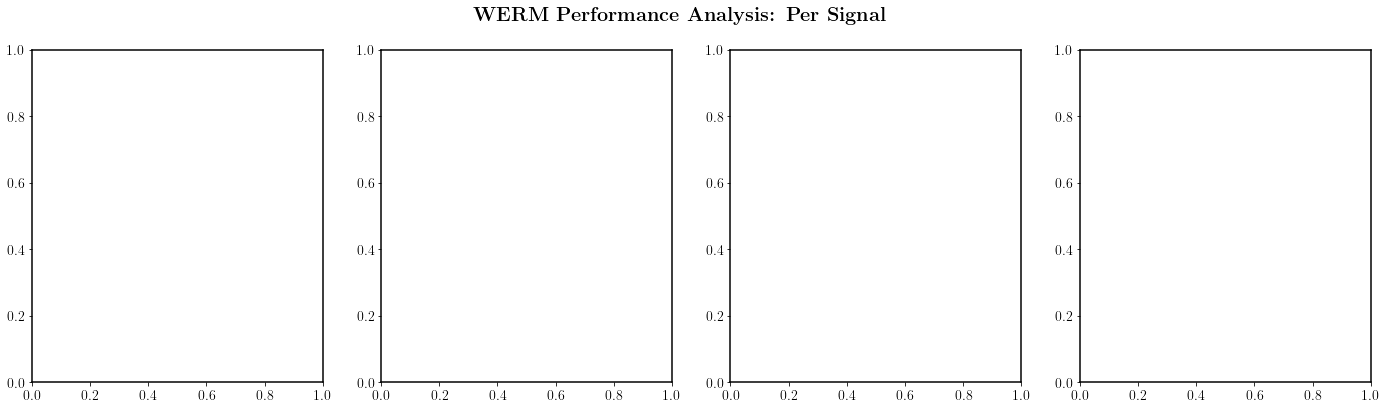

In [ ]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
import WERM.model as model
import importlib
import WERM.general_fixed_point_eqns as fp
importlib.reload(fp) # Reload to ensure latest changes are applied
import WERM.M_est_fixed_point_eqns as M_est
import WERM.gof
import WERM.performance_measures
import WERM.marginals
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm.auto import tqdm
import time
from joblib import Parallel, delayed
import logging
from datetime import datetime, timedelta
import sys
import pickle
import os

# Set a random seed for reproducibility
random_seed = 42
MASTER_KEY = jax.random.PRNGKey(random_seed)
nprandom.seed(random_seed)
jax.random.PRNGKey(random_seed) # Set JAX random seed as well

# --- Logging Setup ---
def setup_logging():
    """Setup comprehensive logging for the simulation"""
    detailed_formatter = logging.Formatter(
        '%(asctime)s - %(name)s - %(levelname)s - %(message)s',
        datefmt='%Y-%m-%d %H:%M:%S'
    )
    simple_formatter = logging.Formatter(
        '%(asctime)s - %(message)s',
        datefmt='%H:%M:%S'
    )

    # Create logs directory if it doesn't exist
    import os
    log_dir = 'logs'
    if not os.path.exists(log_dir):
        os.makedirs(log_dir)

    main_logger = logging.getLogger('simulation')
    main_logger.setLevel(logging.INFO)
    main_logger.handlers = [] # Clear existing handlers

    console_handler = logging.StreamHandler(sys.stdout)
    console_handler.setLevel(logging.INFO)
    console_handler.setFormatter(simple_formatter)
    main_logger.addHandler(console_handler)

    file_handler = logging.FileHandler('logs/WERM_SE_match_huber.log', mode='w')
    file_handler.setLevel(logging.DEBUG)
    file_handler.setFormatter(detailed_formatter)
    main_logger.addHandler(file_handler)

    progress_logger = logging.getLogger('progress')
    progress_logger.setLevel(logging.INFO)
    progress_logger.handlers = [] # Clear existing handlers

    progress_handler = logging.FileHandler('logs/WERM_SE_match_huber_progress.log', mode='w')
    progress_handler.setLevel(logging.INFO)
    progress_handler.setFormatter(detailed_formatter)
    progress_logger.addHandler(progress_handler)

    return main_logger, progress_logger

# Initialize loggers
main_logger, progress_logger = setup_logging()

class ProgressTracker:
    """Class to track and log simulation progress"""
    def __init__(self, total_tasks, delta_list, num_trials, logger):
        self.total_tasks = total_tasks
        self.delta_list = delta_list
        self.num_trials = num_trials
        self.logger = logger
        self.start_time = time.time()
        self.completed_tasks = 0
        self.delta_progress = {i: 0 for i in range(len(delta_list))}

    def update(self, delta_idx):
        """Update progress for a completed task"""
        self.completed_tasks += 1
        percent_complete = (self.completed_tasks / self.total_tasks) * 100
        elapsed_time = time.time() - self.start_time

        if self.completed_tasks > 0:
            avg_time_per_task = elapsed_time / self.completed_tasks
            remaining_tasks = self.total_tasks - self.completed_tasks
            estimated_remaining_time = remaining_tasks * avg_time_per_task
            estimated_completion = datetime.now() + timedelta(seconds=estimated_remaining_time)

            self.logger.info(
                f"Progress: {self.completed_tasks}/{self.total_tasks} ({percent_complete:.1f}%) | "
                f"Elapsed: {elapsed_time:.1f}s | "
                f"Est. remaining: {estimated_remaining_time:.1f}s | "
                f"Est. completion: {estimated_completion.strftime('%H:%M:%S')}"
            )

        self.delta_progress[delta_idx] += 1
        # Log delta-specific progress less frequently to avoid excessive logging
        if self.completed_tasks % max(1, self.total_tasks // 10) == 0 or self.completed_tasks == 1 or self.completed_tasks == self.total_tasks:
            delta_status = []
            for i, delta in enumerate(self.delta_list):
                progress = self.delta_progress[i]
                delta_status.append(f"δ={delta:.1f}: {progress}/{self.num_trials}")
            self.logger.info("Delta progress: " + " | ".join(delta_status))

# Global progress tracker (initialized later)
progress_tracker = None

# --- Helper Function for a Single Parallel Job ---
def run_single_trial(params, p, L, noise_std, fractional_chgpt_locations, M, method_configs, B̃):
    """
    Executes a single simulation trial for a given delta, running multiple methods.
    This function is designed to be called in parallel by joblib.
    """
    global progress_tracker
    i, δ, j = params # i: delta_list index, δ: current delta value, j: trial number
    trial_start_time = time.time()

    progress_logger.info(f"Starting trial {j+1}/{num_trials} for δ={δ:.1f} (delta_idx={i})")

    # --- Setup based on delta ---
    n = int(δ * p)
    if fractional_chgpt_locations.size != 0:
        true_chgpt_locations = lambda n_len: (n_len * fractional_chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
    else:
        true_chgpt_locations = lambda n_len: np.array([])
        C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0.

    # --- Preliminaries (from original code) ---
    # --- Compute weights as marginals of prior --- #
    Δ = lambda n: int(n/20)
    Delta_n = int(Δ(n))
    L_is_upper_bound = False
    if Delta_n ==1 : # No separation between change points, so use analytical binomial approximation. 
        if L_is_upper_bound:
            pi_i_l = lambda L, l, i : 1/(L - l + 1) * np.sum([scipy.special.comb(k - 1, l- 1, exact=False) * (i/n)**(l-1) * (1 - i/n)**(k-l) for k in range(l, L+1)])
        else: 
            pi_i_l = lambda L,l , i: scipy.special.comb(L-1, l-1, exact=False) * (i/n)**(l-1) * (1 - i/n)**(L-l)
        # Populate the pi L times n matrix
        pi = np.zeros((L, n))
        for l__ in range(L):
            for i__ in range(n):
                pi[l__, i__] = pi_i_l(L, l__ + 1, i__ + 1)
    else: 
        n_small = 100
        Delta_n_small = int(Delta_n * n_small/n)
        if L_is_upper_bound: 
            p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
            Lmin = 1
            Lmax = L
        else:
            p_l = None
            Lmin = L
            Lmax = L
        pi = WERM.config.extrapolated_marginals(Lmin, Lmax, Delta_n_small, n_small = n_small, n_large = n, p_l = p_l, verbose = False)
    π = pi
    if L == 1: 
        π = np.ones((1, n))
    # π = π / np.sum(π, axis=1, keepdims=True)  # Normalize the weights
    # Don't normalize for the compute_single_fixed_point function. 

    pi_switch = π.copy() # This is the switch matrix, which is the same as π in this case.
    pi_switch[0, :] = (π[0, :].copy() + π[2, :].copy())/2
    pi_switch[2, :] = (π[0, :].copy() + π[2, :].copy())/2
    # pi_switch = pi_switch / np.sum(pi_switch, axis=1, keepdims=True) # Normalize the switch matrix
    # Don't normalize for the compute_single_fixed_point function.

    # --- Data Generation for this trial ---
    data_gen_start = time.time()
    X = nprandom.normal(0, np.sqrt(1/n), (n, p))
    X = X @ Sigma_chol.T
    model_q = model.q_linear_model
    # ε = nprandom.randn(n) * noise_std
    # ε = np.random.standard_t(5, size=(n, )) * noise_std # For Huber loss, use t-distribution for noise. df > 2 has finite variance.
    # Sample pareto noise for Huber loss
    ε = np.random.laplace(loc=0.0, scale=1.0, size=(n,)) * noise_std # Use Laplace distribution for Huber loss, scale it by noise_std
    ε_theory = np.random.laplace(loc=0.0, scale=1.0, size=(n,)) * noise_std # For theoretical comparison, use same noise distribution
    B̃ = np.sqrt(δ) * B̃ # Scale B̃ by sqrt(delta) here since we vary delta, see the definition of B̃ outside of loop. 
    Θ = X @ B̃
    y_mapped_fn = jax.vmap(model_q, in_axes=(0, 0, 0))
    y = y_mapped_fn(Θ, C_true, ε)
    data_gen_time = time.time() - data_gen_start

    trial_results = {}
    methods_status = {method_name: False for method_name in method_configs.keys()}

    # Compute fixed point solution once per delta for theoretical comparison
    ρ = (1/δ) * (1/p) * (B̃.T @ Sigma_chol @ Sigma_chol.T @ B̃)

    # --- Run Estimators for all configured methods ---
    for method_name, method_func_info in method_configs.items():
        try:
            method_start = time.time()
            current_B̂ = np.zeros((p, L))
            Θ̂_theory = np.zeros((n, L))
            current_corr_list = []
            current_mse_list = []
            current_chgpt_loc = np.array([])

            if method_name == 'ERM-switch':
                for ℓ_ in range(L):
                    sample_weight = pi_switch[ℓ_, :] 
                    empirical_risk = lambda β: jnp.multiply(M((X @ β).flatten(), y.flatten()), sample_weight).sum() / n # Normalize by n for empirical risk
                    res = scipy.optimize.minimize(empirical_risk, 0.1*np.ones(p), jac=jax.grad(empirical_risk), method='L-BFGS-B')
                    β̂ = res.x
                    current_B̂[:, ℓ_] = β̂
                    current_corr_list.append(WERM.norm_sq_corr(β̂, B̃[:, ℓ_]))
                    current_mse_list.append(WERM.MSE(β̂.flatten(), B̃[:, ℓ_]))
                # Determine changepoints for ERM
                opt_chgpt_loc_erm, _ = WERM.gof.chgpt_gof_bf_mem_eff(
                    M, X @ current_B̂, y, n, L, Δ(n), L_is_upper_bound=False,
                    γ=0, batch_size=batch_size, gof_opt_output=True
                )
                # opt_chgpt_loc_erm, _ = WERM.gof.chgpt_binary_segmentation(
                #     M, X @ current_B̂, y, n, L, Δ(n), L_is_upper_bound=False,
                #     γ=0, gof_opt_output=True
                # )
                current_chgpt_loc = opt_chgpt_loc_erm

            elif method_name == 'Theory-switch':

                # b, ν̃, κ̃ = fp.general_fp(M, ρ, δ, true_chgpt_locations(n), pi_switch, ε, n, model.q_linear_model)
                b, ν̃, κ̃, success_status = fp.compute_single_fixed_point(true_chgpt_locations(n), M, ρ, δ, pi_switch, ε_theory, n, model_q, MASTER_KEY, maxiter=500, lr=0.2) # Decreased max iter to 300 and lr to 0.2
                κ̃_sqrt = jnp.linalg.cholesky(κ̃ + 1e-12 * jnp.eye(L))
                print("-"*60)
                print("b, ν̃, κ̃ for δ=", δ, ":", b, ν̃, κ̃, ", trial : ", j+1)
                print("-"*60)
                G_sample = nprandom.multivariate_normal(np.zeros((L, )), np.eye(L), size=(p,)) @ κ̃_sqrt.T
                G_sample_n = nprandom.multivariate_normal(np.zeros((L, )), np.eye(L), size=(n,)) @ κ̃_sqrt.T
                Z = nprandom.multivariate_normal(np.zeros((L, )), ρ, size=(n,))
                y_theory = y_mapped_fn(Z, C_true, ε_theory) 
                M_prime = jax.grad(M, argnums=0)
                M_double_prime = jax.grad(M_prime, argnums=0)
                for ℓ_ in range(L):
                    β̂_theory = B̃ @ ν̃[:, ℓ_] + δ**(1/2) * np.linalg.inv(Sigma_chol).T @ G_sample[:, ℓ_]
                    current_B̂[:, ℓ_] = β̂_theory
                    current_corr_list.append(WERM.norm_sq_corr(β̂_theory, B̃[:, ℓ_]))
                    current_mse_list.append(WERM.MSE(β̂_theory.flatten(), B̃[:, ℓ_]))
                    
                    sample_weight = pi_switch[ℓ_, :]
                    prox_mapped = lambda z, b, π_i, v: jax.vmap(fp.prox, in_axes=(0, None, 0, 0, None, None))(z, b, π_i, v, M_prime, M_double_prime)
                    Θ̂_theory[:, ℓ_] = prox_mapped(Z @ ν̃[:, ℓ_] + G_sample_n[:, ℓ_], b[ℓ_], sample_weight, y_theory)

                # Determine changepoints for Theory
                opt_chgpt_loc_theory, _ = WERM.gof.chgpt_gof_bf_mem_eff(
                    M, Θ̂_theory, y_theory, n, L, Δ(n), L_is_upper_bound=False,
                    γ=0, batch_size=batch_size, gof_opt_output=True
                )
                current_chgpt_loc = opt_chgpt_loc_theory

            elif method_name == 'ERM-unif':
                for ℓ_ in range(L):
                    sample_weight = π[ℓ_, :]
                    empirical_risk = lambda β: jnp.multiply(M((X @ β).flatten(), y.flatten()), sample_weight).sum() / n
                    res = scipy.optimize.minimize(empirical_risk, 0.1*np.ones(p), jac=jax.grad(empirical_risk), method='L-BFGS-B')
                    β̂ = res.x
                    current_B̂[:, ℓ_] = β̂
                    current_corr_list.append(WERM.norm_sq_corr(β̂, B̃[:, ℓ_]))
                    current_mse_list.append(WERM.MSE(β̂.flatten(), B̃[:, ℓ_]))
                # Determine changepoints for ERM
                opt_chgpt_loc_erm, _ = WERM.gof.chgpt_gof_bf_mem_eff(
                    M, X @ current_B̂, y, n, L, Δ(n), L_is_upper_bound=False,
                    γ=0, batch_size=batch_size, gof_opt_output=True
                )
                # opt_chgpt_loc_erm, _ = WERM.gof.chgpt_binary_segmentation(
                #     M, X @ current_B̂, y, n, L, Δ(n), L_is_upper_bound=False,
                #     γ=0, gof_opt_output=True
                # )
                current_chgpt_loc = opt_chgpt_loc_erm

            elif method_name == 'Theory-unif':
                # b, ν̃, κ̃ = fp.general_fp(M, ρ, δ, true_chgpt_locations(n), π, ε, n, model.q_linear_model)
                b, ν̃, κ̃, success_status = fp.compute_single_fixed_point(true_chgpt_locations(n), M, ρ, δ, π, ε_theory, n, model_q, MASTER_KEY, maxiter=500, lr=0.2) # Decreased max iter to 300 and lr to 0.2
                κ̃_sqrt = jnp.linalg.cholesky(κ̃ + 1e-12 * jnp.eye(L))
                print("-"*60)
                print("b, ν̃, κ̃ for δ=", δ, ":", b, ν̃, κ̃, ", trial : ", j+1)
                print("-"*60)

                G_sample = nprandom.multivariate_normal(np.zeros((L, )), np.eye(L), size=(p,)) @ κ̃_sqrt.T
                G_sample_n = nprandom.multivariate_normal(np.zeros((L, )), np.eye(L), size=(n,)) @ κ̃_sqrt.T
                Z = nprandom.multivariate_normal(np.zeros((L, )), ρ, size=(n,))
                y_theory = y_mapped_fn(Z, C_true, ε_theory) 
                M_prime = jax.grad(M, argnums=0)
                M_double_prime = jax.grad(M_prime, argnums=0)
                for ℓ_ in range(L):
                    β̂_theory = B̃ @ ν̃[:, ℓ_] + δ**(1/2) * np.linalg.inv(Sigma_chol).T @ G_sample[:, ℓ_]
                    current_B̂[:, ℓ_] = β̂_theory
                    current_corr_list.append(WERM.norm_sq_corr(β̂_theory, B̃[:, ℓ_]))
                    current_mse_list.append(WERM.MSE(β̂_theory.flatten(), B̃[:, ℓ_]))
                    
                    sample_weight = π[ℓ_, :]
                    prox_mapped = lambda z, b, π_i, v: jax.vmap(fp.prox, in_axes=(0, None, 0, 0, None, None))(z, b, π_i, v, M_prime, M_double_prime)
                    Θ̂_theory[:, ℓ_] = prox_mapped(Z @ ν̃[:, ℓ_] + G_sample_n[:, ℓ_], b[ℓ_], sample_weight, y_theory)

                # Determine changepoints for Theory
                opt_chgpt_loc_theory, _ = WERM.gof.chgpt_gof_bf_mem_eff(
                    M, Θ̂_theory, y_theory, n, L, Δ(n), L_is_upper_bound=False,
                    γ=0, batch_size=batch_size, gof_opt_output=True
                )
                current_chgpt_loc = opt_chgpt_loc_theory
            else:
                main_logger.warning(f"Method {method_name} not recognized. Skipping.")
                continue

            method_time = time.time() - method_start
            trial_results[f'runtime_{method_name}'] = method_time
            trial_results[f'corr_{method_name}'] = np.array(current_corr_list)
            trial_results[f'mse_{method_name}'] = np.array(current_mse_list)
            trial_results[f'haus_{method_name}'] = (1/n * WERM.performance_measures.hausdorff(current_chgpt_loc, true_chgpt_locations(n)))
            trial_results[f'size_{method_name}'] = len(current_chgpt_loc[current_chgpt_loc != -1])
            trial_results[f'chgpts_{method_name}'] = current_chgpt_loc.copy()
            methods_status[method_name] = True

        except Exception as e:
            main_logger.error(f"Trial {j+1} for δ={δ:.1f}: {method_name} failed with error: {e}", exc_info=True)
            trial_results[f'runtime_{method_name}'] = np.nan
            trial_results[f'corr_{method_name}'] = np.full(L, np.nan)
            trial_results[f'mse_{method_name}'] = np.full(L, np.nan)
            trial_results[f'haus_{method_name}'] = np.nan
            trial_results[f'size_{method_name}'] = np.nan
            trial_results[f'chgpts_{method_name}'] = np.array([])
            methods_status[method_name] = False

    # Store additional info for histogram plotting
    trial_results['n'] = n
    trial_results['true_chgpts'] = true_chgpt_locations(n).copy()
    trial_results['fractional_true_chgpts'] = fractional_chgpt_locations.copy()
    trial_results['methods_status'] = methods_status

    trial_total_time = time.time() - trial_start_time
    log_message_parts = [
        f"Completed trial {j+1} for δ={δ:.1f}: ",
        f"Total={trial_total_time:.1f}s (Data={data_gen_time:.1f}s)"
    ]
    for method_name in method_configs.keys():
        status_str = 'OK' if methods_status[method_name] else 'FAIL'
        runtime_str = f"{trial_results[f'runtime_{method_name}']:.1f}s" if f'runtime_{method_name}' in trial_results and not np.isnan(trial_results[f'runtime_{method_name}']) else "N/A"
        log_message_parts.append(f"{method_name}={status_str} ({runtime_str})")
    progress_logger.info(" ".join(log_message_parts))

    if progress_tracker:
        progress_tracker.update(i)

    return i, j, trial_results

# --- Main Script Setup ---
main_logger.info("Starting WERM Simulation with parallel execution and enhanced logging")
main_logger.info("=" * 80)

# Simulation Parameters
p = 800 # at least 500 is needed for stable results
L = 3 # num signals. L-1 changepoints
noise_std = np.sqrt(0.1) # sqrt(0.5) on gaussian noise to get recent good plot

δ_list = np.arange(2.25, 3.51, 0.25)
num_trials = 10 # Increased for better statistics
fractional_chgpt_locations = np.array([0.3, 0.8]) # [0.2,0.8] gave biggest improvement for ERM-switch. Also noticed big differences in bf vs. non-bf for ERM-switch

n_jobs = 45 # Use all available CPU cores. Set to 1 for no parallelization.

# Least Squares Loss
# M = lambda u, v: jnp.power(u - v, 2)

# # Huber Loss
def M(u, v, epsilon=1.35):
    residual = u - v
    abs_residual = jnp.abs(residual)
    condition = abs_residual <= epsilon
    squared_loss = 0.5 * jnp.square(residual)
    linear_loss = epsilon * (abs_residual - 0.5 * epsilon)
    return jnp.where(condition, squared_loss, linear_loss)

# Sample the signal outside
# κ = 1.0
# B̃_cov = κ**2 * np.eye(L) # Omit the δ term here, multiply it inside of the trial loop since we vary δ
# # Add some correlation between signals for L > 1
# r_B = 0.25
# if L > 1:
#     for ll in range(L):
#         for mm in range(L):
#             if ll != mm:
#                 B̃_cov[ll, mm] = r_B**(abs(ll - mm)) * κ**2
# signal_prior = GaussianSignal(B̃_cov)
# B̃ = signal_prior.sample(p)

# def sample_corr(p, df=10, seed=None):
#     """Sample a random correlation matrix using the Haar measure."""
#     rng = np.random.default_rng(seed)
#     Q, _ = np.linalg.qr(rng.standard_normal((p, p)))           # Haar‐orthogonal
#     λ = rng.chisquare(df, size=p)                              # χ² eigenvalues
#     B = Q.T @ np.diag(λ) @ Q                                   # SPD matrix
#     D = np.sqrt(np.diag(B))
#     return B / np.outer(D, D)

# Sigma = sample_corr(p, df=10, seed=random_seed) 

κ = 0.3 # 1.0 for the second_best plot
B̃_cov = κ**2 * np.eye(L) # Remove the δ term here, multiply it inside of the trial loop since we vary δ
# Make the first and third signals identical
B̃_cov[0, 2] = 0.975 * κ**2 # Covariance between first and third signals, make them not perfectly identical for numerical stability
B̃_cov[2, 0] = 0.975 * κ**2 # Covariance between first and third signals, make them not perfectly identical for numerical stability
B̃_cov[0, 1] = 0.1 * κ**2 # Covariance between first and second signals, was 0.2 for the second_best plot
B̃_cov[1, 0] = 0.1 * κ**2 # Covariance between first and second signals
B̃_cov[1, 2] = 0.1 * κ**2 # Covariance between second and third signals
B̃_cov[2, 1] = 0.1 * κ**2 # Covariance between second and third signals
print(f"B̃_cov:\n{B̃_cov}")
signal_prior = GaussianSignal(B̃_cov)
B̃ = signal_prior.sample(p)

# Set first and last columns of B̃ to one
# B̃[:, 0] = np.ones(p) # First signal is constant
# B̃[:, -1] = np.ones(p) # Last signal is constant

# Draw Sigma from an AR(1) process for some correlation structure r_s = 0.5
r_s = 0.1
AR1 = np.fromfunction(lambda i, j: r_s**(np.abs(i - j)), (p, p))
Sigma = AR1
Sigma_chol = np.linalg.cholesky(Sigma + 1e-12 * np.eye(p)) # Add small ridge for numerical stability

# Load Sigma and B̃ from a precomputed file
# filepath = 'results/WERM_SE_match_est_switching_ERM-LS_Theory-LS_p700_L3_noisestd0.4472135954999579_seed42_deltas_2_3_4_5_6.pkl'
# try:
#     with open(filepath, 'rb') as f:
#         data = pickle.load(f)
#     Sigma = data['params']['Sigma']
#     B̃ = data['params']['B_tilde']
#     main_logger.info(f"Loaded precomputed Sigma and B̃ from {filepath}")
# except FileNotFoundError:
#     main_logger.error(f"File {filepath} not found. Please ensure the file exists or generate it first.")
#     sys.exit(1)
# Sigma = np.eye(p)
# Sigma_chol = np.linalg.cholesky(Sigma + 1e-12 * np.eye(p)) # Add small ridge for numerical stability

batch_size = 4096*6 # Batch size for memory efficient computation of brute force solution

# --- Define Methods to be Evaluated ---
methods_to_evaluate = [
    {'name': 'ERM-switch', 'label': r'\textbf{ERM-switch}', 'color': '#EE7733', 'marker': 'o', 'linestyle': '-'},
    {'name': 'Theory-switch', 'label': r'\textbf{Theory-switch}', 'color': '#0077BB', 'marker': 'D', 'linestyle': '-.'},
    {'name': 'ERM-unif', 'label': r'\textbf{ERM-unif}', 'color': '#EE7733', 'marker': 'x', 'linestyle': '--'},
    {'name': 'Theory-unif', 'label': r'\textbf{Theory-unif}', 'color': '#0077BB', 'marker': '^', 'linestyle': ':'},
]

# Create a dictionary for easy lookup within run_single_trial
method_configs = {method['name']: method for method in methods_to_evaluate}
method_names_list = [m['name'] for m in methods_to_evaluate] # List of just names

# Log simulation parameters
main_logger.info(f"Simulation Parameters:")
main_logger.info(f" p (features): {p}")
main_logger.info(f" L (signals): {L}")
main_logger.info(f" noise_std: {noise_std}")
main_logger.info(f" δ_list: {δ_list}")
main_logger.info(f" num_trials: {num_trials}")
main_logger.info(f" fractional_chgpt_locations: {fractional_chgpt_locations}")
main_logger.info(f" n_jobs: {n_jobs}")
main_logger.info(f" Loss function: Least Squares")
main_logger.info(f" Methods to evaluate: {method_names_list}")
main_logger.info(f" Total tasks: {len(δ_list) * num_trials}")

# Results Storage
results = {
    'successful_trials': {method['name']: np.zeros(len(δ_list), dtype=int) for method in methods_to_evaluate},
    'true_chgpts': [],
    'n_values': [],
    'delta_values': []
}

for method in methods_to_evaluate:
    method_name = method['name']
    results[f'corr_{method_name}'] = np.full((len(δ_list), num_trials, L), np.nan)
    results[f'mse_{method_name}'] = np.full((len(δ_list), num_trials, L), np.nan)
    results[f'haus_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'size_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'runtime_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'chgpts_{method_name}'] = [] # Store (delta_idx, chgpts_array) for histogram plotting


# --- Parallel Execution ---
tasks = [(i, δ, j) for i, δ in enumerate(δ_list) for j in range(num_trials)]
main_logger.info("=" * 80)
main_logger.info(f"Starting {len(tasks)} simulation trials")
main_logger.info(f"Using {n_jobs if n_jobs != -1 else 'all available'} CPU cores")

# Rough estimate for total time, adjust based on typical single trial runtime
single_trial_estimate = 20.0 # seconds, adjust this based on observation
total_estimated_time = len(tasks) * single_trial_estimate / (n_jobs if n_jobs > 0 else 4)
estimated_completion = datetime.now() + timedelta(seconds=total_estimated_time)
main_logger.info(f"Estimated total time: {total_estimated_time/60:.1f} minutes")
main_logger.info(f"Estimated completion: {estimated_completion.strftime('%Y-%m-%d %H:%M:%S')}")
main_logger.info("=" * 80)

progress_tracker = ProgressTracker(len(tasks), δ_list, num_trials, main_logger)
simulation_start_time = time.time()

try:
    parallel_results = Parallel(n_jobs=n_jobs, verbose=0)(
        delayed(run_single_trial)(
            params=task,
            p=p,
            L=L,
            noise_std=noise_std,
            fractional_chgpt_locations=fractional_chgpt_locations,
            M=M,
            method_configs=method_configs,
            B̃=B̃
        ) for task in tqdm(tasks, desc="Running simulation trials", ncols=100, leave=True)
    )
    simulation_end_time = time.time()
    total_simulation_time = simulation_end_time - simulation_start_time
    main_logger.info("=" * 80)
    main_logger.info(f"Simulation completed successfully!")
    main_logger.info(f"Total simulation time: {total_simulation_time/60:.2f} minutes")
    main_logger.info(f"Average time per trial: {total_simulation_time/len(tasks):.2f} seconds")
    main_logger.info("=" * 80)
except Exception as e:
    main_logger.error(f"Simulation failed with error: {str(e)}", exc_info=True)
    raise

# --- Aggregate Results ---
main_logger.info("Aggregating results...")
aggregation_start_time = time.time()

for result_idx, (i, j, trial_result) in enumerate(parallel_results):
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        if trial_result['methods_status'][method_name]:
            results[f'corr_{method_name}'][i, j, :] = trial_result[f'corr_{method_name}']
            results[f'mse_{method_name}'][i, j, :] = trial_result[f'mse_{method_name}']
            results[f'haus_{method_name}'][i, j] = trial_result[f'haus_{method_name}']
            results[f'size_{method_name}'][i, j] = trial_result[f'size_{method_name}']
            results[f'runtime_{method_name}'][i, j] = trial_result[f'runtime_{method_name}']
            results['successful_trials'][method_name][i] += 1
        results[f'chgpts_{method_name}'].append((i, trial_result[f'chgpts_{method_name}'])) # Always append, even if empty

    results['true_chgpts'].append((i, trial_result['true_chgpts']))
    results['n_values'].append((i, trial_result['n']))
    results['delta_values'].append((i, δ_list[i]))

aggregation_time = time.time() - aggregation_start_time
main_logger.info(f"Results aggregation completed in {aggregation_time:.2f} seconds")

# Log summary statistics
main_logger.info("=" * 40)
main_logger.info("SIMULATION SUMMARY STATISTICS")
main_logger.info("=" * 40)
for i, delta in enumerate(δ_list):
    main_logger.info(f"δ = {delta:.1f}:")
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        avg_corr = np.nanmean(results[f'corr_{method_name}'][i, :, :])
        std_corr = np.nanstd(results[f'corr_{method_name}'][i, :, :])
        avg_mse = np.nanmean(results[f'mse_{method_name}'][i, :, :])
        std_mse = np.nanstd(results[f'mse_{method_name}'][i, :, :])
        avg_haus = np.nanmean(results[f'haus_{method_name}'][i, :])
        std_haus = np.nanstd(results[f'haus_{method_name}'][i, :])
        avg_size = np.nanmean(results[f'size_{method_name}'][i, :])
        std_size = np.nanstd(results[f'size_{method_name}'][i, :])
        avg_runtime = np.nanmean(results[f'runtime_{method_name}'][i, :])
        std_runtime = np.nanstd(results[f'runtime_{method_name}'][i, :])
        num_success = results['successful_trials'][method_name][i]
        main_logger.info(f" {method_name} - Successful Trials: {num_success}/{num_trials}")
        main_logger.info(f" {method_name} - Avg Norm Sq Corr: {avg_corr:.4f} ± {std_corr:.4f}")
        main_logger.info(f" {method_name} - Avg MSE: {avg_mse:.4f} ± {std_mse:.4f}")
        main_logger.info(f" {method_name} - Avg Hausdorff: {avg_haus:.4f} ± {std_haus:.4f}")
        main_logger.info(f" {method_name} - Avg Size: {avg_size:.2f} ± {std_size:.2f}")
        main_logger.info(f" {method_name} - Avg Runtime: {avg_runtime:.2f}s ± {std_runtime:.2f}s")
    main_logger.info("")

# --- Publication-Ready Enhanced Plotting Results ---
plt.rcParams.update({
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': False,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 3.0,
    'lines.markersize': 8,
    'figure.dpi': 72,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

main_logger.info("Creating publication-ready plots...")
plotting_start_time = time.time()

# Paul Tol "Vibrant" - optimal balance of aesthetics and accessibility
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB', '#FF8800', '#DDAA33', '#BBCC33']
PAL = TOL_VIBRANT

# Ensure colors are assigned from the palette in order
for i, method_obj in enumerate(methods_to_evaluate):
    method_obj['color'] = PAL[i % len(PAL)] # Cycle through colors if more methods than palette entries

print(f"Using palette: {[m['color'] for m in methods_to_evaluate]} (Paul Tol Vibrant assigned to methods)")

def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=0) # Changed axis to 0 for signal-specific data
    p25 = np.nanpercentile(data, 25, axis=0)
    p75 = np.nanpercentile(data, 75, axis=0)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

# --- Publication-Ready Asymmetric Error Bars Plots ---
def plot_with_asymmetric_errors_publication_per_signal(L):
    """
    Plots with asymmetric error bars, showing each signal (l) separately for corr and mse.
    """
    fig, axs = plt.subplots(1, 4, figsize=(24, 6))
    fig.suptitle(r'\textbf{WERM Performance Analysis: Per Signal}', fontsize=20, y=0.98)

    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    metrics_to_plot = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}', (0, 1.05)),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}', None),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}', (0, 0.5)),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}', (0, L + 2))
    ]

    for ax_idx, (metric_key, ylabel, title, ylim) in enumerate(metrics_to_plot):
        ax = axs[ax_idx]
        for i, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            
            if metric_key in ['corr', 'mse']:
                for l_idx in range(L):
                    # Select data for the current signal l_idx
                    data_l = results[f'{metric_key}_{method_name}'][:, :, l_idx]
                    if np.all(np.isnan(data_l)):
                        main_logger.warning(f"No successful trials for {method_name} (signal {l_idx+1}, {metric_key}). Skipping plot.")
                        continue
                    means = np.nanmean(data_l, axis=1)
                    errors = get_asymmetric_errors(data_l)
                    ax.errorbar(δ_list, means, yerr=errors,
                                 label=f"{method_obj['label']} ($\\ell={l_idx+1}$)",
                                 marker=plot_markers[i], ls=plot_linestyles[i],
                                 color=plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[i], # Use a colormap for signals
                                 capsize=4, capthick=2, markersize=8,
                                 linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
            else:
                # For other metrics, continue as before (average across trials)
                data = results[f'{metric_key}_{method_name}']
                if np.all(np.isnan(data)):
                    main_logger.warning(f"No successful trials for {method_name} ({metric_key}). Skipping plot for this metric.")
                    continue
                means = np.nanmean(data, axis=1)
                errors = get_asymmetric_errors(data)
                ax.errorbar(δ_list, means, yerr=errors,
                             label=method_obj['label'], marker=plot_markers[i], ls=plot_linestyles[i],
                             color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                             linewidth=3.5, markeredgewidth=2, markeredgecolor='white')

        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
            
        if ylim:
            ax.set_ylim(ylim)
        else:
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=(len(methods_to_evaluate) * L) + (1 if 'size' in [m[0] for m in metrics_to_plot] else 0),
               fontsize=12, frameon=True, edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()


# --- Publication-Ready Confidence Bands Plots ---
def plot_with_confidence_bands_publication_per_signal(L):
    """
    Plots with confidence bands, showing each signal (l) separately for corr and mse.
    """
    fig, axs = plt.subplots(1, 4, figsize=(24, 6))
    fig.suptitle(r'\textbf{WERM Performance Analysis: Confidence Intervals Per Signal}',
                 fontsize=20, y=0.98)

    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics_to_plot = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}', (0, 1.05)),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}', None),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}', (0, 0.5)),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}', (0, L + 2))
    ]

    for ax_idx, (metric_key, ylabel, title, ylim) in enumerate(metrics_to_plot):
        ax = axs[ax_idx]
        for method_idx, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            
            if metric_key in ['corr', 'mse']:
                for l_idx in range(L):
                    data_l = results[f'{metric_key}_{method_name}'][:, :, l_idx]
                    if np.all(np.isnan(data_l)):
                        main_logger.warning(f"No successful trials for {method_name} (signal {l_idx+1}, {metric_key}). Skipping plot.")
                        continue
                    means = np.nanmean(data_l, axis=1)
                    p10 = np.nanpercentile(data_l, 10, axis=1)
                    p90 = np.nanpercentile(data_l, 90, axis=1)
                    p10 = np.minimum(p10, means)
                    p90 = np.maximum(p90, means)

                    current_color = plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[method_idx]
                    ax.fill_between(δ_list, p10, p90, color=current_color,
                                     alpha=0.15, zorder=1)
                    ax.plot(δ_list, means, color=current_color, linewidth=4,
                             marker='o', markersize=9, label=f"{method_obj['label']} ($\\ell={l_idx+1}$)", zorder=3,
                             markeredgewidth=2, markeredgecolor='white')
            else:
                # For other metrics, continue as before
                data = results[f'{metric_key}_{method_name}']
                if np.all(np.isnan(data)):
                    main_logger.warning(f"No successful trials for {method_name} ({metric_key}). Skipping plot for this metric.")
                    continue
                means = np.nanmean(data, axis=1)
                p10 = np.nanpercentile(data, 10, axis=1)
                p90 = np.nanpercentile(data, 90, axis=1)
                p10 = np.minimum(p10, means)
                p90 = np.maximum(p90, means)

                ax.fill_between(δ_list, p10, p90, color=plot_colors[method_idx],
                                 alpha=0.15, zorder=1)
                ax.plot(δ_list, means, color=plot_colors[method_idx], linewidth=4,
                         marker='o', markersize=9, label=method_obj['label'], zorder=3,
                         markeredgewidth=2, markeredgecolor='white')

        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}', zorder=2)
        if ylim:
            ax.set_ylim(ylim)
        elif metric_key in ['mse', 'runtime']:
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=(len(methods_to_evaluate) * L) + (1 if 'size' in [m[0] for m in metrics_to_plot] else 0),
               fontsize=12, frameon=True, edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Publication-Ready Box Plots ---
def plot_with_boxplots_publication_per_signal(L):
    """
    Creates box plots, showing each signal (l) separately for corr and mse.
    """
    fig, axs = plt.subplots(1, 4, figsize=(24, 6)) # Adjusted for 4 metrics
    fig.suptitle(r'\textbf{WERM Performance Analysis: Distribution Comparison Per Signal}',
                 fontsize=20, y=0.98)

    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics_to_plot = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}'),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}'),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}'),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}')
    ]

    for ax_idx, (metric_key, ylabel, title) in enumerate(metrics_to_plot):
        ax = axs[ax_idx]
        
        # Adjusted spacing for per-signal plots
        spacing = (len(methods_to_evaluate) * L) + 1 
        if metric_key not in ['corr', 'mse']:
            spacing = len(methods_to_evaluate) + 1 # Revert spacing for non-signal-specific plots

        for delta_idx, delta in enumerate(δ_list):
            box_data = []
            box_positions = []
            box_colors = []
            for method_idx, method_obj in enumerate(methods_to_evaluate):
                method_name = method_obj['name']
                if metric_key in ['corr', 'mse']:
                    for l_idx in range(L):
                        data_l = results[f'{metric_key}_{method_name}'][delta_idx, :, l_idx]
                        valid_data = data_l[~np.isnan(data_l)]
                        if len(valid_data) > 0:
                            box_data.append(valid_data)
                            # Position calculation needs to account for both method and signal
                            position = delta_idx * spacing + (method_idx * L + l_idx) 
                            box_positions.append(position)
                            box_colors.append(plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[method_idx])
                        else:
                            main_logger.warning(f"No valid data for {method_name} (signal {l_idx+1}) for delta {delta:.1f} ({metric_key}). Skipping box plot for this point.")
                else:
                    # For other metrics, use the original logic
                    data = results[f'{metric_key}_{method_name}'][delta_idx, :]
                    valid_data = data[~np.isnan(data)]
                    if len(valid_data) > 0:
                        box_data.append(valid_data)
                        box_positions.append(delta_idx * spacing + method_idx)
                        box_colors.append(plot_colors[method_idx])
                    else:
                        main_logger.warning(f"No valid data for {method_name} for delta {delta:.1f} ({metric_key}). Skipping box plot for this point.")

            if len(box_data) > 0:
                bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                                 patch_artist=True, showfliers=True,
                                 flierprops=dict(marker='o', markersize=4, alpha=0.6),
                                 medianprops=dict(color='white', linewidth=2.5),
                                 boxprops=dict(linewidth=1.5),
                                 whiskerprops=dict(linewidth=1.5),
                                 capprops=dict(linewidth=1.5))
                for patch, color in zip(bp['boxes'], box_colors):
                    patch.set_facecolor(color)
                    patch.set_alpha(0.8)
                    patch.set_edgecolor('black')

        if metric_key in ['corr', 'mse']:
            # Adjusted xticks for per-signal plots
            delta_positions = [i * spacing + (len(methods_to_evaluate) * L - 1) / 2 for i in range(len(δ_list))]
        else:
            delta_positions = [i * spacing + (len(methods_to_evaluate) - 1) / 2 for i in range(len(δ_list))]

        ax.set_xticks(delta_positions[::2])
        ax.set_xticklabels([f'{d:.1f}' for d in δ_list[::2]])
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)

        legend_elements = []
        if metric_key in ['corr', 'mse']:
            # Create legend elements for each method and each signal
            for method_idx, method_obj in enumerate(methods_to_evaluate):
                for l_idx in range(L):
                    current_color = plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[method_idx]
                    legend_elements.append(plt.Rectangle((0,0),1,1, facecolor=current_color,
                                                         alpha=0.8, edgecolor='black',
                                                         linewidth=1.5, label=f"{method_obj['label']} ($\\ell={l_idx+1}$)" ))
        else:
            # Original legend elements for other metrics
            legend_elements = [plt.Rectangle((0,0),1,1, facecolor=plot_colors[i],
                                             alpha=0.8, edgecolor='black',
                                             linewidth=1.5, label=plot_labels[i])
                                             for i in range(len(methods_to_evaluate))]

        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}')
            legend_elements.append(plt.Line2D([0], [0], color='black', lw=3, linestyle='-', label=r'\textbf{True Size}'))

        ax.legend(handles=legend_elements, loc='upper left', fontsize=10,
                  frameon=True, edgecolor='black', framealpha=0.95, ncol=1 + (L-1 if metric_key in ['corr', 'mse'] else 0) ) # Adjust ncol based on L
        
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


# Execute publication-ready plotting options
main_logger.info("Generating plots...")
print("1. Asymmetric error bars (publication style) per signal...")
plot_with_asymmetric_errors_publication_per_signal(L)
print("2. Confidence bands (publication style) per signal...")
plot_with_confidence_bands_publication_per_signal(L)
print("3. Box plots (publication style) per signal...")
plot_with_boxplots_publication_per_signal(L)
print("4. Enhanced changepoint histograms (publication style)...")
plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, method_names_list)
plotting_time = time.time() - plotting_start_time
main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

# Save results to a file
method_names_for_filename = '_'.join(method['name'] for method in methods_to_evaluate)
filename = f"results/WERM_SE_match_est_switchvsunif_huber_laplace_nopinorm_{method_names_for_filename}_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}_deltas_{'_'.join(map(str, map(int, δ_list)))}.pkl"

# Create results directory if it doesn't exist
results_dir = 'results'
if not os.path.exists(results_dir):
    os.makedirs(results_dir)

with open(filename, 'wb') as f:
    pickle.dump({
        'results': results,
        'params': {
            'p': p,
            'L': L,
            'noise_std': noise_std,
            'δ_list': δ_list,
            'num_trials': num_trials,
            'fractional_chgpt_locations': fractional_chgpt_locations,
            'n_jobs': n_jobs,
            'successful_trials_counts': results['successful_trials'],
            'methods_evaluated': methods_to_evaluate,
            'random_seed': random_seed,
            'Sigma': Sigma,
            'B_tilde': B̃
        }
    }, f)
main_logger.info(f"Results saved to {filename}")

19:34:35 - Creating publication-ready plots...
Using palette: ['#EE7733', '#0077BB', '#33BBEE', '#EE3377'] (Paul Tol Vibrant assigned to methods)
19:34:35 - Generating plots...
1. Asymmetric error bars (publication style)...


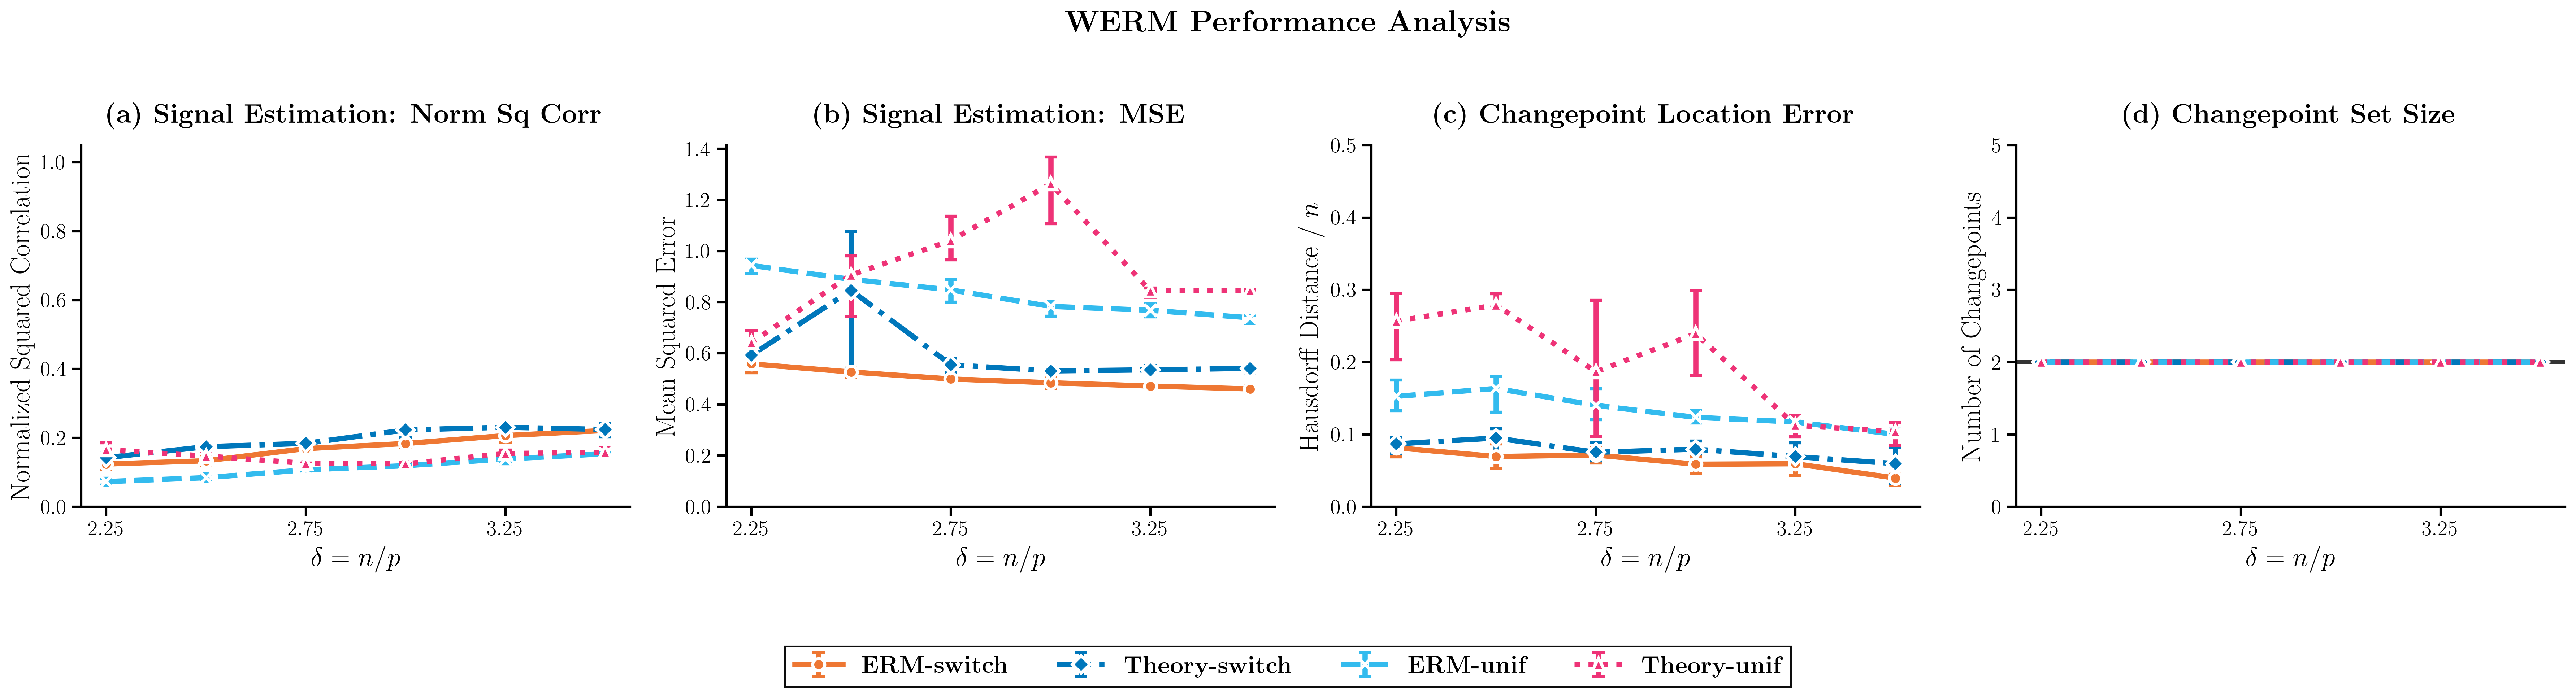

2. Confidence bands (publication style)...


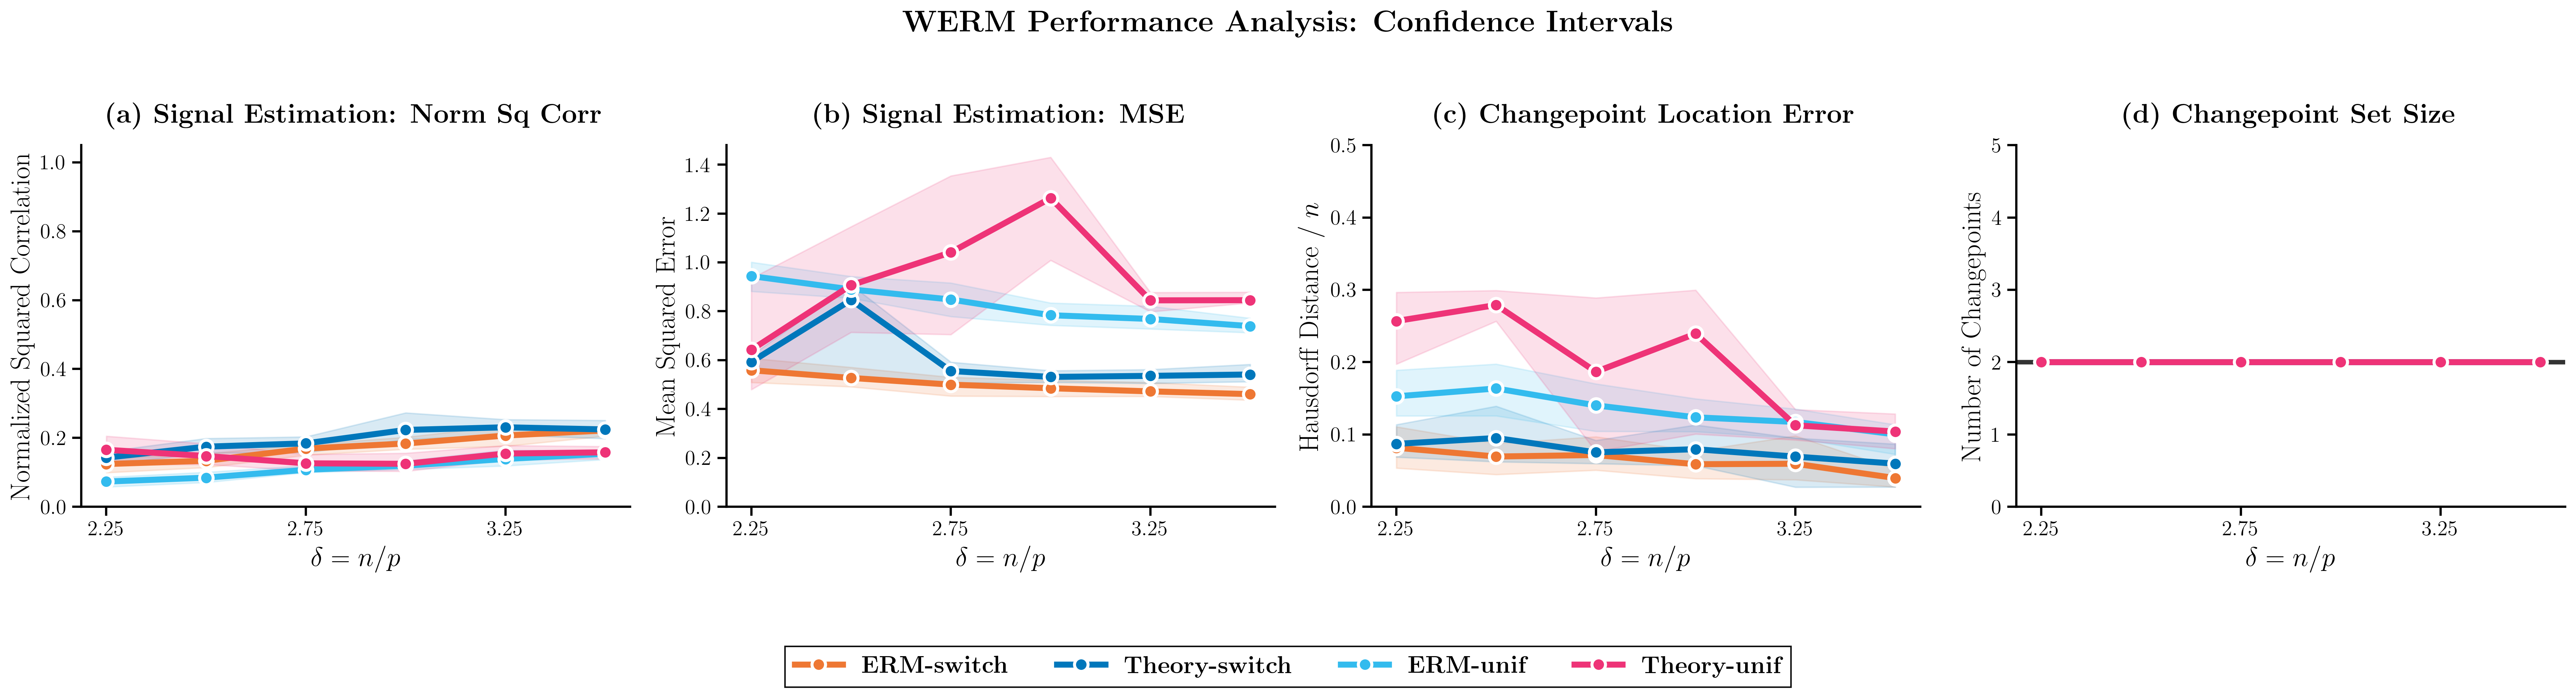

3. Box plots (publication style)...


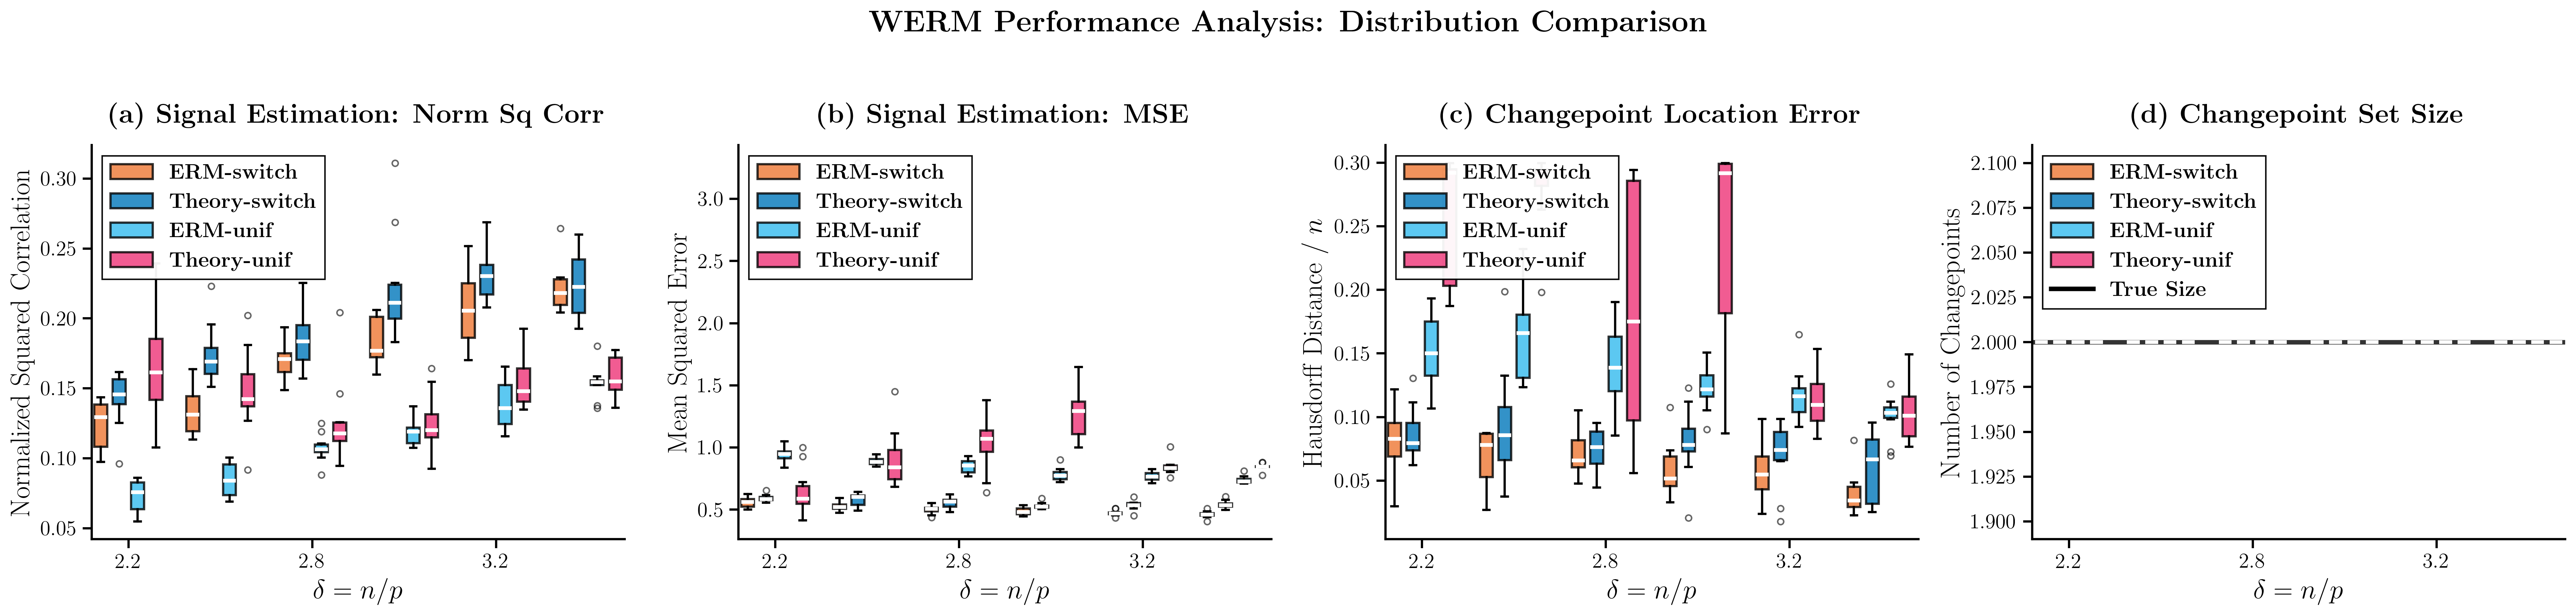

4. Enhanced changepoint histograms (publication style)...


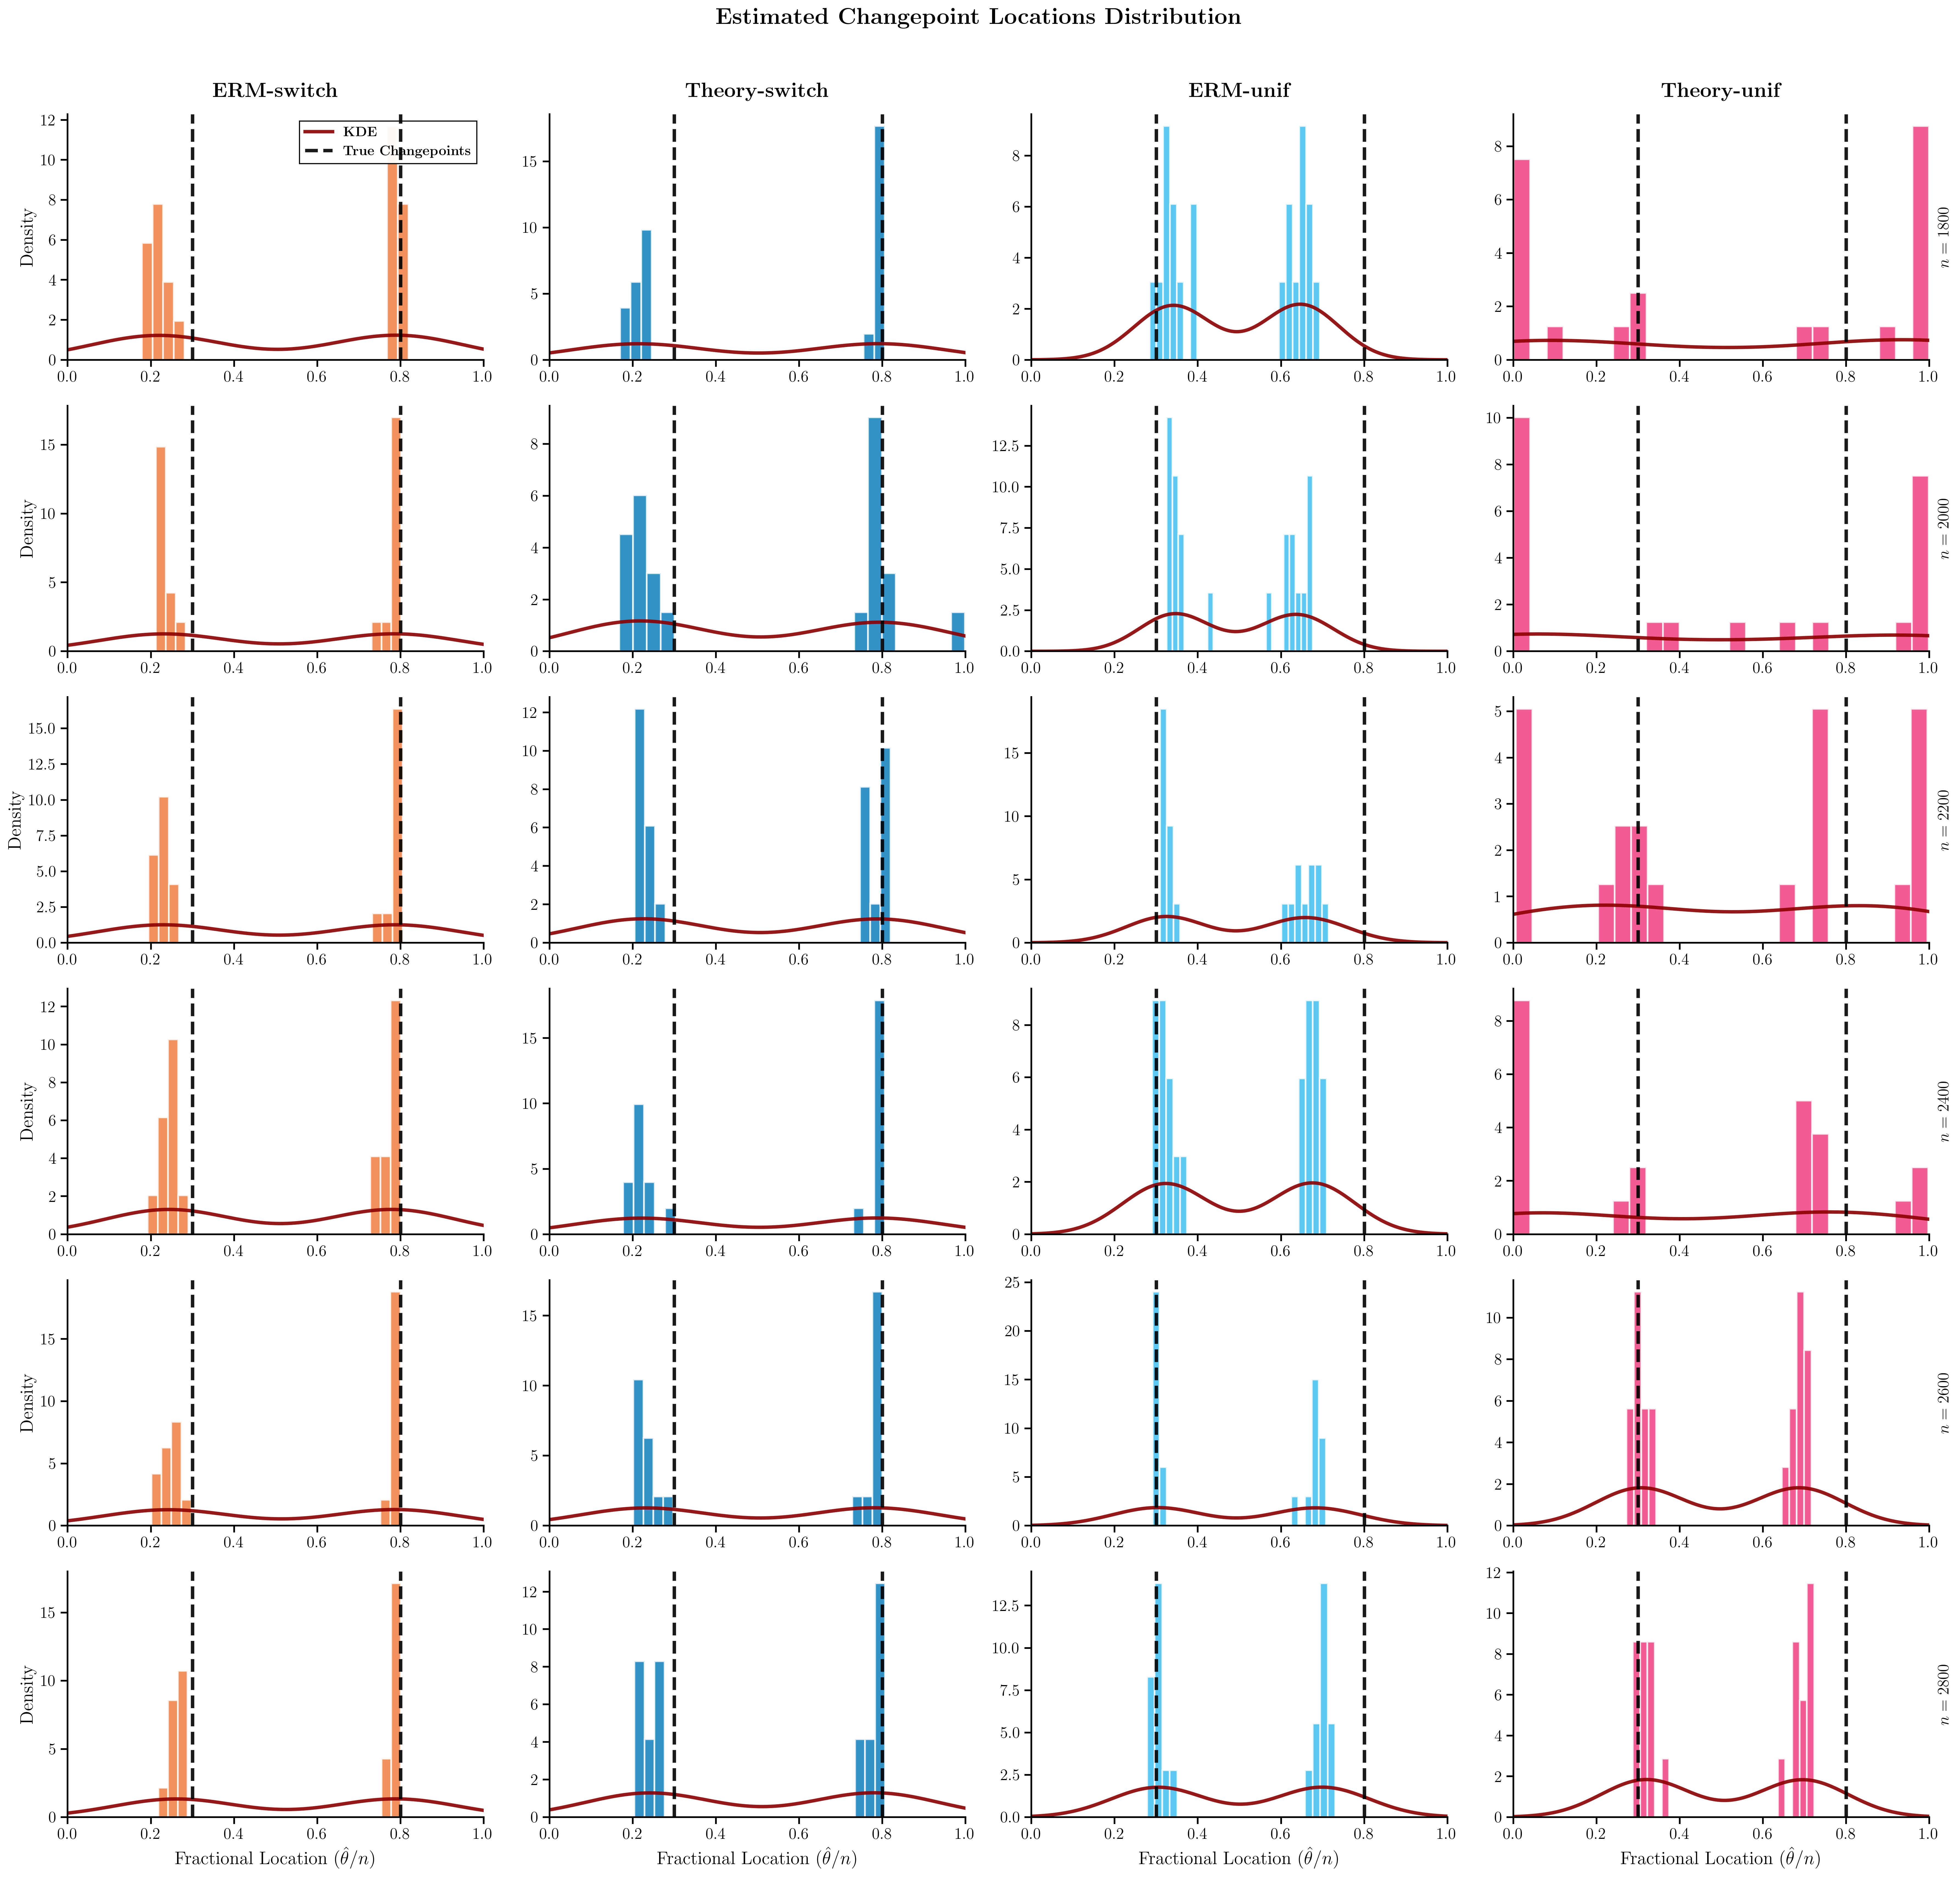

19:34:40 - Publication-ready plotting completed in 4.65 seconds
Savingt to file: results/WERM_SE_match_est_switchvsunif_huber_laplace_nopinorm_ERM-switch_Theory-switch_ERM-unif_Theory-unif_p800_L3_noisestd0.31622776601683794_seed42_deltas_2_2_2_3_3_3.pkl
19:34:40 - Results saved to results/WERM_SE_match_est_switchvsunif_huber_laplace_nopinorm_ERM-switch_Theory-switch_ERM-unif_Theory-unif_p800_L3_noisestd0.31622776601683794_seed42_deltas_2_2_2_3_3_3.pkl


In [3]:
# --- Publication-Ready Enhanced Plotting Results ---
plt.rcParams.update({
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': False,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 3.0,
    'lines.markersize': 8,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

main_logger.info("Creating publication-ready plots...")
plotting_start_time = time.time()

# Paul Tol "Vibrant" - optimal balance of aesthetics and accessibility
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB', '#FF8800', '#DDAA33', '#BBCC33']
PAL = TOL_VIBRANT

# Ensure colors are assigned from the palette in order
for i, method_obj in enumerate(methods_to_evaluate):
    method_obj['color'] = PAL[i % len(PAL)] # Cycle through colors if more methods than palette entries

print(f"Using palette: {[m['color'] for m in methods_to_evaluate]} (Paul Tol Vibrant assigned to methods)")

def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=1)
    p25 = np.nanpercentile(data, 25, axis=1)
    p75 = np.nanpercentile(data, 75, axis=1)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

# --- Publication-Ready Asymmetric Error Bars Plots ---
def plot_with_asymmetric_errors_publication():
    fig, axs = plt.subplots(1, 4, figsize=(24, 6)) # Increased columns for all 4 metrics
    fig.suptitle(r'\textbf{WERM Performance Analysis}', fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    # Metrics to plot
    metrics = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}', (0, 1.05)),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}', None),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}', (0, 0.5)),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}', (0, L + 2))
    ]

    for ax_idx, (metric_key, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]
        for i, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            data = results[f'{metric_key}_{method_name}']
            if metric_key in ['corr', 'mse']:
                # For correlation and MSE, average over the L signals first
                data = np.nanmean(data, axis=2) # Average across L signals
            if np.all(np.isnan(data)):
                main_logger.warning(f"No successful trials for {method_name} ({metric_key}). Skipping plot for this metric.")
                continue
            means = np.nanmean(data, axis=1)
            errors = get_asymmetric_errors(data)
            ax.errorbar(δ_list, means, yerr=errors,
                        label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                        color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                        linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
        
        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
        
        if ylim:
            ax.set_ylim(ylim)
        elif metric_key in ['haus']:
            ax.set_ylim(bottom=0, top=0.2)
        else: # For MSE and Runtime, ensure y-axis starts at 0
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods_to_evaluate) + (1 if 'size' in [m[0] for m in metrics] else 0),
               fontsize=16, frameon=True, edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Publication-Ready Confidence Bands Plots ---
def plot_with_confidence_bands_publication():
    fig, axs = plt.subplots(1, 4, figsize=(24, 6))
    fig.suptitle(r'\textbf{WERM Performance Analysis: Confidence Intervals}',
                 fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}', (0, 1.05)),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}', None),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}', (0, 0.5)),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}', (0, L + 2))
    ]

    for ax_idx, (metric_key, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]
        for method_idx, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            data = results[f'{metric_key}_{method_name}']
            if metric_key in ['corr', 'mse']:
                data = np.nanmean(data, axis=2)
            if np.all(np.isnan(data)):
                main_logger.warning(f"No successful trials for {method_name} ({metric_key}). Skipping plot for this metric.")
                continue
            means = np.nanmean(data, axis=1)
            p10 = np.nanpercentile(data, 10, axis=1)
            p90 = np.nanpercentile(data, 90, axis=1)
            p10 = np.minimum(p10, means) # Ensure band doesn't go above mean for lower bound
            p90 = np.maximum(p90, means) # Ensure band doesn't go below mean for upper bound

            ax.fill_between(δ_list, p10, p90, color=plot_colors[method_idx],
                            alpha=0.15, zorder=1)
            ax.plot(δ_list, means, color=plot_colors[method_idx], linewidth=4,
                    marker='o', markersize=9, label=plot_labels[method_idx], zorder=3,
                    markeredgewidth=2, markeredgecolor='white')

        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}', zorder=2)
        if ylim:
            ax.set_ylim(ylim)
        elif metric_key in ['mse', 'runtime']:
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods_to_evaluate) + (1 if 'size' in [m[0] for m in metrics] else 0),
               fontsize=16, frameon=True, edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Publication-Ready Box Plots ---
def plot_with_boxplots_publication():
    fig, axs = plt.subplots(1, 4, figsize=(24, 6)) # Adjusted for 4 metrics
    fig.suptitle(r'\textbf{WERM Performance Analysis: Distribution Comparison}',
                 fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}'),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}'),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}'),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}')
    ]

    for ax_idx, (metric_key, ylabel, title) in enumerate(metrics):
        ax = axs[ax_idx]
        spacing = len(methods_to_evaluate) + 1
        for delta_idx, delta in enumerate(δ_list):
            box_data = []
            box_positions = []
            box_colors = []
            for method_idx, method_obj in enumerate(methods_to_evaluate):
                method_name = method_obj['name']
                data = results[f'{metric_key}_{method_name}'][delta_idx, :]
                if metric_key in ['corr', 'mse']:
                    # Take nanmean across L signals for corr/mse before plotting
                    data_flattened = np.nanmean(data, axis=1) # Results in a 1D array per trial
                else:
                    data_flattened = data

                valid_data = data_flattened[~np.isnan(data_flattened)]
                if len(valid_data) > 0:
                    box_data.append(valid_data)
                    box_positions.append(delta_idx * spacing + method_idx)
                    box_colors.append(plot_colors[method_idx])
                else:
                    main_logger.warning(f"No valid data for {method_name} for delta {delta:.1f} ({metric_key}). Skipping box plot for this point.")

            if len(box_data) > 0:
                bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                                patch_artist=True, showfliers=True,
                                flierprops=dict(marker='o', markersize=4, alpha=0.6),
                                medianprops=dict(color='white', linewidth=2.5),
                                boxprops=dict(linewidth=1.5),
                                whiskerprops=dict(linewidth=1.5),
                                capprops=dict(linewidth=1.5))
                for patch, color in zip(bp['boxes'], box_colors):
                    patch.set_facecolor(color)
                    patch.set_alpha(0.8)
                    patch.set_edgecolor('black')

        delta_positions = [i * spacing + (len(methods_to_evaluate) - 1) / 2 for i in range(len(δ_list))]
        ax.set_xticks(delta_positions[::2])
        ax.set_xticklabels([f'{d:.1f}' for d in δ_list[::2]])
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)

        legend_elements = [plt.Rectangle((0,0),1,1, facecolor=plot_colors[i],
                                         alpha=0.8, edgecolor='black',
                                         linewidth=1.5, label=plot_labels[i])
                                        for i in range(len(methods_to_evaluate))]
        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}')
            legend_elements.append(plt.Line2D([0], [0], color='black', lw=3, linestyle='-', label=r'\textbf{True Size}'))

        ax.legend(handles=legend_elements, loc='upper left', fontsize=14,
                  frameon=True, edgecolor='black', framealpha=0.95)

        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# --- Publication-Ready Changepoint Histograms ---
def plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, methods_to_plot_names):
    """
    Publication-ready changepoint location histograms
    """
    method_plotting_info = {m['name']: {'label': m['label'], 'color': m['color']} for m in methods_to_evaluate}

    selected_deltas_idx = list(range(len(δ_list)))
    selected_deltas = δ_list
    
    fig, axes = plt.subplots(len(selected_deltas), len(methods_to_plot_names),
                             figsize=(6 * len(methods_to_plot_names), 4 * len(selected_deltas)))

    if len(selected_deltas) == 1 and len(methods_to_plot_names) == 1:
        axes = np.array([[axes]])
    elif len(methods_to_plot_names) == 1:
        axes = axes.reshape(-1, 1)
    elif len(selected_deltas) == 1:
        axes = axes.reshape(1, -1)

    fig.patch.set_facecolor('white')
    fig.suptitle(r'\textbf{Estimated Changepoint Locations Distribution}',
                 fontsize=20, y=0.98)

    for row, (delta_idx, delta) in enumerate(zip(selected_deltas_idx, selected_deltas)):
        n = int(delta * p)
        for col, method_name in enumerate(methods_to_plot_names):
            ax = axes[row, col]
            ax.set_facecolor('white')

            all_chgpts = []
            for stored_delta_idx, chgpts_data in results[f'chgpts_{method_name}']:
                if stored_delta_idx == delta_idx:
                    if chgpts_data is not None and len(chgpts_data) > 0 and not (np.isscalar(chgpts_data) and np.isnan(chgpts_data)):
                        chgpts_array = np.array(chgpts_data)
                        valid_chgpts = chgpts_array[chgpts_array != -1]
                        for chgpt in valid_chgpts:
                            fractional_chgpt = chgpt / n
                            all_chgpts.append(fractional_chgpt)

            if len(all_chgpts) > 0:
                ax.hist(all_chgpts, bins=25, alpha=0.8,
                        color=method_plotting_info[method_name]['color'],
                        density=True, edgecolor='white', linewidth=1.5)
                if len(all_chgpts) > 8: # Only plot KDE if enough samples
                    from scipy.stats import gaussian_kde
                    kde = gaussian_kde(all_chgpts)
                    x_range = np.linspace(0, 1, 200)
                    kde_values = kde(x_range)
                    ax.plot(x_range, kde_values, color='darkred', linewidth=3,
                            alpha=0.9, label=r'\textbf{KDE}')
            else:
                ax.text(0.5, 0.5, r'\textit{No changepoints detected or method failed}',
                        transform=ax.transAxes, ha='center', va='center',
                        fontsize=14, alpha=0.7, style='italic')

            current_true_chgpts = None
            # Find the true changepoints for the current delta_idx
            for stored_delta_idx, true_chgpts_data in results['true_chgpts']:
                if stored_delta_idx == delta_idx:
                    current_true_chgpts = true_chgpts_data
                    break
            
            if current_true_chgpts is not None and len(current_true_chgpts) > 0:
                for i_true, true_chgpt in enumerate(current_true_chgpts):
                    fractional_true_chgpt = true_chgpt / n
                    ax.axvline(x=fractional_true_chgpt, color='black', linestyle='--', linewidth=3,
                               alpha=0.9, zorder=10,
                               label=r'\textbf{True Changepoints}' if i_true == 0 else "")
            ax.set_xlim(0, 1)

            if row == len(selected_deltas)-1:
                ax.set_xlabel(r'Fractional Location ($\hat{\theta}/n$)', fontsize=16)
            if col == 0:
                ax.set_ylabel(r'Density', fontsize=16)

            if row == 0:
                ax.set_title(f'{method_plotting_info[method_name]["label"]}', fontsize=18, pad=15)

            if col == len(methods_to_plot_names)-1:
                ax.text(1.02, 0.5, f'$n = {n}$', transform=ax.transAxes,
                        rotation=90, verticalalignment='center', fontsize=14,
                        fontweight='bold')

            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)

            # Only show legend on the first subplot where a KDE is plotted, or for true changepoints
            if row == 0 and col == 0 and (len(all_chgpts) > 0 or (current_true_chgpts is not None and len(current_true_chgpts) > 0)):
                handles, labels = ax.get_legend_handles_labels()
                # Remove duplicate "True Changepoints" labels if present
                unique_labels = {}
                for handle, label in zip(handles, labels):
                    if label not in unique_labels:
                        unique_labels[label] = handle
                ax.legend(unique_labels.values(), unique_labels.keys(), loc='upper right', fontsize=12, frameon=True,
                                 edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    plt.show()

# Execute publication-ready plotting options
main_logger.info("Generating plots...")
print("1. Asymmetric error bars (publication style)...")
plot_with_asymmetric_errors_publication()
print("2. Confidence bands (publication style)...")
plot_with_confidence_bands_publication()
print("3. Box plots (publication style)...")
plot_with_boxplots_publication()
print("4. Enhanced changepoint histograms (publication style)...")
plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, method_names_list)
plotting_time = time.time() - plotting_start_time
main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

# Save results to a file
method_names_for_filename = '_'.join(method['name'] for method in methods_to_evaluate)
filename = f"results/WERM_SE_match_est_switchvsunif_huber_laplace_nopinorm_{method_names_for_filename}_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}_deltas_{'_'.join(map(str, map(int, δ_list)))}.pkl"
print("Savingt to file:", filename)

# Create results directory if it doesn't exist
results_dir = 'results'
if not os.path.exists(results_dir):
    os.makedirs(results_dir)

with open(filename, 'wb') as f:
    pickle.dump({
        'results': results,
        'params': {
            'p': p,
            'L': L,
            'noise_std': noise_std,
            'δ_list': δ_list,
            'num_trials': num_trials,
            'fractional_chgpt_locations': fractional_chgpt_locations,
            'n_jobs': n_jobs,
            'successful_trials_counts': results['successful_trials'],
            'methods_evaluated': methods_to_evaluate,
            'random_seed': random_seed
        }
    }, f)
main_logger.info(f"Results saved to {filename}")

# SE match: logistic 1cp

In [ ]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
import WERM.model as model
import importlib
import WERM.general_fixed_point_eqns as fp
importlib.reload(fp) # Reload to ensure latest changes are applied
import WERM.M_est_fixed_point_eqns as M_est
import WERM.gof
import WERM.performance_measures
import WERM.marginals
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import jax.random
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm.auto import tqdm
import time
from joblib import Parallel, delayed
import logging
from datetime import datetime, timedelta
import sys
import pickle
import os

# Set a random seed for reproducibility
random_seed = 42
nprandom.seed(random_seed)
MASTER_KEY = jax.random.PRNGKey(random_seed) # Set JAX random seed as well

# --- Logging Setup ---
def setup_logging():
    """Setup comprehensive logging for the simulation"""
    detailed_formatter = logging.Formatter(
        '%(asctime)s - %(name)s - %(levelname)s - %(message)s',
        datefmt='%Y-%m-%d %H:%M:%S'
    )
    simple_formatter = logging.Formatter(
        '%(asctime)s - %(message)s',
        datefmt='%H:%M:%S'
    )

    # Create logs directory if it doesn't exist
    import os
    log_dir = 'logs'
    if not os.path.exists(log_dir):
        os.makedirs(log_dir)

    main_logger = logging.getLogger('simulation')
    main_logger.setLevel(logging.INFO)
    main_logger.handlers = [] # Clear existing handlers

    console_handler = logging.StreamHandler(sys.stdout)
    console_handler.setLevel(logging.INFO)
    console_handler.setFormatter(simple_formatter)
    main_logger.addHandler(console_handler)

    file_handler = logging.FileHandler('logs/WERM_SE_match_huber.log', mode='w')
    file_handler.setLevel(logging.DEBUG)
    file_handler.setFormatter(detailed_formatter)
    main_logger.addHandler(file_handler)

    progress_logger = logging.getLogger('progress')
    progress_logger.setLevel(logging.INFO)
    progress_logger.handlers = [] # Clear existing handlers

    progress_handler = logging.FileHandler('logs/WERM_SE_match_huber_progress.log', mode='w')
    progress_handler.setLevel(logging.INFO)
    progress_handler.setFormatter(detailed_formatter)
    progress_logger.addHandler(progress_handler)

    return main_logger, progress_logger

# Initialize loggers
main_logger, progress_logger = setup_logging()

class ProgressTracker:
    """Class to track and log simulation progress"""
    def __init__(self, total_tasks, delta_list, num_trials, logger):
        self.total_tasks = total_tasks
        self.delta_list = delta_list
        self.num_trials = num_trials
        self.logger = logger
        self.start_time = time.time()
        self.completed_tasks = 0
        self.delta_progress = {i: 0 for i in range(len(delta_list))}

    def update(self, delta_idx):
        """Update progress for a completed task"""
        self.completed_tasks += 1
        percent_complete = (self.completed_tasks / self.total_tasks) * 100
        elapsed_time = time.time() - self.start_time

        if self.completed_tasks > 0:
            avg_time_per_task = elapsed_time / self.completed_tasks
            remaining_tasks = self.total_tasks - self.completed_tasks
            estimated_remaining_time = remaining_tasks * avg_time_per_task
            estimated_completion = datetime.now() + timedelta(seconds=estimated_remaining_time)

            self.logger.info(
                f"Progress: {self.completed_tasks}/{self.total_tasks} ({percent_complete:.1f}%) | "
                f"Elapsed: {elapsed_time:.1f}s | "
                f"Est. remaining: {estimated_remaining_time:.1f}s | "
                f"Est. completion: {estimated_completion.strftime('%H:%M:%S')}"
            )

        self.delta_progress[delta_idx] += 1
        # Log delta-specific progress less frequently to avoid excessive logging
        if self.completed_tasks % max(1, self.total_tasks // 10) == 0 or self.completed_tasks == 1 or self.completed_tasks == self.total_tasks:
            delta_status = []
            for i, delta in enumerate(self.delta_list):
                progress = self.delta_progress[i]
                delta_status.append(f"δ={delta:.1f}: {progress}/{self.num_trials}")
            self.logger.info("Delta progress: " + " | ".join(delta_status))

# Global progress tracker (initialized later)
progress_tracker = None

# --- Helper Function for a Single Parallel Job ---
def run_single_trial(params, p, L, noise_std, fractional_chgpt_locations, M, method_configs, B̃):
    """
    Executes a single simulation trial for a given delta, running multiple methods.
    This function is designed to be called in parallel by joblib.
    """
    global progress_tracker
    i, δ, j = params # i: delta_list index, δ: current delta value, j: trial number
    trial_start_time = time.time()

    progress_logger.info(f"Starting trial {j+1}/{num_trials} for δ={δ:.1f} (delta_idx={i})")

    # --- Setup based on delta ---
    n = int(δ * p)
    if fractional_chgpt_locations.size != 0:
        true_chgpt_locations = lambda n_len: (n_len * fractional_chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
    else:
        true_chgpt_locations = lambda n_len: np.array([])
        C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0.

    # --- Preliminaries (from original code) ---
    # --- Compute weights as marginals of prior --- #
    Δ = lambda n: int(n/20)
    Delta_n = int(Δ(n))
    L_is_upper_bound = True
    if Delta_n ==1 : # No separation between change points, so use analytical binomial approximation. 
        if L_is_upper_bound:
            pi_i_l = lambda L, l, i : 1/(L - l + 1) * np.sum([scipy.special.comb(k - 1, l- 1, exact=False) * (i/n)**(l-1) * (1 - i/n)**(k-l) for k in range(l, L+1)])
        else: 
            pi_i_l = lambda L,l , i: scipy.special.comb(L-1, l-1, exact=False) * (i/n)**(l-1) * (1 - i/n)**(L-l)
        # Populate the pi L times n matrix
        pi = np.zeros((L, n))
        for l in range(L):
            for i in range(n):
                pi[l, i] = pi_i_l(L, l + 1, i + 1)
    else: 
        n_small = 100
        Delta_n_small = int(Delta_n * n_small/n)
        if L_is_upper_bound: 
            p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
            Lmin = 1
            Lmax = L
        else:
            p_l = None
            Lmin = L
            Lmax = L
        pi = WERM.config.extrapolated_marginals(Lmin, Lmax, Delta_n_small, n_small = n_small, n_large = n, p_l = p_l, verbose = False)
    π = pi
    if L == 1: 
        π = np.ones((1, n))
    print(" Marginal weight row sum: ", π.sum(axis=1))
    # assert π.sum(axis=1) != np.ones((L, )), "Marginal weights π must NOT sum to 1 for each l."

    # --- Data Generation for this trial ---
    data_gen_start = time.time()
    X = nprandom.normal(0, np.sqrt(1/n), (n, p))
    X = X @ Sigma_chol.T
    # ε = nprandom.randn(n) * noise_std
    # Same random uniform noise
    ε = nprandom.rand(n) # For logistic model
    # ε = np.random.standard_t(5, size=(n, )) * noise_std # For Huber loss, use t-distribution for noise. df > 2 has finite variance.
    B̃ = np.sqrt(δ) * B̃ # Scale B̃ by sqrt(delta) here since we vary delta, see the definition of B̃ outside of loop. 
    Θ = X @ B̃
    model_q = model.q_logistic_model
    y_mapped_fn = jax.vmap(model_q, in_axes=(0, 0, 0))
    y = y_mapped_fn(Θ, C_true, ε)
    data_gen_time = time.time() - data_gen_start

    trial_results = {}
    methods_status = {method_name: False for method_name in method_configs.keys()}

    # Compute fixed point solution once per delta for theoretical comparison
    ρ = (1/δ) * (1/p) * (B̃.T @ Sigma_chol @ Sigma_chol.T @ B̃)

    # --- Run Estimators for all configured methods ---
    for method_name, method_func_info in method_configs.items():
        try:
            method_start = time.time()
            current_B̂ = np.zeros((p, L))
            Θ̂_theory = np.zeros((n, L))
            current_corr_list = []
            current_mse_list = []
            current_chgpt_loc = np.array([])

            if method_name == 'ERM-unif':
                for ℓ_ in range(L):
                    sample_weight = π[ℓ_, :]
                    empirical_risk = lambda β: jnp.multiply(M((X @ β).flatten(), y.flatten()), sample_weight).sum() / n
                    res = scipy.optimize.minimize(empirical_risk, 0.1*np.ones(p), jac=jax.grad(empirical_risk), method='L-BFGS-B')
                    β̂ = res.x
                    current_B̂[:, ℓ_] = β̂ 
                    current_corr_list.append(WERM.norm_sq_corr(current_B̂[:, ℓ_], B̃[:, ℓ_]))
                    current_mse_list.append(WERM.MSE(current_B̂[:, ℓ_], B̃[:, ℓ_]))
                # Determine changepoints for ERM
                opt_chgpt_loc_erm, _ = WERM.gof.chgpt_gof_bf_mem_eff(
                    M, X @ current_B̂, y, n, L, Δ(n), L_is_upper_bound=L_is_upper_bound,
                    γ=1.0, batch_size=batch_size, gof_opt_output=True
                )
                # opt_chgpt_loc_erm, _ = WERM.gof.chgpt_binary_segmentation(
                #     M, X @ current_B̂, y, n, L, Δ(n), L_is_upper_bound=False,
                #     γ=0, gof_opt_output=True
                # )
                current_chgpt_loc = opt_chgpt_loc_erm

            elif method_name == 'Theory-unif':
                # b, ν̃, κ̃ = fp.general_fp(M, ρ, δ, true_chgpt_locations(n), π, ε, n, model_q)
                ε_theory = nprandom.rand(n) # For logistic model
                # b, ν̃, κ̃, success_status = fp.compute_single_fixed_point(true_chgpt_locations(n), M, ρ, δ, π, ε_theory, n, model_q, MASTER_KEY, maxiter=1000, lr=0.25)
                b, ν̃, κ̃, success_status = fp.compute_single_fixed_point(true_chgpt_locations(n), M, ρ, δ, π, ε_theory, n, model_q, MASTER_KEY, maxiter=1000, lr=0.2) # Decreased max iter to 300 and lr to 0.2
                κ̃_sqrt = jnp.linalg.cholesky(κ̃ + 1e-12 * jnp.eye(L))
                print("-"*60)
                print("b, ν̃, κ̃ for δ=", δ, ":", b, ν̃, κ̃, ", trial : ", j+1)
                print("-"*60)

                G_sample = nprandom.multivariate_normal(np.zeros((L, )), np.eye(L), size=(p,)) @ κ̃_sqrt.T
                G_sample_n = nprandom.multivariate_normal(np.zeros((L, )), np.eye(L), size=(n,)) @ κ̃_sqrt.T
                Z = nprandom.multivariate_normal(np.zeros((L, )), ρ, size=(n,))
                y_theory = y_mapped_fn(Z, C_true, ε_theory) 
                M_prime = jax.grad(M, argnums=0)
                M_double_prime = jax.grad(M_prime, argnums=0)
                for ℓ_ in range(L):
                    β̂_theory = B̃ @ ν̃[:, ℓ_] + δ**(1/2) * np.linalg.inv(Sigma_chol).T @ G_sample[:, ℓ_]
                    current_B̂[:, ℓ_] = β̂_theory
                    current_corr_list.append(WERM.norm_sq_corr(β̂_theory, B̃[:, ℓ_]))
                    current_mse_list.append(WERM.MSE(β̂_theory.flatten(), B̃[:, ℓ_]))
                    
                    sample_weight = π[ℓ_, :]
                    prox_mapped = lambda z, b, π_i, v: jax.vmap(fp.prox, in_axes=(0, None, 0, 0, None, None))(z, b, π_i, v, M_prime, M_double_prime)
                    Θ̂_theory[:, ℓ_] = prox_mapped(Z @ ν̃[:, ℓ_] + G_sample_n[:, ℓ_], b[ℓ_], sample_weight, y_theory)

                # Determine changepoints for Theory
                opt_chgpt_loc_theory, _ = WERM.gof.chgpt_gof_bf_mem_eff(
                    M, Θ̂_theory, y_theory, n, L, Δ(n), L_is_upper_bound=L_is_upper_bound,
                    γ=1.0, batch_size=batch_size, gof_opt_output=True
                )
                current_chgpt_loc = opt_chgpt_loc_theory

            else:
                main_logger.warning(f"Method {method_name} not recognized. Skipping.")
                continue

            method_time = time.time() - method_start
            trial_results[f'runtime_{method_name}'] = method_time
            trial_results[f'corr_{method_name}'] = np.array(current_corr_list)
            trial_results[f'mse_{method_name}'] = np.array(current_mse_list)
            trial_results[f'haus_{method_name}'] = (1/n * WERM.performance_measures.hausdorff(current_chgpt_loc, true_chgpt_locations(n)))
            trial_results[f'size_{method_name}'] = len(current_chgpt_loc[current_chgpt_loc != -1])
            trial_results[f'chgpts_{method_name}'] = current_chgpt_loc.copy()
            methods_status[method_name] = True

        except Exception as e:
            main_logger.error(f"Trial {j+1} for δ={δ:.1f}: {method_name} failed with error: {e}", exc_info=True)
            trial_results[f'runtime_{method_name}'] = np.nan
            trial_results[f'corr_{method_name}'] = np.full(L, np.nan)
            trial_results[f'mse_{method_name}'] = np.full(L, np.nan)
            trial_results[f'haus_{method_name}'] = np.nan
            trial_results[f'size_{method_name}'] = np.nan
            trial_results[f'chgpts_{method_name}'] = np.array([])
            methods_status[method_name] = False

    # Store additional info for histogram plotting
    trial_results['n'] = n
    trial_results['true_chgpts'] = true_chgpt_locations(n).copy()
    trial_results['fractional_true_chgpts'] = fractional_chgpt_locations.copy()
    trial_results['methods_status'] = methods_status

    trial_total_time = time.time() - trial_start_time
    log_message_parts = [
        f"Completed trial {j+1} for δ={δ:.1f}: ",
        f"Total={trial_total_time:.1f}s (Data={data_gen_time:.1f}s)"
    ]
    for method_name in method_configs.keys():
        status_str = 'OK' if methods_status[method_name] else 'FAIL'
        runtime_str = f"{trial_results[f'runtime_{method_name}']:.1f}s" if f'runtime_{method_name}' in trial_results and not np.isnan(trial_results[f'runtime_{method_name}']) else "N/A"
        log_message_parts.append(f"{method_name}={status_str} ({runtime_str})")
    progress_logger.info(" ".join(log_message_parts))

    if progress_tracker:
        progress_tracker.update(i)

    return i, j, trial_results

# --- Main Script Setup ---
main_logger.info("Starting WERM Simulation with parallel execution and enhanced logging")
main_logger.info("=" * 80)

# Simulation Parameters
p = 800 # at least 500 is needed for stable results
# p = 1200 # at least 500 is needed for stable results
# p = 500 # at least 500 is needed for stable results
L = 2 # num signals. L-1 changepoints
noise_std = np.sqrt(0.1) # sqrt(0.5) on gaussian noise to get recent good plot

# δ_list = np.arange(7.75, 9.3, 0.5)
# δ_list=  np.arange(6.0, 9.1, 0.5)
# δ_list= np.arange(5.75, 7.6, 0.5)
δ_list= np.arange(4.5, 9.6, 0.5)
# δ_list=  np.arange(6.0, 7.1, 0.5)
num_trials = 15 # Increased for better statistics
fractional_chgpt_locations = np.array([0.4]) # [0.2,0.8] gave biggest improvement for ERM-switch. Also noticed big differences in bf vs. non-bf for ERM-switch

n_jobs = 45 # Use all available CPU cores. Set to 1 for no parallelization.

# Least Squares Loss
# M = lambda u, v: jnp.power(u - v, 2)

# # Huber Loss
# def M(u, v, epsilon=1.35):
#     residual = u - v
#     abs_residual = jnp.abs(residual)
#     condition = abs_residual <= epsilon
#     squared_loss = 0.5 * jnp.square(residual)
#     linear_loss = epsilon * (abs_residual - 0.5 * epsilon)
#     return jnp.where(condition, squared_loss, linear_loss)

# Logistic loss
M = lambda u, v: jnp.log(1 + jnp.exp(u)) - jnp.multiply(v, u)

# Sample the signal outside
# κ = 1.0
# B̃_cov = κ**2 * np.eye(L) # Omit the δ term here, multiply it inside of the trial loop since we vary δ
# # Add some correlation between signals for L > 1
# r_B = 0.25
# if L > 1:
#     for ll in range(L):
#         for mm in range(L):
#             if ll != mm:
#                 B̃_cov[ll, mm] = r_B**(abs(ll - mm)) * κ**2
# signal_prior = GaussianSignal(B̃_cov)
# B̃ = signal_prior.sample(p)

# def sample_corr(p, df=10, seed=None):
#     """Sample a random correlation matrix using the Haar measure."""
#     rng = np.random.default_rng(seed)
#     Q, _ = np.linalg.qr(rng.standard_normal((p, p)))           # Haar‐orthogonal
#     λ = rng.chisquare(df, size=p)                              # χ² eigenvalues
#     B = Q.T @ np.diag(λ) @ Q                                   # SPD matrix
#     D = np.sqrt(np.diag(B))
#     return B / np.outer(D, D)

# r_s = 'random'
# Sigma = sample_corr(p, df=10, seed=random_seed) 
# Sigma_chol = np.linalg.cholesky(Sigma + 1e-12 * np.eye(p)) # Add small ridge for numerical stability

# κ = 1.2 # 1.0 for the second_best plot
κ = 1.2 # 1.0 for the second_best plot
B̃_cov = κ**2 * np.eye(L) # Remove the δ term here, multiply it inside of the trial loop since we vary δ
# Make the first and third signals identical
B̃_cov[0, 1] = -0.3 * κ**2 # Covariance between first and second signals, was 0.2 for the second_best plot
B̃_cov[1, 0] = -0.3 * κ**2 # Covariance between first and second signals
print(f"B̃_cov:\n{B̃_cov}")
signal_prior = GaussianSignal(B̃_cov)
B̃ = signal_prior.sample(p)

# Set first and last columns of B̃ to one
# B̃[:, 0] = np.ones(p) # First signal is constant
# B̃[:, -1] = np.ones(p) # Last signal is constant

# Draw Sigma from an AR(1) process for some correlation structure r_s = 0.5
r_s = 0.2
AR1 = np.fromfunction(lambda i, j: r_s**(np.abs(i - j)), (p, p))
Sigma = AR1
Sigma_chol = np.linalg.cholesky(Sigma + 1e-12 * np.eye(p)) # Add small ridge for numerical stability

# Load Sigma and B̃ from a precomputed file
# filepath = 'results/WERM_SE_match_est_switching_ERM-LS_Theory-LS_p700_L3_noisestd0.4472135954999579_seed42_deltas_2_3_4_5_6.pkl'
# try:
#     with open(filepath, 'rb') as f:
#         data = pickle.load(f)
#     Sigma = data['params']['Sigma']
#     B̃ = data['params']['B_tilde']
#     main_logger.info(f"Loaded precomputed Sigma and B̃ from {filepath}")
# except FileNotFoundError:
#     main_logger.error(f"File {filepath} not found. Please ensure the file exists or generate it first.")
#     sys.exit(1)
# Sigma = np.eye(p)
# Sigma_chol = np.linalg.cholesky(Sigma + 1e-12 * np.eye(p)) # Add small ridge for numerical stability

batch_size = 4096*10 # Batch size for memory efficient computation of brute force solution

# --- Define Methods to be Evaluated ---
methods_to_evaluate = [
    {'name': 'ERM-unif', 'label': r'\textbf{ERM-unif}', 'color': '#EE7733', 'marker': 'x', 'linestyle': '--'},
    {'name': 'Theory-unif', 'label': r'\textbf{Theory-unif}', 'color': '#0077BB', 'marker': '^', 'linestyle': ':'},
]

# Create a dictionary for easy lookup within run_single_trial
method_configs = {method['name']: method for method in methods_to_evaluate}
method_names_list = [m['name'] for m in methods_to_evaluate] # List of just names

# Log simulation parameters
main_logger.info(f"Simulation Parameters:")
main_logger.info(f" p (features): {p}")
main_logger.info(f" L (signals): {L}")
main_logger.info(f" noise_std: {noise_std}")
main_logger.info(f" δ_list: {δ_list}")
main_logger.info(f" num_trials: {num_trials}")
main_logger.info(f" fractional_chgpt_locations: {fractional_chgpt_locations}")
main_logger.info(f" n_jobs: {n_jobs}")
main_logger.info(f" Loss function: Least Squares")
main_logger.info(f" Methods to evaluate: {method_names_list}")
main_logger.info(f" Total tasks: {len(δ_list) * num_trials}")

# Results Storage
results = {
    'successful_trials': {method['name']: np.zeros(len(δ_list), dtype=int) for method in methods_to_evaluate},
    'true_chgpts': [],
    'n_values': [],
    'delta_values': []
}

for method in methods_to_evaluate:
    method_name = method['name']
    results[f'corr_{method_name}'] = np.full((len(δ_list), num_trials, L), np.nan)
    results[f'mse_{method_name}'] = np.full((len(δ_list), num_trials, L), np.nan)
    results[f'haus_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'size_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'runtime_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'chgpts_{method_name}'] = [] # Store (delta_idx, chgpts_array) for histogram plotting


# --- Parallel Execution ---
tasks = [(i, δ, j) for i, δ in enumerate(δ_list) for j in range(num_trials)]
main_logger.info("=" * 80)
main_logger.info(f"Starting {len(tasks)} simulation trials")
main_logger.info(f"Using {n_jobs if n_jobs != -1 else 'all available'} CPU cores")

# Rough estimate for total time, adjust based on typical single trial runtime
single_trial_estimate = 20.0 # seconds, adjust this based on observation
total_estimated_time = len(tasks) * single_trial_estimate / (n_jobs if n_jobs > 0 else 4)
estimated_completion = datetime.now() + timedelta(seconds=total_estimated_time)
main_logger.info(f"Estimated total time: {total_estimated_time/60:.1f} minutes")
main_logger.info(f"Estimated completion: {estimated_completion.strftime('%Y-%m-%d %H:%M:%S')}")
main_logger.info("=" * 80)

progress_tracker = ProgressTracker(len(tasks), δ_list, num_trials, main_logger)
simulation_start_time = time.time()

try:
    parallel_results = Parallel(n_jobs=n_jobs, verbose=0)(
        delayed(run_single_trial)(
            params=task,
            p=p,
            L=L,
            noise_std=noise_std,
            fractional_chgpt_locations=fractional_chgpt_locations,
            M=M,
            method_configs=method_configs,
            B̃=B̃
        ) for task in tqdm(tasks, desc="Running simulation trials", ncols=100, leave=True)
    )
    simulation_end_time = time.time()
    total_simulation_time = simulation_end_time - simulation_start_time
    main_logger.info("=" * 80)
    main_logger.info(f"Simulation completed successfully!")
    main_logger.info(f"Total simulation time: {total_simulation_time/60:.2f} minutes")
    main_logger.info(f"Average time per trial: {total_simulation_time/len(tasks):.2f} seconds")
    main_logger.info("=" * 80)
except Exception as e:
    main_logger.error(f"Simulation failed with error: {str(e)}", exc_info=True)
    raise

# --- Aggregate Results ---
main_logger.info("Aggregating results...")
aggregation_start_time = time.time()

for result_idx, (i, j, trial_result) in enumerate(parallel_results):
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        if trial_result['methods_status'][method_name]:
            results[f'corr_{method_name}'][i, j, :] = trial_result[f'corr_{method_name}']
            results[f'mse_{method_name}'][i, j, :] = trial_result[f'mse_{method_name}']
            results[f'haus_{method_name}'][i, j] = trial_result[f'haus_{method_name}']
            results[f'size_{method_name}'][i, j] = trial_result[f'size_{method_name}']
            results[f'runtime_{method_name}'][i, j] = trial_result[f'runtime_{method_name}']
            results['successful_trials'][method_name][i] += 1
        results[f'chgpts_{method_name}'].append((i, trial_result[f'chgpts_{method_name}'])) # Always append, even if empty

    results['true_chgpts'].append((i, trial_result['true_chgpts']))
    results['n_values'].append((i, trial_result['n']))
    results['delta_values'].append((i, δ_list[i]))

aggregation_time = time.time() - aggregation_start_time
main_logger.info(f"Results aggregation completed in {aggregation_time:.2f} seconds")

# Log summary statistics
main_logger.info("=" * 40)
main_logger.info("SIMULATION SUMMARY STATISTICS")
main_logger.info("=" * 40)
for i, delta in enumerate(δ_list):
    main_logger.info(f"δ = {delta:.1f}:")
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        avg_corr = np.nanmean(results[f'corr_{method_name}'][i, :, :])
        std_corr = np.nanstd(results[f'corr_{method_name}'][i, :, :])
        avg_mse = np.nanmean(results[f'mse_{method_name}'][i, :, :])
        std_mse = np.nanstd(results[f'mse_{method_name}'][i, :, :])
        avg_haus = np.nanmean(results[f'haus_{method_name}'][i, :])
        std_haus = np.nanstd(results[f'haus_{method_name}'][i, :])
        avg_size = np.nanmean(results[f'size_{method_name}'][i, :])
        std_size = np.nanstd(results[f'size_{method_name}'][i, :])
        avg_runtime = np.nanmean(results[f'runtime_{method_name}'][i, :])
        std_runtime = np.nanstd(results[f'runtime_{method_name}'][i, :])
        num_success = results['successful_trials'][method_name][i]
        main_logger.info(f" {method_name} - Successful Trials: {num_success}/{num_trials}")
        main_logger.info(f" {method_name} - Avg Norm Sq Corr: {avg_corr:.4f} ± {std_corr:.4f}")
        main_logger.info(f" {method_name} - Avg MSE: {avg_mse:.4f} ± {std_mse:.4f}")
        main_logger.info(f" {method_name} - Avg Hausdorff: {avg_haus:.4f} ± {std_haus:.4f}")
        main_logger.info(f" {method_name} - Avg Size: {avg_size:.2f} ± {std_size:.2f}")
        main_logger.info(f" {method_name} - Avg Runtime: {avg_runtime:.2f}s ± {std_runtime:.2f}s")
    main_logger.info("")

# --- Publication-Ready Enhanced Plotting Results ---
plt.rcParams.update({
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': False,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 3.0,
    'lines.markersize': 8,
    'figure.dpi': 72,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

main_logger.info("Creating publication-ready plots...")
plotting_start_time = time.time()

# Paul Tol "Vibrant" - optimal balance of aesthetics and accessibility
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB', '#FF8800', '#DDAA33', '#BBCC33']
PAL = TOL_VIBRANT

# Ensure colors are assigned from the palette in order
for i, method_obj in enumerate(methods_to_evaluate):
    method_obj['color'] = PAL[i % len(PAL)] # Cycle through colors if more methods than palette entries

print(f"Using palette: {[m['color'] for m in methods_to_evaluate]} (Paul Tol Vibrant assigned to methods)")

def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=0) # Changed axis to 0 for signal-specific data
    p25 = np.nanpercentile(data, 25, axis=0)
    p75 = np.nanpercentile(data, 75, axis=0)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

# --- Publication-Ready Asymmetric Error Bars Plots ---
def plot_with_asymmetric_errors_publication_per_signal(L):
    """
    Plots with asymmetric error bars, showing each signal (l) separately for corr and mse.
    """
    fig, axs = plt.subplots(1, 4, figsize=(24, 6))
    fig.suptitle(r'\textbf{WERM Performance Analysis: Per Signal}', fontsize=20, y=0.98)

    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    metrics_to_plot = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}', (0, 1.05)),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}', None),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}', (0, 0.5)),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}', (0, L + 2))
    ]

    for ax_idx, (metric_key, ylabel, title, ylim) in enumerate(metrics_to_plot):
        ax = axs[ax_idx]
        for i, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            
            if metric_key in ['corr', 'mse']:
                for l_idx in range(L):
                    # Select data for the current signal l_idx
                    data_l = results[f'{metric_key}_{method_name}'][:, :, l_idx]
                    if np.all(np.isnan(data_l)):
                        main_logger.warning(f"No successful trials for {method_name} (signal {l_idx+1}, {metric_key}). Skipping plot.")
                        continue
                    means = np.nanmean(data_l, axis=1)
                    errors = get_asymmetric_errors(data_l)
                    ax.errorbar(δ_list, means, yerr=errors,
                                 label=f"{method_obj['label']} ($\\ell={l_idx+1}$)",
                                 marker=plot_markers[i], ls=plot_linestyles[i],
                                 color=plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[i], # Use a colormap for signals
                                 capsize=4, capthick=2, markersize=8,
                                 linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
            else:
                # For other metrics, continue as before (average across trials)
                data = results[f'{metric_key}_{method_name}']
                if np.all(np.isnan(data)):
                    main_logger.warning(f"No successful trials for {method_name} ({metric_key}). Skipping plot for this metric.")
                    continue
                means = np.nanmean(data, axis=1)
                errors = get_asymmetric_errors(data)
                ax.errorbar(δ_list, means, yerr=errors,
                             label=method_obj['label'], marker=plot_markers[i], ls=plot_linestyles[i],
                             color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                             linewidth=3.5, markeredgewidth=2, markeredgecolor='white')

        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
            
        if ylim:
            ax.set_ylim(ylim)
        else:
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=(len(methods_to_evaluate) * L) + (1 if 'size' in [m[0] for m in metrics_to_plot] else 0),
               fontsize=12, frameon=True, edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()


# --- Publication-Ready Confidence Bands Plots ---
def plot_with_confidence_bands_publication_per_signal(L):
    """
    Plots with confidence bands, showing each signal (l) separately for corr and mse.
    """
    fig, axs = plt.subplots(1, 4, figsize=(24, 6))
    fig.suptitle(r'\textbf{WERM Performance Analysis: Confidence Intervals Per Signal}',
                 fontsize=20, y=0.98)

    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics_to_plot = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}', (0, 1.05)),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}', None),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}', (0, 0.5)),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}', (0, L + 2))
    ]

    for ax_idx, (metric_key, ylabel, title, ylim) in enumerate(metrics_to_plot):
        ax = axs[ax_idx]
        for method_idx, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            
            if metric_key in ['corr', 'mse']:
                for l_idx in range(L):
                    data_l = results[f'{metric_key}_{method_name}'][:, :, l_idx]
                    if np.all(np.isnan(data_l)):
                        main_logger.warning(f"No successful trials for {method_name} (signal {l_idx+1}, {metric_key}). Skipping plot.")
                        continue
                    means = np.nanmean(data_l, axis=1)
                    p10 = np.nanpercentile(data_l, 10, axis=1)
                    p90 = np.nanpercentile(data_l, 90, axis=1)
                    p10 = np.minimum(p10, means)
                    p90 = np.maximum(p90, means)

                    current_color = plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[method_idx]
                    ax.fill_between(δ_list, p10, p90, color=current_color,
                                     alpha=0.15, zorder=1)
                    ax.plot(δ_list, means, color=current_color, linewidth=4,
                             marker='o', markersize=9, label=f"{method_obj['label']} ($\\ell={l_idx+1}$)", zorder=3,
                             markeredgewidth=2, markeredgecolor='white')
            else:
                # For other metrics, continue as before
                data = results[f'{metric_key}_{method_name}']
                if np.all(np.isnan(data)):
                    main_logger.warning(f"No successful trials for {method_name} ({metric_key}). Skipping plot for this metric.")
                    continue
                means = np.nanmean(data, axis=1)
                p10 = np.nanpercentile(data, 10, axis=1)
                p90 = np.nanpercentile(data, 90, axis=1)
                p10 = np.minimum(p10, means)
                p90 = np.maximum(p90, means)

                ax.fill_between(δ_list, p10, p90, color=plot_colors[method_idx],
                                 alpha=0.15, zorder=1)
                ax.plot(δ_list, means, color=plot_colors[method_idx], linewidth=4,
                         marker='o', markersize=9, label=method_obj['label'], zorder=3,
                         markeredgewidth=2, markeredgecolor='white')

        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}', zorder=2)
        if ylim:
            ax.set_ylim(ylim)
        elif metric_key in ['mse', 'runtime']:
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=(len(methods_to_evaluate) * L) + (1 if 'size' in [m[0] for m in metrics_to_plot] else 0),
               fontsize=12, frameon=True, edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Publication-Ready Box Plots ---
def plot_with_boxplots_publication_per_signal(L):
    """
    Creates box plots, showing each signal (l) separately for corr and mse.
    """
    fig, axs = plt.subplots(1, 4, figsize=(24, 6)) # Adjusted for 4 metrics
    fig.suptitle(r'\textbf{WERM Performance Analysis: Distribution Comparison Per Signal}',
                 fontsize=20, y=0.98)

    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics_to_plot = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}'),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}'),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}'),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}')
    ]

    for ax_idx, (metric_key, ylabel, title) in enumerate(metrics_to_plot):
        ax = axs[ax_idx]
        
        # Adjusted spacing for per-signal plots
        spacing = (len(methods_to_evaluate) * L) + 1 
        if metric_key not in ['corr', 'mse']:
            spacing = len(methods_to_evaluate) + 1 # Revert spacing for non-signal-specific plots

        for delta_idx, delta in enumerate(δ_list):
            box_data = []
            box_positions = []
            box_colors = []
            for method_idx, method_obj in enumerate(methods_to_evaluate):
                method_name = method_obj['name']
                if metric_key in ['corr', 'mse']:
                    for l_idx in range(L):
                        data_l = results[f'{metric_key}_{method_name}'][delta_idx, :, l_idx]
                        valid_data = data_l[~np.isnan(data_l)]
                        if len(valid_data) > 0:
                            box_data.append(valid_data)
                            # Position calculation needs to account for both method and signal
                            position = delta_idx * spacing + (method_idx * L + l_idx) 
                            box_positions.append(position)
                            box_colors.append(plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[method_idx])
                        else:
                            main_logger.warning(f"No valid data for {method_name} (signal {l_idx+1}) for delta {delta:.1f} ({metric_key}). Skipping box plot for this point.")
                else:
                    # For other metrics, use the original logic
                    data = results[f'{metric_key}_{method_name}'][delta_idx, :]
                    valid_data = data[~np.isnan(data)]
                    if len(valid_data) > 0:
                        box_data.append(valid_data)
                        box_positions.append(delta_idx * spacing + method_idx)
                        box_colors.append(plot_colors[method_idx])
                    else:
                        main_logger.warning(f"No valid data for {method_name} for delta {delta:.1f} ({metric_key}). Skipping box plot for this point.")

            if len(box_data) > 0:
                bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                                 patch_artist=True, showfliers=True,
                                 flierprops=dict(marker='o', markersize=4, alpha=0.6),
                                 medianprops=dict(color='white', linewidth=2.5),
                                 boxprops=dict(linewidth=1.5),
                                 whiskerprops=dict(linewidth=1.5),
                                 capprops=dict(linewidth=1.5))
                for patch, color in zip(bp['boxes'], box_colors):
                    patch.set_facecolor(color)
                    patch.set_alpha(0.8)
                    patch.set_edgecolor('black')

        if metric_key in ['corr', 'mse']:
            # Adjusted xticks for per-signal plots
            delta_positions = [i * spacing + (len(methods_to_evaluate) * L - 1) / 2 for i in range(len(δ_list))]
        else:
            delta_positions = [i * spacing + (len(methods_to_evaluate) - 1) / 2 for i in range(len(δ_list))]

        ax.set_xticks(delta_positions[::2])
        ax.set_xticklabels([f'{d:.1f}' for d in δ_list[::2]])
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)

        legend_elements = []
        if metric_key in ['corr', 'mse']:
            # Create legend elements for each method and each signal
            for method_idx, method_obj in enumerate(methods_to_evaluate):
                for l_idx in range(L):
                    current_color = plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[method_idx]
                    legend_elements.append(plt.Rectangle((0,0),1,1, facecolor=current_color,
                                                         alpha=0.8, edgecolor='black',
                                                         linewidth=1.5, label=f"{method_obj['label']} ($\\ell={l_idx+1}$)" ))
        else:
            # Original legend elements for other metrics
            legend_elements = [plt.Rectangle((0,0),1,1, facecolor=plot_colors[i],
                                             alpha=0.8, edgecolor='black',
                                             linewidth=1.5, label=plot_labels[i])
                                             for i in range(len(methods_to_evaluate))]

        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}')
            legend_elements.append(plt.Line2D([0], [0], color='black', lw=3, linestyle='-', label=r'\textbf{True Size}'))

        ax.legend(handles=legend_elements, loc='upper left', fontsize=10,
                  frameon=True, edgecolor='black', framealpha=0.95, ncol=1 + (L-1 if metric_key in ['corr', 'mse'] else 0) ) # Adjust ncol based on L
        
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


# # Execute publication-ready plotting options
# main_logger.info("Generating plots...")
# print("1. Asymmetric error bars (publication style) per signal...")
# plot_with_asymmetric_errors_publication_per_signal(L)
# print("2. Confidence bands (publication style) per signal...")
# plot_with_confidence_bands_publication_per_signal(L)
# print("3. Box plots (publication style) per signal...")
# plot_with_boxplots_publication_per_signal(L)
# print("4. Enhanced changepoint histograms (publication style)...")
# plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, method_names_list)
# plotting_time = time.time() - plotting_start_time
# main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

# Save results to a file
method_names_for_filename = '_'.join(method['name'] for method in methods_to_evaluate)
filename = f"results/WERM_SE_match_est_logistic_Lub_L2_newvarepsilon_2_{method_names_for_filename}_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}_r_s{r_s}_kappa{κ}_deltas_{'_'.join(map(str, map(int, δ_list)))}.pkl"

# Create results directory if it doesn't exist
results_dir = 'results'
if not os.path.exists(results_dir):
    os.makedirs(results_dir)

with open(filename, 'wb') as f:
    pickle.dump({
        'results': results,
        'params': {
            'p': p,
            'L': L,
            'noise_std': noise_std,
            'δ_list': δ_list,
            'num_trials': num_trials,
            'fractional_chgpt_locations': fractional_chgpt_locations,
            'n_jobs': n_jobs,
            'successful_trials_counts': results['successful_trials'],
            'methods_evaluated': methods_to_evaluate,
            'random_seed': random_seed,
            'Sigma': Sigma,
            'r_s': r_s,
            'B_tilde': B̃,
            'B_cov': B̃_cov,
        }
    }, f)
main_logger.info(f"Results saved to {filename}")

15:27:07 - Starting WERM Simulation with parallel execution and enhanced logging
15:27:07 - ================================================================================
B̃_cov:
[[ 1.44  -0.432]
 [-0.432  1.44 ]]
15:27:07 - Simulation Parameters:
15:27:07 -  p (features): 1200
15:27:07 -  L (signals): 2
15:27:07 -  noise_std: 0.31622776601683794
15:27:07 -  δ_list: [4.5 5.  5.5 6.  6.5 7.  7.5 8.  8.5 9.  9.5]
15:27:07 -  num_trials: 15
15:27:07 -  fractional_chgpt_locations: [0.4]
15:27:07 -  n_jobs: 45
15:27:07 -  Loss function: Least Squares
15:27:07 -  Methods to evaluate: ['ERM-unif', 'Theory-unif']
15:27:07 -  Total tasks: 165
15:27:07 - ================================================================================
15:27:07 - Starting 165 simulation trials
15:27:07 - Using 45 CPU cores
15:27:07 - Estimated total time: 1.2 minutes
15:27:07 - Estimated completion: 2025-07-18 15:28:21
15:27:07 - ================================================================================


Running simulation trials:   0%|                                            | 0/165 [00:00<?, ?it/s]

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
  0%|          | 0/2 [00:00<?, ?it/s]An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.

100%|██████████| 2/2 [00:00<00:00, 12.38it/s]


\Delta: 5, n: 100, Lmin: 1, Lmax: 2
\Delta: 5, n: 100, Lmin: 1, Lmax: 2



An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
100%|██████████| 1/1 [00:00<00:00, 17623.13it/s]
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
  0%|          | 0/2 [00:00<?, ?it/s]An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.

100%|██████████| 2/2 [00:00<00:00, 12.17it/s]
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.

100%|██████████| 1/1 [00:00<00:00, 16448.25it/s]

  0%|          | 0/2 [00:00<?, ?it/s]An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
A

\Delta: 5, n: 100, Lmin: 1, Lmax: 2
\Delta: 5, n: 100, Lmin: 1, Lmax: 2
\Delta: 5, n: 100, Lmin: 1, Lmax: 2
\Delta: 5, n: 100, Lmin: 1, Lmax: 2
\Delta: 5, n: 100, Lmin: 1, Lmax: 2
\Delta: 5, n: 100, Lmin: 1, Lmax: 2
\Delta: 5, n: 100, Lmin: 1, Lmax: 2
\Delta: 5, n: 100, Lmin: 1, Lmax: 2
\Delta: 5, n: 100, Lmin: 1, Lmax: 2
\Delta: 5, n: 100, Lmin: 1, Lmax: 2
\Delta: 5, n: 100, Lmin: 1, Lmax: 2
\Delta: 5, n: 100, Lmin: 1, Lmax: 2
\Delta: 5, n: 100, Lmin: 1, Lmax: 2
\Delta: 5, n: 100, Lmin: 1, Lmax: 2
\Delta: 5, n: 100, Lmin: 1, Lmax: 2
\Delta: 5, n: 100, Lmin: 1, Lmax: 2
\Delta: 5, n: 100, Lmin: 1, Lmax: 2


... (539 outputs left out)

Search complete. Optimal GoF score: 5768.1420
GOF List: [Array(6480.57084499, dtype=float64), Array(5768.14199947, dtype=float64)]
L_is_upper_bd. GoF List: [6480.57084499 5768.14199947]
L_is_upper_bd. Chgpt List: [array([], dtype=int64), array([4351], dtype=int32)]
Search complete. Optimal GoF score: 5838.6946
GOF List: [Array(6516.78862283, dtype=float64), Array(5838.69460243, dtype=float64)]
L_is_upper_bd. GoF List: [6516.78862283 5838.69460243]
L_is_upper_bd. Chgpt List: [array([], dtype=int64), array([4319], dtype=int32)]
Search complete. Optimal GoF score: 5752.2085
GOF List: [Array(6514.63256516, dtype=float64), Array(5752.20848992, dtype=float64)]
L_is_upper_bd. GoF List: [6514.63256516 5752.20848992]
L_is_upper_bd. Chgpt List: [array([], dtype=int64), array([4316], dtype=int32)]



Searching for best L: 100%|██████████| 2/2 [00:09<00:00,  4.76s/it]


Search complete. Optimal GoF score: 5772.6489
GOF List: [Array(6460.26350426, dtype=float64), Array(5772.64890322, dtype=float64)]
L_is_upper_bd. GoF List: [6460.26350426 5772.64890322]
L_is_upper_bd. Chgpt List: [array([], dtype=int64), array([4334], dtype=int32)]
Search complete. Optimal GoF score: 5672.7882
GOF List: [Array(6405.08200995, dtype=float64), Array(5672.7881873, dtype=float64)]
L_is_upper_bd. GoF List: [6405.08200995 5672.7881873 ]
L_is_upper_bd. Chgpt List: [array([], dtype=int64), array([4334], dtype=int32)]
Search complete. Optimal GoF score: 5781.3295
GOF List: [Array(6492.56761822, dtype=float64), Array(5781.32951236, dtype=float64)]
L_is_upper_bd. GoF List: [6492.56761822 5781.32951236]
L_is_upper_bd. Chgpt List: [array([], dtype=int64), array([4338], dtype=int32)]
Search complete. Optimal GoF score: 5720.3698
GOF List: [Array(6432.99582752, dtype=float64), Array(5720.3698099, dtype=float64)]
L_is_upper_bd. GoF List: [6432.99582752 5720.3698099 ]
L_is_upper_bd. Chg

Search complete. Optimal GoF score: 6071.2698
GOF List: [Array(6801.65731845, dtype=float64), Array(6071.26982452, dtype=float64)]
L_is_upper_bd. GoF List: [6801.65731845 6071.26982452]
L_is_upper_bd. Chgpt List: [array([], dtype=int64), array([4588], dtype=int32)]
Search complete. Optimal GoF score: 6252.1277
GOF List: [Array(6927.38462319, dtype=float64), Array(6252.1276928, dtype=float64)]
L_is_upper_bd. GoF List: [6927.38462319 6252.1276928 ]
L_is_upper_bd. Chgpt List: [array([], dtype=int64), array([4565], dtype=int32)]
Search complete. Optimal GoF score: 6025.6077
GOF List: [Array(6786.88294562, dtype=float64), Array(6025.60767388, dtype=float64)]
L_is_upper_bd. GoF List: [6786.88294562 6025.60767388]
L_is_upper_bd. Chgpt List: [array([], dtype=int64), array([4702], dtype=int32)]
Search complete. Optimal GoF score: 5666.8273
GOF List: [Array(6378.99960068, dtype=float64), Array(5666.82726292, dtype=float64)]
L_is_upper_bd. GoF List: [6378.99960068 5666.82726292]
L_is_upper_bd. Ch

In [ ]:
# --- Publication-Ready Enhanced Plotting Results ---
plt.rcParams.update({
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': False,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 3.0,
    'lines.markersize': 8,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

main_logger.info("Creating publication-ready plots...")
plotting_start_time = time.time()

# Paul Tol "Vibrant" - optimal balance of aesthetics and accessibility
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB', '#FF8800', '#DDAA33', '#BBCC33']
PAL = TOL_VIBRANT

# Ensure colors are assigned from the palette in order
for i, method_obj in enumerate(methods_to_evaluate):
    method_obj['color'] = PAL[i % len(PAL)] # Cycle through colors if more methods than palette entries

print(f"Using palette: {[m['color'] for m in methods_to_evaluate]} (Paul Tol Vibrant assigned to methods)")

def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=1)
    p25 = np.nanpercentile(data, 25, axis=1)
    p75 = np.nanpercentile(data, 75, axis=1)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

# --- Publication-Ready Asymmetric Error Bars Plots ---
def plot_with_asymmetric_errors_publication():
    fig, axs = plt.subplots(1, 4, figsize=(24, 6)) # Increased columns for all 4 metrics
    fig.suptitle(r'\textbf{WERM Performance Analysis}', fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    # Metrics to plot
    metrics = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}', (0, 1.05)),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}', None),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}', (0, 0.2)),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}', (0, L + 2))
    ]

    for ax_idx, (metric_key, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]
        for i, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            data = results[f'{metric_key}_{method_name}']
            if metric_key in ['corr', 'mse']:
                # For correlation and MSE, average over the L signals first
                data = np.nanmean(data, axis=2) # Average across L signals
            if np.all(np.isnan(data)):
                main_logger.warning(f"No successful trials for {method_name} ({metric_key}). Skipping plot for this metric.")
                continue
            means = np.nanmean(data, axis=1)
            errors = get_asymmetric_errors(data)
            ax.errorbar(δ_list, means, yerr=errors,
                        label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                        color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                        linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
        
        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
        
        if ylim:
            ax.set_ylim(ylim)
        elif metric_key in ['haus']:
            ax.set_ylim(bottom=0, top=0.2)
        else: # For MSE and Runtime, ensure y-axis starts at 0
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods_to_evaluate) + (1 if 'size' in [m[0] for m in metrics] else 0),
               fontsize=16, frameon=True, edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Publication-Ready Confidence Bands Plots ---
def plot_with_confidence_bands_publication():
    fig, axs = plt.subplots(1, 4, figsize=(24, 6))
    fig.suptitle(r'\textbf{WERM Performance Analysis: Confidence Intervals}',
                 fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}', (0, 1.05)),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}', None),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}', (0, 0.5)),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}', (0, L + 2))
    ]

    for ax_idx, (metric_key, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]
        for method_idx, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            data = results[f'{metric_key}_{method_name}']
            if metric_key in ['corr', 'mse']:
                data = np.nanmean(data, axis=2)
            if np.all(np.isnan(data)):
                main_logger.warning(f"No successful trials for {method_name} ({metric_key}). Skipping plot for this metric.")
                continue
            means = np.nanmean(data, axis=1)
            p10 = np.nanpercentile(data, 10, axis=1)
            p90 = np.nanpercentile(data, 90, axis=1)
            p10 = np.minimum(p10, means) # Ensure band doesn't go above mean for lower bound
            p90 = np.maximum(p90, means) # Ensure band doesn't go below mean for upper bound

            ax.fill_between(δ_list, p10, p90, color=plot_colors[method_idx],
                            alpha=0.15, zorder=1)
            ax.plot(δ_list, means, color=plot_colors[method_idx], linewidth=4,
                    marker='o', markersize=9, label=plot_labels[method_idx], zorder=3,
                    markeredgewidth=2, markeredgecolor='white')

        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}', zorder=2)
        if ylim:
            ax.set_ylim(ylim)
        elif metric_key in ['mse', 'runtime']:
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods_to_evaluate) + (1 if 'size' in [m[0] for m in metrics] else 0),
               fontsize=16, frameon=True, edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Publication-Ready Box Plots ---
def plot_with_boxplots_publication():
    fig, axs = plt.subplots(1, 4, figsize=(24, 6)) # Adjusted for 4 metrics
    fig.suptitle(r'\textbf{WERM Performance Analysis: Distribution Comparison}',
                 fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}'),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}'),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}'),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}')
    ]

    for ax_idx, (metric_key, ylabel, title) in enumerate(metrics):
        ax = axs[ax_idx]
        spacing = len(methods_to_evaluate) + 1
        for delta_idx, delta in enumerate(δ_list):
            box_data = []
            box_positions = []
            box_colors = []
            for method_idx, method_obj in enumerate(methods_to_evaluate):
                method_name = method_obj['name']
                data = results[f'{metric_key}_{method_name}'][delta_idx, :]
                if metric_key in ['corr', 'mse']:
                    # Take nanmean across L signals for corr/mse before plotting
                    data_flattened = np.nanmean(data, axis=1) # Results in a 1D array per trial
                else:
                    data_flattened = data

                valid_data = data_flattened[~np.isnan(data_flattened)]
                if len(valid_data) > 0:
                    box_data.append(valid_data)
                    box_positions.append(delta_idx * spacing + method_idx)
                    box_colors.append(plot_colors[method_idx])
                else:
                    main_logger.warning(f"No valid data for {method_name} for delta {delta:.1f} ({metric_key}). Skipping box plot for this point.")

            if len(box_data) > 0:
                bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                                patch_artist=True, showfliers=True,
                                flierprops=dict(marker='o', markersize=4, alpha=0.6),
                                medianprops=dict(color='white', linewidth=2.5),
                                boxprops=dict(linewidth=1.5),
                                whiskerprops=dict(linewidth=1.5),
                                capprops=dict(linewidth=1.5))
                for patch, color in zip(bp['boxes'], box_colors):
                    patch.set_facecolor(color)
                    patch.set_alpha(0.8)
                    patch.set_edgecolor('black')

        delta_positions = [i * spacing + (len(methods_to_evaluate) - 1) / 2 for i in range(len(δ_list))]
        ax.set_xticks(delta_positions[::2])
        ax.set_xticklabels([f'{d:.1f}' for d in δ_list[::2]])
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)

        legend_elements = [plt.Rectangle((0,0),1,1, facecolor=plot_colors[i],
                                         alpha=0.8, edgecolor='black',
                                         linewidth=1.5, label=plot_labels[i])
                                        for i in range(len(methods_to_evaluate))]
        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}')
            legend_elements.append(plt.Line2D([0], [0], color='black', lw=3, linestyle='-', label=r'\textbf{True Size}'))

        ax.legend(handles=legend_elements, loc='upper left', fontsize=14,
                  frameon=True, edgecolor='black', framealpha=0.95)

        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# --- Publication-Ready Changepoint Histograms ---
def plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, methods_to_plot_names):
    """
    Publication-ready changepoint location histograms
    """
    method_plotting_info = {m['name']: {'label': m['label'], 'color': m['color']} for m in methods_to_evaluate}

    selected_deltas_idx = list(range(len(δ_list)))
    selected_deltas = δ_list
    
    fig, axes = plt.subplots(len(selected_deltas), len(methods_to_plot_names),
                             figsize=(6 * len(methods_to_plot_names), 4 * len(selected_deltas)))

    if len(selected_deltas) == 1 and len(methods_to_plot_names) == 1:
        axes = np.array([[axes]])
    elif len(methods_to_plot_names) == 1:
        axes = axes.reshape(-1, 1)
    elif len(selected_deltas) == 1:
        axes = axes.reshape(1, -1)

    fig.patch.set_facecolor('white')
    fig.suptitle(r'\textbf{Estimated Changepoint Locations Distribution}',
                 fontsize=20, y=0.98)

    for row, (delta_idx, delta) in enumerate(zip(selected_deltas_idx, selected_deltas)):
        n = int(delta * p)
        for col, method_name in enumerate(methods_to_plot_names):
            ax = axes[row, col]
            ax.set_facecolor('white')

            all_chgpts = []
            for stored_delta_idx, chgpts_data in results[f'chgpts_{method_name}']:
                if stored_delta_idx == delta_idx:
                    if chgpts_data is not None and len(chgpts_data) > 0 and not (np.isscalar(chgpts_data) and np.isnan(chgpts_data)):
                        chgpts_array = np.array(chgpts_data)
                        valid_chgpts = chgpts_array[chgpts_array != -1]
                        for chgpt in valid_chgpts:
                            fractional_chgpt = chgpt / n
                            all_chgpts.append(fractional_chgpt)

            if len(all_chgpts) > 0:
                ax.hist(all_chgpts, bins=25, alpha=0.8,
                        color=method_plotting_info[method_name]['color'],
                        density=True, edgecolor='white', linewidth=1.5)
                if len(all_chgpts) > 8: # Only plot KDE if enough samples
                    from scipy.stats import gaussian_kde
                    kde = gaussian_kde(all_chgpts)
                    x_range = np.linspace(0, 1, 200)
                    kde_values = kde(x_range)
                    ax.plot(x_range, kde_values, color='darkred', linewidth=3,
                            alpha=0.9, label=r'\textbf{KDE}')
            else:
                ax.text(0.5, 0.5, r'\textit{No changepoints detected or method failed}',
                        transform=ax.transAxes, ha='center', va='center',
                        fontsize=14, alpha=0.7, style='italic')

            current_true_chgpts = None
            # Find the true changepoints for the current delta_idx
            for stored_delta_idx, true_chgpts_data in results['true_chgpts']:
                if stored_delta_idx == delta_idx:
                    current_true_chgpts = true_chgpts_data
                    break
            
            if current_true_chgpts is not None and len(current_true_chgpts) > 0:
                for i_true, true_chgpt in enumerate(current_true_chgpts):
                    fractional_true_chgpt = true_chgpt / n
                    ax.axvline(x=fractional_true_chgpt, color='black', linestyle='--', linewidth=3,
                               alpha=0.9, zorder=10,
                               label=r'\textbf{True Changepoints}' if i_true == 0 else "")
            ax.set_xlim(0, 1)

            if row == len(selected_deltas)-1:
                ax.set_xlabel(r'Fractional Location ($\hat{\theta}/n$)', fontsize=16)
            if col == 0:
                ax.set_ylabel(r'Density', fontsize=16)

            if row == 0:
                ax.set_title(f'{method_plotting_info[method_name]["label"]}', fontsize=18, pad=15)

            if col == len(methods_to_plot_names)-1:
                ax.text(1.02, 0.5, f'$n = {n}$', transform=ax.transAxes,
                        rotation=90, verticalalignment='center', fontsize=14,
                        fontweight='bold')

            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)

            # Only show legend on the first subplot where a KDE is plotted, or for true changepoints
            if row == 0 and col == 0 and (len(all_chgpts) > 0 or (current_true_chgpts is not None and len(current_true_chgpts) > 0)):
                handles, labels = ax.get_legend_handles_labels()
                # Remove duplicate "True Changepoints" labels if present
                unique_labels = {}
                for handle, label in zip(handles, labels):
                    if label not in unique_labels:
                        unique_labels[label] = handle
                ax.legend(unique_labels.values(), unique_labels.keys(), loc='upper right', fontsize=12, frameon=True,
                                 edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    plt.show()

# Save results to a file
method_names_for_filename = '_'.join(method['name'] for method in methods_to_evaluate)
# filename = f"results/WERM_SE_match_est_logistic_Lub_L2_newvarepsilon_2_{method_names_for_filename}_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}_deltas_{'_'.join(map(str, map(int, δ_list)))}.pkl"
filename = f"results/WERM_SE_match_est_logistic_Lub_L2_newvarepsilon_2_{method_names_for_filename}_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}_r_s{r_s}_kappa{κ}_deltas_{'_'.join(map(str, map(int, δ_list)))}.pkl"
print("Saving to file:", filename)

# Execute publication-ready plotting options
main_logger.info("Generating plots...")
print("1. Asymmetric error bars (publication style)...")
plot_with_asymmetric_errors_publication()
print("2. Confidence bands (publication style)...")
plot_with_confidence_bands_publication()
print("3. Box plots (publication style)...")
plot_with_boxplots_publication()
print("4. Enhanced changepoint histograms (publication style)...")
plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, method_names_list)
plotting_time = time.time() - plotting_start_time
main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")


# Create results directory if it doesn't exist
results_dir = 'results'
if not os.path.exists(results_dir):
    os.makedirs(results_dir)

with open(filename, 'wb') as f:
    pickle.dump({
        'results': results,
        'params': {
            'p': p,
            'L': L,
            'noise_std': noise_std,
            'δ_list': δ_list,
            'num_trials': num_trials,
            'fractional_chgpt_locations': fractional_chgpt_locations,
            'n_jobs': n_jobs,
            'successful_trials_counts': results['successful_trials'],
            'methods_evaluated': methods_to_evaluate,
            'random_seed': random_seed,
            'Sigma': Sigma,
            'B_tilde': B̃
        }
    }, f)
main_logger.info(f"Results saved to {filename}")